# Predicción del rendimiento de instalaciones fotovoltaicas: proceso completo por localidad

En este cuaderno desarrollamos, para una localidad (un grupo de plantas a menos de 2 km entre sí que comparten los
datos meteorológicos), todo el proceso del TFM siguiendo las etapas del KDD (Fayyad et al., 1996), que la tabla ordena
por secciones.

| Sección | Etapa KDD | Contenido |
|---|---|---|
| 1. | Selección | Lectura de las series crudas de la localidad (`datos/`) |
| 2. | Preprocesamiento | Descripción, calidad, corrección horaria, huecos, valores atípicos y fuentes |
| 3. | Preprocesamiento | Imputación en el muestreo nativo de cada serie |
| 4. | Transformación | Agregación según la naturaleza de cada variable |
| 5. | Transformación | Variables objetivo: rendimiento específico (Yf) e índice de rendimiento (PR) |
| 6. | Transformación | Correlaciones, ingeniería y selección de variables |
| 7. | Minería | Estructura de la serie: tendencia, estacionalidad, estacionariedad |
| 8. | Minería | Familia SARIMA (AR, MA, ARMA, ARIMA, SARIMA) |
| 9. | Minería | SARIMAX con variables meteorológicas y pronóstico diario a 30 días |
| 10. | Minería | Aprendizaje automático |
| 11. | Minería | Redes neuronales |
| 12. | Evaluación | Prueba, costo, suficiencia de datos, modelo final y conclusiones |

Cada planta se identifica como P01, P02, ... por su fecha de alta en SolaxCloud, y cada inversor como P02I0103, que es
el inversor 1 de los 3 de la planta 2 (la tabla está en `tfm/nomenclatura.py`). Debajo de cada figura mostramos las
primeras 10 filas de los datos con que se dibujó, y el archivo CSV completo queda en `resultados/datos_figuras/`. Para
ver todas las filas en el cuaderno basta con quitar el `#` de la línea `# gr.mostrar(..., todas=True)`.

En todo el cuaderno respetamos las mismas reglas. Los archivos de `datos/` son crudos, tal como los entregaron los
inversores y las API, y ninguna corrección, imputación, agregación ni predicción se escribe en ellos, porque todo
ocurre aquí y es reproducible. Documentamos cada decisión con la alternativa descartada y su justificación. Las
transformaciones que aprenden de los datos (escalado, imputación por climatología y selección de variables) se ajustan
solo con el conjunto de entrenamiento, y la semilla de todos los procesos aleatorios es 37.

In [1]:
# Parámetros (papermill los reemplaza al ejecutar por localidad)
GRUPO = "G01"
INICIO = "2024-01-01"          # fecha local (Colombia) de inicio de la extracción
FIN = ""                       # fecha local de fin (exclusiva); "" = config.FIN_ANALISIS
GUARDAR_FIGURAS = True         # exportar figuras a resultados/figuras
RAPIDO = False                 # True: prueba rápida del flujo completo (búsquedas y épocas mínimas)
UNIDAD = ""                    # inversor o planta a modelar en detalle ("" = la unidad principal del grupo)
REGIMEN = "B"                  # "B": régimen vigente depurado (horas recortadas fuera); "A": histórico sin depurar (sensibilidad)

In [2]:
# Parameters
GRUPO = "G05"
UNIDAD = "P12"


In [3]:
# Sección 0. Configuración
import os, re, sys, warnings
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
warnings.filterwarnings("ignore", category=FutureWarning)
# Avisos que no cambian nada: statsmodels infiere bien la frecuencia horaria de los tramos que se ajustan, y seaborn
# solo sugiere instalar fastcluster para agrupar más rápido la matriz de correlación. statsmodels fija al importarse
# sus propios filtros ("always" para sus avisos de modelo), así que se importa antes de agregar el filtro
import statsmodels.tools.sm_exceptions  # noqa: F401
warnings.filterwarnings("ignore", message="No frequency information was provided")
warnings.filterwarnings("ignore", message="Clustering large matrix")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")

from tfm import config, datos, caracterizacion as car, calidad, imputacion as imp, agregacion as agg
from tfm import solar, objetivos as obj, graficos as gr, resultados as res
from tfm import caracteristicas as caract, seleccion as sel, particiones as part, metricas as met, escalado as esc
from tfm import nomenclatura as nom, tiempos, auditoria_fv as aud, recorte

FIN = FIN or config.FIN_ANALISIS
# Corte del modelado: lo posterior solo se usa en la evaluación en vivo (ninguna decisón ni ajuste lo ve)
CORTE_MODELADO = pd.Timestamp(config.FIN_MODELADO, tz=config.ZONA).tz_convert("UTC")
APLICAR_RECORTE = REGIMEN == "B"
tiempos.activar(GRUPO)          # tiempo y memoria de cada celda (reporte al final del notebook)
config.fijar_semilla()          # semilla 37 en random, numpy, torch y keras
config.crear_directorios()
gr.estilo()
pd.set_option("display.max_columns", 40, "display.width", 200)
if RAPIDO:                      # la prueba rápida no escribe figuras ni resultados
    GUARDAR_FIGURAS = False
    res.registrar = lambda *a, **k: None
PREF = f"{GRUPO.lower()}_"      # prefijo de las figuras de esta localidad
PARTICIONES_FIJAS = dict(config.PARTICIONES)
SUF = "_rapido" if RAPIDO else ""             # la prueba rápida deja el panel y las predicciones en carpetas aparte

def de_otra_unidad(nombre):
    # En la ejecución de una unidad, las figuras de las otras unidades del grupo ya están en el cuaderno de la
    # localidad: se reconocen por el código del inversor o de la planta en el nombre
    codigos = re.findall(r"P[0-9]{2}(?:I[0-9]{4})?", nombre)
    propios = {UNIDAD, UNIDAD[:3]}
    return bool(UNIDAD) and bool(codigos) and not any(c in propios or c.startswith(UNIDAD) for c in codigos)

def fig(f, nombre, datos=None):
    # Guarda la figura (PDF y PNG) y sus valores (CSV), la muestra y ensena las primeras 10 filas de datos
    if de_otra_unidad(nombre):
        plt.close(f)
        return
    gr.guardar(f, PREF + nombre, GUARDAR_FIGURAS, datos)
    plt.show()
    if datos is not None:
        gr.mostrar(datos)
    plt.close(f)

def miles(n):
    # Entero con espacio como separador de miles: en espanol la coma es el separador decimal
    return f"{int(n):,}".replace(",", " ")

## 1. Selección y extracción de los datos

### 1.1. Localidad, plantas, inversores y constantes

Las constantes de cada instalación no varían en el tiempo y cumplen tres funciones distintas en el
análisis:

1. **Normalizar** la variable objetivo: la potencia instalada P0 (kWp) convierte energía en rendimiento
   específico, de modo que plantas de distinto tamaño son comparables.
2. **Alimentar los modelos físicos** de pvlib: latitud, longitud y elevación para la geometría solar y
   el cielo despejado; inclinación y azimut de los módulos para llevar la irradiancia al plano.
3. **Covariables estáticas** solo en modelos globales que aprenden de varios inversores a la vez
   (kWp, potencia nominal del inversor, relación DC/AC). En un modelo de una sola serie no aportan
   nada porque no varían.

Las coordenadas son las del punto del grupo (centroide redondeado a 0,01°, unos 1,1 km). Las constantes de
cada planta están en `telemetry.plantas_fv` y sus tablas asociadas: número de paneles verificado en imágenes
satelitales, potencia del módulo identificada con la tensión y la corriente por MPPT de la telemetría, y caras
del techo con su azimut e inclinación medidos. El kWp DC de la planta (paneles × potencia del módulo) se reparte
entre sus inversores en proporción a su potencia nominal. Si los paneles están en varias caras, la irradiancia
en el plano es la media de la de cada cara ponderada por su número de paneles.

In [4]:
# Sección 1.1. Localidad, plantas, inversores y constantes
const = datos.constantes(GRUPO)
punto = const["grupo"].iloc[0]
lugar = solar.ubicacion(punto.latitude, punto.longitude, punto.elevacion)
display(const["grupo"]); display(const["plantas"]); display(const["dispositivos"]); display(const["celdas"])
# Códigos legibles: planta P01.., inversor P02I0103 (inversor 1 de los 3 de la planta 2)
INVERSORES = const["dispositivos"].query("devicetype == 1").copy()
INVERSORES["codigo"] = [nom.inversor(u) for u in INVERSORES.deviceuuid]
INVERSORES["planta"] = [nom.planta(u) for u in INVERSORES.plantuuid]
INVERSORES = INVERSORES.sort_values("codigo")
# La flota del documento son las plantas con datos antes del fin de la prueba; las posteriores solo operan
ALTA = nom.tabla().set_index("codigo")["primer_dato"]
limite_alta = pd.Timestamp(config.ALTA_MAXIMA_FLOTA, tz=config.ZONA) + pd.Timedelta("1D")
INVERSORES = INVERSORES[[c in ALTA.index and ALTA[c] < limite_alta for c in INVERSORES.codigo]]
INV = INVERSORES.set_index("codigo", drop=False)          # fila de cada inversor por su código
display(Markdown("**Inversores de la localidad:** " + ", ".join(f"{r.codigo} ({r.ratedpower} kW nominales, "
                 f"{r.kwpdc} kWp)" for r in INVERSORES.itertuples())))

,grupo,zona,latitude,longitude,diametrokm,prioridad,nplantas,ninversores,elevacion
0,G05,Barranquilla norte B,11.03,-74.86,0.537,5,3,4,7.0


,plantuuid,grupo,distanciakm,pvcapacity,batterycapacity,planttimezone,createtime,latitude,longitude,businesstype,departamento,ciudad,region_natural,altitud_dem_m,altitud_ge_m,tipo,paneles,caras_panel,material_celdas,modulo,wp_panel,kwp_dc,inversor_externo,gamma_pmax_pct_c,noct_c,bifacialidad_pct
0,P12,G05,0.554,12.3,0.0,"(UTC-05:00)Bogota,Lima,Quito",2025-09-01 19:23:22+00:00,11.03,-74.86,1,Atlántico,Puerto Colombia,Caribe,45.6,12.64,Residencial,20,NaN,NaN,JAM66D45-615/LB,615.0,12.300,NaN,-0.29,45.0,80.0
1,P13,G05,0.108,12.0,0.0,(UTC-05:00)Indiana (East),2025-09-04 13:39:54+00:00,11.03,-74.86,1,Atlántico,Puerto Colombia,Caribe,52.3,10.58,Residencial,20,NaN,NaN,JAM66D45-615/LB,615.0,12.300,NaN,-0.29,45.0,80.0
2,P17,G05,0.491,0.0,0.0,"(UTC-05:00)Bogota,Lima,Quito",2026-05-25 21:18:43+00:00,11.03,-74.86,1,Atlántico,Barranquilla,Caribe,42.1,20.82,Residencial,23,Monofacial,Monocristalino,TSM-NEG19RC.20-625,625.0,14.375,NaN,-0.29,43.0,NaN


,deviceuuid,plantuuid,devicetype,devicemodel,ratedpower,onlinestatus,kwpdc,inclinacion,azimut,origen,excluir,motivoexclusion,caras,gamma_pmax_pct_c,noct_c,bifacialidad_pct
0,P12I0202,P12,1,18,5.0,1,6.150,11.0,221.34,instalador,False,NaN,"[(11.0, 221.34, 1.0)]",-0.29,45.0,80.0
1,P17I0101,P17,1,26,10.0,1,14.375,11.0,223.50,instalador,False,NaN,"[(11.0, 223.5, 1.0)]",-0.29,43.0,NaN
2,P13I0101,P13,1,26,10.0,1,12.300,11.0,200.15,instalador,False,NaN,"[(11.0, 200.15, 1.0)]",-0.29,45.0,80.0
3,P12I0102,P12,1,18,5.0,1,6.150,11.0,221.34,instalador,False,NaN,"[(11.0, 221.34, 1.0)]",-0.29,45.0,80.0


,fuente,modelo,latitude,longitude,elevation
0,nasa_power,power_hourly,11.030000,-74.86000,29.56
1,om_air_quality,cams_global,11.000000,-74.90000,7.00
2,om_archive,ecmwf_ifs,11.001758,-74.84042,7.00
3,om_archive,era5,11.000000,-74.75000,7.00
4,om_historical_forecast,gfs_seamless,10.953468,-74.88281,7.00
5,om_historical_forecast,icon_seamless,11.000000,-74.75000,7.00
6,om_previous_runs,ecmwf_ifs025,11.000000,-74.75000,7.00
7,om_previous_runs,gfs_seamless,10.953468,-74.88281,7.00
8,om_satellite,eumetsat_lsa_saf_msg,11.050003,-74.85000,7.00
9,om_single_runs,ecmwf_ifs,11.001758,-74.84042,7.00


**Inversores de la localidad:** P12I0102 (5,0 kW nominales, 6,15 kWp), P12I0202 (5,0 kW nominales, 6,15 kWp), P13I0101 (10,0 kW nominales, 12,3 kWp), P17I0101 (10,0 kW nominales, 14,375 kWp)

### 1.2. Lectura cruda de todas las series

La lectura funciona como una API. Pedimos las series, una fecha de inicio y una de fin, y recibimos el dato tal como se
guardó, con su muestreo nativo, que es de 5 minutos en la telemetría SolaX, 15 minutos en el satélite, 10 minutos en
NSRDB, una hora en los reanálisis y pronósticos y de 2 a 10 minutos en las estaciones del IDEAM. Los archivos de
`datos/` son la exportación sin cambios de la base de datos del proyecto, y cada uno tiene su huella sha256 en
`datos/MANIFIESTO.sha256`, que comprobamos al leerlo para que el resultado sea verificable.

Decidimos no agregar ni filtrar al leer. Partir de promedios horarios ya calculados en la base (por ejemplo con
`time_bucket`) sería más cómodo, pero agregar antes de imputar oculta los huecos y sesga las medias, y además la regla
de agregación depende de la naturaleza de cada variable y debe quedar visible en el análisis y no escondida en una
consulta.

In [5]:
# Sección 1.2. Lectura cruda de todas las series
SERIES = datos.series_localidad(GRUPO)
# Los pronósticos archivados se leen hasta 8 días después del corte: los emitidos hasta el último día con datos para la
# semana siguiente ya existían al emitir el pronóstico en vivo (no es información futura)
FIN_PRON = (pd.Timestamp(FIN) + pd.Timedelta(days=8)).strftime("%Y-%m-%d")
es_pron = lambda s: s.nombre.startswith("om_previous_runs")
crudos = {**datos.leer([s for s in SERIES if not es_pron(s)], INICIO, FIN),
          **datos.leer([s for s in SERIES if es_pron(s)], INICIO, FIN_PRON)}
resumen = car.resumen_series(crudos, SERIES)
display(resumen)
display(datos.manifiesto_cache(GRUPO)[["serie", "origen", "inicio", "fin", "filas", "sha256", "extraido_utc"]])
res.registrar(f"localidades.{GRUPO}.datos.series", {r.serie: {"registros": r.registros, "paso": r.paso_nativo,
              "inicio": r.inicio_utc, "fin": r.fin_utc} for r in resumen.itertuples()})
import gc                       # el IDEAM nativo (cientos de MB) se agrega a 1 h y se libera en la sección 2.8

,serie,origen,filtros,registros,variables,inicio_utc,fin_utc,paso_nativo,pct_nulos_medio
0,inv_P12I0202,telemetry.inverter_history,{'dispositivo': 'P12I0202'},117680,16,2025-09-01 07:38:46+00:00,2026-11-07 04:56:49+00:00,0 days 00:05:00,14.178068
1,inv_P17I0101,telemetry.inverter_history,{'dispositivo': 'P17I0101'},39984,14,2026-05-25 20:44:20+00:00,2026-11-07 04:59:20+00:00,0 days 00:05:00,0.000000
2,inv_P13I0101,telemetry.inverter_history,{'dispositivo': 'P13I0101'},118148,14,2025-09-11 16:00:55+00:00,2026-11-07 04:55:00+00:00,0 days 00:05:00,0.000000
3,inv_P12I0102,telemetry.inverter_history,{'dispositivo': 'P12I0102'},117700,16,2025-09-01 07:34:00+00:00,2026-11-07 04:56:49+00:00,0 days 00:05:00,14.187978
4,om_archive__era5,meteo.om_archive,{'modelo': 'era5'},24859,19,2024-01-01 05:00:00+00:00,2026-11-01 23:00:00+00:00,0 days 01:00:00,0.000000
5,om_archive__ecmwf_ifs,meteo.om_archive,{'modelo': 'ecmwf_ifs'},16205,19,2025-01-01 00:00:00+00:00,2026-11-07 04:00:00+00:00,0 days 01:00:00,0.000000
6,om_satellite__eumetsat_lsa_saf_msg,meteo.om_satellite,{'modelo': 'eumetsat_lsa_saf_msg'},63973,4,2025-01-01 00:00:00+00:00,2026-11-07 04:45:00+00:00,0 days 00:15:00,35.804167
7,om_historical_forecast__gfs_seamless,meteo.om_historical_forecast,{'modelo': 'gfs_seamless'},16205,15,2025-01-01 00:00:00+00:00,2026-11-07 04:00:00+00:00,0 days 01:00:00,0.000000
8,om_historical_forecast__icon_seamless,meteo.om_historical_forecast,{'modelo': 'icon_seamless'},16205,15,2025-01-01 00:00:00+00:00,2026-11-07 04:00:00+00:00,0 days 01:00:00,0.000000
9,om_air_quality__cams_global,meteo.om_air_quality,{'modelo': 'cams_global'},16205,2,2025-01-01 00:00:00+00:00,2026-11-07 04:00:00+00:00,0 days 01:00:00,0.000000


,serie,origen,inicio,fin,filas,sha256,extraido_utc
0,inv_P12I0202,telemetry.inverter_history,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,117680,08a5437b3b178a59736fb658851c901b6611b6140f87d6...,2026-11-07T17:59:16+00:00
1,inv_P17I0101,telemetry.inverter_history,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,39984,4a73c4186c8fbe31547435907812965e7fc37b7befda5d...,2026-11-07T17:59:17+00:00
2,inv_P13I0101,telemetry.inverter_history,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,118148,25e4a26be68e55879fa024289c80b88ba2a3d0ac678b35...,2026-11-07T17:59:21+00:00
3,inv_P12I0102,telemetry.inverter_history,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,117700,4b3d539aaeb5919b230cc4da00c03cb93b6a5a610556e2...,2026-11-07T17:59:24+00:00
4,om_archive__era5,meteo.om_archive,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,24859,a25004644b9f63b6b259f46690a340c5734144ec67904c...,2026-11-07T17:59:25+00:00
5,om_archive__ecmwf_ifs,meteo.om_archive,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,16205,51f5313925992572f08db69c046fd2253964f43cdad7ef...,2026-11-07T17:59:26+00:00
6,om_satellite__eumetsat_lsa_saf_msg,meteo.om_satellite,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,63973,086730f3eb105ec86a9f0e8f18bcf2ccc2bdc708c3df12...,2026-11-07T17:59:27+00:00
7,om_historical_forecast__gfs_seamless,meteo.om_historical_forecast,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,16205,ade97fa8f045c7ce5b86988201904590ec0f3a1106a902...,2026-11-07T17:59:27+00:00
8,om_historical_forecast__icon_seamless,meteo.om_historical_forecast,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,16205,f06c75bd0752167989c8ab8712082ded8ff5eadbf39a4c...,2026-11-07T17:59:28+00:00
9,om_air_quality__cams_global,meteo.om_air_quality,2024-01-01T05:00:00+00:00,2026-11-07T05:00:00+00:00,16205,55b0c343f51d379a82a2d13f08deeb8b0655122d19076f...,2026-11-07T17:59:28+00:00


## 2. Descripción y calidad de los datos

### 2.1. Corrección horaria de la telemetría SolaX

Al graficar la potencia de varios inversores apareció producción de madrugada y ninguna al mediodía en buena parte de
2025. La causa está en el origen, porque durante esos periodos SolaX registró las lecturas con la zona horaria de China
(UTC+8) en lugar de la de Colombia. Detectamos el problema **fila a fila** con la diferencia entre `plantLocalTime`
(reloj del inversor) y `dataTime` (instante UTC que entrega la API), según la tabla.

| Diferencia | Interpretación | Corrección |
|---|---|---|
| −5 h | Correcto (Colombia, UTC−5) | Ninguna |
| −4 h | Planta configurada como "Indiana (East)" en horario de verano de EE. UU. | Ninguna, porque `dataTime` es correcto |
| +8 h | Zona horaria de China | Hora real = `dataTime` + 13 h |

Decidimos corregir en el análisis las filas con diferencia de +8 h. Usar `dataTime` sin corregir desplazaría 11 h la
producción y haría imposible relacionarla con la radiación, volver a descargar esos días no sirve porque la API
devuelve hoy el mismo dato desplazado y corregir el dato en su origen violaría la regla de conservar crudo lo que
entregó la API. Para validar la corrección comprobamos que el centro de masa de la producción (media circular de la
hora ponderada por la potencia) de las filas corregidas pasa de la noche al mediodía solar y coincide con el de las
filas que no necesitaron corrección.

In [6]:
# Sección 2.1. Corrección horaria de la telemetría SolaX
tel = {}                     # telemetría por inversor con la hora corregida
filas_corr = []
for _, inv in INVERSORES.iterrows():
    clave = f"inv_{inv.deviceuuid[:8]}"          # nombre de la serie en la extracción
    if clave not in crudos:
        continue
    nombre = inv.codigo
    if crudos[clave].empty:
        # Inversor sin lecturas antes de FIN (instalación posterior): queda fuera de este cuaderno
        display(Markdown(f"**{nombre}** no tiene lecturas antes de {FIN}; se excluye de este análisis."))
        continue
    d = calidad.corregir_hora(crudos[clave])
    tel[nombre] = d
    r = calidad.resumen_correccion_hora(d)
    r.insert(0, "inversor", nombre)
    filas_corr.append(r)
corr = pd.concat(filas_corr, ignore_index=True)
display(corr)

def centro_produccion(df, col_t):
    p = obj.potencia_ac(df).fillna(0)
    h = df[col_t].dt.tz_convert(config.ZONA)
    ang = 2 * np.pi * (h.dt.hour + h.dt.minute / 60) / 24
    c = np.degrees(np.arctan2((p * np.sin(ang)).sum(), (p * np.cos(ang)).sum())) / 15
    return (c + 24) % 24

# La validación se hace sobre las filas corregidas (antes y después) y se contrasta con las filas que
# no necesitaron corrección: si la corrección es correcta, ambos centros deben coincidir.
val = pd.DataFrame({n: {"filas_corregidas": int(d["corregida"].sum()), "pct_corregidas": 100 * d["corregida"].mean(),
                        "centro_corregidas_antes_h": centro_produccion(d[d["corregida"]], "datatime_api"),
                        "centro_corregidas_despues_h": centro_produccion(d[d["corregida"]], "datatime"),
                        "centro_sin_correccion_h": centro_produccion(d[~d["corregida"]], "datatime")}
                    for n, d in tel.items()}).T
display(val.round(2))
dif = (val["centro_corregidas_despues_h"] - val["centro_sin_correccion_h"]).abs().max() * 60
lista = lambda s: ", ".join(f"{x:.2f}" for x in s)
display(Markdown(f"**Observación.** En las filas afectadas, el centro de la producción (hora local) pasa de "
                 f"[{lista(val['centro_corregidas_antes_h'])}] h a [{lista(val['centro_corregidas_despues_h'])}] h, "
                 f"y en las filas sin corrección está en [{lista(val['centro_sin_correccion_h'])}] h. "
                 f"La mayor diferencia entre filas corregidas y no corregidas de un mismo inversor es de {dif:.0f} "
                 f"minutos, compatible con un desfase de exactamente 13 horas."))
res.registrar(f"localidades.{GRUPO}.datos.correccion_horaria", val.round(3).to_dict(orient="index"))

,inversor,desfase_h,filas,desde,hasta
0,P12I0102,-5.0,114401,2025-09-18 05:01:50+00:00,2026-11-07 04:56:49+00:00
1,P12I0102,8.0,3299,2025-09-01 20:34:00+00:00,2026-01-29 21:01:49+00:00
2,P12I0202,-5.0,114393,2025-09-18 05:01:50+00:00,2026-11-07 04:56:49+00:00
3,P12I0202,8.0,3287,2025-09-01 20:38:46+00:00,2026-01-29 21:01:50+00:00
4,P13I0101,-5.0,37935,2025-11-01 18:00:55+00:00,2026-11-07 04:55:00+00:00
5,P13I0101,-4.0,79350,2025-09-18 04:00:54+00:00,2026-11-01 07:00:00+00:00
6,P13I0101,8.0,842,2025-09-12 05:00:55+00:00,2025-11-27 13:30:49+00:00
7,P17I0101,-5.0,39984,2026-05-25 20:44:20+00:00,2026-11-07 04:59:20+00:00


,filas_corregidas,pct_corregidas,centro_corregidas_antes_h,centro_corregidas_despues_h,centro_sin_correccion_h
P12I0102,3299.0,2.80,23.55,12.55,12.24
P12I0202,3287.0,2.79,23.68,12.68,12.21
P13I0101,842.0,0.71,19.13,8.13,12.01
P17I0101,0.0,0.00,0.00,0.00,12.25


**Observación.** En las filas afectadas, el centro de la producción (hora local) pasa de [23,55, 23,68, 19,13, 0,00] h a [12,55, 12,68, 8,13, 0,00] h, y en las filas sin corrección está en [12,24, 12,21, 12,01, 12,25] h. La mayor diferencia entre filas corregidas y no corregidas de un mismo inversor es de 735 minutos, compatible con un desfase de exactamente 13 horas.

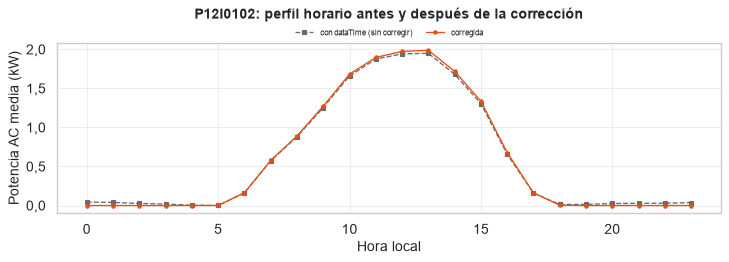

24 filas x 2 columnas; primeras 10:


,potencia_kw_sin_corregir,potencia_kw_corregida
hora_local,,
0,0.0448,0.0000
1,0.0400,0.0000
2,0.0262,0.0000
3,0.0185,0.0000
4,0.0040,0.0000
5,0.0008,0.0008
6,0.1622,0.1635
7,0.5721,0.5778
8,0.8813,0.8900


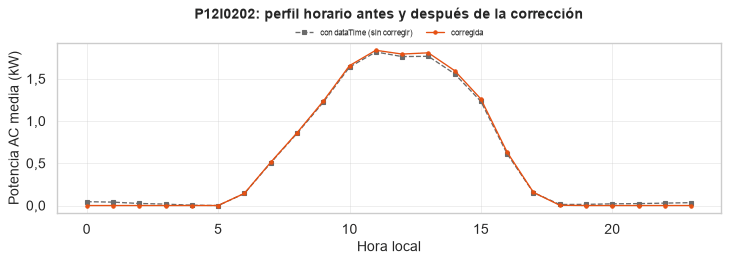

24 filas x 2 columnas; primeras 10:


,potencia_kw_sin_corregir,potencia_kw_corregida
hora_local,,
0,0.0456,0.0000
1,0.0403,0.0000
2,0.0245,0.0000
3,0.0168,0.0000
4,0.0036,0.0000
5,0.0004,0.0004
6,0.1427,0.1441
7,0.5064,0.5114
8,0.8532,0.8603


In [7]:
# Sección 2.1. Corrección horaria de la telemetría SolaX
# Perfil horario medio de la potencia antes y después de la corrección (todas las fechas)
for n, d in tel.items():
    p = obj.potencia_ac(d) / 1000
    antes = p.groupby(d["datatime_api"].dt.tz_convert(config.ZONA).dt.hour).mean()
    despues = p.groupby(d["datatime"].dt.tz_convert(config.ZONA).dt.hour).mean()
    f, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(antes.index, antes, marker="s", ms=4, ls="--", label="con dataTime (sin corregir)", color=config.COLOR_NEUTRO)
    ax.plot(despues.index, despues, marker="o", ms=3, label="corregida", color=config.COLOR_PRINCIPAL)
    ax.set_xlabel("Hora local"); ax.set_ylabel("Potencia AC media (kW)"); ax.set_title(f"{n}: perfil horario antes y después de la corrección")
    ax.legend(); fig(f, f"correccion_horaria_{n}", pd.DataFrame({"potencia_kw_sin_corregir": antes, "potencia_kw_corregida": despues}).rename_axis("hora_local"))

### 2.2. Variables disponibles y sus estadísticos

Cada inversor reporta decenas de variables (potencias por fase, por MPPT y por string, tensiones,
corrientes, temperatura interna, contadores de energía y estado). Se describen todas; para el modelado
se usarán las que tienen relación física con el rendimiento.

In [8]:
# Sección 2.2. Variables disponibles y sus estadísticos
for n, d in tel.items():
    vars_ = [c for c in d.columns if c not in ("datatime", "datatime_api", "desfase_h", "corregida", "plantlocaltime")]
    rv = car.resumen_variables(d, "telemetry.inverter_history", vars_)
    display(Markdown(f"**{n}**: {miles(len(d))} registros, {len(vars_)} variables con datos"))
    display(rv.sort_values("pct_nulos").head(40).round(3))

**P12I0102**: 117 700 registros, 15 variables con datos

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,devicestatus,int64,,estado,117700,0,0.000,100.0,101.040,102.0,103.0,1.004
1,acpower1,float64,W,potencia,117700,0,0.000,0.0,600.207,0.0,5041.0,1042.986
2,invertertemperature,float64,°C,continua,117700,0,0.000,31.0,40.485,39.0,67.0,6.285
3,dailyyield,float64,kWh,contador,117700,0,0.000,0.0,7.027,4.1,37.1,8.394
4,totalyield,float64,kWh,contador,117700,0,0.000,1.6,2582.229,2249.9,6184.6,1619.962
5,mppttotalinputpower,float64,W,potencia,117700,0,0.000,0.0,611.379,1.0,5085.0,1057.913
6,mppt1voltage,float64,V,continua,117700,0,0.000,0.0,198.211,45.7,475.8,201.709
7,mppt1power,float64,W,potencia,117700,0,0.000,0.0,611.379,1.0,5085.0,1057.913
8,mppt2voltage,float64,V,continua,117700,0,0.000,0.0,0.000,0.0,0.0,0.000
9,mppt2power,float64,W,potencia,117700,0,0.000,0.0,0.000,0.0,0.0,0.000


**P12I0202**: 117 680 registros, 15 variables con datos

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,devicestatus,int64,,estado,117680,0,0.000,100.0,101.029,102.0,103.0,1.000
1,acpower1,float64,W,potencia,117680,0,0.000,0.0,564.802,0.0,5046.0,1026.419
2,invertertemperature,float64,°C,continua,117680,0,0.000,31.0,41.589,39.0,67.0,7.759
3,dailyyield,float64,kWh,contador,117680,0,0.000,0.0,6.623,4.0,36.1,8.087
4,totalyield,float64,kWh,contador,117680,0,0.000,0.1,2438.333,2165.0,5823.6,1493.051
5,mppttotalinputpower,float64,W,potencia,117680,0,0.000,0.0,576.706,0.0,5082.0,1043.908
6,mppt1voltage,float64,V,continua,117680,0,0.000,0.0,198.954,39.9,476.0,203.429
7,mppt1power,float64,W,potencia,117680,0,0.000,0.0,576.706,0.0,5082.0,1043.908
8,mppt2voltage,float64,V,continua,117680,0,0.000,0.0,0.000,0.0,0.0,0.000
9,mppt2power,float64,W,potencia,117680,0,0.000,0.0,0.000,0.0,0.0,0.000


**P13I0101**: 118 127 registros, 13 variables con datos

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,devicestatus,int64,,estado,118127,0,0.0,100.0,100.969,100.0,103.0,1.010
1,acpower1,float64,W,potencia,118127,0,0.0,0.0,1165.367,0.0,10046.0,2228.245
2,invertertemperature,float64,°C,continua,118127,0,0.0,27.0,36.757,34.0,72.0,7.898
3,dailyyield,float64,kWh,contador,118127,0,0.0,0.0,12.902,3.4,75.0,19.312
4,totalyield,float64,kWh,contador,118127,0,0.0,0.0,2476.870,869.8,9529.4,2937.514
5,mppttotalinputpower,float64,W,potencia,118127,0,0.0,0.0,1209.748,0.0,10554.0,2316.716
6,mppt1voltage,float64,V,continua,118127,0,0.0,0.0,188.070,0.0,468.3,203.627
7,mppt1power,float64,W,potencia,118127,0,0.0,0.0,617.795,0.0,6001.0,1222.729
8,mppt2voltage,float64,V,continua,118127,0,0.0,0.0,0.000,0.0,0.0,0.000
9,mppt2power,float64,W,potencia,118127,0,0.0,0.0,0.000,0.0,0.0,0.000


**P17I0101**: 39 984 registros, 13 variables con datos

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,devicestatus,int64,,estado,39984,0,0.0,100.0,101.039,102.00,103.0,1.004
1,acpower1,float64,W,potencia,39984,0,0.0,0.0,1171.809,0.00,10077.0,1906.746
2,invertertemperature,float64,°C,continua,39984,0,0.0,30.0,39.170,37.00,80.0,7.702
3,dailyyield,float64,kWh,contador,39984,0,0.0,0.0,13.756,9.50,68.5,15.411
4,totalyield,float64,kWh,contador,39984,0,0.0,0.0,1627.377,1485.55,3953.7,1091.592
5,mppttotalinputpower,float64,W,potencia,39984,0,0.0,0.0,1198.533,0.00,10408.0,1953.167
6,mppt1voltage,float64,V,continua,39984,0,0.0,0.0,176.724,98.05,411.2,176.657
7,mppt1power,float64,W,potencia,39984,0,0.0,0.0,515.140,0.00,5280.0,917.044
8,mppt2voltage,float64,V,continua,39984,0,0.0,0.0,133.444,40.10,323.6,136.767
9,mppt2power,float64,W,potencia,39984,0,0.0,0.0,254.913,0.00,3497.0,499.580


### 2.3. Regímenes de capacidad efectiva

La potencia máxima que alcanza un inversor depende de los paneles conectados, y si la planta se amplía, limita la
inyección o tiene una falla prolongada, el máximo cambia de nivel. Por eso calculamos, mes a mes, el percentil 95 de la
potencia máxima diaria relativa a la potencia nominal del inversor e identificamos segmentos estables, de modo que un
cambio sostenido durante al menos dos meses de más del 20 % respecto de la mediana del segmento en curso abre un
segmento nuevo. El umbral es relativo porque un mismo cambio absoluto pesa más en un inversor que trabaja lejos de su
nominal, y en los meses estables el tiempo meteorológico mueve este indicador menos del 16 %.

Esto importa porque el rendimiento específico se calcula con un kWp constante. Si en un periodo había menos paneles
conectados, ese periodo aparece con un rendimiento artificialmente bajo y no debe mezclarse con el resto al entrenar,
así que modelamos el último régimen estable de al menos 4 meses y contrastamos los cambios con lo que informó el
instalador.

La regla mensual dice en qué mes empieza el régimen, pero el cambio suele caer a mitad de mes, y tomar el régimen desde
el día 1 metería en él hasta cuatro semanas del anterior. Por eso afinamos el primer día con la potencia máxima diaria y
un umbral a medio camino entre el nivel anterior y el nuevo. Si la capacidad sube, el régimen empieza el primer día que
alcanza el umbral y desde el cual toda ventana de 7 días lo vuelve a alcanzar (un día nublado no alcanza el nivel de
ningún régimen), y si baja, empieza el primer día desde el cual ninguna ventana de 7 días lo alcanza. Solo buscamos
dentro del primer mes, así que el inicio nunca se adelanta al mes de la regla.

**P12I0102** (nominal 5,0 kW): último régimen estable desde el 2026-04-04 hasta 2026-10

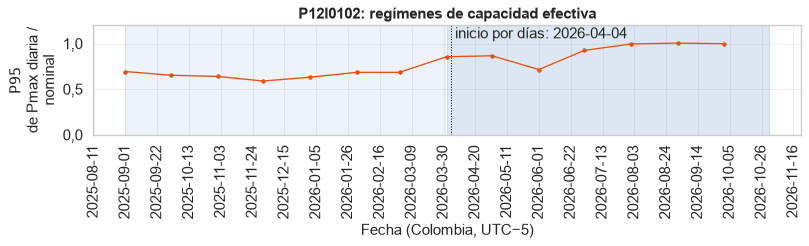

14 filas x 3 columnas; primeras 10:


,p95_pmax_relativa,regimen,inicio
datatime,,,
2025-09-01 00:00:00-05:00,0.6936,0,2025-09-01 00:00:00-05:00
2025-10-01 00:00:00-05:00,0.6528,0,2025-09-01 00:00:00-05:00
2025-11-01 00:00:00-05:00,0.6398,0,2025-09-01 00:00:00-05:00
2025-12-01 00:00:00-05:00,0.5892,0,2025-09-01 00:00:00-05:00
2026-01-01 00:00:00-05:00,0.6315,0,2025-09-01 00:00:00-05:00
2026-02-01 00:00:00-05:00,0.6846,0,2025-09-01 00:00:00-05:00
2026-03-01 00:00:00-05:00,0.6844,0,2025-09-01 00:00:00-05:00
2026-04-01 00:00:00-05:00,0.8553,1,2026-04-04 00:00:00-05:00
2026-05-01 00:00:00-05:00,0.8660,1,2026-04-04 00:00:00-05:00


**P12I0202** (nominal 5,0 kW): último régimen estable desde el 2026-07-17 hasta 2026-10

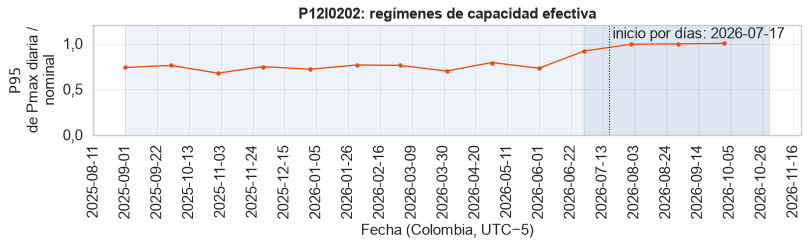

14 filas x 3 columnas; primeras 10:


,p95_pmax_relativa,regimen,inicio
datatime,,,
2025-09-01 00:00:00-05:00,0.7377,0,2025-09-01 00:00:00-05:00
2025-10-01 00:00:00-05:00,0.7604,0,2025-09-01 00:00:00-05:00
2025-11-01 00:00:00-05:00,0.6756,0,2025-09-01 00:00:00-05:00
2025-12-01 00:00:00-05:00,0.7474,0,2025-09-01 00:00:00-05:00
2026-01-01 00:00:00-05:00,0.7183,0,2025-09-01 00:00:00-05:00
2026-02-01 00:00:00-05:00,0.7653,0,2025-09-01 00:00:00-05:00
2026-03-01 00:00:00-05:00,0.7608,0,2025-09-01 00:00:00-05:00
2026-04-01 00:00:00-05:00,0.6991,0,2025-09-01 00:00:00-05:00
2026-05-01 00:00:00-05:00,0.7921,0,2025-09-01 00:00:00-05:00


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


**P13I0101** (nominal 10,0 kW): último régimen estable desde el 2026-05-04 hasta 2026-10

L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\notebooks\tfm\calidad.py:139: RuntimeWarning: divide by zero encountered in scalar divide
  if valores and abs(r - med) / med > umbral:


**P17I0101** (nominal 10,0 kW): último régimen estable desde el 2026-06-20 hasta 2026-10

In [9]:
# Sección 2.3. Regímenes de capacidad efectiva
reg_cap = {}
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in tel:
        continue
    d = tel[n].set_index("datatime")
    p = obj.potencia_ac(d)
    p = p[p.index < CORTE_MODELADO]                     # el régimen se decide sin ver lo posterior al corte
    r = calidad.regimenes_capacidad(p, inv.ratedpower * 1000)
    reg_cap[n] = r
    estable = calidad.ultimo_regimen_estable(r)
    display(Markdown(f"**{n}** (nominal {inv.ratedpower} kW): último régimen estable desde el {estable[0]:%Y-%m-%d} hasta {estable[1]:%Y-%m}"
                     if estable else f"**{n}**: sin régimen estable"))
    f, ax = plt.subplots(figsize=(10, 3))
    ax.plot(r.index, r["p95_pmax_relativa"], marker="o", color=config.COLOR_PRINCIPAL)
    for k, g in r.groupby("regimen"):
        ax.axvspan(g.index.min(), g.index.max() + pd.offsets.MonthEnd(0), alpha=0.08 + 0.08 * (k % 2), color=config.COLOR_SECUNDARIO)
    if estable and r["regimen"].nunique() > 1:
        ax.axvline(estable[0], color="black", lw=0.9, ls=":")
        ax.annotate(f" inicio por días: {estable[0]:%Y-%m-%d}", (estable[0], 1.1), fontsize=7, va="center")
    ax.set_ylim(0, 1.2); ax.set_ylabel("P95 de Pmax diaria / nominal"); ax.set_title(f"{n}: regímenes de capacidad efectiva")
    fig(f, f"regimenes_{n}", r)
res.registrar(f"localidades.{GRUPO}.datos.regimenes", {n: {"ultimo_estable": calidad.ultimo_regimen_estable(r),
              "regimenes": int(r["regimen"].nunique())} for n, r in reg_cap.items()})

### 2.4. Limitación de inyección y régimen vigente (experimento E28)

Algunas plantas tuvieron activado el control de exportación (inyección cero), por ejemplo mientras se tramitaba la
conexión para entregar excedentes a la red. El inversor maestro mide con su **sensor de red** (la pinza amperimétrica o
el medidor conectado a él, que SolaX publica como `gridpower` de ese inversor) la potencia que la planta intercambia
con la red, y cuando la producción supera al consumo del predio la reduce hasta dejar la red en cero. En esas horas la
producción sigue al consumo y no al recurso solar.

Usamos dos señales. La primera, en las plantas con sensor, son las lecturas con producción en las que la red queda en
cero (|red| ≤ 2 % del percentil 99 de la potencia AC de la planta, sin ser un cero exacto). Un día está limitado si la
mediana móvil de 7 días de su fracción de lecturas en cero, de 8 a 15 h, es de 0,5 o más, y los días limitados definen
los periodos. Una hora está recortada si al menos la mitad de sus lecturas están en cero, en cualquier día, porque el
control solo actúa cuando la producción supera al consumo y fuera de los periodos limitados quedan horas sueltas
recortadas (limitación parcial). La segunda señal, que sirve sin sensor y como confirmación, es que para reducir la
potencia el inversor se aleja del punto de máxima potencia hacia la tensión de circuito abierto, de modo que en una
hora despejada la tensión MPPT sube y la potencia baja (regla de `tfm/recorte.py`, calibrada contra el sensor con
datos de entrenamiento).

Excluimos las horas recortadas como las horas en falla y modelamos el **régimen vigente** (régimen B), que empieza en
el primer día posterior al último día limitado que muestra por sí mismo inyección libre (su propia fracción de lecturas
en cero es menor que 0,25, porque la mediana centrada se retrasa hasta tres días en la transición) y queda dentro del
último régimen de capacidad. Una planta que sigue limitada al corte queda fuera del régimen B, porque su producción
depende del consumo, que no se mide. Usar el histórico completo (régimen A) mezclaría horas en que el inversor no seguía
al sol, y lo conservamos solo para medir cuánto cuesta no depurar, evaluando A y B en las mismas horas. Descartar solo
los meses con el máximo diario reducido (el detector de capacidad de 2.3) no ve la limitación cuando el consumo del día
es alto, y corregir el dato en su origen violaría la regla de datos crudos.

,sensor_de_red,dias_con_marca,dias_limitados,horas_recortadas,estado,inicio_b,ultimo_dia_limitado,dias_b,origen
planta,,,,,,,,,
P12,P12I0202,406,305,2465,liberada,2026-07-25,2026-07-24,99,telemetria
P13,P13I0101,342,158,1304,liberada,2026-05-05,2026-05-02,180,telemetria
P17,P17I0101,134,109,937,liberada hace poco,2026-10-08,2026-10-06,24,telemetria


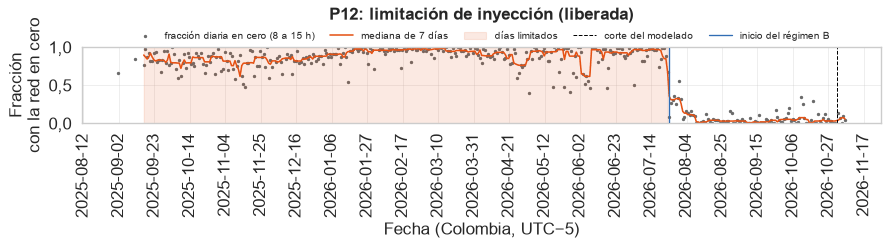

411 filas x 4 columnas; primeras 10:


,lecturas,fraccion_cero,mediana_7d,limitado
datatime,,,,
2025-09-02,56,0.6607,NaN,False
2025-09-12,74,0.8514,NaN,False
2025-09-17,74,0.7703,0.8980,True
2025-09-18,73,0.9726,0.8730,True
2025-09-19,63,0.8730,0.8461,True
2025-09-20,65,0.9231,0.8730,True
2025-09-21,94,0.8191,0.9222,True
2025-09-22,86,0.8140,0.8730,True
2025-09-23,90,0.9222,0.8358,True


In [10]:
# Sección 2.4. Limitación de inyección y régimen vigente (experimento E28)
REC = {}                     # por inversor: marcas horarias (recortada, fracción en cero de la red, tensión y potencia relativas)
REG_PLANTA = {}              # por planta: estado de la limitación al corte e inicio del régimen B
# Lo que declaro el instalador (limitación vigente, fin confirmado, conformidad del operador de red, reparaciones)
INSTALADOR = {pl: recorte.instalador_planta(const["eventos"], str(g["plantuuid"].iloc[0])) for pl, g in INVERSORES.groupby("planta")}
filas_rec = []
for planta, g in INVERSORES.groupby("planta"):
    pu = str(g["plantuuid"].iloc[0])
    for _, inv in g.iterrows():
        REC[inv.codigo] = recorte.marcas_planta(GRUPO, pu, inv.codigo, INICIO, FIN)
    m = REC[g["codigo"].iloc[0]]
    dias_r = m.attrs["dias"]
    REG_PLANTA[planta] = recorte.regimen_vigente(dias_r, config.FIN_MODELADO, instalador=INSTALADOR[planta])
    antes = m.index < CORTE_MODELADO
    filas_rec.append({"planta": planta, "sensor_de_red": m.attrs["sensor"] or "sin sensor",
                      "dias_con_marca": None if dias_r is None else int((dias_r.index < pd.Timestamp(config.FIN_MODELADO)).sum()),
                      "dias_limitados": None if dias_r is None else int(dias_r.loc[dias_r.index < pd.Timestamp(config.FIN_MODELADO), "limitado"].sum()),
                      "horas_recortadas": int(m.loc[antes, "recortada"].sum()) if m.attrs["sensor"] else None,
                      **{k: (str(v.date()) if hasattr(v, "date") else v) for k, v in REG_PLANTA[planta].items()}})
RESUMEN_REC = pd.DataFrame(filas_rec).set_index("planta")
display(RESUMEN_REC)

# Regímenes de capacidad después del fin de la limitación (régimen B): la limitación ya no los parte. Se calculan
# aquí porque la telemetría de 5 minutos (tel) se libera después de la agregación.
REG_CAP_B = {}
for _, inv in INVERSORES.iterrows():
    ini_b = REG_PLANTA.get(inv.planta, {}).get("inicio_b")
    if inv.codigo not in tel or ini_b is None:
        continue
    p_b = obj.potencia_ac(tel[inv.codigo].set_index("datatime"))
    p_b = p_b[(p_b.index >= pd.Timestamp(ini_b, tz=config.ZONA).tz_convert("UTC")) & (p_b.index < CORTE_MODELADO)]
    if len(p_b):
        REG_CAP_B[inv.codigo] = calidad.regimenes_capacidad(p_b, inv.ratedpower * 1000)

# Etapas de capacidad registradas en la base (ampliaciones con su mes y sus paneles): la última anterior al corte
# también parte el régimen, con su día afinado por la potencia máxima diaria (calidad.inicio_por_etapa). Hace falta
# cuando la ampliación cae en el primer mes del régimen vigente, donde la regla mensual no ve ningún salto (P04)
ETAPAS = const.get("etapas", pd.DataFrame(columns=["plantuuid", "desde", "paneles"]))
INICIO_ETAPA = {}
for _, inv in INVERSORES.iterrows():
    e = ETAPAS[ETAPAS["plantuuid"] == str(inv.plantuuid)].sort_values("desde")
    e = e[pd.to_datetime(e["desde"]) < pd.Timestamp(config.FIN_MODELADO)]
    if len(e) < 2 or inv.codigo not in tel:
        continue
    p_e = obj.potencia_ac(tel[inv.codigo].set_index("datatime"))
    ini_e = calidad.inicio_por_etapa(p_e[p_e.index < CORTE_MODELADO], inv.ratedpower * 1000, e["desde"].iloc[-1],
                                     float(e["paneles"].iloc[-2]) / float(e["paneles"].iloc[-1]))
    if ini_e is not None:
        INICIO_ETAPA[inv.codigo] = ini_e
        display(Markdown(f"**{inv.codigo}**: la base registra una ampliación en {pd.Timestamp(e['desde'].iloc[-1]):%Y-%m} "
                         f"({int(e['paneles'].iloc[-2])} a {int(e['paneles'].iloc[-1])} paneles). Por la potencia máxima diaria, "
                         f"los paneles nuevos entran el {ini_e:%Y-%m-%d}, y el periodo de modelado no empieza antes."))

# Fracción diaria de lecturas con la red en cero, su mediana de 7 días y el inicio del régimen B
for planta, g in INVERSORES.groupby("planta"):
    dias_r = REC[g["codigo"].iloc[0]].attrs["dias"]
    if dias_r is None or dias_r.empty:
        continue
    f, ax = plt.subplots(figsize=(11, 3))
    ax.scatter(dias_r.index, dias_r["fraccion_cero"], s=4, color=config.COLOR_NEUTRO, label="fracción diaria en cero (8 a 15 h)")
    ax.plot(dias_r.index, dias_r["mediana_7d"], lw=1.4, color=config.COLOR_PRINCIPAL, label="mediana de 7 días")
    ax.fill_between(dias_r.index, 0, 1, where=dias_r["limitado"].fillna(False).to_numpy(), color=config.COLOR_PRINCIPAL,
                    alpha=0.12, step="mid", label="días limitados")
    ax.axvline(pd.Timestamp(config.FIN_MODELADO), color="black", ls="--", lw=0.9, label="corte del modelado")
    ini_b = REG_PLANTA[planta].get("inicio_b")
    if ini_b is not None:
        ax.axvline(ini_b, color=config.COLOR_SECUNDARIO, lw=1.2, label="inicio del régimen B")
    ax.set_ylim(0, 1); ax.set_ylabel("Fracción con la red en cero")
    ax.set_title(f"{planta}: limitación de inyección ({REG_PLANTA[planta]['estado']})")
    ax.legend(fontsize=8, loc="upper right")
    fig(f, f"recorte_{planta}", dias_r)
res.registrar(f"localidades.{GRUPO}.datos.recorte", RESUMEN_REC.replace({np.nan: None}).to_dict(orient="index"))

### 2.5. Huecos de la telemetría

Se lleva cada serie a una rejilla regular de 5 minutos (cada lectura al múltiplo de 5 minutos más
cercano, porque SolaX registra con segundos variables) y se miden los huecos. Cada hueco se clasifica
por duración (corto ≤ 1 h, medio de 1 a 6 h, largo > 6 h) y según si contiene horas de sol. Los huecos
nocturnos no afectan a la producción; los diurnos sí.

In [11]:
# Sección 2.5. Huecos de la telemetría
COLS_TEL = ["acpower1", "acpower2", "acpower3", "totalyield", "dailyyield", "invertertemperature", "mppttotalinputpower", "devicestatus"]
regs, dias_sol, huecos = {}, {}, {}
for n, d in tel.items():
    cols = [c for c in COLS_TEL if c in d.columns]
    r = imp.regularizar(d, "5min", cols)
    regs[n] = r
    dias_sol[n] = solar.es_de_dia(r.index, lugar)
    huecos[n] = imp.clasificar_huecos(r["acpower1"], "5min", dias_sol[n])
tabla_h = pd.concat({n: h.groupby(["clase", "diurno"]).agg(huecos=("n", "size"), horas=("duracion", lambda x: x.sum() / pd.Timedelta("1h")))
                     for n, h in huecos.items()}).round(1)
display(tabla_h)
# Rejilla completa: cuántas marcas de 5 minutos deberían existir entre el primer y el último dato, cuántas hay
REJILLA = pd.DataFrame({n: {"primera_marca_utc": r.index.min(), "ultima_marca_utc": r.index.max(),
                            "marcas_esperadas": len(r), "marcas_presentes": int(r["acpower1"].notna().sum()),
                            "marcas_diurnas_esperadas": int(dias_sol[n].sum()),
                            "marcas_diurnas_presentes": int((r["acpower1"].notna() & dias_sol[n]).sum())}
                        for n, r in regs.items()}).T
REJILLA["pct_presentes"] = 100 * REJILLA["marcas_presentes"] / REJILLA["marcas_esperadas"]
REJILLA["pct_diurnas_presentes"] = 100 * REJILLA["marcas_diurnas_presentes"] / REJILLA["marcas_diurnas_esperadas"]
display(Markdown("**Rejilla completa de 5 minutos.** Entre la primera y la última lectura de cada inversor deberían "
                 "existir `marcas_esperadas` instantes; `pct_diurnas_presentes` es el porcentaje de los instantes con el "
                 "sol sobre el horizonte que tienen dato (de noche el inversor se apaga y no reporta)."))
display(REJILLA)
pct_sol = pd.to_numeric(REJILLA["pct_diurnas_presentes"])
display(Markdown(
    f"**Lectura.** Las unidades tienen dato en el {pct_sol.min():.1f} a {pct_sol.max():.1f} % de los instantes con sol "
    f"(la de menor cobertura es {pct_sol.idxmin()}). Los huecos de hasta una hora se imputan en la sección 3; los más "
    "largos quedan como faltantes: esas horas no se evalúan y los modelos las tratan como dato ausente."))
res.registrar(f"localidades.{GRUPO}.datos.rejilla", REJILLA.drop(columns=["primera_marca_utc", "ultima_marca_utc"]).astype(float).round(3).to_dict(orient="index"))
res.registrar(f"localidades.{GRUPO}.datos.huecos", {n: {f"{c}_{'dia' if dd else 'noche'}": int(v)
              for (c, dd), v in h.groupby(["clase", "diurno"]).size().items()} for n, h in huecos.items()})

huecos  horas
         clase diurno               
P12I0102 corto False      554   50.0
               True       612   57.3
         largo True        11  414.7
         medio False       13   30.6
               True         5   10.6
P12I0202 corto False      574   51.4
               True       624   57.2
         largo True        11  415.0
         medio False       13   29.8
               True         4    9.5
P13I0101 corto False      357   40.6
               True       285   53.3
         largo False        1   11.8
               True         3  120.6
         medio False        9   13.6
               True        24   53.8
P17I0101 corto False      149   13.2
               True       200   16.7
         largo True         1  600.0
         medio False        3    8.8
               True         1    1.1

**Rejilla completa de 5 minutos.** Entre la primera y la última lectura de cada inversor deberían existir `marcas_esperadas` instantes; `pct_diurnas_presentes` es el porcentaje de los instantes con el sol sobre el horizonte que tienen dato (de noche el inversor se apaga y no reporta).

,primera_marca_utc,ultima_marca_utc,marcas_esperadas,marcas_presentes,marcas_diurnas_esperadas,marcas_diurnas_presentes,pct_presentes,pct_diurnas_presentes
P12I0102,2025-09-01 20:35:00+00:00,2026-11-07 04:55:00+00:00,124229,117471,62457,59308,94.560046,94.958131
P12I0202,2025-09-01 20:40:00+00:00,2026-11-07 04:55:00+00:00,124228,117474,62456,59321,94.563222,94.980466
P13I0101,2025-09-12 05:00:00+00:00,2026-11-07 04:55:00+00:00,121248,117723,60962,59091,97.092736,96.930875
P17I0101,2026-05-25 20:45:00+00:00,2026-11-07 05:00:00+00:00,47620,39944,24470,20445,83.880722,83.551287


**Lectura.** Las unidades tienen dato en el 83,6 a 96,9 % de los instantes con sol (la de menor cobertura es P17I0101). Los huecos de hasta una hora se imputan en la sección 3; los más largos quedan como faltantes: esas horas no se evalúan y los modelos las tratan como dato ausente.

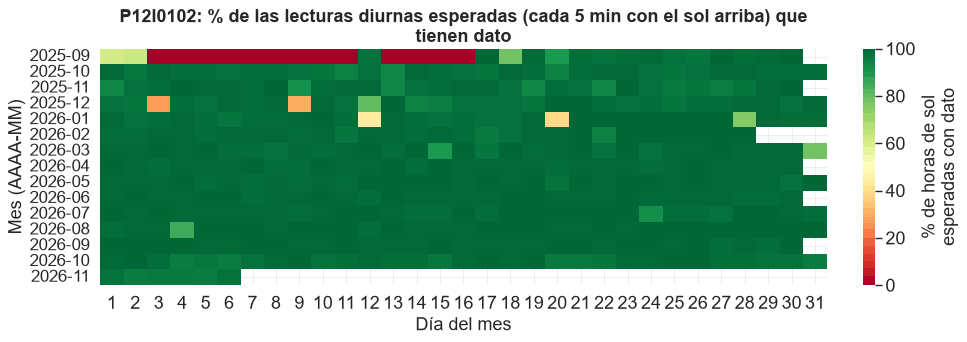

432 filas x 1 columnas; primeras 10:


,pct_lecturas_diurnas_con_dato
2025-09-01,61.2903
2025-09-02,62.5850
2025-09-03,0.0000
2025-09-04,0.0000
2025-09-05,0.0000
2025-09-06,0.0000
2025-09-07,0.0000
2025-09-08,0.0000
2025-09-09,0.0000
2025-09-10,0.0000


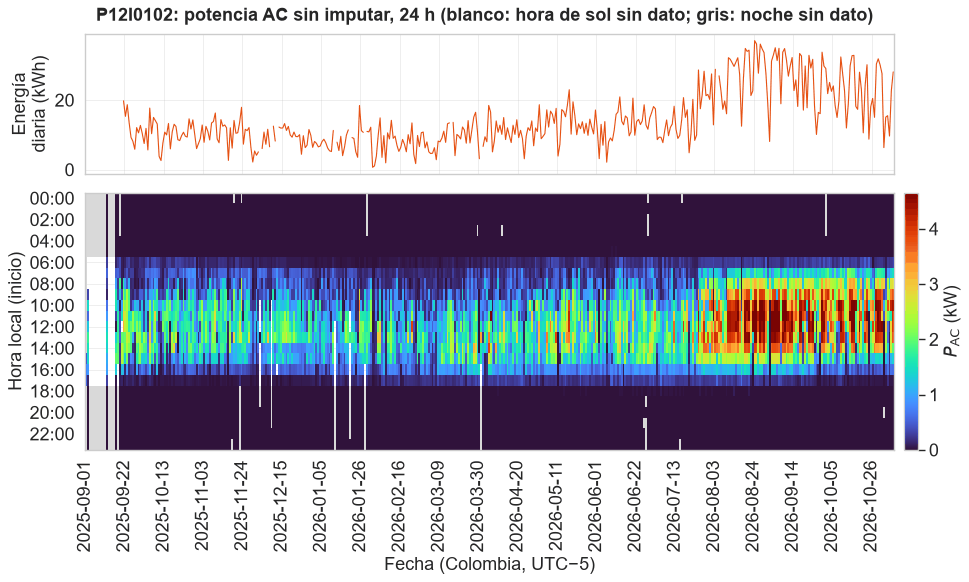

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4276,0.7459,0.5230,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.329,1.4345,0.5773,1.2832,1.7598,1.5268,1.3664,0.9109,0.1326,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


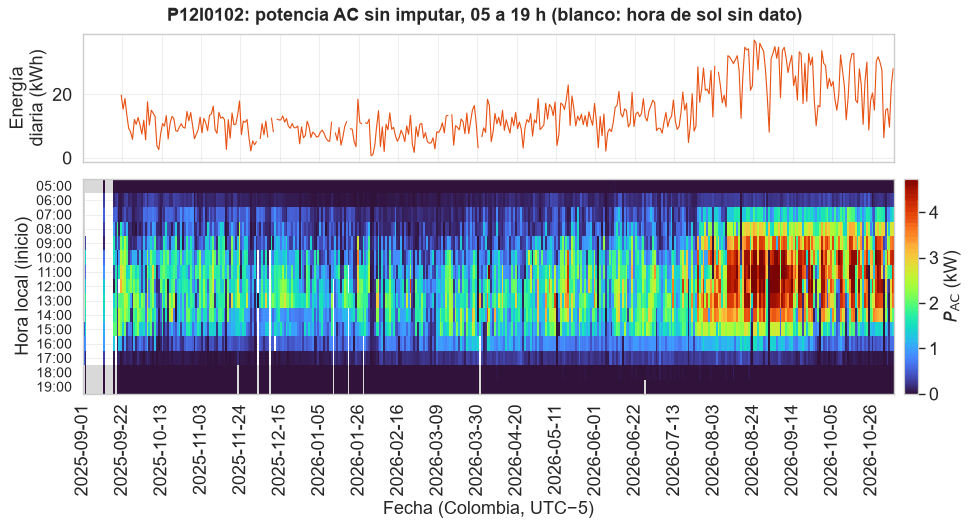

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4276,0.7459,0.5230,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,0.329,1.4345,0.5773,1.2832,1.7598,1.5268,1.3664,0.9109,0.1326,0.0,0.0
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


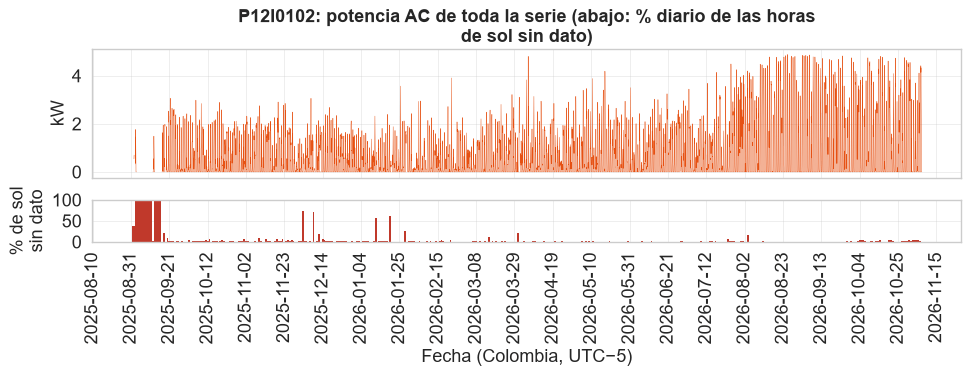

10353 filas x 1 columnas; primeras 10:


,p_ac_kw
datatime,
2025-09-01 16:00:00-05:00,0.5433
2025-09-01 17:00:00-05:00,0.6814
2025-09-01 18:00:00-05:00,0.6980
2025-09-01 19:00:00-05:00,NaN
2025-09-01 20:00:00-05:00,NaN
2025-09-01 21:00:00-05:00,NaN
2025-09-01 22:00:00-05:00,NaN
2025-09-01 23:00:00-05:00,NaN
2025-09-02 00:00:00-05:00,NaN


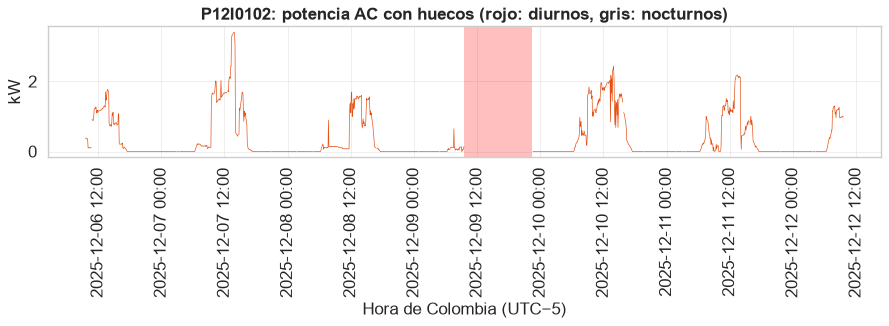

1729 filas x 1 columnas; primeras 10:


,p_ac_kw
datatime,
2025-12-06 09:35:00-05:00,0.378
2025-12-06 09:40:00-05:00,0.373
2025-12-06 09:45:00-05:00,0.383
2025-12-06 09:50:00-05:00,0.381
2025-12-06 09:55:00-05:00,0.354
2025-12-06 10:00:00-05:00,0.357
2025-12-06 10:05:00-05:00,0.108
2025-12-06 10:10:00-05:00,0.113
2025-12-06 10:15:00-05:00,0.100


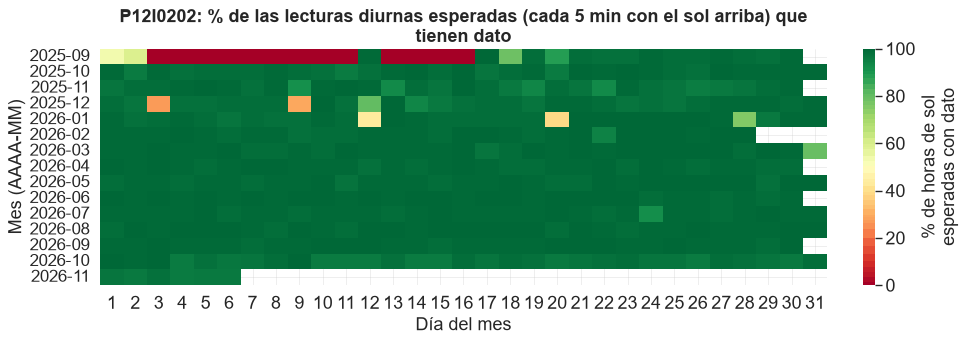

432 filas x 1 columnas; primeras 10:


,pct_lecturas_diurnas_con_dato
2025-09-01,53.3333
2025-09-02,59.1837
2025-09-03,0.0000
2025-09-04,0.0000
2025-09-05,0.0000
2025-09-06,0.0000
2025-09-07,0.0000
2025-09-08,0.0000
2025-09-09,0.0000
2025-09-10,0.0000


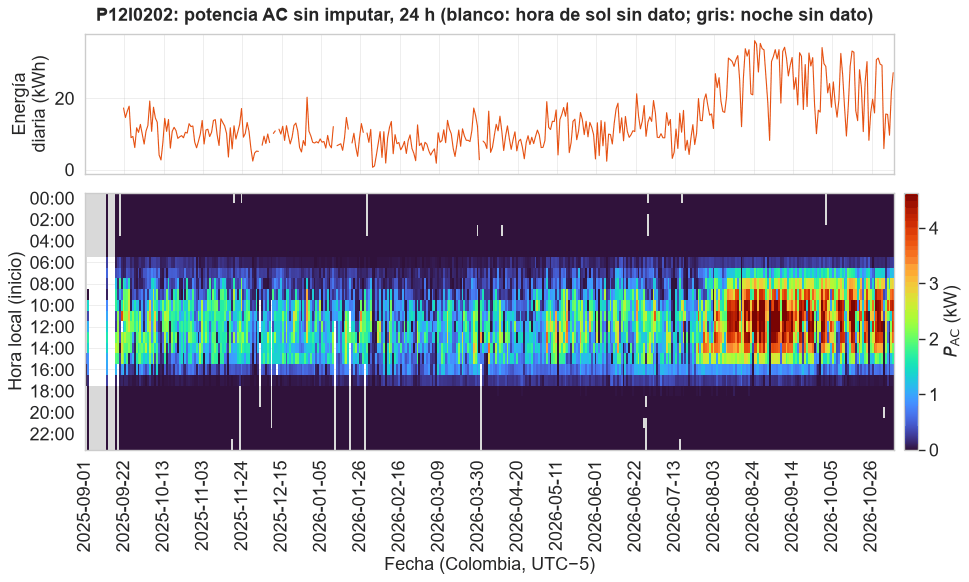

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4380,0.0953,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.4015,0.3297,1.1129,1.6581,1.3963,0.8592,0.7870,0.1465,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


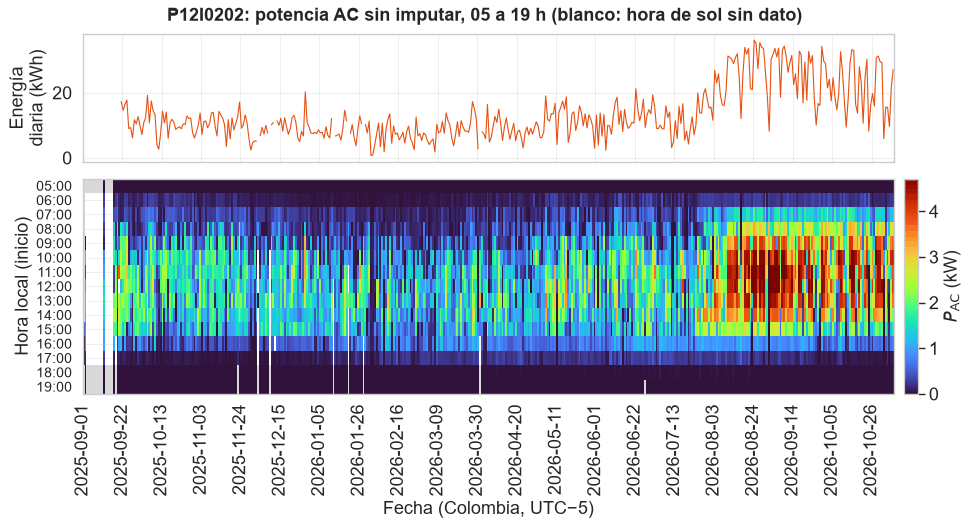

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4380,0.0953,0.0000,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,0.0,1.4015,0.3297,1.1129,1.6581,1.3963,0.8592,0.7870,0.1465,0.0,0.0
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


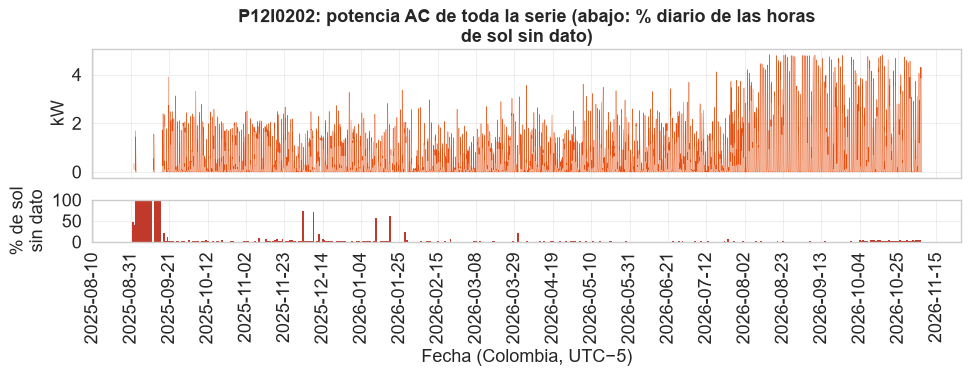

10353 filas x 1 columnas; primeras 10:


,p_ac_kw
datatime,
2025-09-01 16:00:00-05:00,0.3504
2025-09-01 17:00:00-05:00,0.0953
2025-09-01 18:00:00-05:00,NaN
2025-09-01 19:00:00-05:00,NaN
2025-09-01 20:00:00-05:00,NaN
2025-09-01 21:00:00-05:00,NaN
2025-09-01 22:00:00-05:00,NaN
2025-09-01 23:00:00-05:00,NaN
2025-09-02 00:00:00-05:00,NaN


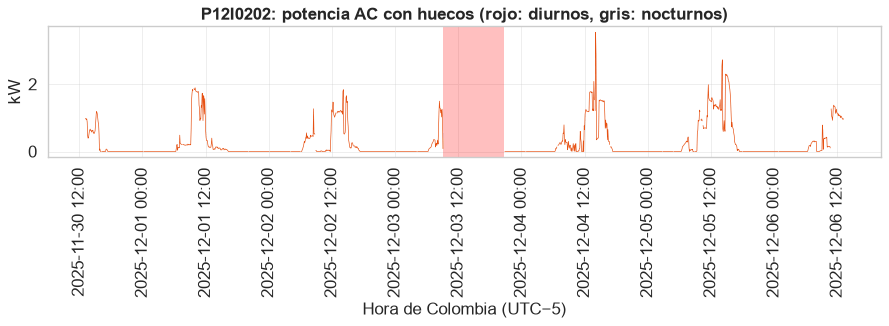

1729 filas x 1 columnas; primeras 10:


,p_ac_kw
datatime,
2025-11-30 13:10:00-05:00,0.968
2025-11-30 13:15:00-05:00,0.985
2025-11-30 13:20:00-05:00,0.953
2025-11-30 13:25:00-05:00,0.968
2025-11-30 13:30:00-05:00,0.877
2025-11-30 13:35:00-05:00,0.467
2025-11-30 13:40:00-05:00,0.395
2025-11-30 13:45:00-05:00,0.415
2025-11-30 13:50:00-05:00,0.504


In [12]:
# Sección 2.5. Huecos de la telemetría
for n, r in regs.items():
    cob = car.cobertura_diaria(r["acpower1"], dias_sol[n])
    fig(gr.calendario_cobertura(cob, f"{n}: % de las lecturas diurnas esperadas (cada 5 min con el sol arriba) que tienen dato"),
        f"calendario_{n}", (100 * cob).rename("pct_lecturas_diurnas_con_dato").to_frame())
    p = obj.potencia_ac(r) / 1000
    noche5 = ~dias_sol[n]
    diaria = (p.groupby((p.index - pd.Timedelta("5min")).tz_convert(config.ZONA).normalize()).sum(min_count=1) / 12).rename("energia_kwh")
    completo = pd.Series(cob.to_numpy(), index=pd.to_datetime(cob.index)).reindex(diaria.index.tz_localize(None)).to_numpy() >= 0.9
    diaria = diaria.where(completo)                             # solo días con al menos el 90 % de las lecturas diurnas
    # Serie cruda en la rejilla de 5 min (tras corregir la hora y el jittering), antes de imputar
    fig(gr.panel_diario_y_mapa(p, diaria, f"{n}: potencia AC sin imputar, 24 h (blanco: hora de sol sin dato; gris: noche sin dato)",
                               "P_AC (kW)", "Energía diaria (kWh)", None, noche5), f"mapa_pac_24h_{n}", gr.tabla_dia_hora(p, None).T)
    fig(gr.panel_diario_y_mapa(p, diaria, f"{n}: potencia AC sin imputar, 05 a 19 h (blanco: hora de sol sin dato)", "P_AC (kW)",
                               "Energía diaria (kWh)", (5, 19), noche5), f"mapa_pac_{n}", gr.tabla_dia_hora(p, (5, 19)).T)
    # gr.mostrar(gr.tabla_dia_hora(p, (5, 19)).T, todas=True)   # todas las filas
    fig(gr.serie_completa(p, dias_sol[n], f"{n}: potencia AC de toda la serie (abajo: % diario de las horas de sol sin dato)", "kW"),
        f"serie_completa_pac_{n}", p.resample("1h", label="right", closed="right").mean().rename("p_ac_kw").to_frame())
    # ventana ilustrativa con huecos diurnos
    h = huecos[n].query("diurno and clase != 'corto'")
    if not h.empty:
        c = h.iloc[len(h) // 2]["inicio"]
        p = obj.potencia_ac(r) / 1000
        v = slice(c - pd.Timedelta("3D"), c + pd.Timedelta("3D"))
        fig(gr.serie_con_huecos(p, huecos[n], f"{n}: potencia AC con huecos (rojo: diurnos, gris: nocturnos)", "kW",
                                v.start, v.stop), f"huecos_{n}", p.loc[v].rename("p_ac_kw").to_frame())

### 2.6. Valores atípicos y límites físicos

Usamos dos criterios complementarios. Los **límites físicos** marcan lo imposible (potencia negativa o por encima de
1,15 veces la nominal y temperatura fuera de −5 a 95 °C), y el criterio **IQR por hora del día** (k = 1,5 y k = 3, las
cercas de Tukey) marca lo inusual para esa hora. Decidimos marcar y no borrar, porque en energía solar un valor alto
puede ser real (realce por bordes de nube) y uno bajo puede ser una falla real que interesa para la detección de
anomalías, de modo que borrarlos sesgaría el análisis.

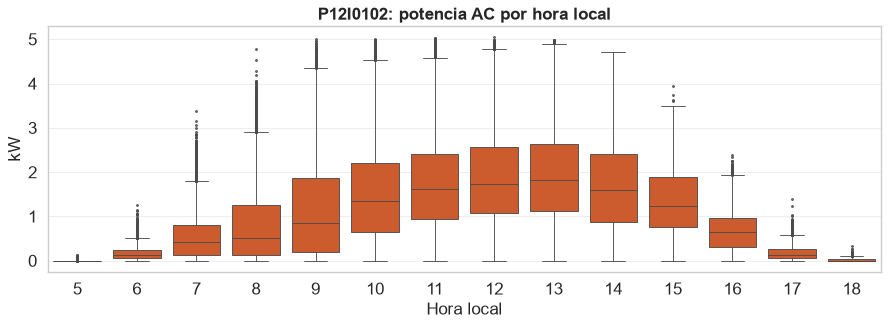

14 filas x 8 columnas; primeras 10:


,count,mean,std,min,25%,50%,75%,max
hora_local,,,,,,,,
5,581.0,0.0067,0.0188,0.0,0.0000,0.0000,0.0000,0.138
6,4545.0,0.1792,0.1776,0.0,0.0540,0.1300,0.2390,1.269
7,4951.0,0.5781,0.5886,0.0,0.1342,0.4130,0.8000,3.373
8,4945.0,0.8902,0.9960,0.0,0.1410,0.5090,1.2500,4.779
9,4924.0,1.2728,1.2831,0.0,0.1980,0.8480,1.8622,4.999
10,4944.0,1.6840,1.4015,0.0,0.6540,1.3430,2.2062,5.011
11,4924.0,1.8983,1.3846,0.0,0.9470,1.6285,2.4042,5.033
12,4926.0,1.9743,1.3385,0.0,1.0743,1.7290,2.5580,5.041
13,4920.0,1.9956,1.2442,0.0,1.1140,1.8170,2.6315,4.991


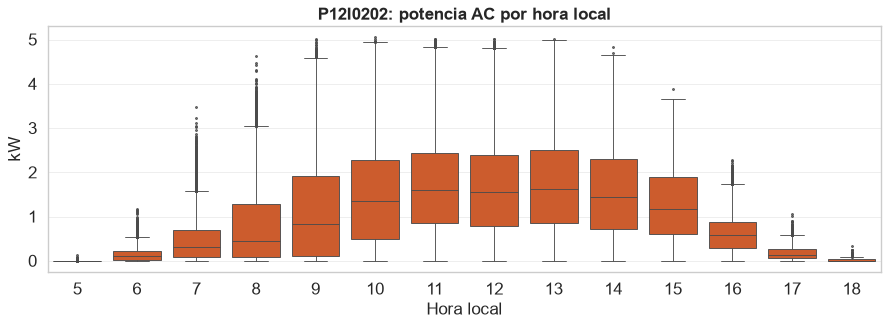

14 filas x 8 columnas; primeras 10:


,count,mean,std,min,25%,50%,75%,max
hora_local,,,,,,,,
5,581.0,0.0030,0.0116,0.0,0.0000,0.0000,0.0000,0.134
6,4538.0,0.1579,0.1761,0.0,0.0202,0.1040,0.2240,1.168
7,4945.0,0.5116,0.5868,0.0,0.0950,0.3150,0.6840,3.477
8,4955.0,0.8605,1.0183,0.0,0.0935,0.4370,1.2750,4.637
9,4924.0,1.2352,1.3105,0.0,0.1130,0.8360,1.9050,5.002
10,4944.0,1.6570,1.4319,0.0,0.4952,1.3595,2.2730,5.046
11,4911.0,1.8405,1.4281,0.0,0.8530,1.5950,2.4445,5.009
12,4926.0,1.7936,1.3933,0.0,0.7765,1.5430,2.3898,5.007
13,4911.0,1.8141,1.2978,0.0,0.8450,1.6170,2.5055,5.014


,inversor,fuera_limites_fisicos,atipicos_iqr_k1.5,atipicos_iqr_k3,muestras_diurnas
0,P12I0102,0,2412,172,59308
1,P12I0202,0,1585,160,59321
2,P13I0101,0,487,156,59091
3,P17I0101,0,1066,123,20445


In [13]:
# Sección 2.6. Valores atípicos y límites físicos
filas_out = []
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in regs:
        continue
    r = regs[n]
    p = obj.potencia_ac(r)
    lim = calidad.limites_fisicos(r, inv.ratedpower * 1000)
    dia = p[dias_sol[n]]
    filas_out.append({"inversor": n, "fuera_limites_fisicos": int(lim.values.sum()),
                      "atipicos_iqr_k1.5": int(calidad.outliers_iqr(dia, 1.5).sum()),
                      "atipicos_iqr_k3": int(calidad.outliers_iqr(dia, 3.0).sum()), "muestras_diurnas": int(dia.notna().sum())})
    cuartiles = (dia / 1000).groupby(dia.index.tz_convert(config.ZONA).hour).describe().rename_axis("hora_local")
    fig(gr.boxplot_por(dia / 1000, "hora", f"{n}: potencia AC por hora local", "kW"), f"boxplot_hora_{n}", cuartiles)
display(pd.DataFrame(filas_out))

### 2.7. Disponibilidad de los inversores

El rendimiento de un sistema solo depende del tiempo meteorológico si el sistema está funcionando. SolaX informa el
estado de cada inversor en cada lectura (`devicestatus`), donde 100 es espera, 101 comprobación, 102 funcionamiento
normal, 103 falla y 104 falla permanente, entre otros. Con el sol a más de 20°, cuando un inversor sano siempre
produce, medimos la fracción del tiempo en falla y la fracción con producción prácticamente nula.

Las horas con el inversor en falla (alguna lectura con estado 103 o 104) no cuentan como rendimiento observado, así que
las excluimos del entrenamiento y de las métricas, y los días con más del 10 % de sus horas de sol en falla quedan
incompletos. Tampoco cuentan las horas **sin producción con sol** que el estado no declara como falla (inversor apagado
o en espera, planta desconectada o limitada a cero sin consumo), con energía menor que el 1 % del kWp
(`tfm/calidad.sin_produccion`, sección E). Un día en que todas sus horas con al menos 50 W/m² en el plano están así
(mediodía incluido) queda entero fuera, y en los demás días solo excluimos las horas con al menos 200 W/m², con los que
un sistema sano produce del orden del 16 % de su kWp. En las primeras y últimas horas del día un cero puede ser
sistemático, porque el inversor aún no arranca con el sol rasante, y es un comportamiento normal que el modelo debe
aprender.

Lo hacemos porque una falla no depende del tiempo y ningún modelo meteorológico puede anticiparla, y mezclarla con el
rendimiento haría que el modelo aprendiera a subestimar todos los días. Así el pronóstico pasa a ser el rendimiento
esperado con el sistema funcionando, y la diferencia con lo medido es justamente la señal para detectar fallas.
Conservar esas horas equivaldría a pronosticar también la disponibilidad, un fenómeno eléctrico o de la red que, desde
el punto de vista meteorológico, es aleatorio.

,muestras_sol_alto,pct_falla,pct_produccion_nula
P12I0102,45012.0,1.17,7.94
P12I0202,45046.0,1.22,14.59
P13I0101,44789.0,1.25,18.69
P17I0101,15698.0,1.12,3.22


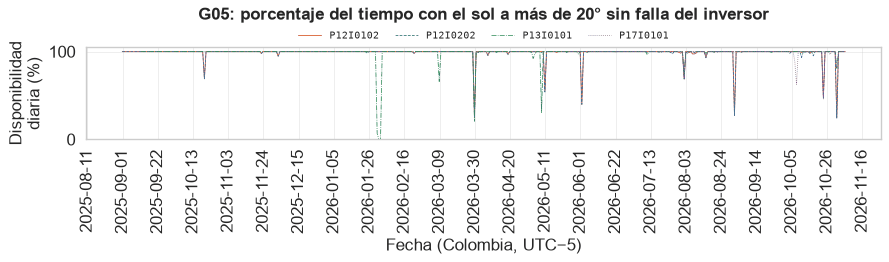

419 filas x 4 columnas; primeras 10:


,P12I0102,P12I0202,P13I0101,P17I0101
dia_local,,,,
2025-09-01,100.0,100.0,NaN,NaN
2025-09-02,100.0,100.0,NaN,NaN
2025-09-12,100.0,100.0,100.0,NaN
2025-09-17,100.0,100.0,100.0,NaN
2025-09-18,100.0,100.0,100.0,NaN
2025-09-19,100.0,100.0,100.0,NaN
2025-09-20,100.0,100.0,100.0,NaN
2025-09-21,100.0,100.0,100.0,NaN
2025-09-22,100.0,100.0,100.0,NaN


**Observación.** Con el sol a más de 20°, los inversores de G05 pasan entre 1,1 y 1,3 % del tiempo en falla, y entre 3,2 y 18,7 % con producción prácticamente nula (menos del 2 % de la nominal). Las horas en falla y las horas sin producción con sol quedan fuera del rendimiento observado (sección E).

In [14]:
# Sección 2.7. Disponibilidad de los inversores
DISPONIBILIDAD, diarias = {}, {}
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in regs or "devicestatus" not in regs[n]:
        continue
    r = regs[n]
    alto = solar.es_de_dia(r.index, lugar, elevacion_minima=20).to_numpy()
    st = r["devicestatus"].round()
    p = obj.potencia_ac(r)
    base_d = alto & st.notna().to_numpy()
    falla = st.isin([103, 104]).to_numpy()
    nula = (p < 0.02 * inv.ratedpower * 1000).to_numpy() & p.notna().to_numpy()
    DISPONIBILIDAD[n] = {"muestras_sol_alto": int(base_d.sum()), "pct_falla": 100 * (falla & base_d).sum() / max(base_d.sum(), 1),
                         "pct_produccion_nula": 100 * (nula & base_d).sum() / max(base_d.sum(), 1)}
    idx_d = r.index[base_d]
    diarias[n] = pd.Series(~falla[base_d], index=idx_d).groupby(idx_d.tz_convert(config.ZONA).date).mean()
DISP = pd.DataFrame(DISPONIBILIDAD).T
display(DISP.round(2))
f, ax = plt.subplots(figsize=(11, 3.2))
for n, s in diarias.items():
    ax.plot(pd.to_datetime(s.index), 100 * s.to_numpy(), lw=0.7, label=n)
ax.set_ylabel("Disponibilidad diaria (%)"); ax.set_ylim(0, 105); ax.legend(fontsize=8)
ax.set_title(f"{GRUPO}: porcentaje del tiempo con el sol a más de 20° sin falla del inversor")
fig(f, "disponibilidad", (100 * pd.DataFrame(diarias)).rename_axis("dia_local"))
display(Markdown(
    f"**Observación.** Con el sol a más de 20°, los inversores de {GRUPO} pasan entre {DISP['pct_falla'].min():.1f} y "
    f"{DISP['pct_falla'].max():.1f} % del tiempo en falla, y entre {DISP['pct_produccion_nula'].min():.1f} y "
    f"{DISP['pct_produccion_nula'].max():.1f} % con producción prácticamente nula (menos del 2 % de la nominal). Las horas en "
    f"falla y las horas sin producción con sol quedan fuera del rendimiento observado (sección E)."))
res.registrar(f"localidades.{GRUPO}.datos.disponibilidad", DISP.round(4).to_dict(orient="index"))

### 2.8. Series meteorológicas: descripción y comparación de fuentes de irradiancia

Sin piranómetro en sitio, la irradiancia que explica la producción viene de fuentes externas, que son el satélite
(EUMETSAT MSG, 15 min), el análisis y el reanálisis (ECMWF IFS y ERA5), el satélite de NSRDB (GOES, hasta 2025) y NASA
POWER. Antes de elegir las comparamos sobre la misma rejilla horaria con tres cuidados.

El primero es dejar fuera los valores imposibles. Aplicamos los límites físicamente posibles de la BSRN (Long y Shi,
2008), que dependen de la irradiancia extraterrestre y del ángulo cenital, y un valor fuera de ellos (por ejemplo,
30 985 W/m² de radiación directa en el satélite) es un error de la fuente que tratamos como faltante. A diferencia de
los atípicos estadísticos, aquí sí lo eliminamos, porque no puede ser real. El segundo es usar la misma convención
temporal, llevando cada fuente a medias horarias etiquetadas al final del periodo, de modo que las medias de 15 min del
satélite y los valores instantáneos de NSRDB cada 10 min se promedian y NASA POWER, que etiqueta al inicio, se desplaza
una hora. El tercero es comparar solo las horas de sol (elevación solar mayor de 5° en el centro de la hora), porque las
noches valen 0 en todas las fuentes y, si se incluyen, inflan la correlación sin decir nada sobre la calidad.

Damos los errores en W/m² y en porcentaje de la media de la primera fuente del par (rMBE y rRMSE), como recomiendan Yang
et al. (2020).

In [15]:
# Sección 2.8. Series meteorológicas: descripción y comparación de fuentes de irradiancia
vm = datos.variables_meteo()
for n, df in crudos.items():
    if not n.startswith(("om_", "nasa", "nsrdb")):
        continue
    tabla = n.split("__")[0]
    vars_ = [v for v in vm.loc[vm.fuente == tabla, "variable"] if v in df.columns]
    rv = car.resumen_variables(df, f"meteo.{tabla}", vars_)
    display(Markdown(f"**{n}**: {miles(len(df))} filas"))
    display(rv.round(3))

**om_archive__era5**: 24 859 filas

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,cloud_cover,float64,%,instantaneo,24859,0,0.0,0.00,65.583,83.0,100.00,36.161
1,cloud_cover_high,float64,%,instantaneo,24859,0,0.0,0.00,60.898,79.0,100.00,39.581
2,cloud_cover_low,float64,%,instantaneo,24859,0,0.0,0.00,9.080,3.0,100.00,13.915
3,cloud_cover_mid,float64,%,instantaneo,24859,0,0.0,0.00,13.124,8.0,100.00,15.671
4,dew_point_2m,float64,°C,instantaneo,24859,0,0.0,20.50,24.464,24.5,27.30,1.023
5,diffuse_radiation,float64,W/m²,media,24859,0,0.0,0.00,69.381,6.0,445.00,89.014
6,direct_normal_irradiance,float64,W/m²,media,24859,0,0.0,0.00,249.279,14.6,937.10,309.110
7,direct_radiation,float64,W/m²,media,24859,0,0.0,0.00,174.539,1.0,901.00,253.419
8,precipitation,float64,mm,acumulado,24859,0,0.0,0.00,0.158,0.0,13.70,0.540
9,relative_humidity_2m,float64,%,instantaneo,24859,0,0.0,64.00,81.536,81.0,95.00,4.553


**om_archive__ecmwf_ifs**: 16 205 filas

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,cloud_cover,float64,%,instantaneo,16205,0,0.0,0.0,66.977,91.0,100.00,38.791
1,cloud_cover_high,float64,%,instantaneo,16205,0,0.0,0.0,63.294,88.0,100.00,41.258
2,cloud_cover_low,float64,%,instantaneo,16205,0,0.0,0.0,9.403,1.0,100.00,18.840
3,cloud_cover_mid,float64,%,instantaneo,16205,0,0.0,0.0,8.545,2.0,100.00,16.441
4,dew_point_2m,float64,°C,instantaneo,16205,0,0.0,18.7,23.881,24.0,27.30,1.278
5,diffuse_radiation,float64,W/m²,media,16205,0,0.0,-7.0,73.782,6.0,460.00,95.216
6,direct_normal_irradiance,float64,W/m²,media,16205,0,0.0,0.0,247.365,12.1,944.80,305.257
7,direct_radiation,float64,W/m²,media,16205,0,0.0,0.0,171.676,1.0,862.00,246.820
8,precipitation,float64,mm,acumulado,16205,0,0.0,0.0,0.116,0.0,18.10,0.611
9,relative_humidity_2m,float64,%,instantaneo,16205,0,0.0,44.0,78.885,81.0,100.00,10.816


**om_satellite__eumetsat_lsa_saf_msg**: 63 973 filas

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,diffuse_radiation,float64,W/m²,media,33433,30540,47.739,0.0,168.282,165.0,424.0,109.156
1,direct_normal_irradiance,float64,W/m²,media,33433,30540,47.739,0.0,443.099,465.4,962.0,308.897
2,direct_radiation,float64,W/m²,media,33433,30540,47.739,0.0,317.191,268.0,937.0,273.392
3,shortwave_radiation,float64,W/m²,media,63973,0,0.000,0.0,253.711,0.0,1052.0,337.914


... (12 outputs left out)

**om_previous_runs__ecmwf_ifs025**: 129 792 filas

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,cloud_cover,float64,%,instantaneo,129534,258,0.199,0.0,53.345,53.0,100.0,35.634
1,diffuse_radiation,float64,W/m²,media,129792,0,0.000,0.0,105.790,10.0,408.9,129.603
2,direct_normal_irradiance,float64,W/m²,media,129792,0,0.000,0.0,180.420,0.0,1149.0,235.746
3,precipitation,float64,mm,acumulado,129534,258,0.199,0.0,0.154,0.0,10.3,0.441
4,relative_humidity_2m,float64,%,instantaneo,129663,129,0.099,46.0,82.975,84.0,100.0,9.887
5,shortwave_radiation,float64,W/m²,media,129792,0,0.000,0.0,231.204,10.0,1350.0,301.317
6,temperature_2m,float64,°C,instantaneo,129792,0,0.000,22.2,27.425,27.2,35.1,1.863
7,wind_speed_10m,float64,km/h,instantaneo,129792,0,0.000,0.0,12.511,10.5,38.5,7.669


**om_previous_runs__gfs_seamless**: 129 792 filas

,variable,tipo,unidad,naturaleza,registros,nulos,pct_nulos,minimo,media,mediana,maximo,desviacion
0,cloud_cover,float64,%,instantaneo,129705,87,0.067,-1.0,75.641,100.0,101.0,35.309
1,diffuse_radiation,float64,W/m²,media,129705,87,0.067,0.0,81.564,5.0,408.0,106.054
2,direct_normal_irradiance,float64,W/m²,media,129705,87,0.067,0.0,207.597,33.8,902.6,259.662
3,precipitation,float64,mm,acumulado,129792,0,0.000,0.0,0.150,0.0,32.8,0.520
4,relative_humidity_2m,float64,%,instantaneo,129792,0,0.000,31.0,77.595,81.0,100.0,13.409
5,shortwave_radiation,float64,W/m²,media,129792,0,0.000,0.0,222.644,9.0,1012.0,301.567
6,temperature_2m,float64,°C,instantaneo,129792,0,0.000,21.7,27.576,26.8,40.3,2.707
7,wind_speed_10m,float64,km/h,instantaneo,129792,0,0.000,0.0,12.669,11.2,36.7,6.814


Valores de GHI fuera de los límites físicos de la BSRN: om_satellite__eumetsat_lsa_saf_msg: 0, om_archive__ecmwf_ifs: 0, om_archive__era5: 0, nsrdb_goes: 0, nasa_power: 0

,fuente_a,fuente_b,n,mbe_b_menos_a,rmse,rmbe_pct,rrmse_pct,correlacion
0,satelite_msg,ifs_analisis,7650,-16.637,115.739,-3.150,21.916,0.925
1,satelite_msg,era5,7596,-12.377,117.198,-2.342,22.181,0.922
2,satelite_msg,nsrdb_goes,4143,-15.115,123.939,-2.873,23.556,0.910
3,satelite_msg,nasa_power,6900,-14.148,103.404,-2.675,19.552,0.941
4,ifs_analisis,era5,7707,3.771,87.939,0.737,17.180,0.950
5,ifs_analisis,nsrdb_goes,4170,9.846,108.428,1.966,21.651,0.925
6,ifs_analisis,nasa_power,7000,1.583,82.313,0.308,16.044,0.958
7,era5,nsrdb_goes,8351,-5.131,122.465,-1.024,24.441,0.907
8,era5,nasa_power,11181,-4.096,81.533,-0.805,16.026,0.959
9,nsrdb_goes,nasa_power,8351,1.678,104.128,0.338,20.997,0.933


**Observación.** En horas de sol, las demás fuentes dan en promedio menos irradiancia que el satélite MSG (rMBE entre -3,2 % y -2,3 %), con un rRMSE horario de 20 % a 24 %. Sin una medición en sitio no se puede saber cuál fuente es la correcta: la elección se hace en la sección 5.1, por su capacidad de explicar la producción medida de los inversores, que actúan como sensores de irradiancia.

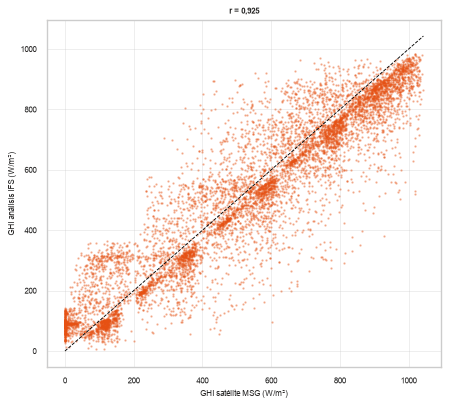

7650 filas x 2 columnas; primeras 10:


,ghi_satelite_msg,ghi_ifs_analisis
datatime,,
2025-01-01 08:00:00-05:00,224.25,198.0
2025-01-01 09:00:00-05:00,450.00,413.0
2025-01-01 10:00:00-05:00,643.75,616.0
2025-01-01 11:00:00-05:00,782.00,748.0
2025-01-01 12:00:00-05:00,855.25,802.0
2025-01-01 13:00:00-05:00,855.25,817.0
2025-01-01 14:00:00-05:00,774.50,747.0
2025-01-01 15:00:00-05:00,532.50,607.0
2025-01-01 16:00:00-05:00,378.50,398.0


In [16]:
# Sección 2.8. Series meteorológicas: descripción y comparación de fuentes de irradiancia
imposibles = {}
def ghi_horaria(nombre, col, paso, marca="fin"):
    df = crudos[nombre]
    if "previousday" in df.columns:
        df = df[df["previousday"] == 0]
    r = imp.regularizar(df, paso, [col])
    centro = {"fin": pd.Timedelta(paso) / 2, "inicio": -pd.Timedelta(paso) / 2, "instante": None}[marca]
    m = calidad.limites_irradiancia(r, lugar, centro)
    imposibles[nombre] = int(m[col].sum())
    r = r.mask(m)                                   # imposibles -> faltantes
    if paso != "1h":
        r, _ = agg.agregar(r, {col: "media"}, "1h", paso, marca="fin" if marca == "instante" else marca)
    elif marca == "inicio":
        r.index = r.index + pd.Timedelta("1h")
    return r[col]

fuentes_ghi = {
    "satelite_msg": ghi_horaria("om_satellite__eumetsat_lsa_saf_msg", "shortwave_radiation", "15min"),
    "ifs_analisis": ghi_horaria("om_archive__ecmwf_ifs", "shortwave_radiation", "1h"),
    "era5": ghi_horaria("om_archive__era5", "shortwave_radiation", "1h"),
    "nsrdb_goes": ghi_horaria("nsrdb_goes", "ghi", "10min", marca="instante"),
    "nasa_power": ghi_horaria("nasa_power", "allsky_sfc_sw_dwn", "1h", marca="inicio"),
}
display(Markdown("Valores de GHI fuera de los límites físicos de la BSRN: " +
                 ", ".join(f"{k}: {v}" for k, v in imposibles.items())))
from functools import reduce
horas = reduce(lambda a, b: a.union(b), [s.index for s in fuentes_ghi.values()])
sol_h = solar.es_de_dia(horas, lugar, elevacion_minima=5, desplazamiento=pd.Timedelta("30min"))
comp = car.comparar_fuentes(fuentes_ghi, sol_h)
display(comp.round(3))
sat_vs = comp[comp["fuente_a"] == "satelite_msg"].set_index("fuente_b")
signo = "menos" if (sat_vs["rmbe_pct"] < 0).all() else "más" if (sat_vs["rmbe_pct"] > 0).all() else "distinta"
display(Markdown(
    f"**Observación.** En horas de sol, las demás fuentes dan en promedio {signo} irradiancia que el satélite MSG "
    f"(rMBE entre {sat_vs['rmbe_pct'].min():.1f} % y {sat_vs['rmbe_pct'].max():.1f} %), con un rRMSE horario de "
    f"{sat_vs['rrmse_pct'].min():.0f} % a {sat_vs['rrmse_pct'].max():.0f} %. Sin una medición en sitio no se puede "
    f"saber cuál fuente es la correcta: la elección se hace en la sección 5.1, por su capacidad de explicar la "
    f"producción medida de los inversores, que actúan como sensores de irradiancia."))
sat_sol = fuentes_ghi["satelite_msg"][sol_h.reindex(fuentes_ghi["satelite_msg"].index).fillna(False).to_numpy()]
fig(gr.dispersion(sat_sol, fuentes_ghi["ifs_analisis"], "GHI satélite MSG (W/m²)", "GHI análisis IFS (W/m²)"),
    "dispersion_ghi_satelite_ifs", pd.concat({"ghi_satelite_msg": sat_sol, "ghi_ifs_analisis": fuentes_ghi["ifs_analisis"]}, axis=1, sort=True).dropna())
res.registrar(f"localidades.{GRUPO}.datos.comparacion_ghi", comp.round(4).to_dict(orient="records"))
res.registrar(f"localidades.{GRUPO}.datos.ghi_imposibles", imposibles)

**Mapas de calor día × hora de la irradiancia.** Cada columna es un día y cada fila una hora local; el
color es la GHI media de la hora y el blanco, una hora de sol sin dato. Se muestran dos vistas: de
05:00 a 19:00, que cubre el amanecer más temprano y el ocaso más tardío del año a 11° N, y de 24 h, que
deja ver también lo que ocurre de noche (en gris claro, las horas nocturnas sin dato). Arriba de cada
mapa, la irradiación diaria (kWh/m²): los días sin dato cortan la línea.

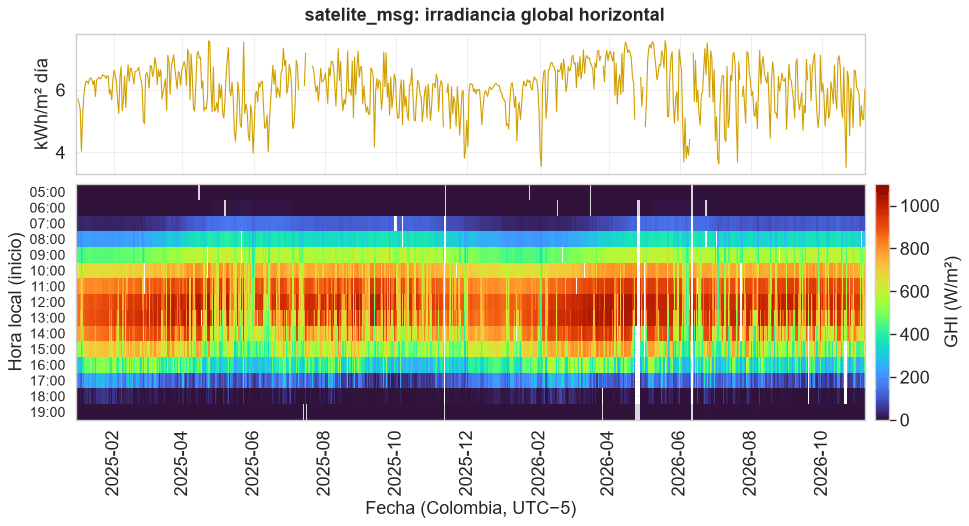

676 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2024-12-31 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-01-01 00:00:00-05:00,0.0,0.0,33.50,224.25,450.00,643.75,782.00,855.25,855.25,774.50,532.50,378.50,173.25,3.00,0.0
2025-01-02 00:00:00-05:00,0.0,0.0,31.50,217.75,441.75,636.25,778.75,848.75,852.00,770.50,515.25,298.00,170.75,4.00,0.0
2025-01-03 00:00:00-05:00,0.0,0.0,30.00,214.00,438.50,634.25,760.50,817.25,753.50,730.75,556.00,295.00,121.00,14.25,0.0
2025-01-04 00:00:00-05:00,0.0,0.0,28.25,191.00,367.50,457.00,519.75,602.50,648.50,459.75,398.25,252.50,107.00,5.00,0.0
2025-01-05 00:00:00-05:00,0.0,0.0,32.00,222.00,400.75,562.25,721.50,725.25,696.50,630.75,495.25,397.50,194.75,1.25,0.0
2025-01-06 00:00:00-05:00,0.0,0.0,31.25,221.75,448.50,645.50,788.75,865.25,868.50,755.50,602.75,383.25,164.50,11.25,0.0
2025-01-07 00:00:00-05:00,0.0,0.0,30.75,222.25,449.75,646.75,790.75,868.50,874.00,804.50,667.25,472.25,241.50,34.75,0.0
2025-01-08 00:00:00-05:00,0.0,0.0,32.25,232.25,466.75,668.00,813.00,890.75,894.75,823.00,683.00,486.50,254.00,38.25,0.0
2025-01-09 00:00:00-05:00,0.0,0.0,31.25,228.75,459.50,658.50,803.75,883.75,893.50,828.75,688.75,490.25,256.75,39.25,0.0


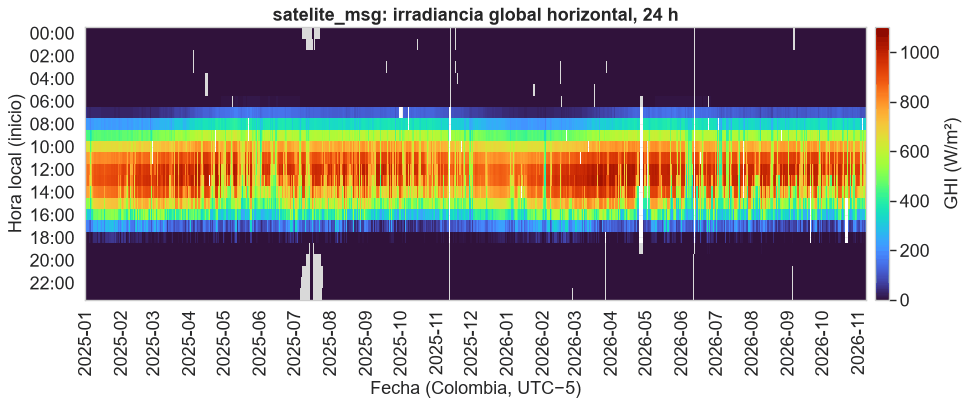

676 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-12-31 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0
2025-01-01 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.50,224.25,450.00,643.75,782.00,855.25,855.25,774.50,532.50,378.50,173.25,3.00,0.0,0.0,0.0,0.0,0.0
2025-01-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.50,217.75,441.75,636.25,778.75,848.75,852.00,770.50,515.25,298.00,170.75,4.00,0.0,0.0,0.0,0.0,0.0
2025-01-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.00,214.00,438.50,634.25,760.50,817.25,753.50,730.75,556.00,295.00,121.00,14.25,0.0,0.0,0.0,0.0,0.0
2025-01-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.25,191.00,367.50,457.00,519.75,602.50,648.50,459.75,398.25,252.50,107.00,5.00,0.0,0.0,0.0,0.0,0.0
2025-01-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.00,222.00,400.75,562.25,721.50,725.25,696.50,630.75,495.25,397.50,194.75,1.25,0.0,0.0,0.0,0.0,0.0
2025-01-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.25,221.75,448.50,645.50,788.75,865.25,868.50,755.50,602.75,383.25,164.50,11.25,0.0,0.0,0.0,0.0,0.0
2025-01-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.75,222.25,449.75,646.75,790.75,868.50,874.00,804.50,667.25,472.25,241.50,34.75,0.0,0.0,0.0,0.0,0.0
2025-01-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.25,232.25,466.75,668.00,813.00,890.75,894.75,823.00,683.00,486.50,254.00,38.25,0.0,0.0,0.0,0.0,0.0
2025-01-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.25,228.75,459.50,658.50,803.75,883.75,893.50,828.75,688.75,490.25,256.75,39.25,0.0,0.0,0.0,0.0,0.0


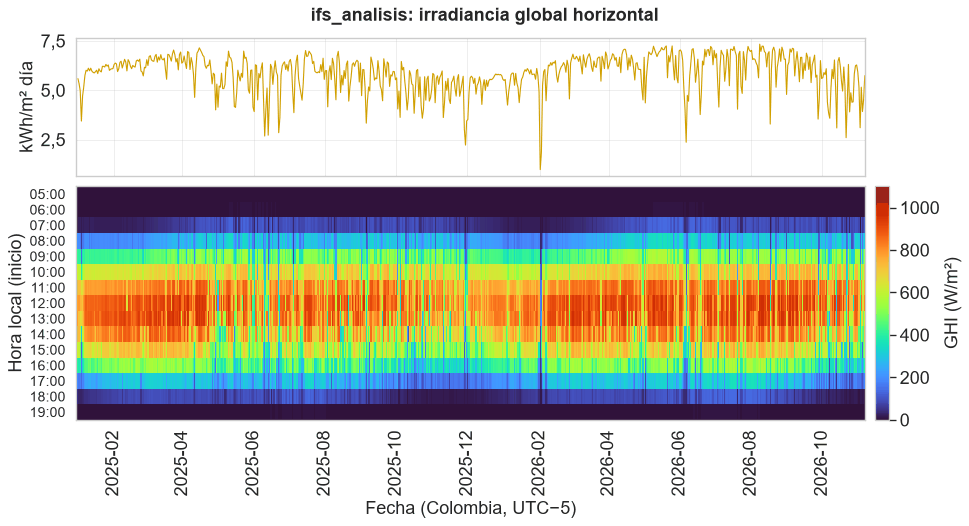

676 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2024-12-31 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-01-01 00:00:00-05:00,0.0,0.0,25.0,198.0,413.0,616.0,748.0,802.0,817.0,747.0,607.0,398.0,190.0,29.0,0.0
2025-01-02 00:00:00-05:00,0.0,0.0,21.0,195.0,403.0,595.0,724.0,785.0,719.0,732.0,604.0,375.0,160.0,26.0,0.0
2025-01-03 00:00:00-05:00,0.0,0.0,23.0,167.0,400.0,599.0,708.0,740.0,660.0,581.0,473.0,405.0,175.0,30.0,0.0
2025-01-04 00:00:00-05:00,0.0,0.0,14.0,68.0,135.0,383.0,644.0,738.0,671.0,310.0,140.0,168.0,141.0,26.0,0.0
2025-01-05 00:00:00-05:00,0.0,0.0,22.0,159.0,374.0,506.0,652.0,717.0,697.0,602.0,420.0,335.0,188.0,32.0,0.0
2025-01-06 00:00:00-05:00,0.0,0.0,21.0,163.0,410.0,597.0,700.0,794.0,757.0,608.0,517.0,384.0,179.0,37.0,0.0
2025-01-07 00:00:00-05:00,0.0,0.0,23.0,194.0,408.0,596.0,748.0,830.0,837.0,768.0,636.0,445.0,225.0,43.0,0.0
2025-01-08 00:00:00-05:00,0.0,0.0,24.0,205.0,430.0,635.0,791.0,877.0,869.0,783.0,652.0,457.0,242.0,46.0,0.0
2025-01-09 00:00:00-05:00,0.0,0.0,23.0,201.0,427.0,626.0,773.0,854.0,863.0,803.0,661.0,454.0,238.0,47.0,0.0


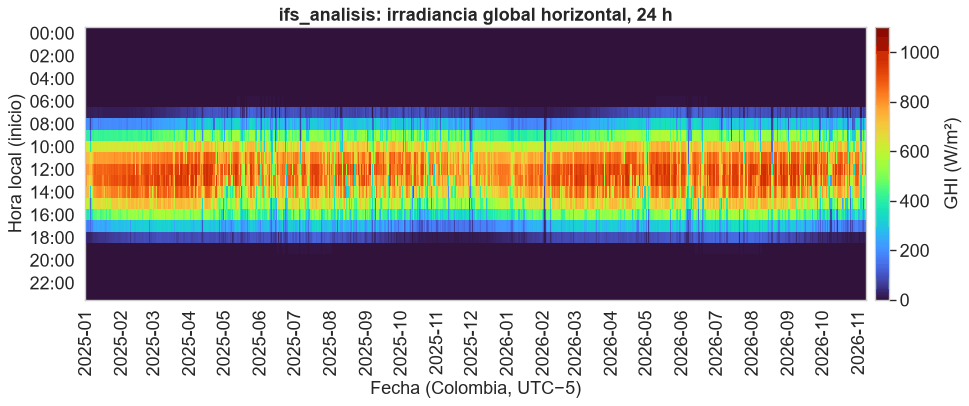

676 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-12-31 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-01-01 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,198.0,413.0,616.0,748.0,802.0,817.0,747.0,607.0,398.0,190.0,29.0,0.0,0.0,0.0,0.0,0.0
2025-01-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,195.0,403.0,595.0,724.0,785.0,719.0,732.0,604.0,375.0,160.0,26.0,0.0,0.0,0.0,0.0,0.0
2025-01-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,167.0,400.0,599.0,708.0,740.0,660.0,581.0,473.0,405.0,175.0,30.0,0.0,0.0,0.0,0.0,0.0
2025-01-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,68.0,135.0,383.0,644.0,738.0,671.0,310.0,140.0,168.0,141.0,26.0,0.0,0.0,0.0,0.0,0.0
2025-01-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.0,159.0,374.0,506.0,652.0,717.0,697.0,602.0,420.0,335.0,188.0,32.0,0.0,0.0,0.0,0.0,0.0
2025-01-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,163.0,410.0,597.0,700.0,794.0,757.0,608.0,517.0,384.0,179.0,37.0,0.0,0.0,0.0,0.0,0.0
2025-01-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,194.0,408.0,596.0,748.0,830.0,837.0,768.0,636.0,445.0,225.0,43.0,0.0,0.0,0.0,0.0,0.0
2025-01-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,205.0,430.0,635.0,791.0,877.0,869.0,783.0,652.0,457.0,242.0,46.0,0.0,0.0,0.0,0.0,0.0
2025-01-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,201.0,427.0,626.0,773.0,854.0,863.0,803.0,661.0,454.0,238.0,47.0,0.0,0.0,0.0,0.0,0.0


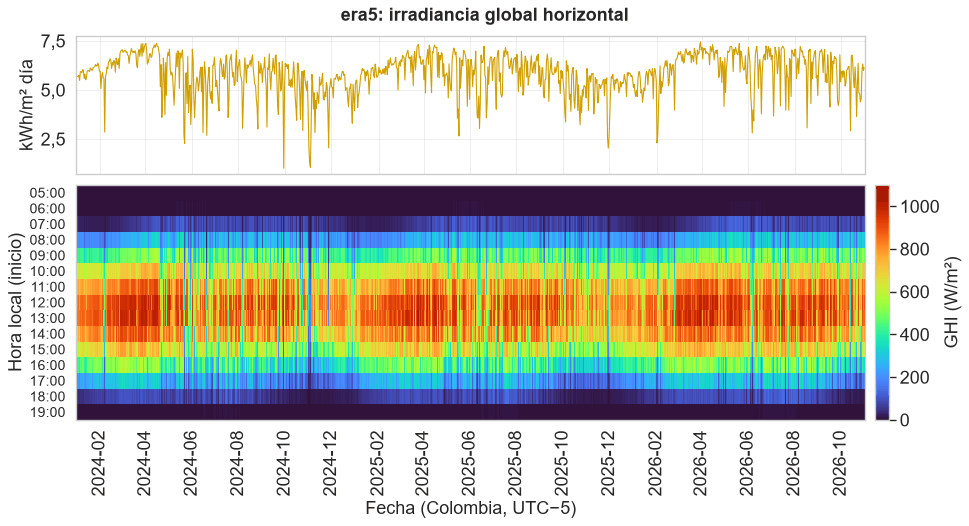

1036 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2024-01-01 00:00:00-05:00,0.0,0.0,28.0,207.0,412.0,619.0,746.0,844.0,835.0,746.0,620.0,428.0,212.0,32.0,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,27.0,202.0,404.0,624.0,766.0,843.0,852.0,675.0,635.0,402.0,221.0,34.0,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,26.0,204.0,404.0,590.0,755.0,837.0,843.0,782.0,576.0,405.0,220.0,35.0,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,26.0,203.0,423.0,621.0,765.0,843.0,841.0,752.0,588.0,427.0,217.0,36.0,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,24.0,195.0,400.0,548.0,723.0,785.0,839.0,695.0,627.0,405.0,206.0,40.0,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,25.0,203.0,427.0,628.0,760.0,851.0,862.0,798.0,634.0,456.0,239.0,43.0,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,24.0,199.0,421.0,612.0,770.0,851.0,867.0,792.0,657.0,464.0,239.0,44.0,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,24.0,201.0,427.0,628.0,776.0,860.0,845.0,765.0,623.0,453.0,233.0,44.0,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,24.0,202.0,429.0,627.0,776.0,860.0,869.0,809.0,668.0,475.0,249.0,47.0,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,24.0,200.0,425.0,622.0,772.0,857.0,870.0,796.0,675.0,472.0,246.0,42.0,0.0


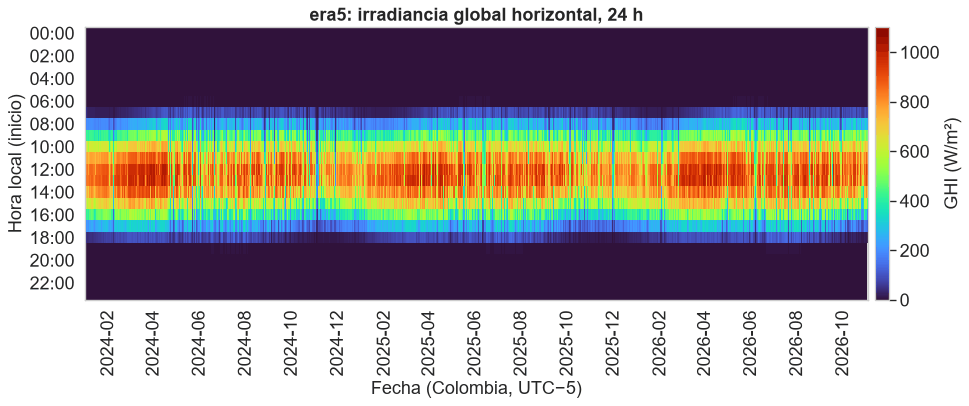

1036 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-01-01 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,207.0,412.0,619.0,746.0,844.0,835.0,746.0,620.0,428.0,212.0,32.0,0.0,0.0,0.0,0.0,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,202.0,404.0,624.0,766.0,843.0,852.0,675.0,635.0,402.0,221.0,34.0,0.0,0.0,0.0,0.0,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.0,204.0,404.0,590.0,755.0,837.0,843.0,782.0,576.0,405.0,220.0,35.0,0.0,0.0,0.0,0.0,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.0,203.0,423.0,621.0,765.0,843.0,841.0,752.0,588.0,427.0,217.0,36.0,0.0,0.0,0.0,0.0,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,195.0,400.0,548.0,723.0,785.0,839.0,695.0,627.0,405.0,206.0,40.0,0.0,0.0,0.0,0.0,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,203.0,427.0,628.0,760.0,851.0,862.0,798.0,634.0,456.0,239.0,43.0,0.0,0.0,0.0,0.0,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,199.0,421.0,612.0,770.0,851.0,867.0,792.0,657.0,464.0,239.0,44.0,0.0,0.0,0.0,0.0,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,201.0,427.0,628.0,776.0,860.0,845.0,765.0,623.0,453.0,233.0,44.0,0.0,0.0,0.0,0.0,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,202.0,429.0,627.0,776.0,860.0,869.0,809.0,668.0,475.0,249.0,47.0,0.0,0.0,0.0,0.0,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,200.0,425.0,622.0,772.0,857.0,870.0,796.0,675.0,472.0,246.0,42.0,0.0,0.0,0.0,0.0,0.0


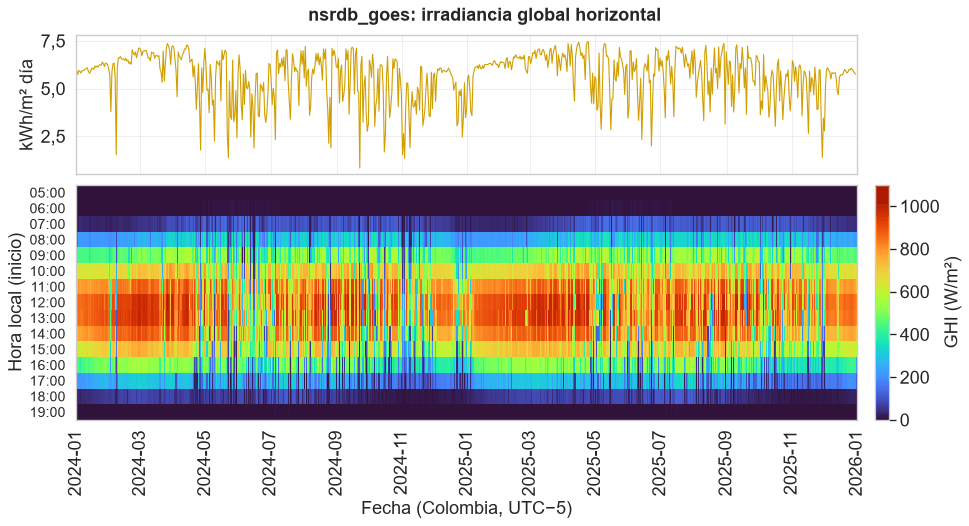

731 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2024-01-01 00:00:00-05:00,0.0,0.0,39.8333,233.8333,458.0000,652.3333,792.0000,861.6667,855.5000,775.8333,629.1667,432.0000,209.3333,30.1667,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,16.1667,125.0000,439.1667,630.1667,770.0000,842.5000,841.8333,767.3333,626.8333,434.0000,213.1667,31.8333,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,23.6667,226.8333,434.1667,647.0000,787.5000,859.1667,856.8333,779.8333,636.5000,440.1667,217.3333,33.1667,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,37.0000,227.1667,451.0000,643.1667,781.5000,854.1667,850.1667,771.3333,627.1667,432.6667,212.5000,32.3333,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,35.1667,221.5000,443.8333,635.0000,773.0000,847.5000,844.0000,766.1667,617.3333,397.0000,210.1667,25.6667,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,34.0000,219.5000,443.5000,641.5000,785.5000,857.6667,833.6667,778.6667,635.6667,441.5000,220.0000,34.6667,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,33.6667,218.6667,441.8333,639.0000,782.6667,857.1667,857.0000,781.6667,638.5000,443.6667,220.8333,35.3333,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,32.5000,215.0000,437.1667,637.0000,784.6667,860.1667,861.3333,787.0000,644.0000,446.5000,221.8333,35.8333,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,31.8333,215.0000,441.3333,643.0000,791.0000,869.0000,870.1667,794.5000,650.5000,453.0000,228.1667,38.0000,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,32.8333,218.8333,445.3333,644.8333,791.5000,870.0000,872.0000,798.6667,657.6667,460.3333,233.3333,39.5000,0.0


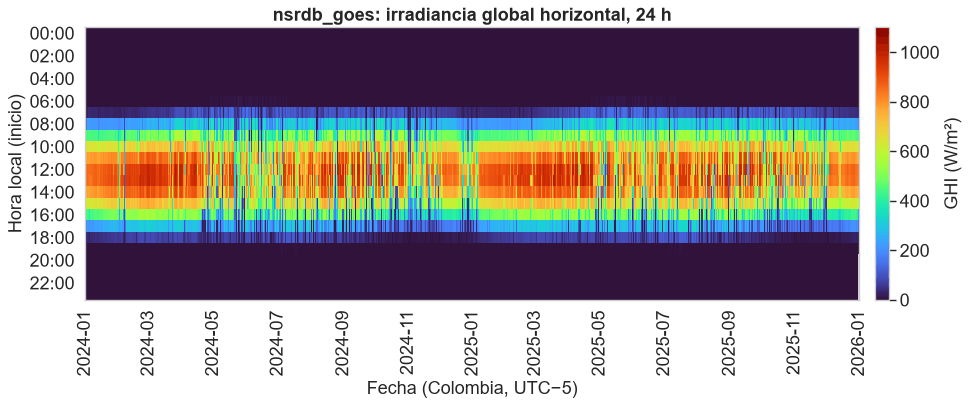

731 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-01-01 00:00:00-05:00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,39.8333,233.8333,458.0000,652.3333,792.0000,861.6667,855.5000,775.8333,629.1667,432.0000,209.3333,30.1667,0.0,0.0,0.0,0.0,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.1667,125.0000,439.1667,630.1667,770.0000,842.5000,841.8333,767.3333,626.8333,434.0000,213.1667,31.8333,0.0,0.0,0.0,0.0,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.6667,226.8333,434.1667,647.0000,787.5000,859.1667,856.8333,779.8333,636.5000,440.1667,217.3333,33.1667,0.0,0.0,0.0,0.0,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,37.0000,227.1667,451.0000,643.1667,781.5000,854.1667,850.1667,771.3333,627.1667,432.6667,212.5000,32.3333,0.0,0.0,0.0,0.0,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35.1667,221.5000,443.8333,635.0000,773.0000,847.5000,844.0000,766.1667,617.3333,397.0000,210.1667,25.6667,0.0,0.0,0.0,0.0,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.0000,219.5000,443.5000,641.5000,785.5000,857.6667,833.6667,778.6667,635.6667,441.5000,220.0000,34.6667,0.0,0.0,0.0,0.0,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.6667,218.6667,441.8333,639.0000,782.6667,857.1667,857.0000,781.6667,638.5000,443.6667,220.8333,35.3333,0.0,0.0,0.0,0.0,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.5000,215.0000,437.1667,637.0000,784.6667,860.1667,861.3333,787.0000,644.0000,446.5000,221.8333,35.8333,0.0,0.0,0.0,0.0,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.8333,215.0000,441.3333,643.0000,791.0000,869.0000,870.1667,794.5000,650.5000,453.0000,228.1667,38.0000,0.0,0.0,0.0,0.0,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.8333,218.8333,445.3333,644.8333,791.5000,870.0000,872.0000,798.6667,657.6667,460.3333,233.3333,39.5000,0.0,0.0,0.0,0.0,0.0


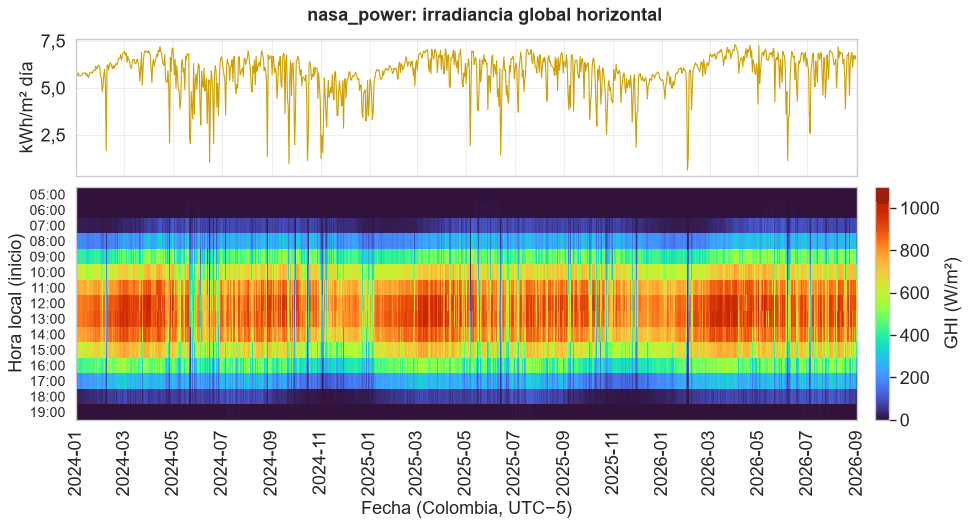

974 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2024-01-01 00:00:00-05:00,0.0,0.0,23.02,207.88,429.33,622.20,758.80,824.75,840.88,771.67,618.53,422.55,198.77,24.12,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,18.12,185.10,400.40,611.45,750.17,828.45,836.72,755.85,617.17,418.42,192.02,25.33,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,20.67,193.25,388.95,621.78,770.25,849.85,849.62,781.70,638.65,444.33,220.62,29.15,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,19.10,190.70,406.20,610.83,755.03,836.88,832.90,756.00,618.38,425.80,204.12,24.48,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,17.40,182.20,403.12,605.95,748.95,829.40,823.83,741.60,624.25,422.88,207.62,27.48,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,17.92,195.23,416.98,612.70,747.88,820.17,822.70,774.45,597.30,409.17,191.65,29.77,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,17.20,181.95,402.33,598.35,738.38,834.38,837.62,770.05,620.53,424.33,200.73,27.45,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,16.73,180.80,404.25,605.00,747.45,834.12,837.22,770.60,624.60,428.42,204.55,28.17,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,16.85,186.00,416.05,615.58,760.62,837.00,845.30,781.80,637.50,444.23,219.85,29.35,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,15.90,182.85,407.85,604.85,756.90,836.47,845.35,779.08,640.25,447.00,222.70,30.02,0.0


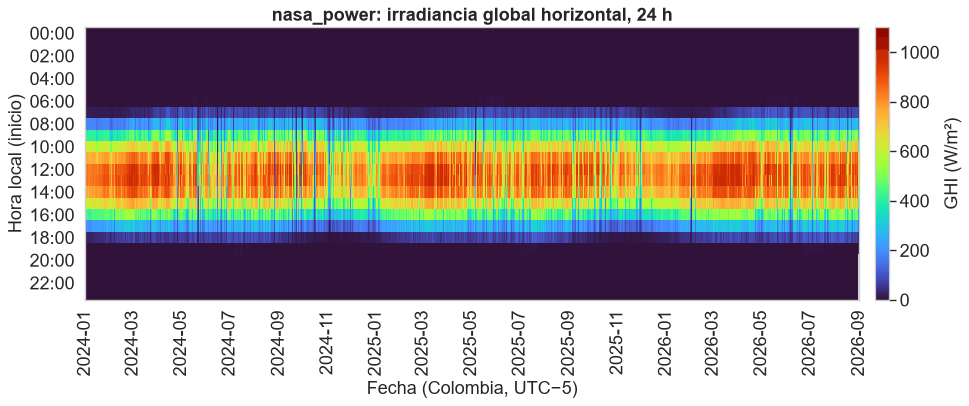

974 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-01-01 00:00:00-05:00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,23.02,207.88,429.33,622.20,758.80,824.75,840.88,771.67,618.53,422.55,198.77,24.12,0.0,0.0,0.0,0.0,0.0
2024-01-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.12,185.10,400.40,611.45,750.17,828.45,836.72,755.85,617.17,418.42,192.02,25.33,0.0,0.0,0.0,0.0,0.0
2024-01-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.67,193.25,388.95,621.78,770.25,849.85,849.62,781.70,638.65,444.33,220.62,29.15,0.0,0.0,0.0,0.0,0.0
2024-01-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.10,190.70,406.20,610.83,755.03,836.88,832.90,756.00,618.38,425.80,204.12,24.48,0.0,0.0,0.0,0.0,0.0
2024-01-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.40,182.20,403.12,605.95,748.95,829.40,823.83,741.60,624.25,422.88,207.62,27.48,0.0,0.0,0.0,0.0,0.0
2024-01-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.92,195.23,416.98,612.70,747.88,820.17,822.70,774.45,597.30,409.17,191.65,29.77,0.0,0.0,0.0,0.0,0.0
2024-01-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.20,181.95,402.33,598.35,738.38,834.38,837.62,770.05,620.53,424.33,200.73,27.45,0.0,0.0,0.0,0.0,0.0
2024-01-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.73,180.80,404.25,605.00,747.45,834.12,837.22,770.60,624.60,428.42,204.55,28.17,0.0,0.0,0.0,0.0,0.0
2024-01-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.85,186.00,416.05,615.58,760.62,837.00,845.30,781.80,637.50,444.23,219.85,29.35,0.0,0.0,0.0,0.0,0.0
2024-01-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.90,182.85,407.85,604.85,756.90,836.47,845.35,779.08,640.25,447.00,222.70,30.02,0.0,0.0,0.0,0.0,0.0


In [17]:
# Sección 2.8. Series meteorológicas: descripción y comparación de fuentes de irradiancia
noche_h = ~solar.es_de_dia(horas, lugar, elevacion_minima=0, desplazamiento=pd.Timedelta("30min"))
for k, s in fuentes_ghi.items():
    s = s.dropna()
    if s.empty:
        continue
    dias_k = (s.index - pd.Timedelta("1h")).tz_convert(config.ZONA).normalize()
    diaria = (s.groupby(dias_k).sum(min_count=20) / 1000).rename("irradiacion_kwh_m2")
    fig(gr.panel_diario_y_mapa(s, diaria, f"{k}: irradiancia global horizontal", "GHI (W/m²)", "kWh/m² día", (5, 19),
                               noche_h, vmax=1100), f"mapa_ghi_{k}", gr.tabla_dia_hora(s, (5, 19)).T)
    # gr.mostrar(gr.tabla_dia_hora(s, (5, 19)).T, todas=True)   # todas las filas
    fig(gr.mapa_dia_hora(s, f"{k}: irradiancia global horizontal, 24 h", "GHI (W/m²)", None, noche_h, vmax=1100),
        f"mapa_ghi_24h_{k}", gr.tabla_dia_hora(s, None).T)

### 2.9. Viabilidad operativa de las fuentes

Una fuente puede explicar muy bien la producción del pasado y aun así no servir para un sistema que pronostica cada día,
porque también importa cuándo publica sus datos. La tabla resume, para cada fuente, su resolución espacial y temporal
(según la documentación del proveedor), la distancia entre el punto de la localidad y la celda que devolvió la API
(`meteo.celdas`), el último dato disponible y el retraso respecto al último dato de la telemetría.

Consideramos apta para producción una fuente observada que publica con 3 días de retraso o menos, y los pronósticos
siempre lo son, porque se emiten antes del día que pronostican. Las demás fuentes sirven para entrenar, validar y
calcular el rendimiento observado con retraso, pero no para alimentar el pronóstico diario.

In [18]:
# Sección 2.9. Viabilidad operativa de las fuentes
ref_t = max(d["datatime"].max() for d in tel.values())          # último dato de la telemetría
# El retraso se mide con el último dato válido de cada fuente al cierre de los datos (no en la ventana leida, que corta
# todas las fuentes en la misma fecha y haría parecer al día a las que publican con semanas de demora)
PUBLICACION = car.retraso_publicacion(GRUPO)
FICHA = car.ficha_fuentes(crudos, punto, const["celdas"], ref_t, retraso_max_dias=3.0, publicacion=PUBLICACION)
display(FICHA.drop(columns=["tipo"]))
aptas = FICHA.index[FICHA["apta_produccion"]].tolist()
retraso_de = lambda s: f"{FICHA.loc[s, 'retraso_dias']:.0f}" if s in FICHA.index else "?"
display(Markdown(
    f"**Observación.** Con el retraso de publicación medido al cierre de los datos, el "
    f"{pd.Timestamp(config.fin_observado()) - pd.Timedelta(days=1):%Y-%m-%d}, son aptas para producción: {', '.join(FICHA.loc[aptas, 'fuente'])}. "
    f"NASA POWER publica la radiación horaria con unos {retraso_de('nasa_power')} días de retraso y NSRDB termina en "
    f"2025, así que solo sirven como referencia histórica. ERA5 llega con unos {retraso_de('om_archive__era5')} días de "
    f"retraso: sirve para la climatología del pronóstico a 30 días, pero no para medir el rendimiento en operación ni "
    f"como entrada del pronóstico. **En producción**, el pronóstico del día siguiente usa el pronóstico IFS (escenario "
    f"E2), que siempre está disponible; la fuente observada solo define con qué irradiancia se mide el PR."))
res.registrar(f"localidades.{GRUPO}.datos.ficha_fuentes", FICHA.drop(columns=["tipo"]).astype(str).to_dict(orient="index"))

,fuente,resolucion,paso,licencia,distancia_celda_km,ultimo_dato_utc,retraso_dias,apta_produccion
serie,,,,,,,,
om_satellite__eumetsat_lsa_saf_msg,Satélite MSG (EUMETSAT LSA SAF),"0,05° (~5 km) en el nadir; más gruesa en el bo...",15 min,CC BY 4.0,2.5,2026-11-07 04:45:00+00:00,0.0,True
om_archive__ecmwf_ifs,Análisis ECMWF IFS,9 km,1 h,CC BY 4.0,3.8,2026-11-07 04:00:00+00:00,0.0,True
om_archive__era5,Reanálisis ERA5,"0,25° (~25 km)",1 h,CC BY 4.0,12.5,2026-11-01 23:00:00+00:00,5.2,False
nsrdb_goes,NSRDB GOES v4 (NREL),2 km,10 min,pública,NaN,2025-12-31 23:50:00+00:00,310.2,False
nasa_power,NASA POWER,"radiación 1° (~111 km); meteorología 0,5° × 0,...",1 h,pública,0.0,2026-08-31 23:00:00+00:00,67.2,False
om_previous_runs__ecmwf_ifs025,"Pronóstico ECMWF IFS 0,25° archivado","0,25° (~28 km)",1 h,CC BY 4.0,12.5,2026-11-07 04:00:00+00:00,0.0,True
om_previous_runs__gfs_seamless,Pronóstico NCEP GFS archivado,"0,25° (~28 km) en Colombia",1 h,CC BY 4.0,8.9,2026-11-07 04:00:00+00:00,0.0,True
om_air_quality__cams_global,CAMS global (aerosoles),"0,4° (~45 km)",1 h,CC BY 4.0,5.5,2026-11-07 04:00:00+00:00,0.0,True
ideam,Estaciones automáticas IDEAM,puntual (estación),2 a 60 min,"CC BY-SA 4.0, no validados",NaN,2026-11-07 04:00:00+00:00,0.0,True


**Observación.** Con el retraso de publicación medido al cierre de los datos, el 2026-11-06, son aptas para producción: Satélite MSG (EUMETSAT LSA SAF), Análisis ECMWF IFS, Pronóstico ECMWF IFS 0,25° archivado, Pronóstico NCEP GFS archivado, CAMS global (aerosoles), Estaciones automáticas IDEAM. NASA POWER publica la radiación horaria con unos 67 días de retraso y NSRDB termina en 2025, así que solo sirven como referencia histórica. ERA5 llega con unos 5 días de retraso: sirve para la climatología del pronóstico a 30 días, pero no para medir el rendimiento en operación ni como entrada del pronóstico. **En producción**, el pronóstico del día siguiente usa el pronóstico IFS (escenario E2), que siempre está disponible; la fuente observada solo define con qué irradiancia se mide el PR.

### 2.10. Estaciones del IDEAM

Las estaciones automáticas del IDEAM cercanas a la localidad miden temperatura, humedad, precipitación, presión y
viento, pero no radiación. Nos sirven para **validar** las variables del análisis IFS y de ERA5 que entran en los
modelos y para medir la **lluvia real**, que limpia los paneles.

Asignamos cada sensor a una variable común y, si una estación tiene dos sensores de la misma variable (convencional y
GPRS), usamos el de más datos. Los valores imposibles pasan a faltantes, calculamos la media horaria (la suma para la
lluvia) etiquetada al final de la hora solo con al menos el 80 % de las lecturas esperadas y, para cada variable,
tomamos la estación más cercana con datos.

El proceso de extracción calcula `datatime = fechaobservacion + 5 h`, suponiendo que la fecha viene en hora de
Colombia, pero la temperatura muestra que ya viene en UTC, porque sin corregir el mínimo diario cae hacia las 11:00 y
el máximo hacia las 19:00 locales. Corregimos el desfase en el análisis y lo elegimos con un **experimento**, en el que
calculamos para −4, −5 y −6 h la correlación cruzada de la estación con el análisis IFS. Decide la **presión**, cuya
marea semidiurna (máximos hacia las 10 y las 22 h) tiene una fase regular que el modelo reproduce bien, de modo que la
corrección correcta es la que deja su máximo en el rezago 0. Informamos también la temperatura, pero no la usamos para
decidir, porque la fase de su ciclo diario puede diferir entre la estación y el modelo por razones físicas (inercia del
sensor y brisa marina) sin que la marca de tiempo esté mal.

Los datos llegan a datos.gov.co con uno a dos días de retraso y no están validados por el IDEAM. Como no hay
pronóstico, en un modelo solo pueden entrar como información del pasado.

,codigoestacion,codigosensor,descripcionsensor,unidadmedida,variable,distancia_km,lecturas,paso_nativo
12,2904000177,240,PRECIPITACIÓN,mm,precipitation,4.878,88776,0 days 00:10:00
8,2904000176,240,PRECIPITACIÓN,mm,precipitation,6.921,78288,0 days 00:10:00
2,29004520,240,PRECIPITACIÓN,mm,precipitation,8.597,74991,0 days 00:10:00
14,29047000,240,PRECIPITACIÓN,mm,precipitation,14.972,48088,0 days 00:10:00
13,2904000177,255,PRESIÓN ATMOSFÉRICA,hPa,surface_pressure,4.878,14766,0 days 01:00:00
9,2904000176,255,PRESIÓN ATMOSFÉRICA,hPa,surface_pressure,6.921,13040,0 days 01:00:00
3,29004520,255,PRESIÓN ATMOSFÉRICA,hPa,surface_pressure,8.597,12568,0 days 01:00:00
5,29004520,68,TEMPERATURA DEL AIRE A 2 m,°C,temperature_2m,8.597,11941,0 days 01:00:00
10,2904000177,103,VELOCIDAD DEL VIENTO,m/s,wind_speed_10m,4.878,88699,0 days 00:10:00
6,2904000176,103,VELOCIDAD DEL VIENTO,m/s,wind_speed_10m,6.921,77985,0 days 00:10:00


**Alineación del IDEAM con el análisis IFS** (rezago de la correlación máxima por corrección y variable)

,correccion_h,variable,rezago_max_h,correlacion_max,correlacion_rezago_0
0,-4,surface_pressure,1,0.2894,0.2864
1,-4,temperature_2m,1,0.7505,0.6913
2,-5,surface_pressure,0,0.2894,0.2894
3,-5,temperature_2m,0,0.7505,0.7505
4,-6,surface_pressure,-1,0.2894,0.2740
5,-6,temperature_2m,-1,0.7505,0.7356


,variable,estacion,sensor,distancia_km,paso_nativo,horas_validas,imposibles_descartados,inicio,fin
0,temperature_2m,29004520,TEMPERATURA DEL AIRE A 2 m,8.597,0 days 01:00:00,11929,12,2025-01-01 00:00:00+00:00,2026-11-05 23:00:00+00:00
1,precipitation,2904000177,PRECIPITACIÓN,4.878,0 days 00:10:00,14871,1,2025-01-01 01:00:00+00:00,2026-11-06 00:00:00+00:00
2,surface_pressure,2904000177,PRESIÓN ATMOSFÉRICA,4.878,0 days 01:00:00,14535,362,2025-01-01 00:00:00+00:00,2026-11-06 23:00:00+00:00
3,wind_speed_10m,2904000177,VELOCIDAD DEL VIENTO,4.878,0 days 00:10:00,14849,0,2025-01-01 01:00:00+00:00,2026-11-06 00:00:00+00:00


**Resultado.** Con una corrección de -5 h, la presión de la estación queda alineada con la del análisis (correlación máxima en el rezago 0 h): es el desfase entre la hora de Colombia y UTC, que la extracción sumó a una fecha que ya venía en UTC. La temperatura queda con su máximo en el rezago 0 h. Sin corregir, el máximo de la temperatura está en 5 h.

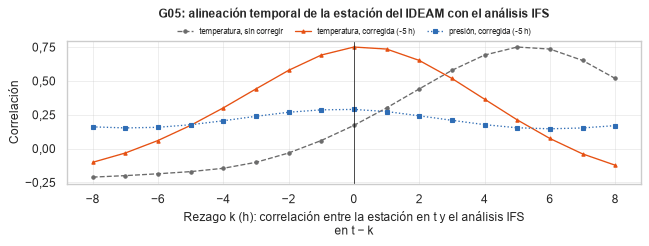

17 filas x 3 columnas; primeras 10:


,temperatura_sin_corregir,temperatura_corregida,presion_corregida
-8,-0.2107,-0.1014,0.1608
-7,-0.1998,-0.0325,0.1527
-6,-0.1860,0.0597,0.1573
-5,-0.1701,0.1716,0.1764
-4,-0.1455,0.3009,0.2057
-3,-0.1014,0.4411,0.2386
-2,-0.0325,0.5784,0.2685
-1,0.0597,0.6913,0.2864
0,0.1716,0.7505,0.2894
1,0.3009,0.7356,0.2740


,variable,fuente_b,n,mbe_b_menos_a,rmse,correlacion
0,temperature_2m,ecmwf_ifs,11929,0.591,2.352,0.751
1,temperature_2m,era5,11833,0.516,3.064,0.466
2,precipitation,ecmwf_ifs,14871,0.019,1.452,0.077
3,precipitation,era5,14774,0.033,1.358,0.071
4,surface_pressure,ecmwf_ifs,14535,7.940,9.401,0.289
5,surface_pressure,era5,14415,8.321,9.715,0.299
6,wind_speed_10m,ecmwf_ifs,14849,5.097,6.872,0.809
7,wind_speed_10m,era5,14752,10.581,12.640,0.785


**Lluvia diaria, IDEAM frente al análisis IFS (606 días).** Días con lluvia (≥ 1 mm): 87 según la estación y 274 según IFS. IFS detecta el 92 % de los días de lluvia de la estación (POD), pero el 71 % de sus días de lluvia no lo son en la estación (FAR); correlación diaria 0,43. **Conclusión.** La lluvia del análisis IFS sobrestima los días de lluvia, que son los que reinician la cuenta de días secos (suciedad). Por eso se prueba, en la sección 6, una variante de los días secos con la lluvia medida por el IDEAM.

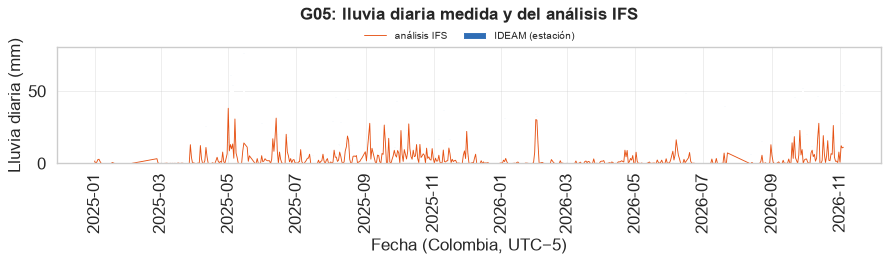

606 filas x 2 columnas; primeras 10:


,ideam_mm,ifs_mm
datatime,,
2025-01-01,0.00,1.7
2025-01-02,0.00,0.0
2025-01-03,0.00,0.9
2025-01-04,2.19,2.7
2025-01-05,0.00,2.9
2025-01-06,0.00,1.3
2025-01-07,0.00,0.1
2025-01-08,0.00,0.0
2025-01-09,0.00,0.0


In [19]:
# Sección 2.10. Estaciones del IDEAM
from tfm import ideam
if "ideam" in crudos and not crudos["ideam"].empty:
    display(ideam.catalogo(crudos["ideam"]).drop(columns=["inicio", "fin"]))
    meteo_ifs = datos.meteo_hora(crudos, "om_archive__ecmwf_ifs", "temperature_2m")
    cc_sin = ideam.correlacion_cruzada_horaria(ideam.horaria(crudos["ideam"], pd.Timedelta(0))[0]["temperature_2m"], meteo_ifs)
    # Experimento de alineación: correcciones de -4, -5 y -6 h. Decide la presión, cuya marea semidiurna tiene una fase
    # regular que el modelo reproduce bien; la fase del ciclo diario de la temperatura puede diferir entre la estación y
    # el modelo por razones físicas, sin que la marca de tiempo este mal.
    meteo_ifs_p = datos.meteo_hora(crudos, "om_archive__ecmwf_ifs", "surface_pressure")
    ALINEACION = ideam.alineacion(crudos["ideam"], {"surface_pressure": meteo_ifs_p, "temperature_2m": meteo_ifs})
    display(Markdown("**Alineación del IDEAM con el análisis IFS** (rezago de la correlación máxima por corrección y variable)"))
    display(ALINEACION.round(4))
    CORRECCION_IDEAM_H = ideam.correccion_por_alineacion(ALINEACION)
    IDEAM_H, IDEAM_RES = ideam.horaria(crudos["ideam"], pd.Timedelta(hours=CORRECCION_IDEAM_H))
    crudos.pop("ideam", None); gc.collect()                    # se conserva solo la serie horaria
    display(IDEAM_RES)
    cc_con = ideam.correlacion_cruzada_horaria(IDEAM_H["temperature_2m"], meteo_ifs)
    cc_pre = (ideam.correlacion_cruzada_horaria(IDEAM_H["surface_pressure"], meteo_ifs_p)
              if "surface_pressure" in IDEAM_H and meteo_ifs_p is not None else pd.Series(dtype=float))
    display(Markdown(
        f"**Resultado.** Con una corrección de {CORRECCION_IDEAM_H} h, la presión de la estación queda alineada con la del análisis "
        + (f"(correlación máxima en el rezago {int(cc_pre.idxmax())} h)" if not cc_pre.empty else "(sin sensor de presión, decide la temperatura)")
        + f": es el desfase entre la hora de Colombia y UTC, que la extracción sumó a una fecha que ya venía en UTC. La "
        f"temperatura queda con su máximo en el rezago {int(cc_con.idxmax())} h"
        + (": un desfase de fase entre el ciclo diario medido en la estación y el del modelo, no un error de la marca de tiempo, "
           "porque la presión, medida en la misma estación, sí queda alineada. " if int(cc_con.idxmax()) != 0 else ". ")
        + f"Sin corregir, el máximo de la temperatura está en {int(cc_sin.idxmax())} h."))
    f, ax = plt.subplots(figsize=(8, 3))
    ax.plot(cc_sin.index, cc_sin.to_numpy(), marker="o", color=config.COLOR_NEUTRO, linestyle="--", label="temperatura, sin corregir")
    ax.plot(cc_con.index, cc_con.to_numpy(), marker="^", color=config.COLOR_PRINCIPAL, label=f"temperatura, corregida ({CORRECCION_IDEAM_H} h)")
    if not cc_pre.empty:
        ax.plot(cc_pre.index, cc_pre.to_numpy(), marker="s", color=config.COLOR_SECUNDARIO, linestyle=":",
                label=f"presión, corregida ({CORRECCION_IDEAM_H} h)")
    ax.axvline(0, color="black", lw=0.6)
    ax.set_xlabel("Rezago k (h): correlación entre la estación en t y el análisis IFS en t − k"); ax.set_ylabel("Correlación"); ax.legend(fontsize=8)
    ax.set_title(f"{GRUPO}: alineación temporal de la estación del IDEAM con el análisis IFS")
    fig(f, "ideam_correlacion_cruzada", pd.DataFrame({"temperatura_sin_corregir": cc_sin, "temperatura_corregida": cc_con, "presion_corregida": cc_pre}))

    # Validación de las variables del análisis IFS y de ERA5 con la estación
    filas_v = []
    for var in IDEAM_H.columns:
        for fuente in ("om_archive__ecmwf_ifs", "om_archive__era5"):
            m = datos.meteo_hora(crudos, fuente, var)
            if m is None:
                continue
            c = car.comparar_fuentes({"ideam": IDEAM_H[var], fuente.split("__")[1]: m})
            if not c.empty:
                filas_v.append(c.assign(variable=var))
    VALID_IDEAM = pd.concat(filas_v, ignore_index=True)[["variable", "fuente_b", "n", "mbe_b_menos_a", "rmse", "correlacion"]]
    display(VALID_IDEAM.round(3))
    lluvia_ideam = ideam.lluvia_diaria(IDEAM_H["precipitation"], config.ZONA)
    lluvia_ifs = datos.meteo_hora(crudos, "om_archive__ecmwf_ifs", "precipitation")
    lluvia_ifs = lluvia_ifs.groupby((lluvia_ifs.index - pd.Timedelta("1h")).tz_convert(config.ZONA).normalize().tz_localize(None)).sum(min_count=20)
    ACUERDO = ideam.acuerdo_lluvia(lluvia_ideam, lluvia_ifs)
    display(Markdown(
        f"**Lluvia diaria, IDEAM frente al análisis IFS ({ACUERDO['dias']} días).** Días con lluvia (≥ 1 mm): "
        f"{ACUERDO['dias_lluvia_ref']} según la estación y {ACUERDO['dias_lluvia_b']} según IFS. IFS detecta el "
        f"{100 * ACUERDO['pod']:.0f} % de los días de lluvia de la estación (POD), pero el {100 * ACUERDO['far']:.0f} % de "
        f"sus días de lluvia no lo son en la estación (FAR); correlación diaria {ACUERDO['correlacion_diaria']:.2f}. "
        f"**Conclusión.** La lluvia del análisis IFS sobrestima los días de lluvia, que son los que reinician la "
        f"cuenta de días secos (suciedad). Por eso se prueba, en la sección 6, una variante de los días secos con la "
        f"lluvia medida por el IDEAM."))
    comp_ll = pd.concat({"ideam_mm": lluvia_ideam, "ifs_mm": lluvia_ifs}, axis=1).dropna()
    f, ax = plt.subplots(figsize=(11, 3.2))
    ax.bar(comp_ll.index, comp_ll["ideam_mm"], width=0.9, color=config.COLOR_SECUNDARIO, label="IDEAM (estación)")
    ax.plot(comp_ll.index, comp_ll["ifs_mm"], lw=0.8, color=config.COLOR_PRINCIPAL, label="análisis IFS")
    ax.set_ylabel("Lluvia diaria (mm)"); ax.legend(); ax.set_title(f"{GRUPO}: lluvia diaria medida y del análisis IFS")
    fig(f, "lluvia_ideam_ifs", comp_ll)
    res.registrar(f"localidades.{GRUPO}.datos.ideam", {"estaciones": IDEAM_RES.astype(str).to_dict(orient="records"),
                  "rezago_max_sin_corregir_h": int(cc_sin.idxmax()), "rezago_max_corregido_h": int(cc_con.idxmax()),
                  "rezago_max_presion_corregida_h": int(cc_pre.idxmax()) if not cc_pre.empty else None, "correccion_h": CORRECCION_IDEAM_H,
                  "alineacion": ALINEACION.round(4).to_dict(orient="records"),
                  "validacion": VALID_IDEAM.round(4).to_dict(orient="records"), "lluvia": ACUERDO})
else:
    IDEAM_H, lluvia_ideam = pd.DataFrame(), pd.Series(dtype=float)
    display(Markdown("**No hay estaciones del IDEAM a menos de 15 km con datos**: la localidad sigue sin ellas."))

## 3. Imputación en el muestreo nativo

Decidimos imputar antes de agregar y solo los huecos cortos, con reglas que dependen de la naturaleza de cada variable,
como resume la tabla.

| Naturaleza | Ejemplos | Regla |
|---|---|---|
| Potencia de generación e irradiancia | `acpower1-3`, `mppttotalinputpower`, GHI, DNI, DHI | De noche, 0 (dato físico). De día, interpolación temporal solo en huecos completos de hasta 1 h |
| Contador acumulado | `totalyield`, `dailyyield` | Interpolación lineal de huecos cortos, sin cruzar reinicios |
| Continua | Temperatura, tensión, corriente | Interpolación temporal de huecos cortos |
| Estado | `devicestatus` | Se arrastra el último estado en huecos cortos |

Los huecos medios y largos no se inventan y quedan sin valor, y el día se excluye del cálculo de objetivos y métricas si
le falta más del 10 % de sus horas de sol. Calculamos las métricas de los modelos solo en horas observadas, con al menos
11 de sus 12 lecturas de cinco minutos medidas (`config.hora_observada`). Una lectura interpolada cambia la media
horaria en una doceava parte de su propio error, que es despreciable frente al del pronóstico, mientras que exigir las
12 lecturas dejaba fuera casi todo octubre de 2026, cuando la plataforma empezó a perder lecturas sueltas.

### 3.1. Experimento: ¿qué técnica y hasta qué largo de hueco?

La técnica y el largo máximo no los suponemos, sino que los medimos. Elegimos al azar (semilla 37) hasta 300 posiciones
por duración donde la potencia está observada, el sol está a más de 5° y también están observadas la muestra anterior y
la posterior al hueco. Después borramos tramos de 15 min, 30 min, 1 h, 2 h y 3 h y los reconstruimos con cinco técnicas,
que son la interpolación lineal en el tiempo, la interpolación del **índice de cielo despejado** (se interpola
k = P / POA de cielo despejado y se multiplica de nuevo por la POA de cielo despejado, de modo que solo se interpola la
atenuación por nubes y la forma de campana del día la pone el modelo físico), el spline cúbico con los puntos observados
alrededor del hueco, el arrastre del último valor observado y la media de la serie a esa hora del día (climatología).
Por último comparamos lo reconstruido con lo realmente medido mediante el MAE, el RMSE, el sesgo (MBE) y el MAE relativo
a la media de los valores borrados (rMAE).

Esperamos que la interpolación, lineal o del índice de cielo despejado, gane en huecos cortos porque conserva la
continuidad y la autocorrelación, mientras que la media rompe el ciclo diario, el arrastre crea escalones y el spline
oscila en los bordes. No probamos KNN ni una regresión, porque necesitarían covariables del mismo instante y arriesgan
fuga de información.

**rMAE (%) medio de los inversores por técnica y duración del hueco**

duracion,15min,30min,1h,2h,3h
metodo,,,,,
arrastre,19.0,22.7,30.5,40.7,44.1
cielo_despejado,13.9,16.0,20.7,27.4,30.2
lineal,13.9,16.0,20.5,26.5,29.2
media_horaria,69.7,66.7,64.9,66.3,65.9
spline_cubico,21.4,29.0,45.7,91.8,113.4


**Sesgo (MBE, kW) medio por técnica y duración**

duracion,15min,30min,1h,2h,3h
metodo,,,,,
arrastre,-0.010,0.001,-0.077,-0.081,-0.179
cielo_despejado,-0.003,0.011,-0.013,0.074,0.103
lineal,-0.006,0.001,-0.044,-0.050,-0.138
media_horaria,0.086,-0.030,-0.074,0.050,0.123
spline_cubico,-0.008,0.019,-0.104,-0.076,-0.116


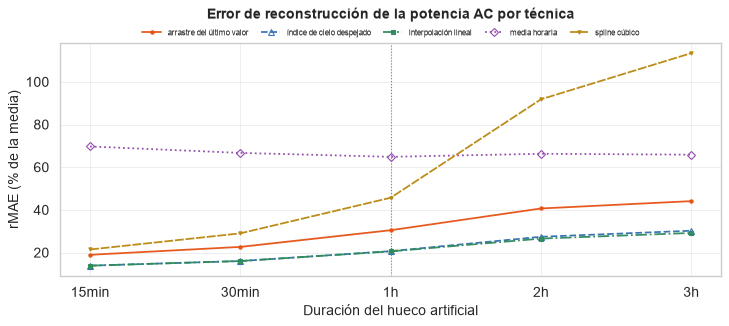

5 filas x 5 columnas; primeras 5:


metodo,arrastre,cielo_despejado,lineal,media_horaria,spline_cubico
duracion,,,,,
15min,18.9562,13.8801,13.8622,69.7140,21.4434
30min,22.6600,16.0155,16.0487,66.6923,29.0134
1h,30.4726,20.6685,20.5477,64.8656,45.6939
2h,40.6640,27.4003,26.5490,66.2884,91.8124
3h,44.1001,30.2494,29.1999,65.8671,113.4483


**Resultado.** Hasta 1 h, la interpolación lineal y cielo_despejado empatan (16,8 % y 16,9 % de rMAE medio); se elige la lineal por ser la más simple (principio de parsimonia). La peor es media_horaria (67,1 %). Con la técnica elegida el error pasa de 13,9 % en huecos de 15 min a 20,5 % en huecos de 1 h y 29,2 % en huecos de 3 h; el índice de cielo despejado llega a 30,2 % en 3 h.

**Conclusión.** Se imputa con **lineal** y solo hasta 1 h: en ese rango el error se mantiene cerca del de los huecos de 15 min; más allá crece y aparecen sesgos, así que esos huecos se dejan sin valor.

In [20]:
# Sección 3.1. Experimento: ¿qué técnica y hasta qué largo de hueco?
filas_exp, ref_poa_cs = [], {}
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in regs:
        continue
    r = regs[n]
    cs = solar.cielo_despejado(r.index, lugar)
    ref_poa_cs[n] = solar.irradiancia_plano(cs["ghi_cs"], cs["dni_cs"], cs["dhi_cs"], lugar,
                                            inv.inclinacion, inv.azimut, caras=obj.caras_de(inv))["poa_global"]
    sol5 = solar.es_de_dia(r.index, lugar, elevacion_minima=5)
    ex = imp.experimento_imputacion(obj.potencia_ac(r) / 1000, sol5, "5min", ref_poa_cs[n])
    ex.insert(0, "serie", n)
    filas_exp.append(ex)
EXP_IMP = pd.concat(filas_exp, ignore_index=True)
DURACIONES = ["15min", "30min", "1h", "2h", "3h"]
tabla = EXP_IMP.groupby(["metodo", "duracion"])["rmae_pct"].mean().unstack()[DURACIONES]
display(Markdown("**rMAE (%) medio de los inversores por técnica y duración del hueco**")); display(tabla.round(1))
display(Markdown("**Sesgo (MBE, kW) medio por técnica y duración**"))
display(EXP_IMP.groupby(["metodo", "duracion"])["mbe"].mean().unstack()[DURACIONES].round(3))

# Cada técnica con su marcador y tipo de línea: si dos coinciden, el marcador hueco de una se ve sobre el
# relleno de la otra y la leyenda lo anota
NOMBRE_TECNICA = {"lineal": "interpolación lineal", "cielo_despejado": "índice de cielo despejado", "arrastre": "arrastre del último valor",
                  "spline_cubico": "spline cúbico", "media_horaria": "media horaria"}
f = gr.lineas(tabla.T.rename(columns=NOMBRE_TECNICA), "Error de reconstrucción de la potencia AC por técnica",
              "Duración del hueco artificial", "rMAE (% de la media)")
f.axes[0].axvline(2, color="grey", ls=":", lw=1)
fig(f, "experimento_imputacion", tabla.T.rename_axis("duracion"))
# gr.mostrar(EXP_IMP, todas=True)   # resultado de cada hueco artificial

cortos = tabla[["15min", "30min", "1h"]].mean(axis=1).sort_values()
# Empate (menos de 0,5 puntos): se prefiere la técnica más simple, la lineal (parsimonia)
empate = abs(cortos.get("lineal", np.inf) - cortos.iloc[0]) < 0.5
METODO_DIURNO = "lineal" if empate or cortos.index[0] not in ("lineal", "cielo_despejado") else cortos.index[0]
texto_mejor = (f"la interpolación lineal y {cortos.index[0] if cortos.index[0] != 'lineal' else cortos.index[1]} empatan "
               f"({cortos['lineal']:.1f} % y {cortos.drop('lineal').iloc[0]:.1f} % de rMAE medio); se elige la lineal por ser "
               f"la más simple (principio de parsimonia)" if empate else
               f"la mejor técnica es **{cortos.index[0]}** (rMAE medio {cortos.iloc[0]:.1f} %), seguida de "
               f"{cortos.index[1]} ({cortos.iloc[1]:.1f} %)")
display(Markdown(
    f"**Resultado.** Hasta 1 h, {texto_mejor}. La peor es {cortos.index[-1]} ({cortos.iloc[-1]:.1f} %). "
    f"Con la técnica elegida el error pasa de {tabla.loc[METODO_DIURNO, '15min']:.1f} % en huecos de 15 min a "
    f"{tabla.loc[METODO_DIURNO, '1h']:.1f} % en huecos de 1 h y {tabla.loc[METODO_DIURNO, '3h']:.1f} % en huecos de 3 h; "
    f"el índice de cielo despejado llega a {tabla.loc['cielo_despejado', '3h']:.1f} % en 3 h.\n\n"
    f"**Conclusión.** Se imputa con **{METODO_DIURNO}** y solo hasta 1 h: en ese rango el error se mantiene cerca del "
    f"de los huecos de 15 min; más allá crece y aparecen sesgos, así que esos huecos se dejan sin valor."))
res.registrar(f"localidades.{GRUPO}.datos.experimento_imputacion",
              {"metodo_elegido": METODO_DIURNO, "rmae_pct": tabla.round(2).to_dict(orient="index")})

### 3.2. Imputación de la telemetría con la técnica elegida

,inversor,variable,naturaleza,total,faltantes,noche,interpolado,sin_imputar,pct_faltante,pct_interpolado,pct_sin_imputar
0,P12I0102,acpower1,potencia,124229,6758,3609,703,2446,5.44,0.57,1.97
1,P12I0102,totalyield,contador,124229,6758,0,1288,5470,5.44,1.04,4.40
2,P12I0102,dailyyield,contador,124229,6758,0,1228,5530,5.44,0.99,4.45
3,P12I0102,invertertemperature,continua,124229,6758,0,1288,5470,5.44,1.04,4.40
4,P12I0102,mppttotalinputpower,potencia,124229,6758,3609,703,2446,5.44,0.57,1.97
5,P12I0102,devicestatus,estado,124229,6758,0,1288,5470,5.44,1.04,4.40
6,P12I0202,acpower1,potencia,124228,6754,3619,689,2446,5.44,0.55,1.97
7,P12I0202,totalyield,contador,124228,6754,0,1303,5451,5.44,1.05,4.39
8,P12I0202,dailyyield,contador,124228,6754,0,1244,5510,5.44,1.00,4.44
9,P12I0202,invertertemperature,continua,124228,6754,0,1303,5451,5.44,1.05,4.39


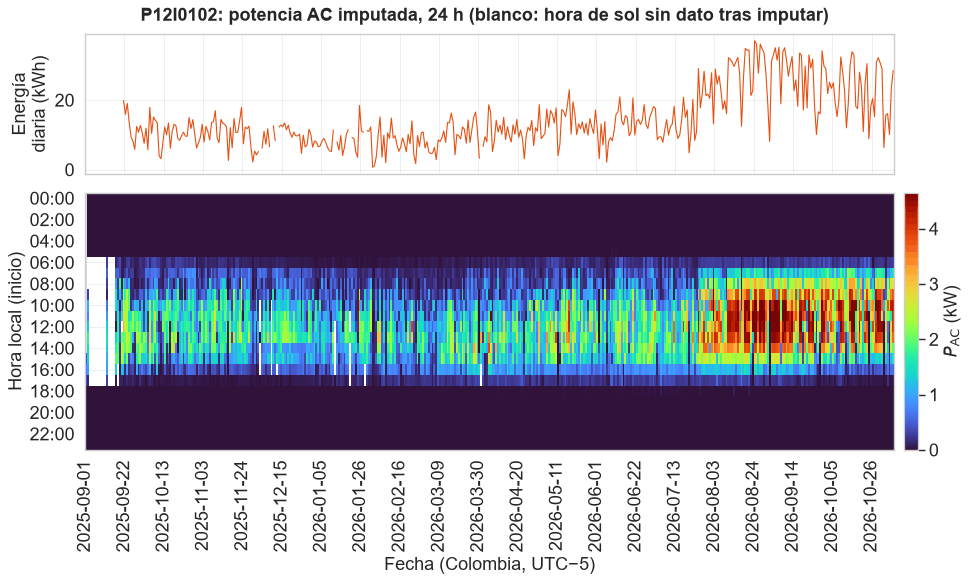

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4276,0.7459,0.4227,0.0134,0.0,0.0,0.0,0.0,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.3086,1.0532,0.7627,1.2832,1.7598,1.5268,1.3664,0.9109,0.1326,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0,0.0


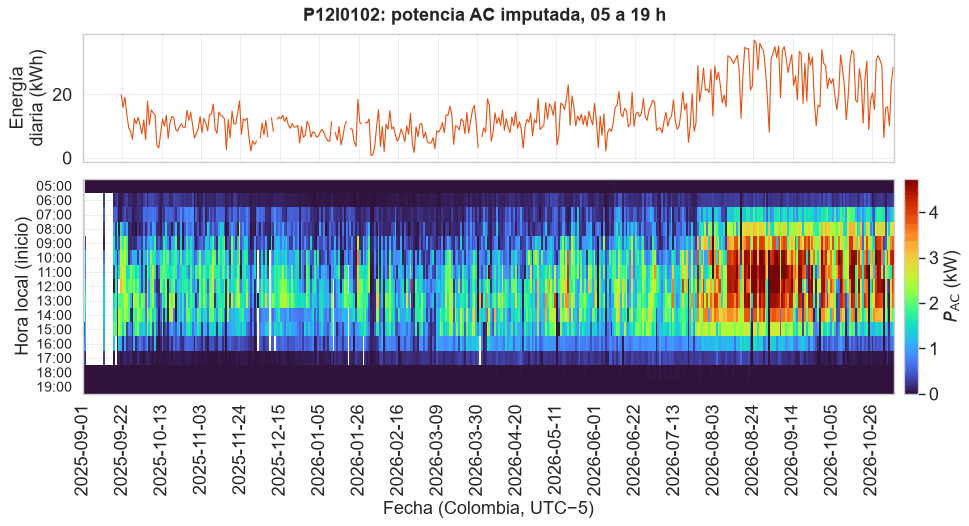

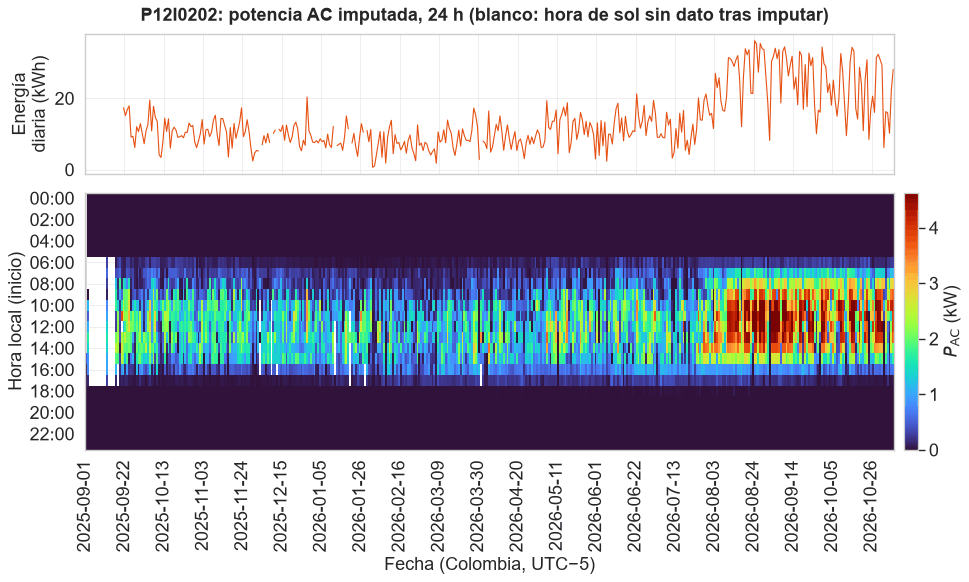

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4380,0.0873,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.1519,0.5026,1.1129,1.6581,1.3963,0.8592,0.7870,0.1348,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0


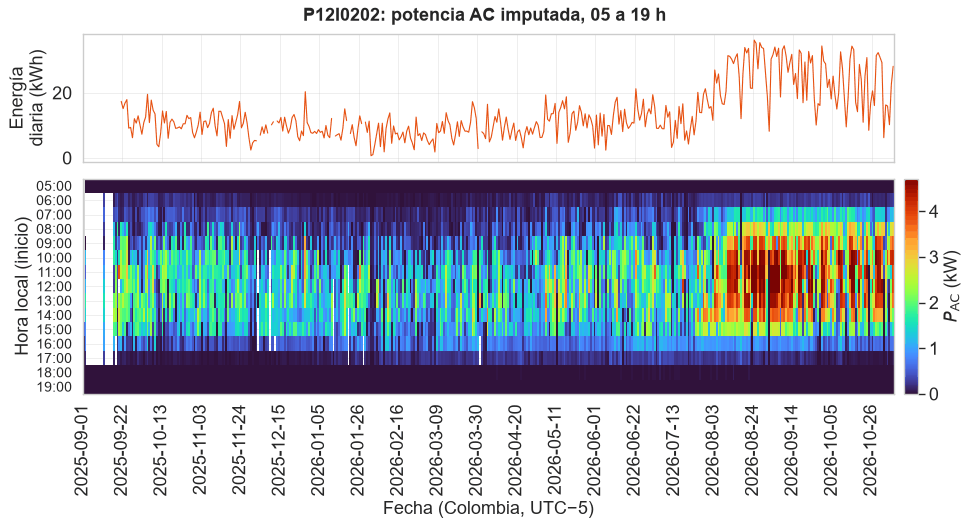

In [21]:
# Sección 3.2. Imputación de la telemetría con la técnica elegida
imputadas, motivos, reportes = {}, {}, []
for n, r in regs.items():
    nat = {c: imp.naturaleza_telemetria(c) for c in r.columns}
    i, m, rep = imp.imputar(r, nat, "5min", dias_sol[n], referencia=ref_poa_cs[n], metodo_diurno=METODO_DIURNO)
    imputadas[n], motivos[n] = i, m
    rep.insert(0, "inversor", n)
    reportes.append(rep)
rep_imp = pd.concat(reportes, ignore_index=True)
display(rep_imp.round(2))
# La misma vista de la sección B con la serie imputada: los huecos de hasta 1 h desaparecen y los más largos
# siguen en blanco, porque no se imputan (decisón C)
for n, i in imputadas.items():
    p = obj.potencia_ac(i) / 1000
    cob_i = car.cobertura_diaria(i["acpower1"], dias_sol[n])
    diaria = (p.groupby((p.index - pd.Timedelta("5min")).tz_convert(config.ZONA).normalize()).sum(min_count=1) / 12).rename("energia_kwh")
    completo = pd.Series(cob_i.to_numpy(), index=pd.to_datetime(cob_i.index)).reindex(diaria.index.tz_localize(None)).to_numpy() >= 0.9
    diaria = diaria.where(completo)
    fig(gr.panel_diario_y_mapa(p, diaria, f"{n}: potencia AC imputada, 24 h (blanco: hora de sol sin dato tras imputar)",
                               "P_AC (kW)", "Energía diaria (kWh)", None, ~dias_sol[n]), f"mapa_pac_imputada_24h_{n}",
        gr.tabla_dia_hora(p, None).T)
    fig(gr.panel_diario_y_mapa(p, diaria, f"{n}: potencia AC imputada, 05 a 19 h", "P_AC (kW)", "Energía diaria (kWh)",
                               (5, 19), ~dias_sol[n]), f"mapa_pac_imputada_{n}")
res.registrar(f"localidades.{GRUPO}.datos.imputacion", {f"{r.inversor}__{r.variable}": {"pct_faltante": r.pct_faltante,
              "pct_interpolado": r.pct_interpolado, "pct_sin_imputar": r.pct_sin_imputar} for r in rep_imp.itertuples()})

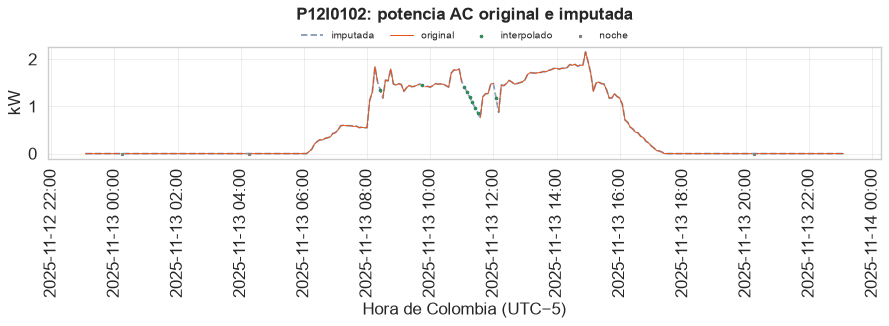

289 filas x 3 columnas; primeras 10:


,original_kw,imputada_kw,motivo
datatime,,,
2025-11-12 23:05:00-05:00,0.0,0.0,
2025-11-12 23:10:00-05:00,0.0,0.0,
2025-11-12 23:15:00-05:00,0.0,0.0,
2025-11-12 23:20:00-05:00,0.0,0.0,
2025-11-12 23:25:00-05:00,0.0,0.0,
2025-11-12 23:30:00-05:00,0.0,0.0,
2025-11-12 23:35:00-05:00,0.0,0.0,
2025-11-12 23:40:00-05:00,0.0,0.0,
2025-11-12 23:45:00-05:00,0.0,0.0,


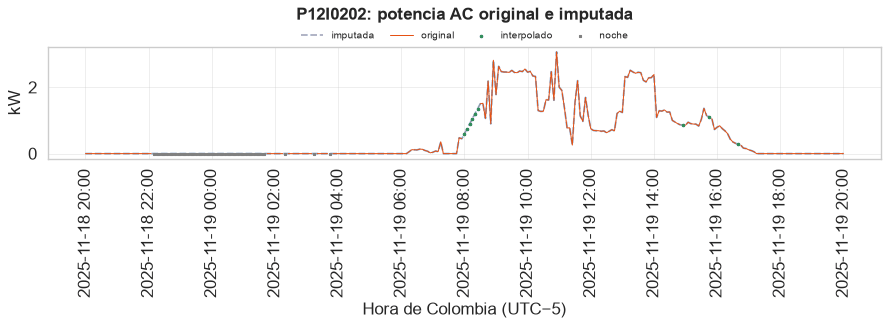

289 filas x 3 columnas; primeras 10:


,original_kw,imputada_kw,motivo
datatime,,,
2025-11-18 20:00:00-05:00,0.0,0.0,
2025-11-18 20:05:00-05:00,0.0,0.0,
2025-11-18 20:10:00-05:00,0.0,0.0,
2025-11-18 20:15:00-05:00,0.0,0.0,
2025-11-18 20:20:00-05:00,0.0,0.0,
2025-11-18 20:25:00-05:00,0.0,0.0,
2025-11-18 20:30:00-05:00,0.0,0.0,
2025-11-18 20:35:00-05:00,0.0,0.0,
2025-11-18 20:40:00-05:00,0.0,0.0,


In [22]:
# Sección 3.2. Imputación de la telemetría con la técnica elegida
# Original frente a imputada en una ventana con huecos cortos diurnos
for n, r in regs.items():
    h = huecos[n].query("diurno and clase == 'corto' and n >= 3")
    if h.empty:
        continue
    c = h.iloc[len(h) // 2]["inicio"]
    p0 = obj.potencia_ac(r) / 1000
    p1 = obj.potencia_ac(imputadas[n]) / 1000
    v = slice(c - pd.Timedelta("12h"), c + pd.Timedelta("12h"))
    fig(gr.original_vs_imputada(p0, p1, motivos[n]["acpower1"], f"{n}: potencia AC original e imputada", "kW", v.start, v.stop),
        f"imputacion_{n}", pd.DataFrame({"original_kw": p0.loc[v], "imputada_kw": p1.loc[v], "motivo": motivos[n]["acpower1"].loc[v]}))

In [23]:
# Sección 3.2. Imputación de la telemetría con la técnica elegida
# Satélite: límites físicos (imposibles -> faltantes) e imputación con la misma técnica (noche = 0)
sat = crudos["om_satellite__eumetsat_lsa_saf_msg"]
COLS_SAT = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance"]
centro = pd.Timedelta("7.5min")                 # medias de 15 min etiquetadas al final
reg_sat = imp.regularizar(sat, "15min", COLS_SAT)
fuera = calidad.limites_irradiancia(reg_sat, lugar, centro)
display(Markdown("Valores del satélite fuera de los límites físicos de la BSRN (pasan a faltantes): " +
                 ", ".join(f"`{c}` {int(v)}" for c, v in fuera.sum().items())))
reg_sat = reg_sat.mask(fuera)
dia_sat = solar.es_de_dia(reg_sat.index, lugar, desplazamiento=centro)
cs_sat = solar.cielo_despejado(reg_sat.index, lugar, desplazamiento=centro)
ref_sat = {"shortwave_radiation": cs_sat["ghi_cs"], "direct_radiation": cs_sat["ghi_cs"],
           "diffuse_radiation": cs_sat["ghi_cs"], "direct_normal_irradiance": cs_sat["dni_cs"]}
imp_sat, mot_sat, rep_sat = imp.imputar(reg_sat, {c: "irradiancia" for c in COLS_SAT}, "15min", dia_sat,
                                        referencia=ref_sat, metodo_diurno=METODO_DIURNO)
display(rep_sat.round(2))
cobertura_diurna_sat = 1 - reg_sat.loc[dia_sat.to_numpy(), "shortwave_radiation"].isna().mean()
display(Markdown(f"Cobertura diurna del satélite en {GRUPO}: **{100 * cobertura_diurna_sat:.1f} %** "
                 f"(al oeste de unos 75,2° O el satélite MSG no tiene datos diurnos)."))
res.registrar(f"localidades.{GRUPO}.datos.satelite", {"cobertura_diurna_pct": 100 * cobertura_diurna_sat,
              "imposibles": fuera.sum().to_dict()})

Valores del satélite fuera de los límites físicos de la BSRN (pasan a faltantes): `shortwave_radiation` 0, `direct_radiation` 0, `diffuse_radiation` 0, `direct_normal_irradiance` 0

,variable,naturaleza,total,faltantes,noche,interpolado,sin_imputar,pct_faltante,pct_interpolado,pct_sin_imputar
0,shortwave_radiation,irradiancia,64820,847,449,54,344,1.31,0.08,0.53
1,direct_radiation,irradiancia,64820,31387,30290,753,344,48.42,1.16,0.53
2,diffuse_radiation,irradiancia,64820,31387,30290,753,344,48.42,1.16,0.53
3,direct_normal_irradiance,irradiancia,64820,31387,30290,753,344,48.42,1.16,0.53


Cobertura diurna del satélite en G05: **98,8 %** (al oeste de unos 75,2° O el satélite MSG no tiene datos diurnos).

## 4. Agregación según la naturaleza de cada variable

Una vez imputadas, agregamos las series a 15, 30 y 60 minutos y a valores diarios con una regla que depende de lo que
mide cada variable. Usamos la **media** para magnitudes instantáneas o medias de periodo (potencia, irradiancia y
temperatura), y la media del intervalo multiplicada por su duración da la energía (kWh) o la irradiación (kWh/m²).
Usamos la **suma** para acumulados por periodo (precipitación), el **máximo** para las rachas y el **último valor** para
contadores y estados, de modo que la energía del periodo sale de la diferencia entre el último valor de un intervalo y el
del anterior.

Etiquetamos cada valor al final del periodo, así que el valor de las 10:00 resume el intervalo (09:00, 10:00]. Es la
convención de la radiación de Open-Meteo, y mezclarla con etiquetas al inicio desplazaría una hora la radiación frente a
la producción, por lo que las fuentes que etiquetan el inicio (NASA POWER) se desplazan. Un valor agregado solo se
acepta si el intervalo tiene al menos el 80 % de sus muestras, y si no, queda sin valor.

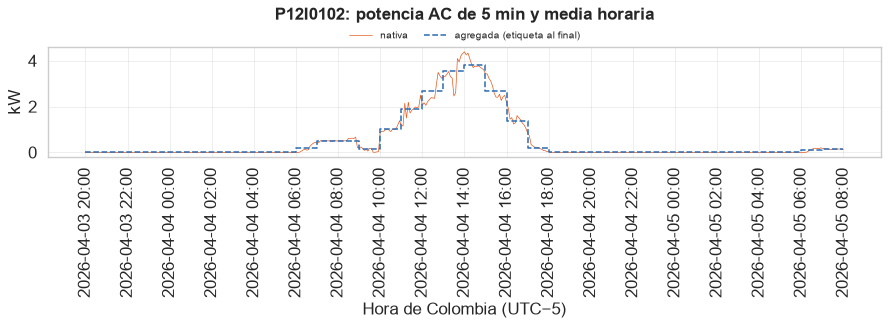

433 filas x 2 columnas; primeras 10:


,p_ac_5min_kw,p_ac_horaria_kw
datatime,,
2026-04-03 20:00:00-05:00,0.0,0.0
2026-04-03 20:05:00-05:00,0.0,NaN
2026-04-03 20:10:00-05:00,0.0,NaN
2026-04-03 20:15:00-05:00,0.0,NaN
2026-04-03 20:20:00-05:00,0.0,NaN
2026-04-03 20:25:00-05:00,0.0,NaN
2026-04-03 20:30:00-05:00,0.0,NaN
2026-04-03 20:35:00-05:00,0.0,NaN
2026-04-03 20:40:00-05:00,0.0,NaN


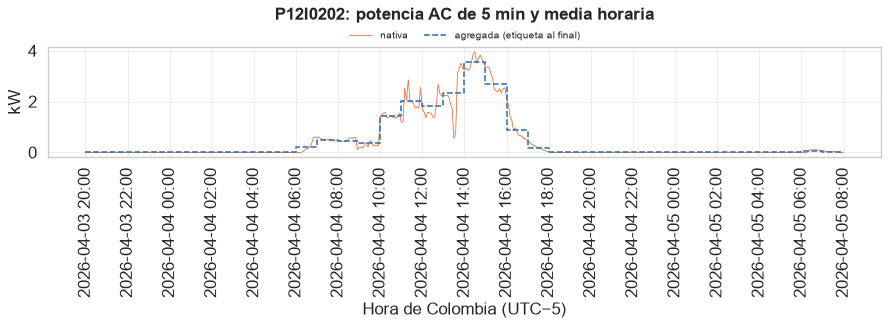

433 filas x 2 columnas; primeras 10:


,p_ac_5min_kw,p_ac_horaria_kw
datatime,,
2026-04-03 20:00:00-05:00,0.0,0.0
2026-04-03 20:05:00-05:00,0.0,NaN
2026-04-03 20:10:00-05:00,0.0,NaN
2026-04-03 20:15:00-05:00,0.0,NaN
2026-04-03 20:20:00-05:00,0.0,NaN
2026-04-03 20:25:00-05:00,0.0,NaN
2026-04-03 20:30:00-05:00,0.0,NaN
2026-04-03 20:35:00-05:00,0.0,NaN
2026-04-03 20:40:00-05:00,0.0,NaN


55762

In [24]:
# Sección 4. Agregación según la naturaleza de cada variable
horarios, calidad_h = {}, {}
PDC5 = {}                    # potencia DC de 5 min con el inversor en estado normal (auditoría de la potencia pico, 5.2)
for n, i in imputadas.items():
    est_ = i.get("devicestatus")
    base = pd.DataFrame({"p_ac": obj.potencia_ac(i), "totalyield": i.get("totalyield"),
                         "invertertemperature": i.get("invertertemperature"),
                         "falla": est_.round().isin([103, 104]).astype(float).where(est_.notna()) if est_ is not None else np.nan})
    base["p_ac_max"] = base["p_ac"]
    base["p_dc"] = i.get("mppttotalinputpower")
    if base["p_dc"].notna().any():
        PDC5[n] = (base["p_dc"] if est_ is None else base["p_dc"].where(est_.round() == 102)).astype("float32")
    msk = pd.DataFrame({"p_ac": motivos[n]["acpower1"] == "interpolado"})
    reglas = {"p_ac": "media", "totalyield": "ultimo", "invertertemperature": "media", "falla": "media",
              "p_ac_max": "maximo", "p_dc": "media"}
    horarios[n], calidad_h[n] = agg.agregar(base, reglas, "1h", "5min", imputado=msk)
    d = horarios[n].index[len(horarios[n]) // 2]
    v = slice(d - pd.Timedelta("36h"), d)
    fig(gr.antes_despues_agregacion(base["p_ac"] / 1000, horarios[n]["p_ac"] / 1000, f"{n}: potencia AC de 5 min y media horaria",
                                    "kW", v.start, v.stop), f"agregacion_{n}",
        pd.concat({"p_ac_5min_kw": base["p_ac"].loc[v] / 1000, "p_ac_horaria_kw": horarios[n]["p_ac"].loc[v] / 1000}, axis=1))
# Medias horarias de todas las variables numéricas de la telemetría (con la hora corregida, sin imputar):
# solo para la correlación de todas contra todas de la sección 6
TEL_H = {}
for n, d in tel.items():
    num = [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c]) and c not in ("desfase_h", "devicestatus")]
    TEL_H[n] = d.set_index("datatime")[num].resample("1h", label="right", closed="right").mean()
    TEL_H[n] = TEL_H[n].loc[:, TEL_H[n].notna().sum() > 24 * 30]
# Desde aquí el análisis es horario y diario: se libera la telemetría de 5 min (cruda, corregida e imputada)
for n in list(tel):
    crudos.pop(n, None)
del tel, imputadas, motivos, base
gc.collect()

## 5. Variables objetivo: rendimiento específico (Yf) e índice de rendimiento (PR)

Según la norma IEC 61724-1 (UNE-EN IEC 61724-1, "Rendimiento del sistema fotovoltaico"), el **rendimiento** de una
instalación se cuantifica con dos magnitudes, y ambas son el objeto de predicción de este TFM. El **rendimiento
específico** o productividad final, $Y_f = E_{AC} / P_0$, en kWh/kWp, es la energía entregada por cada kWp instalado, y
el **índice de rendimiento** (*Performance Ratio*), $PR = Y_f / Y_r$, es adimensional, donde $Y_r = H_{POA} / G_{ref}$
es la irradiación en el plano de los módulos dividida por 1 kW/m².

Calculamos la energía horaria integrando la potencia AC (media horaria por una hora) y la contrastamos con la diferencia
del contador `totalyield`. La irradiancia en el plano (POA) la obtenemos con pvlib (modelo de Perez) a partir de GHI, DNI
y DHI de la fuente elegida en 5.1, con la inclinación y el azimut del inversor. El PR horario solo se calcula con
G_POA ≥ 200 W/m², y el diario como cociente de sumas y solo en días con al menos el 90 % de sus horas de sol completas
(con energía e irradiancia). Sin piranómetro en el plano de los módulos, este PR es un **PR estimado** con irradiancia
satelital transpuesta y no un PR conforme a las clases A o B de la IEC 61724-1:2021.

Modelamos cada inversor en su régimen vigente (2.4), porque antes la potencia máxima alcanzable era otra (ampliación,
limitación o falla prolongada) y el Yf calculado con el kWp actual no es comparable. Esos días se conservan en las
figuras, sombreados, pero no entran en el modelado ni en los estadísticos. Cada hora guarda además la fracción de su
potencia que fue imputada y la fracción del tiempo con el inversor en falla. Las horas en falla no tienen rendimiento
observado (2.7), y las métricas de los modelos se calculan solo en horas observadas (como máximo una lectura de cinco
minutos imputada) y sin falla.

### 5.1. Experimento: ¿qué fuente de irradiancia explica mejor la producción?

Sin piranómetro, Yr y el PR dependen de la fuente de irradiancia. En 2.8 vimos que las fuentes difieren entre sí en su
nivel medio y hora a hora, pero ese contraste no dice cuál es la correcta. Aquí los propios inversores actúan como
sensores, porque la fuente que mejor explica la energía medida es la que mejor sigue la irradiancia real del sitio.

Para cada inversor tomamos el Yf horario observado (como máximo una lectura de cinco minutos imputada), dentro del
régimen vigente, sin falla ni recorte y con el sol sobre el horizonte, y para cada fuente calculamos el Yr horario a
partir de la POA con la inclinación y el azimut del inversor. Ajustamos el modelo físico mínimo, Yf = PR_f · Yr, con un
único parámetro PR_f por mínimos cuadrados. PR_f absorbe el sesgo de la fuente, así que la comparación mide si la
fuente sigue la variabilidad y no su nivel, y su valor muestra además cuánto cambiaría el PR según la fuente. Hacemos
dos comparaciones con la misma muestra para todas las fuentes. La comparación A (2025, con NSRDB) ajusta de mayo a
septiembre de 2025 y evalúa de octubre a diciembre de 2025, porque NSRDB termina en 2025. La comparación B (periodo del
TFM) ajusta con el entrenamiento, evalúa en la validación e incluye los pronósticos archivados a un día (escenario E2)
para medir cuánto se pierde al pasar de la irradiancia observada a la pronosticada. Las métricas son el nRMSE y el nMAE
horarios, el R², el nRMSE diario y la correlación diaria, y la prueba (septiembre y octubre) no se toca.

Esperamos que el satélite gane en escala horaria porque observa las nubes reales, mientras que el análisis IFS las
modela. Pero el Caribe colombiano está en el borde del disco que ve MSG (desde 0° de longitud, con un ángulo de visión
muy oblicuo), mientras que GOES-Este (NSRDB) lo ve casi desde el cenit, así que NSRDB podría superar a MSG.

El ajuste de PR_f absorbe el nivel de cada fuente, así que el experimento mide la variabilidad, pero el PR que se
informa sí depende del nivel. Por eso, antes de compararlas, llevamos cada fuente observada al nivel de NSRDB (satélite
GOES, la fuente mejor validada en América y la que mejor explica la producción de 2025) con un factor de escala
estimado en los días de 2025 con datos completos de ambas (`tfm/auditoria_fv.py`), y mostramos como control el factor
por temporada y el cociente con el cielo despejado en los días más despejados. Los pronósticos no se calibran, porque
en E2-MOS el modelo aprende su sesgo y en E2-PP la definición exige aplicarlos tal como llegan.

Son elegibles las fuentes observadas que cubren todo el periodo de modelado y publican con 3 días de retraso o menos
(2.9), algo necesario para medir el rendimiento en operación, es decir, el satélite MSG y el análisis IFS. ERA5 (unos 6
días de retraso) queda para la climatología, NSRDB termina en 2025 y NASA POWER publica con meses de retraso. Entre las
elegibles elegimos la de menor nRMSE horario medio en la comparación B, y si la diferencia con la segunda es menor de
0,5 puntos o no es significativa (Diebold-Mariano, p ≥ 0,05) en la mayoría de los inversores, preferimos la que
necesita menos corrección de nivel (factor más cercano a 1).

In [25]:
# Sección 5.1. Experimento: ¿qué fuente de irradiancia explica mejor la producción?
FUENTES = {k: caract.irradiancia_fuente(crudos, k, lugar, metodo_diurno=METODO_DIURNO) for k in caract.FUENTES_IRRADIANCIA}
FUENTES = {k: v for k, v in FUENTES.items() if v is not None}
# Nivel: cada fuente observada se lleva al de NSRDB con un factor de escala de 2025; los pronósticos no se tocan
NIVEL = aud.factores_nivel(FUENTES, lugar)
CALIBRADAS = [k for k in FUENTES if k in aud.OBSERVADAS and k in NIVEL.index]
FUENTES = {k: aud.calibrar(v, NIVEL.loc[k, "factor"]) if k in CALIBRADAS else v for k, v in FUENTES.items()}
display(Markdown("**Nivel de cada fuente frente a NSRDB (días de 2025 con datos completos).** `factor` = irradiación de "
                 "NSRDB / irradiación de la fuente; `cociente_cielo_despejado`: irradiación de la fuente, sin calibrar, "
                 "dividida por la de cielo despejado en el 10 % de días más despejados."))
display(NIVEL.round(3))
if not NIVEL.empty:
    display(Markdown(
        f"**Observación.** Sin calibrar, el nivel de las fuentes va de un {100 * (1 / NIVEL['factor'].max() - 1):+.0f} % a un "
        f"{100 * (1 / NIVEL['factor'].min() - 1):+.0f} % respecto de NSRDB. "
        + (f"El satélite MSG da un {100 * (1 / NIVEL.loc['satelite_msg', 'factor'] - 1):.0f} % más de irradiancia que NSRDB y, en "
           f"los días despejados, un {100 * (NIVEL.loc['satelite_msg', 'cociente_cielo_despejado'] - 1):.0f} % más que el cielo despejado, "
           "lo que apunta a un sesgo del satélite, que ve la región con un ángulo muy oblicuo. " if "satelite_msg" in NIVEL.index else "")
        + "Desde aquí, las fuentes observadas (" + ", ".join(CALIBRADAS) + ") quedan al nivel de NSRDB; el PR que se informa "
        "es comparable entre localidades y no depende de la fuente elegida."))
res.registrar(f"localidades.{GRUPO}.datos.nivel_fuentes", NIVEL.round(4).replace({np.nan: None}).to_dict(orient="index"))
ultimo = pd.Series({k: v["ghi"].last_valid_index() for k, v in FUENTES.items()}, name="ultimo_dato_utc")
fin_prueba = pd.Timestamp(config.PARTICIONES["prueba"][1], tz=config.ZONA)
SERIE_DE = {k: caract.FUENTES_IRRADIANCIA[k][0] for k in FUENTES}
APTA = {k: bool(FICHA.loc[SERIE_DE[k], "apta_produccion"]) if SERIE_DE[k] in FICHA.index else False for k in FUENTES}
ELEGIBLES = [k for k in ("satelite_msg", "ifs_analisis", "era5") if k in FUENTES and ultimo[k] >= fin_prueba and APTA[k]]
MOTIVO = {"nsrdb_goes": "termina en 2025: no cubre la validación, la prueba ni el periodo en vivo",
          "nasa_power": f"publica la radiación horaria con unos {retraso_de('nasa_power')} días de retraso: no sirve para operar",
          "era5": f"publica con unos {retraso_de('om_archive__era5')} días de retraso (más de 3): queda para la climatología",
          "ifs025_pronostico_d1": "es un pronóstico: se usa en el escenario E2, no para medir el rendimiento observado",
          "gfs_pronostico_d1": "es un pronóstico: se usa en el escenario E2, no para medir el rendimiento observado"}
ELEGIBILIDAD = pd.DataFrame({"ultimo_dato_utc": ultimo, "elegible": [k in ELEGIBLES for k in ultimo.index],
                             "motivo": [("observada, al día y con datos hasta el fin de la prueba" if k in ELEGIBLES else
                                         MOTIVO.get(k, "sin datos hasta el fin de la prueba")) for k in ultimo.index]})
display(ELEGIBILIDAD)

**Nivel de cada fuente frente a NSRDB (días de 2025 con datos completos).** `factor` = irradiación de NSRDB / irradiación de la fuente; `cociente_cielo_despejado`: irradiación de la fuente, sin calibrar, dividida por la de cielo despejado en el 10 % de días más despejados.

,factor,dias,factor_seca,factor_resto,cociente_cielo_despejado
fuente,,,,,
satelite_msg,0.972,362.0,1.003,0.957,1.050
ifs_analisis,1.020,364.0,1.030,1.015,0.988
era5,1.009,364.0,1.043,0.992,0.982
nsrdb_goes,1.000,364.0,1.000,1.000,1.054
nasa_power,1.008,364.0,1.039,0.992,0.993
ifs025_pronostico_d1,1.063,364.0,1.058,1.066,0.963
gfs_pronostico_d1,1.074,364.0,1.047,1.090,0.963


**Observación.** Sin calibrar, el nivel de las fuentes va de un -7 % a un +3 % respecto de NSRDB. El satélite MSG da un 3 % más de irradiancia que NSRDB y, en los días despejados, un 5 % más que el cielo despejado, lo que apunta a un sesgo del satélite, que ve la región con un ángulo muy oblicuo. Desde aquí, las fuentes observadas (satelite_msg, ifs_analisis, era5, nasa_power) quedan al nivel de NSRDB; el PR que se informa es comparable entre localidades y no depende de la fuente elegida.

,ultimo_dato_utc,elegible,motivo
satelite_msg,2026-11-07 04:00:00+00:00,True,"observada, al día y con datos hasta el fin de ..."
ifs_analisis,2026-11-07 04:00:00+00:00,True,"observada, al día y con datos hasta el fin de ..."
era5,2026-11-01 23:00:00+00:00,False,publica con unos 5 días de retraso (más de 3):...
nsrdb_goes,2026-01-01 00:00:00+00:00,False,"termina en 2025: no cubre la validación, la pr..."
nasa_power,2026-11-06 00:00:00+00:00,False,publica la radiación horaria con unos 67 días ...
ifs025_pronostico_d1,2026-11-07 23:00:00+00:00,False,"es un pronóstico: se usa en el escenario E2, n..."
gfs_pronostico_d1,2026-11-07 23:00:00+00:00,False,"es un pronóstico: se usa en el escenario E2, n..."


### 5.2. Auditoría de la potencia pico

El rendimiento específico divide la energía por la potencia pico P0 de cada inversor, y el PR se calcula con ella. El
P0 es el que informó el instalador (los paneles conectados a cada inversor por la potencia del módulo), y antes de
calcular los objetivos lo contrastamos con la telemetría (`tfm/auditoria_fv.py`).

Hacemos dos pruebas. La primera es una **prueba física** que no depende de ninguna fuente meteorológica, según la cual
el percentil 99 de la potencia DC de 5 minutos, con el inversor en funcionamiento normal y dentro del régimen estable,
no puede superar al P0, y por encima de 1,05 × P0 el valor sería imposible. La segunda es una **identificación** en
horas despejadas y sin recorte (de 9 a 15 h, índice de claridad de al menos 0,80 con la fuente calibrada, irradiancia en
el plano de al menos 600 W/m², potencia AC máxima de la hora por debajo del 95 % de la nominal y sin falla), con
kWp = P_DC / (G_POA / 1000 × (1 + γ (T_celda − 25)) × η_DC) y T_celda = T_aire + G_POA / 800 × (NOCT − 20), donde γ y el
NOCT salen de la ficha técnica del módulo y η_DC = 0,97. Las horas despejadas se detectan con el satélite si cubre el
día, y si no con el análisis IFS, que ve peor las nubes locales.

La regla se fijó antes de calcular. Como la configuración la informó el instalador, conservamos siempre su P0 y la
identificación funciona como control. Una prueba física fallida o un cociente r = identificado / instalador mayor que
1,15 señalan un dato por revisar, y con r < 0,70 la unidad se clasifica como de capacidad efectiva limitada (limitación
de inyección, cadenas desconectadas o una pérdida del generador) solo si la prueba física coincide, y si no, la
identificación se marca como no concluyente. Usar siempre el identificado haría depender el P0 del nivel de la fuente y
de la detección de cielo despejado, y corregir el valor en su origen violaría la regla de guardar solo datos crudos.

In [26]:
# Sección 5.2. Auditoría de la potencia pico
t_aire_h = caract.meteo_horaria(crudos["om_archive__ecmwf_ifs"], {"temperature_2m": "media"}, lugar)["temperature_2m"]
DETECCION = ("satelite_msg" if "satelite_msg" in FUENTES and FUENTES["satelite_msg"]["ghi"].notna().mean() > 0.9
             else "ifs_analisis")
irr_det = FUENTES[DETECCION]
cs_det = solar.cielo_despejado(irr_det.index, lugar, pd.Timedelta("30min"))["ghi_cs"]
# Plantas sin sensor de red: la regla de tensión marca las horas recortadas en las horas despejadas (claridad =
# GHI / GHI de cielo despejado de la fuente de detección), con los parámetros calibrados en E28 y solo de 9 a 15 h
# (recorte.HORAS_TENSION), donde es fiable: antes y después, el módulo frío y el sol bajo dan la misma firma sin recorte
clar_det = (irr_det["ghi"] / cs_det).where(cs_det > 50)
for n, m in REC.items():
    if m.attrs["sensor"] is None and "v_rel" in m:
        REC[n]["recortada"] = recorte.regla_tension(m["v_rel"], m["p_rel"], clar_det, **recorte.PARAMETROS_TENSION).reindex(m.index).fillna(False).astype(bool)
        # Con la conformidad del operador de red y sin límite declarado por el instalador, las marcas posteriores no son limitación
        REC[n]["recortada"] = recorte.sin_marcas_tras_conformidad(REC[n]["recortada"], INSTALADOR[INV.loc[n, "planta"]], None)
        display(Markdown(f"**{n}** (sin sensor de red): {int(REC[n].loc[REC[n].index < CORTE_MODELADO, 'recortada'].sum())} horas "
                         "marcadas como recortadas por la regla de tensión antes del corte (solo se aplica de 9 a 15 h)."))

def periodo_unidad(n):
    # Periodo de modelado. Régimen A: último régimen de capacidad estable. Régimen B: si la planta limitó la inyección,
    # los regímenes de capacidad se buscan solo después del fin de la limitación (la limitación ya no los parte) y el
    # periodo empieza el primer día posterior al último día limitado con su propia fracción en cero menor que 0,25
    # (recorte.regimen_vigente, E42); si la planta sigue limitada al corte, no hay periodo.
    # En los dos, una ampliación registrada (INICIO_ETAPA) no deja entrar días de la etapa anterior.
    if n not in reg_cap:
        return None
    if not APLICAR_RECORTE:
        return calidad.con_etapa(calidad.ultimo_regimen_estable(reg_cap[n]), INICIO_ETAPA.get(n))
    reg = REG_PLANTA[INV.loc[n, "planta"]]
    if reg.get("estado") == "limitada al corte":
        return None
    if reg.get("inicio_b") is None:
        # Sin limitación: último régimen de capacidad, después de la última reparación declarada
        periodo = calidad.con_etapa(calidad.ultimo_regimen_estable(reg_cap[n]), reg.get("fin_reparacion"))
        return calidad.con_etapa(periodo, INICIO_ETAPA.get(n))
    periodo = calidad.ultimo_regimen_estable(REG_CAP_B[n]) if n in REG_CAP_B else None
    return calidad.con_etapa(recorte.periodo_b(periodo, reg), INICIO_ETAPA.get(n)) if periodo is not None else None

def sin_recorte(n, indice):
    # True en las horas que no están recortadas (en el régimen A no se excluye ninguna)
    if not APLICAR_RECORTE or n not in REC:
        return np.ones(len(indice), dtype=bool)
    return ~REC[n]["recortada"].reindex(indice).fillna(False).astype(bool).to_numpy()

filas_p0 = []
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in horarios or pd.isna(inv.kwpdc) or n not in reg_cap:
        continue
    periodo_n = periodo_unidad(n)
    h = horarios[n]
    if "p_dc" not in h or h["p_dc"].notna().sum() == 0:
        filas_p0.append({"inversor": n, "kwp_declarado": float(inv.kwpdc), "kwp_analisis": float(inv.kwpdc),
                         "decision": "declarado: el inversor no informa la potencia DC"})
        continue
    g_poa_det, _ = obj.poa_inversor(irr_det["ghi"], irr_det["dni"], irr_det["dhi"], lugar, inv.inclinacion, inv.azimut,
                                    caras=obj.caras_de(inv))
    pdc5 = PDC5.get(n)
    if pdc5 is not None:
        # Las lecturas de 5 min de una hora recortada tampoco cuentan para la prueba física
        hora5 = (pdc5.index - pd.Timedelta(seconds=1)).floor("h") + pd.Timedelta(hours=1)
        pdc5 = pdc5.where(calidad.mascara_regimen(pdc5.index, periodo_n) & sin_recorte(n, hora5) & (pdc5.index < CORTE_MODELADO))
    en_auditoria = calidad.mascara_regimen(h.index, periodo_n) & sin_recorte(n, h.index) & np.asarray(h.index < CORTE_MODELADO)
    a = aud.capacidad(h["p_dc"], h["p_ac_max"], h["falla"], g_poa_det, irr_det["ghi"], cs_det, t_aire_h,
                      en_auditoria, pdc5, inv.ratedpower, inv.kwpdc, gamma_pct=inv.get("gamma_pmax_pct_c"),
                      noct=inv.get("noct_c"), origen=inv.get("origen"))
    filas_p0.append({"inversor": n, **a})
P0 = (pd.DataFrame(filas_p0) if filas_p0 else pd.DataFrame(columns=["inversor", "kwp_declarado", "kwp_analisis", "decision"])).set_index("inversor")
display(Markdown(f"**Auditoría de la potencia pico** (horas despejadas detectadas con {DETECCION})"))
display(P0.round(3))
INVERSORES["kwpdc_declarado"] = INVERSORES["kwpdc"]
INVERSORES["kwpdc"] = [float(P0.loc[c, "kwp_analisis"]) if c in P0.index else k for c, k in zip(INVERSORES.codigo, INVERSORES.kwpdc)]
INV = INVERSORES.set_index("codigo", drop=False)
cambiados = P0[P0["decision"].str.startswith("identificado")]
limitadas = P0[P0["decision"].str.contains("limitada")]
dudosas = P0[P0["decision"].str.contains("no concluyente")]
revisar = P0[P0["decision"].str.startswith("instalador") & P0["decision"].str.contains("imposible|subestimado")]
if len(revisar):
    display(Markdown(
        "**Dato por revisar.** " + "; ".join(f"{c} entrega hasta {r.p99_dc_kw:.1f} kW de DC con {r.kwp_declarado:.2f} kWp declarados "
                                              f"(identificado: {r.kwp_identificado:.1f} kWp)" for c, r in revisar.iterrows())
        + ". Se conserva el kWp que confirmó el instalador; la diferencia indica un dato de configuración por revisar."))
display(Markdown(
    f"**Observación.** " + (f"El P0 declarado no es coherente con la telemetría en {', '.join(cambiados.index)}: "
    + "; ".join(f"{c} entrega hasta {r.p99_dc_kw:.1f} kW de DC con {r.kwp_declarado:.2f} kWp declarados y su kWp identificado es "
                f"{r.kwp_identificado:.1f}" for c, r in cambiados.iterrows())
    + ". El análisis usa el valor que fija la regla. " if len(cambiados) else ("" if len(revisar) else "Ningún P0 declarado es físicamente imposible. "))
    + (f"Con capacidad efectiva limitada: {', '.join(limitadas.index)} (sus picos de potencia no pasan del 70 % del P0); "
       "su rendimiento depende de algo más que el tiempo meteorológico. " if len(limitadas) else "")
    + (f"La identificación no es concluyente en {', '.join(dudosas.index)}: el kWp identificado queda por debajo del 70 % "
       "del declarado, pero el percentil 99 de la potencia DC no lo confirma, y se conserva el declarado. " if len(dudosas) else "")
    + ("" if len(cambiados) + len(limitadas) + len(dudosas) == len(P0) else
       "Las demás unidades conservan el P0 declarado." if len(cambiados) + len(limitadas) + len(dudosas) else
       f"En las {len(P0)} unidades el kWp identificado queda dentro de la regla (r de {P0['r'].min():.2f} a {P0['r'].max():.2f}), "
       "así que se conserva el declarado.")))
res.registrar(f"localidades.{GRUPO}.datos.auditoria_p0", P0.round(4).replace({np.nan: None}).to_dict(orient="index"))

**Auditoría de la potencia pico** (horas despejadas detectadas con satelite_msg)

,kwp_declarado,nominal_kw,p99_dc_kw,p99_dc_sobre_kwp,gamma,noct,horas_despejadas,dias_despejados,kwp_identificado,ic95_inf,ic95_sup,r,kwp_analisis,decision
inversor,,,,,,,,,,,,,,
P12I0102,6.150,5.0,4.999,0.813,-0.003,45.0,194,84,5.229,4.993,5.410,0.850,6.150,instalador; telemetria: coherente con la telem...
P12I0202,6.150,5.0,4.998,0.813,-0.003,45.0,185,83,4.983,4.478,5.336,0.810,6.150,instalador; telemetria: coherente con la telem...
P13I0101,12.300,10.0,9.919,0.806,-0.003,45.0,615,155,9.294,8.965,9.690,0.756,12.300,instalador; telemetria: coherente con la telem...
P17I0101,14.375,10.0,10.330,0.719,-0.003,43.0,28,16,NaN,NaN,NaN,NaN,14.375,instalador; telemetria: sin horas despejadas s...


**Observación.** Ningún P0 declarado es físicamente imposible. En las 4 unidades el kWp identificado queda dentro de la regla (r de 0,76 a 0,85), así que se conserva el declarado.

**Comparación A (2025, con NSRDB), media de los inversores**

""


**Comparación B (entrenamiento → validación), media de los inversores**

,pr_ajustado,nrmse_h_pct,nmae_h_pct,r2_h,nrmse_d_pct,r_d,horas_evaluacion,dias_evaluacion
fuente,,,,,,,,
nasa_power,0.779,27.025,19.208,0.749,14.763,0.741,715.00,57.0
ifs_analisis,0.692,32.901,23.780,0.720,15.564,0.781,411.75,32.5
ifs025_pronostico_d1,0.735,36.404,26.754,0.661,18.976,0.662,411.75,32.5
era5,0.696,37.277,26.621,0.644,16.634,0.776,411.75,32.5
satelite_msg,0.733,37.285,26.451,0.637,20.470,0.666,411.75,32.5
gfs_pronostico_d1,0.751,46.109,32.926,0.456,24.485,0.487,411.75,32.5


Detalle por inversor (comparación B):

,fuente,muestra,disponibilidad_eval,horas_ajuste,horas_evaluacion,pr_ajustado,nrmse_h_pct,nmae_h_pct,r2_h,dias_evaluacion,nrmse_d_pct,r_d,inversor
0,ifs_analisis,comun,1.000,662,420,0.709,40.734,29.916,0.645,33,19.812,0.714,P12I0102
1,satelite_msg,comun,0.986,662,420,0.787,43.431,29.768,0.597,33,25.879,0.739,P12I0102
2,ifs025_pronostico_d1,comun,1.000,662,420,0.761,44.541,33.211,0.576,33,22.863,0.596,P12I0102
3,era5,comun,1.000,662,420,0.728,46.053,33.126,0.546,33,20.775,0.737,P12I0102
4,gfs_pronostico_d1,comun,1.000,662,420,0.789,55.920,41.126,0.331,33,28.978,0.469,P12I0102
0,ifs_analisis,comun,1.000,658,415,0.687,40.934,29.694,0.650,33,21.135,0.711,P12I0202
1,satelite_msg,comun,0.986,658,415,0.767,42.794,28.748,0.618,33,25.362,0.740,P12I0202
2,ifs025_pronostico_d1,comun,1.000,658,415,0.738,44.726,33.437,0.582,33,24.124,0.593,P12I0202
3,era5,comun,1.000,658,415,0.706,45.651,32.624,0.565,33,21.250,0.735,P12I0202
4,gfs_pronostico_d1,comun,1.000,658,415,0.767,55.396,39.852,0.359,33,30.256,0.456,P12I0202


**Prueba de Diebold-Mariano (corrección HLN) entre las dos mejores fuentes elegibles, por inversor.** Estadístico negativo: la fuente 1 es más precisa; p < 0,05: la diferencia es significativa.

,inversor,fuente_1,fuente_2,n,dm,p_valor,diferencia_media
0,P12I0102,ifs_analisis,satelite_msg,914,-1.2975,0.1948,-0.0012
1,P12I0202,ifs_analisis,satelite_msg,911,-0.8851,0.3763,-0.0008
2,P13I0101,ifs_analisis,satelite_msg,1458,-4.6667,0.0000,-0.0037
3,P17I0101,ifs_analisis,satelite_msg,223,-1.5808,0.1153,-0.0012


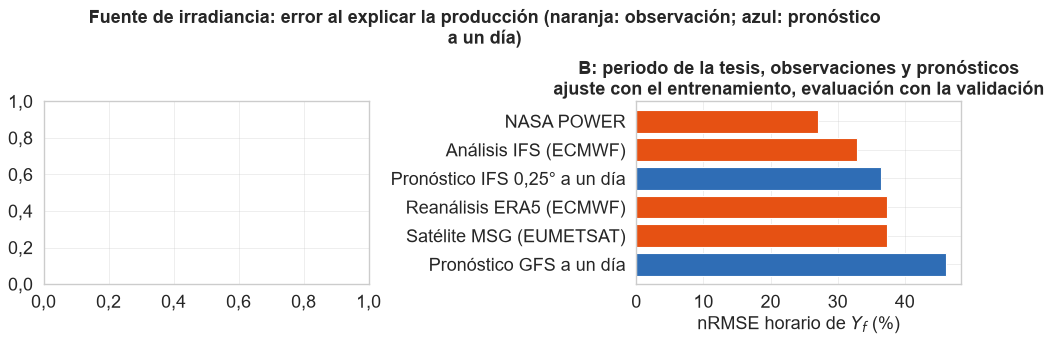

6 filas x 2 columnas; primeras 6:


,A_nrmse_h_pct,B_nrmse_h_pct
nasa_power,NaN,27.0253
ifs_analisis,NaN,32.9009
ifs025_pronostico_d1,NaN,36.4038
era5,NaN,37.2770
satelite_msg,NaN,37.2853
gfs_pronostico_d1,NaN,46.1089


**Observaciones.** (1) En la comparación B, las fuentes observadas explican el Yf horario con un nRMSE de 27,0 % (nasa_power) a 37,3 % (satelite_msg); los pronósticos a un día, de 36,4 % a 46,1 %. Pasar de la mejor irradiancia observada al mejor pronóstico cuesta 9,4 puntos de nRMSE: es el límite inferior del error de cualquier modelo del escenario E2 que dependa de la irradiancia pronosticada. (3) Con las fuentes observadas llevadas al nivel de NSRDB, su PR ajustado queda entre 0,69 y 0,78; los pronósticos, que no se calibran, entre 0,74 y 0,75. Sin esa calibración el PR cambiaría con la fuente elegida (2,8) y no sería comparable entre localidades.

**Decisión.** Yr y el PR se calculan con **ifs_analisis** (al nivel de NSRDB). Aunque nasa_power tiene un error menor, no es elegible (publica la radiación horaria con unos 67 días de retraso: no sirve para operar). La prueba de Diebold-Mariano indica que la diferencia entre las dos mejores fuentes elegibles es significativa (p < 0,05) en 1 de 4 inversores. Con una diferencia menor de 0,5 puntos o no significativa en la mayoría de los inversores, las dos fuentes son equivalentes para explicar la producción, y se elige la que necesita menos corrección de nivel. **Discusión.** La comparación rápida que se hizo antes de corregir la zona horaria de SolaX daba una correlación diaria de 0,31 con el análisis IFS; con la hora corregida y el experimento completo, las fuentes observadas quedan mucho más cerca entre sí. Aquella cifra era un artefacto del desfase de 13 horas.

**En producción.** La fuente observada elegida solo define con qué irradiancia se mide el rendimiento observado (Yr y PR) y las entradas del escenario E1, que es el límite superior con tiempo perfecto. El pronóstico del día siguiente usa el pronóstico meteorológico (escenario E2, IFS 0,25° emitido el día anterior), que siempre está disponible antes del día pronosticado; en la variante E2-MOS el modelo aprende directamente del pronóstico al rendimiento, así que la fuente observada no interviene en la predicción.

In [27]:
# Sección 5.2. Auditoría de la potencia pico
PERIODO = {}
filas_A, filas_B, filas_dm = [], [], []
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in horarios or pd.isna(inv.kwpdc) or inv.excluir:
        continue
    periodo = periodo_unidad(n)
    if periodo is None:
        estado_pl = REG_PLANTA.get(INV.loc[n, "planta"], {}).get("estado")
        motivo = ("su planta sigue limitada al corte (la producción sigue al consumo)" if estado_pl == "limitada al corte"
                  else "sin un régimen de capacidad estable de al menos 4 meses")
        display(Markdown(f"**{n}**: {motivo}; se excluye del modelado (se conserva para la detección de anomalías)."))
        continue
    PERIODO[n] = periodo
    h = horarios[n]
    observado = (config.hora_observada(calidad_h[n]["p_ac__imputado"]).to_numpy() & calidad.mascara_regimen(h.index, PERIODO[n])
                 & (h["falla"].fillna(0) == 0).to_numpy() & sin_recorte(n, h.index))
    yf_obs = (h["p_ac"] / 1000.0 / inv.kwpdc).where(observado)
    dias_h = part.dias_locales(h.index)
    etq = part.etiquetar(h.index).to_numpy()
    ajA = np.asarray((dias_h >= "2025-05-01") & (dias_h <= "2025-09-30"))
    evA = np.asarray((dias_h >= "2025-10-01") & (dias_h <= "2025-12-31"))
    tA, _ = sel.experimento_fuentes_irradiancia(yf_obs, {k: v for k, v in FUENTES.items() if k not in caract.FUENTES_PRONOSTICO},
                                                lugar, inv.inclinacion, inv.azimut, ajA, evA, caras=obj.caras_de(inv))
    ajB, evB = etq == "entrenamiento", etq == "validacion"
    if yf_obs[ajB].notna().sum() < 100 or yf_obs[evB].notna().sum() < 24:
        # Inversor reciente, sin horas en el entrenamiento fijo: primeras 60 % de sus horas observadas para
        # ajustar y el resto para evaluar (partición cronológica propia, declarada en la tabla)
        obs_i = yf_obs.dropna().index
        if len(obs_i) >= 60:
            corte_i = obs_i[int(0.6 * len(obs_i))]
            ajB, evB = np.asarray(h.index < corte_i) & observado, np.asarray(h.index >= corte_i) & observado
    tB, estB = sel.experimento_fuentes_irradiancia(yf_obs, {k: v for k, v in FUENTES.items() if k != "nsrdb_goes"},
                                                   lugar, inv.inclinacion, inv.azimut, ajB, evB, caras=obj.caras_de(inv))
    for t, filas in ((tA, filas_A), (tB, filas_B)):
        if not t.empty:
            filas.append(t.assign(inversor=n))
    # Diebold-Mariano entre las dos mejores fuentes elegibles de la comparación B (horas de validación)
    if not tB.empty:
        dos = [k for k in tB["fuente"] if k in ELEGIBLES][:2]
        if len(dos) == 2:
            val = pd.Series(evB, index=h.index)
            # h = 24: la varianza de largo plazo incluye la autocorrelación de los errores dentro del día
            dm = met.diebold_mariano(yf_obs, estB[dos[0]], estB[dos[1]], h=24, observado=val)
            filas_dm.append({"inversor": n, "fuente_1": dos[0], "fuente_2": dos[1], **dm})

cols = ["pr_ajustado", "nrmse_h_pct", "nmae_h_pct", "r2_h", "nrmse_d_pct", "r_d", "horas_evaluacion", "dias_evaluacion"]
resA = pd.concat(filas_A).groupby("fuente")[cols].mean().sort_values("nrmse_h_pct") if filas_A else pd.DataFrame()
resB = pd.concat(filas_B).groupby("fuente")[cols].mean().sort_values("nrmse_h_pct") if filas_B else pd.DataFrame(columns=cols)
display(Markdown("**Comparación A (2025, con NSRDB), media de los inversores**")); display(resA.round(3))
display(Markdown("**Comparación B (entrenamiento → validación), media de los inversores**")); display(resB.round(3))
if filas_B:
    display(Markdown("Detalle por inversor (comparación B):")); display(pd.concat(filas_B).round(3))
DM_FUENTES = pd.DataFrame(filas_dm)
display(Markdown("**Prueba de Diebold-Mariano (corrección HLN) entre las dos mejores fuentes elegibles, por inversor.** "
                 "Estadístico negativo: la fuente 1 es más precisa; p < 0,05: la diferencia es significativa."))
display(DM_FUENTES.round(4))

f, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (t, titulo) in zip(ax, ((resA, "A: 2025, solo observaciones (incluye NSRDB)\najuste mayo a septiembre, evaluación octubre a diciembre"),
                               (resB, "B: periodo de la tesis, observaciones y pronósticos\najuste con el entrenamiento, evaluación con la validación"))):
    if not t.empty:
        colores = [config.COLOR_PRONOSTICO if k in caract.FUENTES_PRONOSTICO else config.COLOR_PRINCIPAL for k in t.index]
        a.barh([caract.NOMBRE_FUENTE.get(k, k) for k in t.index], t["nrmse_h_pct"], color=colores)
        a.set_title(titulo, fontsize=9); a.set_xlabel("nRMSE horario de Yf (%)"); a.invert_yaxis()
f.suptitle("Fuente de irradiancia: error al explicar la producción (naranja: observación; azul: pronóstico a un día)")
fig(f, "experimento_fuentes_irradiancia", pd.concat({"A_nrmse_h_pct": resA["nrmse_h_pct"] if not resA.empty else pd.Series(dtype=float),
                                                     "B_nrmse_h_pct": resB["nrmse_h_pct"]}, axis=1))

EMPATE_FUENTES = False
if resB.empty:
    # Ningún inversor tiene horas observadas suficientes para el experimento: fuente por defecto, declarada
    FUENTE_IRR = "satelite_msg" if "satelite_msg" in ELEGIBLES else ELEGIBLES[0]
    display(Markdown(f"**Sin horas observadas suficientes para comparar fuentes en {GRUPO}.** Se usa {FUENTE_IRR}, la "
                     "fuente observada elegible de mayor resolución."))
else:
    CAND_FUENTES = resB.loc[[k for k in resB.index if k in ELEGIBLES], "nrmse_h_pct"].sort_values()
    FUENTE_IRR = CAND_FUENTES.index[0]
    EMPATE_FUENTES = False
    if len(CAND_FUENTES) > 1:
        # Empate: menos de 0,5 puntos o diferencia no significativa en la mayoría de los inversores. Se prefiere la
        # fuente que necesita menos corrección de nivel (factor más cercano a 1)
        significativa = bool((DM_FUENTES["p_valor"] < 0.05).mean() > 0.5) if not DM_FUENTES.empty else False
        EMPATE_FUENTES = bool(CAND_FUENTES.iloc[1] - CAND_FUENTES.iloc[0] < 0.5 or not significativa)
        if EMPATE_FUENTES:
            correccion = {k: abs(np.log(NIVEL.loc[k, "factor"])) if k in NIVEL.index else np.inf for k in CAND_FUENTES.index[:2]}
            FUENTE_IRR = min(correccion, key=correccion.get)
obs_B = resB.drop(index=[k for k in caract.FUENTES_PRONOSTICO if k in resB.index])
pron_B = resB.loc[[k for k in caract.FUENTES_PRONOSTICO if k in resB.index]]
if not obs_B.empty and not pron_B.empty: display(Markdown(
    f"**Observaciones.** (1) En la comparación B, las fuentes observadas explican el Yf horario con un nRMSE de "
    f"{obs_B['nrmse_h_pct'].min():.1f} % ({obs_B['nrmse_h_pct'].idxmin()}) a {obs_B['nrmse_h_pct'].max():.1f} % "
    f"({obs_B['nrmse_h_pct'].idxmax()}); los pronósticos a un día, de {pron_B['nrmse_h_pct'].min():.1f} % a "
    f"{pron_B['nrmse_h_pct'].max():.1f} %. Pasar de la mejor irradiancia observada al mejor pronóstico cuesta "
    f"{pron_B['nrmse_h_pct'].min() - obs_B['nrmse_h_pct'].min():.1f} puntos de nRMSE: es el límite inferior del error "
    f"de cualquier modelo del escenario E2 que dependa de la irradiancia pronosticada. "
    + (f"(2) En 2025 la mejor fuente es {resA['nrmse_h_pct'].idxmin()} ({resA['nrmse_h_pct'].min():.1f} %). " if not resA.empty else "")
    + f"(3) Con las fuentes observadas llevadas al nivel de NSRDB, su PR ajustado queda entre {obs_B['pr_ajustado'].min():.2f} y "
    f"{obs_B['pr_ajustado'].max():.2f}; los pronósticos, que no se calibran, entre {pron_B['pr_ajustado'].min():.2f} y "
    f"{pron_B['pr_ajustado'].max():.2f}. Sin esa calibración el PR cambiaría con la fuente elegida (2.8) y no sería "
    f"comparable entre localidades.\n\n"
    f"**Decisión.** Yr y el PR se calculan con **{FUENTE_IRR}** (al nivel de NSRDB). "
    + (f"Aunque {obs_B['nrmse_h_pct'].idxmin()} tiene un error menor, no es elegible ("
       f"{ELEGIBILIDAD.loc[obs_B['nrmse_h_pct'].idxmin(), 'motivo']}). " if obs_B['nrmse_h_pct'].idxmin() not in ELEGIBLES else "")
    + f"La prueba de Diebold-Mariano indica que la diferencia entre las dos mejores fuentes elegibles es significativa "
    f"(p < 0,05) en {int((DM_FUENTES['p_valor'] < 0.05).sum()) if not DM_FUENTES.empty else 0} de {len(DM_FUENTES)} inversores. "
    + ("Con una diferencia menor de 0,5 puntos o no significativa en la mayoría de los inversores, las dos fuentes son "
       "equivalentes para explicar la producción, y se elige la que necesita menos corrección de nivel. " if EMPATE_FUENTES else
       "La diferencia es significativa en la mayoría de los inversores: se elige la de menor error. ")
    + f"**Discusión.** La comparación rápida que se hizo antes de corregir la zona horaria de SolaX daba "
    f"una correlación diaria de 0,31 con el análisis IFS; con la hora corregida y el experimento completo, las "
    f"fuentes observadas quedan mucho más cerca entre sí. Aquella cifra era un artefacto del desfase de 13 horas.\n\n"
    f"**En producción.** La fuente observada elegida solo define con qué irradiancia se mide el rendimiento observado "
    f"(Yr y PR) y las entradas del escenario E1, que es el límite superior con tiempo perfecto. El pronóstico del día "
    f"siguiente usa el pronóstico meteorológico (escenario E2, IFS 0,25° emitido el día anterior), que siempre está "
    f"disponible antes del día pronosticado; en la variante E2-MOS el modelo aprende directamente del pronóstico al "
    f"rendimiento, así que la fuente observada no interviene en la predicción."))
res.registrar(f"localidades.{GRUPO}.datos.experimento_fuentes", {"elegida": FUENTE_IRR, "empate": EMPATE_FUENTES,
              "elegibles": ELEGIBLES, "A": resA.round(4).to_dict(orient="index"),
              "B": resB.round(4).to_dict(orient="index")})
irr_h = FUENTES[FUENTE_IRR]

In [28]:
# Sección 5.2. Auditoría de la potencia pico
OBJ_H, OBJ_D, SIN_PRODUCCION = {}, {}, {}
for _, inv in INVERSORES.iterrows():
    n = inv.codigo
    if n not in horarios or pd.isna(inv.kwpdc) or inv.excluir or n not in PERIODO:
        continue
    h = horarios[n]
    e = h["p_ac"] / 1000.0
    e_cont = obj.energia_por_contador(h["totalyield"], inv.ratedpower)
    idx = e.index.intersection(irr_h.index)
    poa, poa_cs = obj.poa_inversor(irr_h.loc[idx, "ghi"], irr_h.loc[idx, "dni"], irr_h.loc[idx, "dhi"],
                                   lugar, inv.inclinacion, inv.azimut, caras=obj.caras_de(inv))
    oh = obj.objetivos_horarios(e.loc[idx], inv.kwpdc, poa, poa_cs)
    oh["e_contador"] = e_cont.reindex(idx)
    oh["t_inversor"] = h["invertertemperature"].reindex(idx)
    oh["frac_imputada"] = calidad_h[n]["p_ac__imputado"].reindex(idx)
    # Horas con el inversor en falla (2.7): el rendimiento del sistema funcionando no se observó
    oh["frac_falla"] = h["falla"].reindex(idx)
    oh.loc[(oh["frac_falla"].fillna(0) > 0).to_numpy(), ["e_kwh", "yf", "pr", "kstar"]] = np.nan
    # Horas sin producción con sol y sin estado de falla (2.7): indisponibilidad no declarada, se excluye como la falla
    oh["sin_produccion"] = calidad.sin_produccion(oh, float(inv.kwpdc))
    oh.loc[oh["sin_produccion"].to_numpy(), ["e_kwh", "yf", "pr", "kstar"]] = np.nan
    # Horas recortadas por la limitación de inyección (2.4): la producción siguió al consumo, no al sol
    oh["recortada"] = ~sin_recorte(n, oh.index)
    oh.loc[oh["recortada"].to_numpy(), ["e_kwh", "yf", "pr", "kstar"]] = np.nan
    oh["en_regimen"] = calidad.mascara_regimen(oh.index, PERIODO[n])
    od = obj.objetivos_diarios(oh)
    od["en_regimen"] = calidad.mascara_regimen(od.index, PERIODO[n])
    OBJ_H[n], OBJ_D[n] = oh, od
    ok = od[od["en_regimen"]]
    sp_ = oh["sin_produccion"] & oh["en_regimen"] & (oh.index < CORTE_MODELADO)
    dias_sp_ = pd.DatetimeIndex((oh.index[sp_.to_numpy()] - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).normalize())
    SIN_PRODUCCION[n] = {"horas": int(sp_.sum()), "dias": int(dias_sp_.nunique()),
                         "ultimo_dia": f"{dias_sp_.max():%Y-%m-%d}" if len(dias_sp_) else None}
    display(Markdown(f"**{n}** ({inv.kwpdc} kWp, régimen desde el {PERIODO[n][0]:%Y-%m-%d} hasta {PERIODO[n][1]:%Y-%m}): "
                     f"{len(od)} días completos, {len(ok)} en el régimen estable. Correlación horaria de la energía "
                     f"por ∫P frente al contador: {oh['e_kwh'].corr(oh['e_contador']):.4f}. "
                     + (f"Horas sin producción con sol, sin estado de falla, excluidas en el régimen: {int(sp_.sum())} "
                        f"(en {dias_sp_.nunique()} días; la última, el {dias_sp_.max():%Y-%m-%d})." if sp_.any() else
                        "Sin horas sin producción con sol en el régimen.")))
    display(ok[["yf", "yr", "pr", "kstar"]].describe().round(3))
res.registrar(f"localidades.{GRUPO}.datos.sin_produccion", SIN_PRODUCCION)
# Periodo de modelado de cada inversor (primer día y último mes): lo leen la figura de disponibilidad y el documento
res.registrar(f"localidades.{GRUPO}.datos.periodo_modelado",
              {n: {"desde": f"{calidad._fecha_local(p[0]):%Y-%m-%d}",
                   "hasta": f"{calidad._fecha_local(p[1]).normalize() + pd.offsets.MonthEnd(0):%Y-%m-%d}",
                   "inicio_etapa": (f"{calidad._fecha_local(INICIO_ETAPA[n]):%Y-%m-%d}" if n in INICIO_ETAPA else None)}
               for n, p in PERIODO.items() if n in OBJ_H})

**P12I0102** (6,15 kWp, régimen desde el 2026-07-25 hasta 2026-10): 89 días completos, 83 en el régimen estable. Correlación horaria de la energía por ∫P frente al contador: 0,9987. Horas sin producción con sol, sin estado de falla, excluidas en el régimen: 4 (en 3 días; la última, el 2026-10-12).

,yf,yr,pr,kstar
count,83.000,83.000,83.000,83.000
mean,4.347,6.075,0.711,0.651
std,1.122,1.022,0.121,0.163
min,1.526,2.475,0.279,0.244
25%,3.507,5.635,0.654,0.517
50%,4.707,6.345,0.724,0.705
75%,5.232,6.823,0.804,0.781
max,6.025,7.226,1.003,0.890


**P12I0202** (6,15 kWp, régimen desde el 2026-07-25 hasta 2026-10): 88 días completos, 82 en el régimen estable. Correlación horaria de la energía por ∫P frente al contador: 0,9983. Horas sin producción con sol, sin estado de falla, excluidas en el régimen: 4 (en 3 días; la última, el 2026-10-12).

,yf,yr,pr,kstar
count,82.000,82.000,82.000,82.000
mean,4.238,6.049,0.697,0.637
std,1.144,1.026,0.131,0.168
min,1.520,2.475,0.278,0.243
25%,3.277,5.651,0.649,0.486
50%,4.684,6.346,0.721,0.695
75%,5.111,6.798,0.790,0.776
max,5.879,7.216,0.958,0.868


**P13I0101** (12,3 kWp, régimen desde el 2026-05-05 hasta 2026-10): 180 días completos, 167 en el régimen estable. Correlación horaria de la energía por ∫P frente al contador: 0,9977. Horas sin producción con sol, sin estado de falla, excluidas en el régimen: 6 (en 5 días; la última, el 2026-10-24).

,yf,yr,pr,kstar
count,167.000,167.000,167.000,167.000
mean,4.315,6.125,0.702,0.651
std,1.059,0.973,0.130,0.164
min,0.777,2.342,0.281,0.120
25%,3.696,5.779,0.620,0.561
50%,4.527,6.480,0.707,0.672
75%,5.068,6.753,0.783,0.766
max,6.099,7.233,1.004,0.944


**P17I0101** (14,375 kWp, régimen desde el 2026-10-08 hasta 2026-10): 25 días completos, 20 en el régimen estable. Correlación horaria de la energía por ∫P frente al contador: 0,9991. Horas sin producción con sol, sin estado de falla, excluidas en el régimen: 1 (en 1 días; la última, el 2026-10-12).

,yf,yr,pr,kstar
count,20.000,20.000,20.000,20.000
mean,3.714,5.736,0.651,0.558
std,0.899,1.237,0.097,0.132
min,1.640,2.665,0.415,0.246
25%,3.172,5.164,0.632,0.478
50%,4.011,6.063,0.644,0.598
75%,4.398,6.741,0.685,0.663
max,4.767,7.086,0.887,0.711


**Contraste del objetivo con las otras medidas de energía del inversor.** Una correlación horaria de 0,999
entre la energía integrada de la potencia (∫P) y el contador admite un sesgo constante, así que se comparan
también los totales en los días en que todas las horas de sol tienen las dos medidas: cociente de sumas
∫P / contador `totalyield`, sesgo diario medio (MBE, kWh/día), porcentaje de días con una diferencia mayor
del 2 % y cociente frente al contador diario `dailyyield` (máximo del día, que se reinicia a medianoche). Los
datos no incluyen un medidor de la energía inyectada a la red: las tres medidas son del inversor.

In [29]:
# Sección 5.2. Auditoría de la potencia pico
CONTRASTE_E = {}
for n, oh in OBJ_H.items():
    loc = oh.copy()
    loc.index = (loc.index - pd.Timedelta(seconds=1)).tz_convert(config.ZONA)
    dia = loc.index.normalize().tz_localize(None)
    sol = loc["yr_cs"] > 0.01
    ambos = loc["e_kwh"].notna() & loc["e_contador"].notna()
    completos = (sol & ~ambos).groupby(dia).sum() == 0          # todas las horas de sol con las dos medidas
    completos = completos[completos & (sol.groupby(dia).sum() > 0)].index
    e_int = loc["e_kwh"].where(ambos).groupby(dia).sum().reindex(completos)
    e_cnt = loc["e_contador"].where(ambos).groupby(dia).sum().reindex(completos)
    ok = (e_cnt > 0) & e_int.notna()
    dif = (e_int - e_cnt)[ok]
    fila = {"dias": int(ok.sum()), "cociente_integral_contador": float(e_int[ok].sum() / e_cnt[ok].sum()) if ok.any() else np.nan,
            "mbe_kwh_dia": float(dif.mean()), "pct_dias_dif_mayor_2": float(100 * (dif.abs() / e_cnt[ok] > 0.02).mean()) if ok.any() else np.nan,
            "correlacion_horaria": float(oh["e_kwh"].corr(oh["e_contador"]))}
    if n in regs and "dailyyield" in regs[n]:
        dy = regs[n]["dailyyield"]
        dy = dy.groupby((dy.index - pd.Timedelta("5min")).tz_convert(config.ZONA).normalize().tz_localize(None)).max()
        dy = dy.reindex(e_int[ok].index)
        okd = dy.notna() & (dy > 0)
        fila["cociente_integral_dailyyield"] = float(e_int[ok][okd].sum() / dy[okd].sum()) if okd.any() else np.nan
    CONTRASTE_E[n] = fila
CONTRASTE_E = pd.DataFrame(CONTRASTE_E).T
display(CONTRASTE_E.round(4))
res.registrar(f"localidades.{GRUPO}.datos.contraste_energia", CONTRASTE_E.astype(float).round(4).to_dict(orient="index"))

,dias,cociente_integral_contador,mbe_kwh_dia,pct_dias_dif_mayor_2,correlacion_horaria,cociente_integral_dailyyield
P12I0102,68.0,0.9994,-0.0161,14.7059,0.9987,0.9994
P12I0202,64.0,0.9986,-0.0387,15.6250,0.9983,0.9986
P13I0101,147.0,0.9995,-0.0266,5.4422,0.9977,0.9993
P17I0101,20.0,1.0018,0.0963,20.0000,0.9991,1.0018


### 5.3. Agregado de planta

Para las plantas con más de un inversor, la planta es la suma de sus inversores, pero solo en las horas
en que **todos** tienen dato: si falta uno, la suma subestimaría la planta. Yf de planta = ΣE / ΣP0; la
POA es la media ponderada por kWp. Una planta con un solo inversor coincide con él.

In [30]:
# Sección 5.3. Agregado de planta
inv_n = INVERSORES[INVERSORES["codigo"].isin(list(OBJ_H))]
for planta, g in inv_n.groupby("planta"):
    miembros = g["codigo"].tolist()
    if len(miembros) < 2:
        continue
    kwp = dict(zip(g["codigo"], g["kwpdc"].astype(float)))
    ph = obj.objetivos_planta({m: OBJ_H[m] for m in miembros}, kwp)
    ph["en_regimen"] = np.logical_and.reduce([calidad.mascara_regimen(ph.index, PERIODO[m]) for m in miembros])
    # Una hora de la planta es observada solo si lo es en todos sus inversores
    ph["frac_imputada"] = pd.concat([OBJ_H[m]["frac_imputada"] for m in miembros], axis=1).max(axis=1).reindex(ph.index)
    ph["frac_falla"] = pd.concat([OBJ_H[m]["frac_falla"] for m in miembros], axis=1).max(axis=1).reindex(ph.index)
    ph["sin_produccion"] = pd.concat([OBJ_H[m]["sin_produccion"] for m in miembros], axis=1).any(axis=1).reindex(ph.index).fillna(False)
    ph["recortada"] = pd.concat([OBJ_H[m]["recortada"] for m in miembros], axis=1).any(axis=1).reindex(ph.index).fillna(False)
    pdia = obj.objetivos_diarios(ph)
    pdia["en_regimen"] = np.logical_and.reduce([calidad.mascara_regimen(pdia.index, PERIODO[m]) for m in miembros])
    nombre = planta                                   # P01, P02...
    OBJ_H[nombre], OBJ_D[nombre] = ph, pdia
    fila = g.iloc[0].copy()
    fila["codigo"], fila["kwpdc"], fila["ratedpower"] = nombre, float(sum(kwp.values())), float(g["ratedpower"].sum())
    INV = pd.concat([INV.drop(index=nombre, errors="ignore"), fila.to_frame(nombre).T])
    PERIODO[nombre] = PERIODO[miembros[0]]
    display(Markdown(f"**{nombre}** ({sum(kwp.values()):.2f} kWp, inversores {', '.join(miembros)}): "
                     f"{int(pdia['en_regimen'].sum())} días completos en régimen estable"))
    display(pdia[pdia["en_regimen"]][["yf", "yr", "pr", "kstar"]].describe().round(3))

**P12** (12,30 kWp, inversores P12I0102, P12I0202): 80 días completos en régimen estable

,yf,yr,pr,kstar
count,80.000,80.000,80.000,80.000
mean,4.312,6.044,0.710,0.648
std,1.121,1.036,0.122,0.165
min,1.523,2.475,0.278,0.243
25%,3.445,5.642,0.654,0.512
50%,4.723,6.310,0.732,0.700
75%,5.182,6.807,0.797,0.781
max,5.952,7.216,0.971,0.879


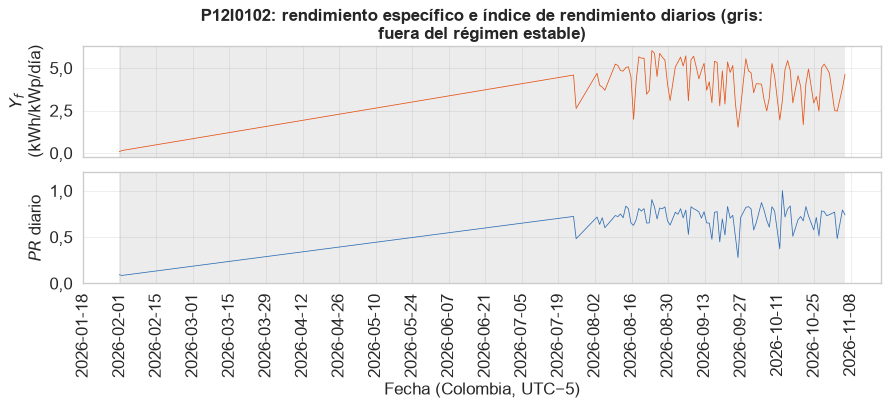

89 filas x 5 columnas; primeras 10:


,yf,yr,pr,kstar,en_regimen
dia,,,,,
2026-02-01,0.0856,0.9044,0.0947,0.0145,False
2026-02-02,0.1540,1.7812,0.0865,0.0252,False
2026-07-25,4.5908,6.3449,0.7235,0.7405,True
2026-07-26,2.6267,5.4414,0.4827,0.4578,True
2026-08-03,4.6938,6.5463,0.7170,0.7046,True
2026-08-04,3.9915,6.2620,0.6374,0.6095,True
2026-08-05,3.8844,5.4744,0.7096,0.6722,True
2026-08-06,3.6983,6.1451,0.6018,0.5540,True
2026-08-10,5.2305,7.1337,0.7332,0.7816,True


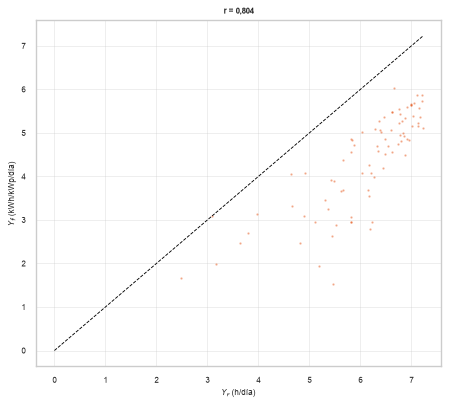

83 filas x 2 columnas; primeras 10:


,yr,yf
dia,,
2026-07-25,6.3449,4.5908
2026-07-26,5.4414,2.6267
2026-08-03,6.5463,4.6938
2026-08-04,6.2620,3.9915
2026-08-05,5.4744,3.8844
2026-08-06,6.1451,3.6983
2026-08-10,7.1337,5.2305
2026-08-11,7.1373,5.1528
2026-08-12,6.4750,4.8556


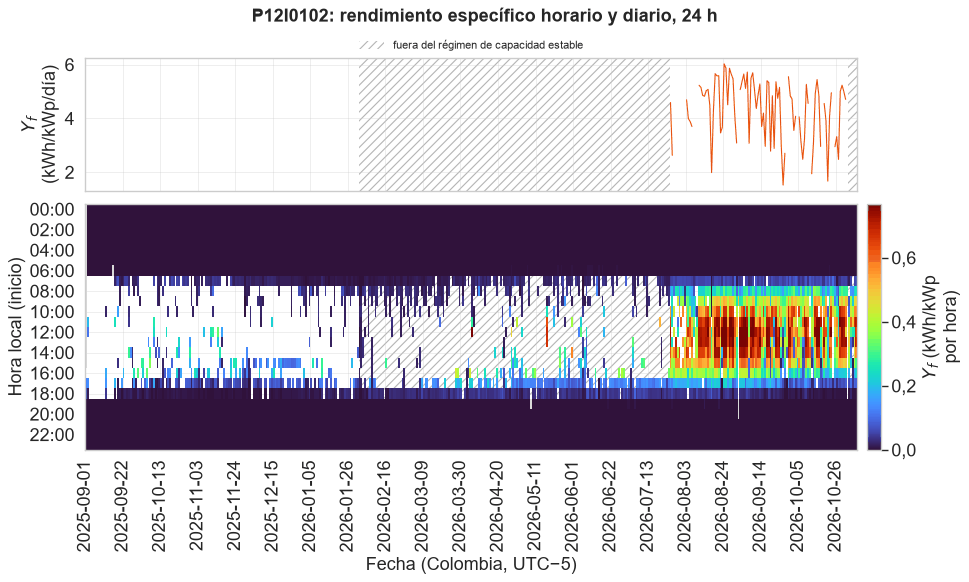

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1108,0.0655,0.0007,0.0,0.0,0.0,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.1892,0.1072,NaN,NaN,NaN,NaN,0.1370,0.0146,0.0000,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0


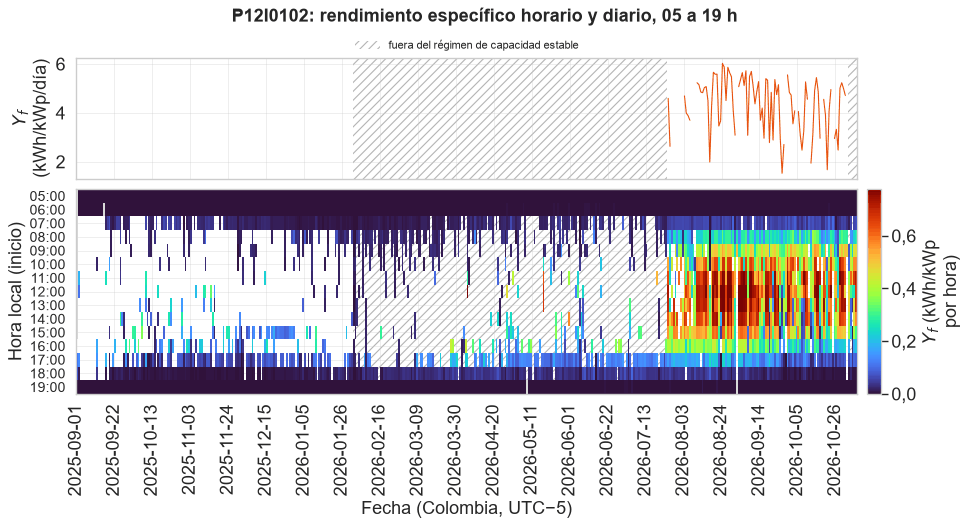

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1108,0.0655,0.0007
2025-09-02 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,0.1892,0.1072,NaN,NaN,NaN,NaN,0.1370,0.0146,0.0000
2025-09-03 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-04 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-05 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-06 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-07 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-08 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-09 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-10 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


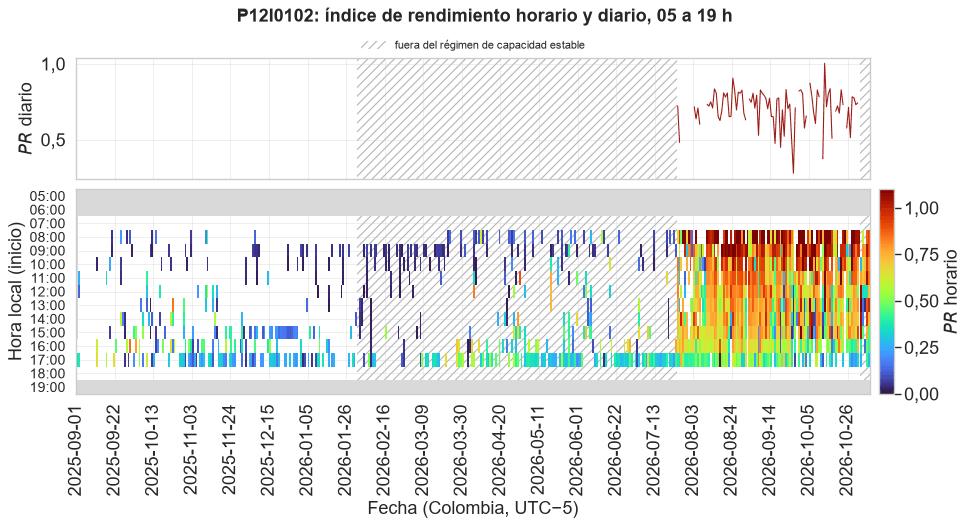

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3506,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,0.2503,0.1253,NaN,NaN,NaN,NaN,0.3799,NaN,NaN
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


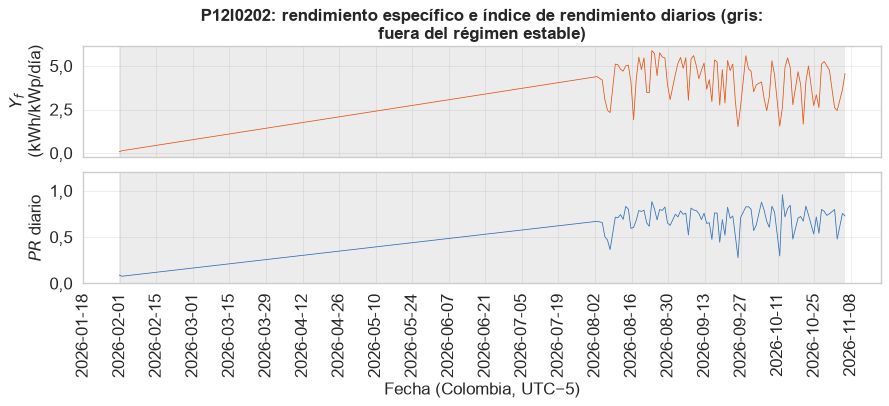

88 filas x 5 columnas; primeras 10:


,yf,yr,pr,kstar,en_regimen
dia,,,,,
2026-02-01,0.0822,0.9044,0.0909,0.0139,False
2026-02-02,0.1387,1.7812,0.0779,0.0227,False
2026-08-03,4.3898,6.5463,0.6706,0.6590,True
2026-08-05,4.1902,6.3688,0.6579,0.6281,True
2026-08-06,3.0753,6.1052,0.5037,0.4628,True
2026-08-07,2.4682,5.2600,0.4692,0.4193,True
2026-08-08,2.3269,6.3667,0.3655,0.3951,True
2026-08-10,5.1051,7.1337,0.7156,0.7629,True
2026-08-11,5.0652,7.1373,0.7097,0.7565,True


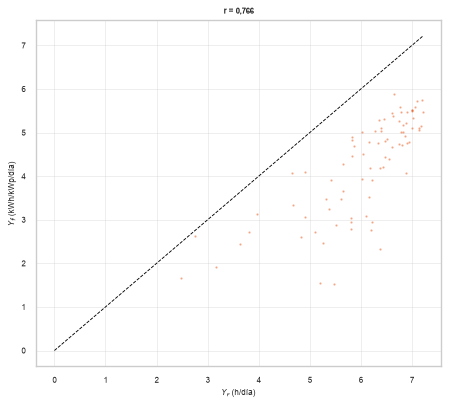

82 filas x 2 columnas; primeras 10:


,yr,yf
dia,,
2026-08-03,6.5463,4.3898
2026-08-05,6.3688,4.1902
2026-08-06,6.1052,3.0753
2026-08-07,5.2600,2.4682
2026-08-08,6.3667,2.3269
2026-08-10,7.1337,5.1051
2026-08-11,7.1373,5.0652
2026-08-12,6.4750,4.8117
2026-08-13,6.8030,4.7055


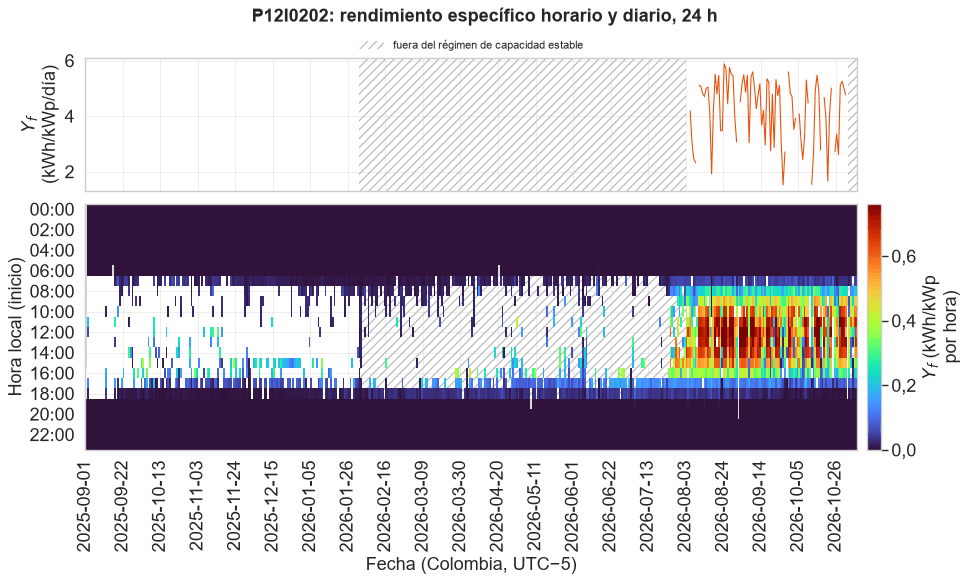

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.1932,0.0608,NaN,NaN,NaN,NaN,0.123,0.0149,0.0,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0


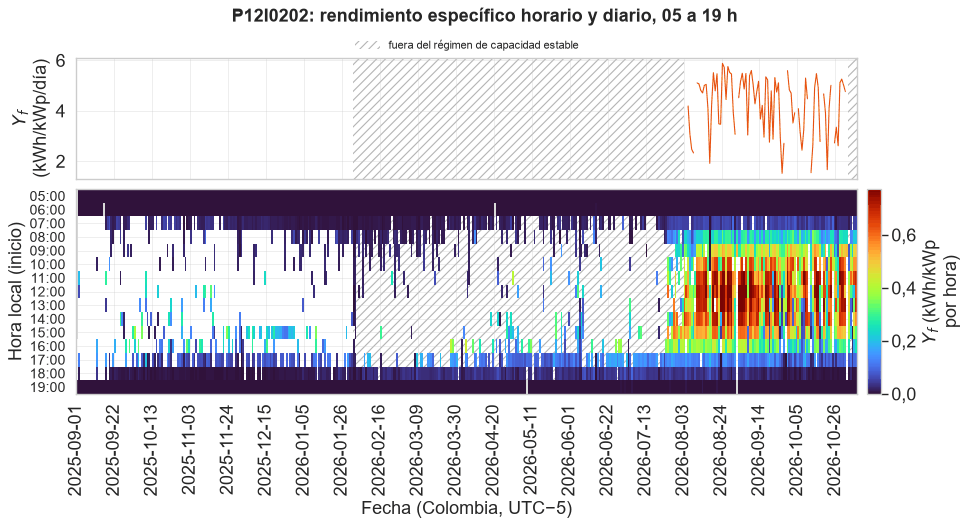

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,0.1932,0.0608,NaN,NaN,NaN,NaN,0.123,0.0149,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


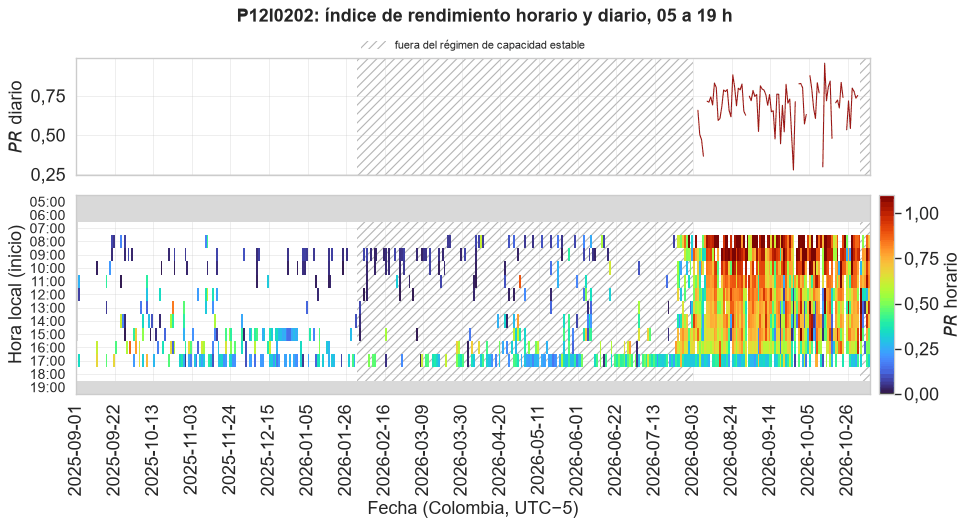

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,0.2555,0.0711,NaN,NaN,NaN,NaN,0.3413,NaN,NaN
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


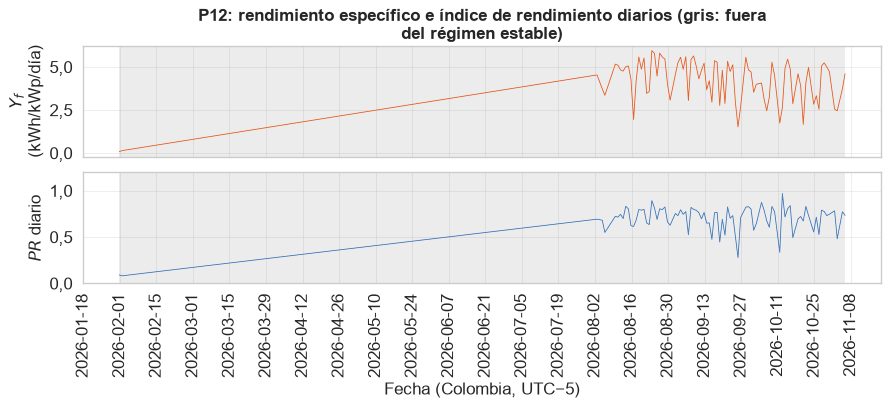

86 filas x 5 columnas; primeras 10:


,yf,yr,pr,kstar,en_regimen
dia,,,,,
2026-02-01,0.0839,0.9044,0.0928,0.0142,False
2026-02-02,0.1464,1.7812,0.0822,0.0240,False
2026-08-03,4.5418,6.5463,0.6938,0.6818,True
2026-08-05,3.7374,5.4744,0.6827,0.6468,True
2026-08-06,3.3617,6.1052,0.5506,0.5059,True
2026-08-10,5.1678,7.1337,0.7244,0.7723,True
2026-08-11,5.1090,7.1373,0.7158,0.7630,True
2026-08-12,4.8336,6.4750,0.7465,0.7633,True
2026-08-13,4.7644,6.8030,0.7003,0.7105,True


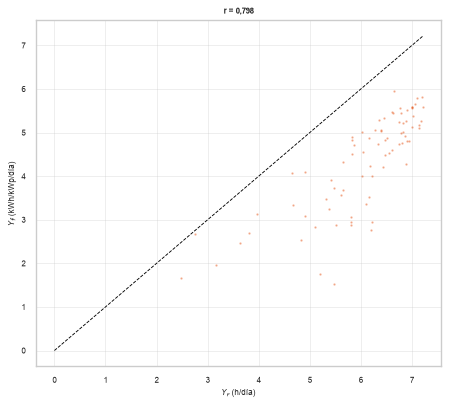

80 filas x 2 columnas; primeras 10:


,yr,yf
dia,,
2026-08-03,6.5463,4.5418
2026-08-05,5.4744,3.7374
2026-08-06,6.1052,3.3617
2026-08-10,7.1337,5.1678
2026-08-11,7.1373,5.1090
2026-08-12,6.4750,4.8336
2026-08-13,6.8030,4.7644
2026-08-14,6.0228,5.0181
2026-08-15,6.2860,5.0616


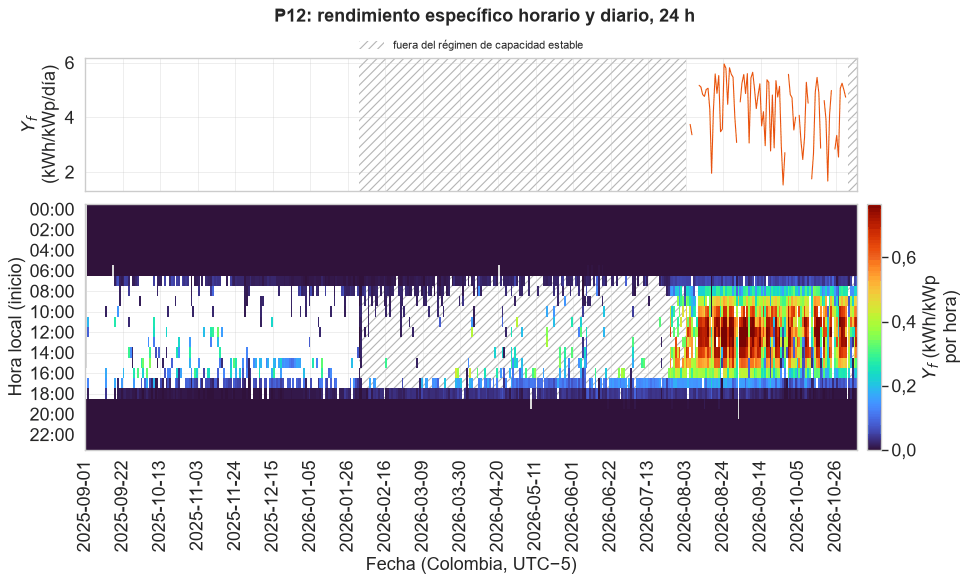

432 filas x 24 columnas; primeras 10:


hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0004,0.0,0.0,0.0,0.0
2025-09-02 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.1912,0.084,NaN,NaN,NaN,NaN,0.13,0.0148,0.0000,0.0,0.0,0.0,0.0
2025-09-03 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-04 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-05 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-06 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-07 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-08 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-09 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0
2025-09-10 00:00:00-05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0,0.0,0.0


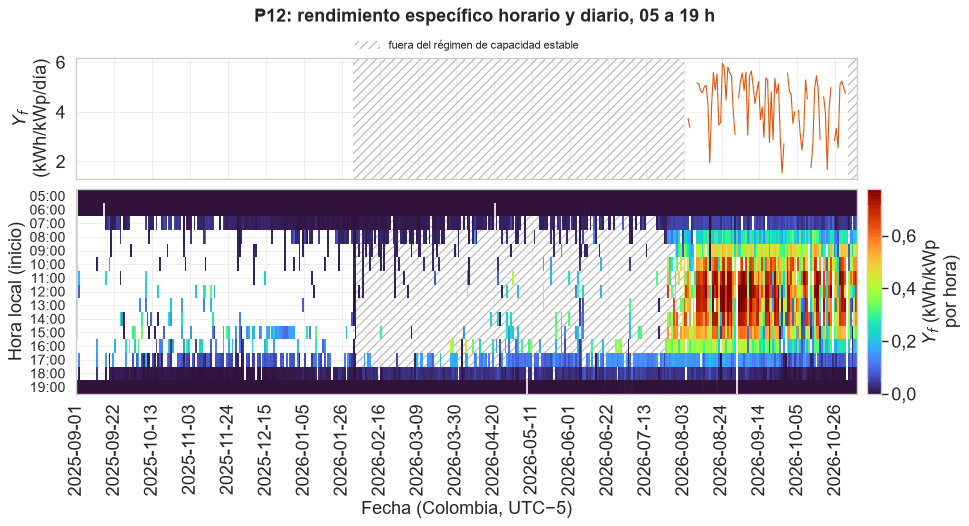

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0004
2025-09-02 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,0.1912,0.084,NaN,NaN,NaN,NaN,0.13,0.0148,0.0000
2025-09-03 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-04 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-05 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-06 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-07 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-08 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-09 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
2025-09-10 00:00:00-05:00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


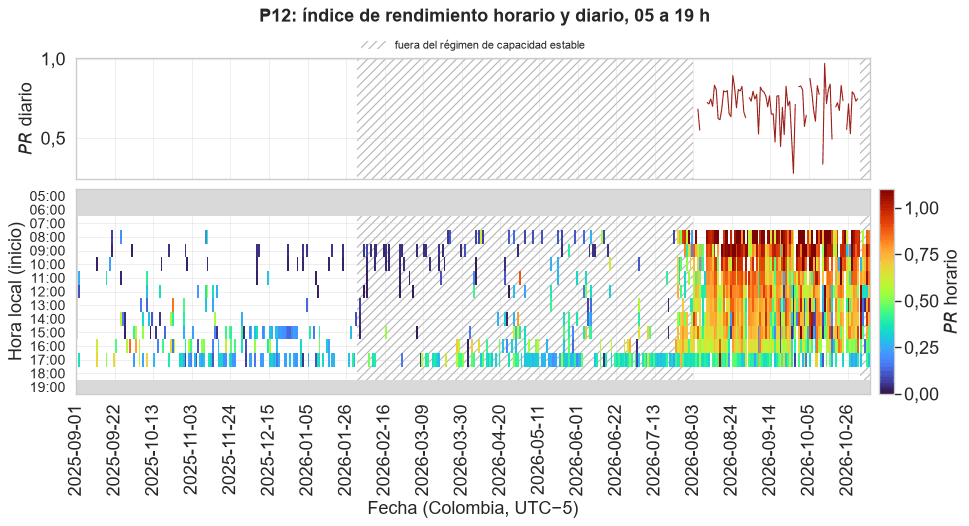

432 filas x 15 columnas; primeras 10:


hora_local,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
2025-09-01 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-02 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,0.2529,0.0982,NaN,NaN,NaN,NaN,0.3606,NaN,NaN
2025-09-03 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-04 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-05 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-06 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-07 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-08 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-09 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-10 00:00:00-05:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dias,yf_media,yf_mediana,pr_mediano,pr_p10,pr_p90,kstar_mediano
P12I0102,83.0,4.347,4.707,0.724,0.524,0.828,0.705
P12I0202,82.0,4.238,4.684,0.721,0.509,0.826,0.695
P13I0101,167.0,4.315,4.527,0.707,0.538,0.870,0.672
P17I0101,20.0,3.714,4.011,0.644,0.585,0.730,0.598
P12,80.0,4.312,4.723,0.732,0.528,0.827,0.700


**Observación.** En el régimen estable, el Yf diario mediano va de 4,01 a 4,72 kWh/kWp y el PR diario mediano de 0,64 a 0,73. Un PR mediano por debajo de 0,70 en un inversor sano suele deberse a limitación de inyección, sombras o suciedad; se revisa con el instalador.

In [31]:
# Sección 5.3. Agregado de planta
for n, d in OBJ_D.items():
    f, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    ax[0].plot(d.index, d["yf"], lw=0.7, color=config.COLOR_PRINCIPAL); ax[0].set_ylabel("Yf (kWh/kWp/día)")
    ax[1].plot(d.index, d["pr"], lw=0.7, color=config.COLOR_SECUNDARIO); ax[1].set_ylabel("PR diario"); ax[1].set_ylim(0, 1.2)
    fuera_reg = d.index[~d["en_regimen"].to_numpy()]
    if len(fuera_reg):
        for a in ax:
            a.axvspan(fuera_reg.min(), fuera_reg.max(), color="grey", alpha=0.15, lw=0)
    ax[0].set_title(f"{n}: rendimiento específico e índice de rendimiento diarios (gris: fuera del régimen estable)")
    fig(f, f"yf_pr_diario_{n}", d[["yf", "yr", "pr", "kstar", "en_regimen"]])
    ok = d[d["en_regimen"]]
    fig(gr.dispersion(ok["yr"], ok["yf"], "Yr (h/día)", "Yf (kWh/kWp/día)"), f"yf_vs_yr_{n}", ok[["yr", "yf"]])
    # Mapas de calor día x hora del rendimiento: Yf (05-19 h y 24 h) y PR (solo con G_POA >= 200 W/m2)
    h_ = OBJ_H[n]
    noche_y = h_["yr_cs"] <= 0
    fig(gr.panel_diario_y_mapa(h_["yf"], d["yf"].where(d["en_regimen"]), f"{n}: rendimiento específico horario y diario, 24 h",
                               "Yf (kWh/kWp por hora)", "Yf (kWh/kWp/día)", None, noche_y, en_regimen=d["en_regimen"]),
        f"mapa_yf_24h_{n}", gr.tabla_dia_hora(h_["yf"], None).T)
    fig(gr.panel_diario_y_mapa(h_["yf"], d["yf"].where(d["en_regimen"]), f"{n}: rendimiento específico horario y diario, 05 a 19 h",
                               "Yf (kWh/kWp por hora)", "Yf (kWh/kWp/día)", (5, 19), noche_y, en_regimen=d["en_regimen"]),
        f"mapa_yf_{n}", gr.tabla_dia_hora(h_["yf"], (5, 19)).T)
    # gr.mostrar(gr.tabla_dia_hora(h_["yf"], (5, 19)).T, todas=True)   # todas las filas
    fig(gr.panel_diario_y_mapa(h_["pr"], d["pr"].where(d["en_regimen"]), f"{n}: índice de rendimiento horario y diario, 05 a 19 h",
                               "PR horario", "PR diario", (5, 19), noche_y, vmax=1.1, en_regimen=d["en_regimen"]), f"mapa_pr_{n}",
        gr.tabla_dia_hora(h_["pr"], (5, 19)).T)

if OBJ_D:
    ESTAD = pd.DataFrame({n: {"dias": int(d["en_regimen"].sum()), "yf_media": d.loc[d["en_regimen"], "yf"].mean(),
                              "yf_mediana": d.loc[d["en_regimen"], "yf"].median(), "pr_mediano": d.loc[d["en_regimen"], "pr"].median(),
                              "pr_p10": d.loc[d["en_regimen"], "pr"].quantile(0.1), "pr_p90": d.loc[d["en_regimen"], "pr"].quantile(0.9),
                              "kstar_mediano": d.loc[d["en_regimen"], "kstar"].median()} for n, d in OBJ_D.items()}).T
    display(ESTAD.round(3))
    display(Markdown(
        f"**Observación.** En el régimen estable, el Yf diario mediano va de {ESTAD['yf_mediana'].min():.2f} a "
        f"{ESTAD['yf_mediana'].max():.2f} kWh/kWp y el PR diario mediano de {ESTAD['pr_mediano'].min():.2f} a "
        f"{ESTAD['pr_mediano'].max():.2f}. Un PR mediano por debajo de 0,70 en un inversor sano suele deberse a "
        f"limitación de inyección, sombras o suciedad; se revisa con el instalador."))
    res.registrar(f"localidades.{GRUPO}.objetivos", ESTAD.round(4).to_dict(orient="index"))
else:
    # Todas las plantas del grupo siguen limitadas al corte (o sin un régimen de capacidad estable): no hay rendimiento
    # observado del proceso fotovoltaico que modelar; el cuaderno documenta la calidad de sus datos y sigue hasta la guardia
    ESTAD = pd.DataFrame()
    display(Markdown(f"**Ninguna unidad de {GRUPO} tiene régimen vigente al corte.** Sus plantas siguen limitadas o no tienen un "
                     "régimen de capacidad estable: su producción sigue al consumo del predio y no hay rendimiento observado "
                     "del proceso fotovoltaico que modelar. Quedan fuera del régimen B, como declara el capítulo de metodología."))

In [32]:
# Sección 5.3. Agregado de planta
# Datos procesados de la localidad (en resultados/intermedios; datos/ no se modifica)
DIR_PROC = config.DIR_INTERMEDIOS / GRUPO
DIR_PROC.mkdir(parents=True, exist_ok=True)
for n in OBJ_H:
    OBJ_H[n].to_parquet(DIR_PROC / f"objetivos_horarios_{n}.parquet")
    OBJ_D[n].to_parquet(DIR_PROC / f"objetivos_diarios_{n}.parquet")
irr_h.to_parquet(DIR_PROC / f"irradiancia_horaria_{FUENTE_IRR}.parquet")
display(Markdown(f"Objetivos guardados en `{DIR_PROC}`"))

Objetivos guardados en `L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\resultados\intermedios\G05`

## 6. Ingeniería y selección de variables

Esta parte decide, con evidencia, qué información entra en los modelos de cada escenario. Se trabaja con
el objetivo horario Yf del día siguiente (horizonte H01DH), en las horas de sol, observado (como máximo una
lectura de cinco minutos imputada) y dentro del régimen vigente. Todo lo que aprende de los datos se calcula solo con el
entrenamiento; la importancia por permutación se mide en la validación.

### 6.1. Candidatas

| Grupo | Variables | ¿Disponible al emitir el pronóstico (final del día D − 1)? |
|---|---|---|
| Endógenas | Yf de la misma hora 24, 48 y 168 h antes; k* de la misma hora del día anterior; Yf y k* del día anterior completo | Sí |
| Deterministas | Yr de cielo despejado, elevación y azimut solar, coseno del cenit, hora y día del año (seno y coseno) | Sí: se calculan para cualquier fecha |
| E1 observadas | Yr y k_t de la fuente elegida en 5.1; temperatura, humedad, punto de rocío, nubosidad total y por capas, precipitación, viento, presión y déficit de presión de vapor del análisis IFS; AOD y polvo de CAMS; temperatura de módulo (Faiman); días secos consecutivos (lluvia del análisis IFS) | No: es el "pronóstico perfecto", el límite superior de lo alcanzable |
| Lluvia medida | Días secos consecutivos con la lluvia de la estación del IDEAM hasta el día D − 2 (2.10) | Sí: el IDEAM publica con uno a dos días de retraso, por eso se usa hasta D − 2 |
| E2 pronosticadas | Las mismas desde el pronóstico IFS 0,25 archivado con un día de antelación (Open-Meteo Previous Runs); aerosoles con 24 h de rezago | Sí |

Los rezagos del objetivo son de al menos 24 h porque el pronóstico del día D se emite al final del día
D − 1: cualquier dato posterior sería fuga de información. La dirección del viento se descarta porque es
circular y, en este sitio costero, su efecto ya lo recogen la nubosidad y la temperatura.

In [33]:
# Sección 6.1. Candidatas
vm = datos.variables_meteo()
EXO = {"E1": caract.exogenas_meteo(crudos, vm, lugar, "E1"),
       "E2": caract.exogenas_meteo(crudos, vm, lugar, "E2", previousday=1)}
IRR = {"E1": irr_h, "E2": FUENTES["ifs025_pronostico_d1"]}
precip_d = EXO["E1"]["precipitation"].groupby(part.dias_locales(EXO["E1"].index)).sum(min_count=20)
SECOS = caract.dias_secos(precip_d)
SECOS_IDEAM = caract.dias_secos(lluvia_ideam.dropna()) if len(lluvia_ideam.dropna()) > 60 else pd.Series(dtype=float)

def candidatas(n, inv, escenario):
    oh, od = OBJ_H[n], OBJ_D[n]
    e = EXO[escenario].reindex(oh.index).drop(columns=["wind_direction_10m"], errors="ignore")
    f = IRR[escenario].reindex(oh.index)
    poa, _ = obj.poa_inversor(f["ghi"], f["dni"], f["dhi"], lugar, inv.inclinacion, inv.azimut, caras=obj.caras_de(inv))
    ghi_cs = solar.cielo_despejado(oh.index, lugar, pd.Timedelta("30min"))["ghi_cs"]
    s = escenario.lower()
    extra = pd.DataFrame({f"yr_{s}": poa / 1000.0, f"kt_{s}": (f["ghi"] / ghi_cs).where(ghi_cs > 50).clip(0, 1.5)}, index=oh.index)
    extra["t_modulo"] = caract.temperatura_modulo(poa, e["temperature_2m"], e.get("wind_speed_10m"))
    extra["dias_secos"] = caract.diario_a_horario(SECOS, oh.index, 1)
    if len(SECOS_IDEAM):
        extra["dias_secos_ideam"] = caract.diario_a_horario(SECOS_IDEAM, oh.index, 2)   # retraso de publicación
    return caract.matriz_h2(oh, od, pd.concat([e, extra], axis=1), lugar)

def mascara_modelado(n):
    oh = OBJ_H[n]
    return ((oh["yr_cs"] > 0.05) & config.hora_observada(oh["frac_imputada"]) & oh["en_regimen"] & oh["yf"].notna()).to_numpy()

# Unidad principal: el inversor con más días de entrenamiento en régimen estable (desempate: mayor kWp).
# Sobre ella se hacen la identificación y la búsqueda de órdenes; luego se aplican a todas las unidades.
kwp_de = lambda n: float(INV.loc[n, "kwpdc"])
DIAS_MIN_SARIMAX, DIAS_MIN_ML = 14, 60      # umbrales de la suficiencia de datos (sección 12.2 de G01 y G02)

def dias_validos(n):
    d = OBJ_D[n]
    return d.index[d["en_regimen"].to_numpy() & d["yf"].notna().to_numpy() & (d.index < pd.Timestamp(config.FIN_MODELADO))]

def particion_propia(n):
    # Partición cronológica de una unidad reciente: entrenamiento con al menos 14 días (60 %), validación y
    # prueba con al menos 7 días cada una. None si no alcanza.
    dv = dias_validos(n)
    if len(dv) < DIAS_MIN_SARIMAX + 14:
        return None
    n_tr = max(DIAS_MIN_SARIMAX, int(0.6 * len(dv)))
    n_va = max(7, int(0.2 * len(dv)))
    if len(dv) - n_tr - n_va < 7:
        n_tr = len(dv) - n_va - 7
    f = lambda d: d.strftime("%Y-%m-%d")
    return {"entrenamiento": ("2024-01-01", f(dv[n_tr - 1])), "validacion": (f(dv[n_tr]), f(dv[n_tr + n_va - 1])),
            "prueba": (f(dv[n_tr + n_va]), f(pd.Timestamp(config.FIN_MODELADO) - pd.Timedelta(days=1))),
            "vivo": PARTICIONES_FIJAS["vivo"]}

UNIDADES_MODELABLES = {}
for n in OBJ_D:
    # Partición fija si hay al menos 14 días válidos de entrenamiento y 7 de validación y de prueba; si no
    # (unidad reciente, o que dejó de reportar antes de la validación), partición cronológica propia
    etq_f = part.etiquetar(dias_validos(n), PARTICIONES_FIJAS).to_numpy()
    d_ent, d_val, d_pru = (int((etq_f == k).sum()) for k in ("entrenamiento", "validacion", "prueba"))
    fija_ok = d_ent >= DIAS_MIN_SARIMAX and d_val >= 7 and d_pru >= 7
    pp = None if fija_ok else particion_propia(n)
    d_ent_ef = d_ent if pp is None else int(((part.etiquetar(dias_validos(n), pp).to_numpy() == "entrenamiento")).sum())
    UNIDADES_MODELABLES[n] = {"dias_entrenamiento": d_ent_ef, "dias_validacion_fija": d_val, "dias_prueba_fija": d_pru,
                              "particion": "propia" if pp else "fija",
                              "particiones": {k: [str(x) for x in v] for k, v in (pp or PARTICIONES_FIJAS).items()},
                              "modelable": bool(fija_ok or pp is not None),
                              "ml_bajo_minimo": bool(d_ent_ef < DIAS_MIN_ML), "tipo": "planta" if n in INVERSORES["planta"].values else "inversor"}
candidatos_p = {n: v for n, v in UNIDADES_MODELABLES.items() if v["modelable"] and v["tipo"] == "inversor"}
PRINCIPAL = max(candidatos_p, key=lambda n: (UNIDADES_MODELABLES[n]["particion"] == "fija", candidatos_p[n]["dias_entrenamiento"],
                                              kwp_de(n))) if candidatos_p else None
n0 = UNIDAD or PRINCIPAL
ES_PRINCIPAL = n0 == PRINCIPAL
MODELABLE = n0 is not None and UNIDADES_MODELABLES.get(n0, {}).get("modelable", False)
PARTICION_PROPIA = MODELABLE and UNIDADES_MODELABLES[n0]["particion"] == "propia"
if PARTICION_PROPIA:
    config.PARTICIONES = particion_propia(n0)          # solo en este kernel: cada unidad corre en su propio proceso
if not ES_PRINCIPAL:
    # Las figuras, sus datos y las tablas de las demás unidades van a su propia carpeta: el documento usa las de
    # la unidad principal de cada grupo y la síntesis de la flota
    config.DIR_FIGURAS = config.DIR_RESULTADOS / "unidades" / GRUPO / n0 / "figuras"
    config.DIR_DATOS_FIGURAS = config.DIR_RESULTADOS / "unidades" / GRUPO / n0 / "datos_figuras"
    config.DIR_TABLAS = config.DIR_RESULTADOS / "unidades" / GRUPO / n0 / "tablas"
if ES_PRINCIPAL or not UNIDAD:
    res.registrar(f"localidades.{GRUPO}.unidades_modelables", {"principal": PRINCIPAL, "unidades": UNIDADES_MODELABLES})

def registrar_unidad(clave, valor):
    # Resultados de la unidad modelada: bajo unidades.<código> y, si es la principal, también en el nivel del grupo.
    res.registrar(f"localidades.{GRUPO}.unidades.{n0}.{clave}", valor)
    if ES_PRINCIPAL:
        res.registrar(f"localidades.{GRUPO}.{clave}", valor)

display(Markdown("**Unidades del grupo y su viabilidad para el modelado** (umbrales: SARIMAX con al menos "
                 f"{DIAS_MIN_SARIMAX} días de entrenamiento; ML y redes con al menos {DIAS_MIN_ML}, según la suficiencia de datos):"))
display(pd.DataFrame(UNIDADES_MODELABLES).T)
if not MODELABLE and not OBJ_D:
    display(Markdown(f"**El cuaderno de {GRUPO} termina con la exploración y el análisis de los datos.** Sin régimen vigente, sus "
                     "unidades tampoco entran al panel del modelo global."))
elif not MODELABLE:
    display(Markdown(f"**El grupo {GRUPO} no tiene unidades con datos suficientes para el modelado individual** (ni con las "
                     "particiones fijas ni con una partición cronológica propia de al menos 28 días válidos). El cuaderno "
                     "termina con la exploración y el análisis de los datos; sus unidades se evalúan con el modelo global."))
else:
    inv0 = INV.loc[n0]
    X0, y0 = candidatas(n0, inv0, "E1")
    display(Markdown(f"**Unidad modelada: {n0}** ({kwp_de(n0)} kWp; {UNIDADES_MODELABLES[n0]['dias_entrenamiento']} días de "
                     f"entrenamiento en régimen estable; partición {UNIDADES_MODELABLES[n0]['particion']}"
                     + (f": {config.PARTICIONES}" if PARTICION_PROPIA else "") + ")."
                     + (" Tiene menos días de los que la suficiencia exige al aprendizaje automático y a las redes: sus "
                        "resultados en esas familias son indicativos." if UNIDADES_MODELABLES[n0]["ml_bajo_minimo"] else "")))
    display(Markdown(f"**{X0.shape[1]} candidatas** en E1: " + ", ".join(f"`{c}`" for c in X0.columns)))

**Unidades del grupo y su viabilidad para el modelado** (umbrales: SARIMAX con al menos 14 días de entrenamiento; ML y redes con al menos 60, según la suficiencia de datos):

,dias_entrenamiento,dias_validacion_fija,dias_prueba_fija,particion,particiones,modelable,ml_bajo_minimo,tipo
P12I0102,49,28,55,propia,"{'entrenamiento': ['2024-01-01', '2026-09-22']...",True,True,inversor
P12I0202,49,27,55,propia,"{'entrenamiento': ['2024-01-01', '2026-09-23']...",True,True,inversor
P13I0101,50,59,58,fija,"{'entrenamiento': ['2024-01-01', '2026-06-30']...",True,True,inversor
P17I0101,0,0,20,fija,"{'entrenamiento': ['2024-01-01', '2026-06-30']...",False,True,inversor
P12,48,25,55,propia,"{'entrenamiento': ['2024-01-01', '2026-09-24']...",True,True,planta


**Unidad modelada: P12** (12,3 kWp; 48 días de entrenamiento en régimen estable; partición propia: {'entrenamiento': ('2024-01-01', '2026-09-24'), 'validacion': ('2026-09-25', '2026-10-13'), 'prueba': ('2026-10-14', '2026-10-31'), 'vivo': ('2026-11-01', '2026-12-31')}). Tiene menos días de los que la suficiencia exige al aprendizaje automático y a las redes: sus resultados en esas familias son indicativos.

**34 candidatas** en E1: `yf_rez24`, `yf_rez48`, `yf_rez168`, `kstar_rez24`, `yf_dia_rez1`, `kstar_dia_rez1`, `yr_cs`, `elevacion_solar`, `azimut_solar`, `cos_cenit`, `hora_sin`, `hora_cos`, `doy_sin`, `doy_cos`, `cloud_cover`, `cloud_cover_high`, `cloud_cover_low`, `cloud_cover_mid`, `dew_point_2m`, `precipitation`, `relative_humidity_2m`, `sunshine_duration`, `surface_pressure`, `temperature_2m`, `vapour_pressure_deficit`, `wind_gusts_10m`, `wind_speed_10m`, `aerosol_optical_depth`, `dust`, `yr_e1`, `kt_e1`, `t_modulo`, `dias_secos`, `dias_secos_ideam`

Para el modelo global, la ejecución del grupo guarda para cada inversor con objetivos su matriz del escenario E2
(solo lo disponible antes del día pronosticado), el objetivo, la máscara de horas modelables y sus covariables
estáticas, que son el kWp, la potencia nominal y la relación DC/AC, la inclinación y el azimut ponderados por los paneles
de cada cara, el número de caras, la latitud, la longitud y la altitud, la región natural y el tipo de instalación. La
temperatura del inversor entra con 24 h de rezago, porque la de la hora pronosticada no se conoce de antemano, y el
cuaderno `04_global.ipynb` apila los paneles de todos los grupos.

In [34]:
# Sección 6.1. Candidatas
if not UNIDAD:
    plantas_g = const["plantas"].set_index("plantuuid")
    altitud_punto = float(const["grupo"]["elevacion"].iloc[0])
    PANEL = []
    for n in OBJ_H:
        if UNIDADES_MODELABLES.get(n, {}).get("tipo") != "inversor":
            continue
        inv = INV.loc[n]
        Xp, yp = candidatas(n, inv, "E2")
        Xp = Xp.copy()
        Xp["t_inversor_rez24"] = OBJ_H[n]["t_inversor"].shift(freq="24h").reindex(Xp.index)
        caras = np.array(obj.caras_de(inv), dtype=float)
        w = caras[:, 2] / caras[:, 2].sum()
        az = np.radians(caras[:, 1])
        pl = plantas_g.loc[inv.plantuuid] if inv.plantuuid in plantas_g.index else pd.Series(dtype=object)
        estaticas = {"kwp": float(inv.kwpdc), "potencia_nominal_kw": float(inv.ratedpower),
                     "relacion_dc_ac": float(inv.kwpdc) / float(inv.ratedpower),
                     "inclinacion_media": float((w * caras[:, 0]).sum()),
                     "azimut_sen": float((w * np.sin(az)).sum()), "azimut_cos": float((w * np.cos(az)).sum()),
                     "caras": int(len(caras)), "latitud": float(pl.get("latitude", lugar.latitude)),
                     "longitud": float(pl.get("longitude", lugar.longitude)),
                     "altitud_m": float(pl.get("altitud_dem_m")) if pd.notna(pl.get("altitud_dem_m")) else altitud_punto,
                     "region_natural": pl.get("region_natural"), "tipo_instalacion": pl.get("tipo")}
        sol = (OBJ_H[n]["yr_cs"] > 0.05).reindex(Xp.index).fillna(False).to_numpy()
        d = Xp[sol].assign(**estaticas)
        d["yf"] = yp[sol]
        d["modelable"] = mascara_modelado(n)[sol]
        d["unidad"], d["planta"], d["grupo"] = n, inv.planta, GRUPO
        d["particion"] = part.etiquetar(d.index, PARTICIONES_FIJAS).to_numpy()
        d["frac_imputada"] = OBJ_H[n]["frac_imputada"].reindex(d.index).to_numpy()
        PANEL.append(d)
    if PANEL:
        DIR_PANEL = config.DIR_INTERMEDIOS / f"panel{SUF}"
        DIR_PANEL.mkdir(parents=True, exist_ok=True)
        for d in PANEL:
            d.to_parquet(DIR_PANEL / f"{GRUPO}_{d['unidad'].iloc[0]}.parquet")
    display(Markdown(f"Panel del modelo global: {len(PANEL)} inversores, "
                     f"{sum(int(d['modelable'].sum()) for d in PANEL)} horas de sol modelables."))

### 6.2. Verificación de la alineación temporal

Antes de medir relevancias se comprueba que las series están alineadas: la correlación cruzada entre el
Yf horario y el Yr de la fuente elegida debe ser máxima en el rezago 0. Un máximo en ±1 h indicaría un
error de convención (etiqueta al inicio frente al final) que contaminaría todo lo que sigue.

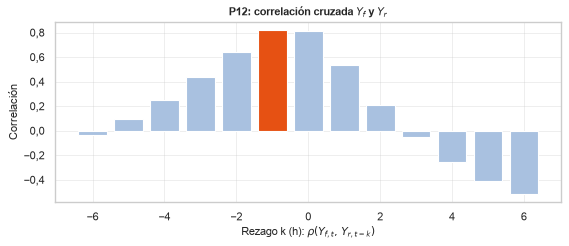

13 filas x 1 columnas; primeras 10:


,correlacion
rezago_h,
-6,-0.0350
-5,0.0966
-4,0.2468
-3,0.4341
-2,0.6450
-1,0.8176
0,0.8123
1,0.5335
2,0.2129


**Resultado.** Máximo en el rezago **-1 h** (r = 0,818); con ±1 h la correlación baja a 0,818 y 0,533. **Hay un desfase que corregir antes de seguir.**

In [35]:
# Sección 6.2. Verificación de la alineación temporal
if MODELABLE:
    m0 = mascara_modelado(n0)
    cc = sel.correlacion_cruzada(y0.where(m0), X0["yr_e1"], max_rezago=6)
    f, ax = plt.subplots(figsize=(7, 3))
    ax.bar(cc.index, cc.to_numpy(), color=[config.COLOR_PRINCIPAL if k == cc.idxmax() else config.COLOR_TENUE for k in cc.index])
    ax.set_xlabel("Rezago k (h): corr(Yf_t, Yr_{t-k})"); ax.set_ylabel("Correlación"); ax.set_title(f"{n0}: correlación cruzada Yf y Yr")
    fig(f, f"correlacion_cruzada_yf_yr_{n0}", cc.rename("correlacion").rename_axis("rezago_h").to_frame())
    display(Markdown(f"**Resultado.** Máximo en el rezago **{cc.idxmax()} h** (r = {cc.max():.3f}); con ±1 h la correlación baja a "
                     f"{cc.get(-1, np.nan):.3f} y {cc.get(1, np.nan):.3f}. " +
                     ("Las convenciones de tiempo están alineadas." if cc.idxmax() == 0 else "**Hay un desfase que corregir antes de seguir.**")))

### 6.3. Correlación de todas las variables contra todas

Antes de seleccionar miramos la matriz de correlación de **todas** las variables disponibles, que incluyen el objetivo
(Yf y PR horarios de la unidad principal), todas las variables horarias de su telemetría y todas las variables de todas
las fuentes meteorológicas (satélite, análisis, reanálisis, pronósticos, aerosoles, NASA POWER, NSRDB e IDEAM). Usamos
solo las horas de sol del entrenamiento dentro del régimen estable, porque de noche todo vale 0 y la correlación se
inflaría sin decir nada.

Calculamos las correlaciones de Pearson (lineal) y de Spearman (monótona), un mapa agrupado (*clustermap*) que reúne las
variables parecidas, la lista de pares con |r| ≥ 0,99 (que entregan la misma información, el criterio de clase para
eliminar una de las dos) y un análisis de componentes principales (PCA) de las variables meteorológicas.

Hay que tener en cuenta dos cosas. Las variables eléctricas de la telemetría del mismo instante (potencias, tensiones y
corrientes del MPPT) correlacionan casi 1 con el objetivo porque **son** la producción, así que describen el sistema
pero no pueden ser predictores del día siguiente, que se emite sin conocerlas. Además, la selección de la sección 6.7
aplica el mismo criterio de clase, con un umbral de 0,90 en lugar de 1 entre variables, y añade cuatro criterios de
relevancia frente al objetivo.

**104 variables** en 605 horas de sol del entrenamiento de P12.

**Correlación de cada variable con Yf** (ordenada por |Spearman|)

,pearson_con_yf,spearman_con_yf,horas
nasa.allsky_sfc_sw_dwn,0.886,0.872,366
ifs.shortwave_radiation,0.876,0.867,605
ifs025_d1.shortwave_radiation,0.856,0.844,605
ifs.direct_radiation,0.845,0.843,605
era5.shortwave_radiation,0.848,0.838,605
msg.shortwave_radiation,0.842,0.833,601
nasa.clrsky_sfc_sw_dwn,0.842,0.822,366
icon_0_6h.shortwave_radiation,0.827,0.820,605
era5.terrestrial_radiation,0.832,0.817,605
ifs.terrestrial_radiation,0.832,0.816,605


**Pares con |r| ≥ 0,99** (4): de cada par basta con una variable.

,variable_a,variable_b,correlacion
0,ifs.terrestrial_radiation,era5.terrestrial_radiation,1.0000
1,ifs.terrestrial_radiation,nasa.clrsky_sfc_sw_dwn,0.9975
2,era5.terrestrial_radiation,nasa.clrsky_sfc_sw_dwn,0.9975
3,era5.cloud_cover,era5.cloud_cover_high,0.9918


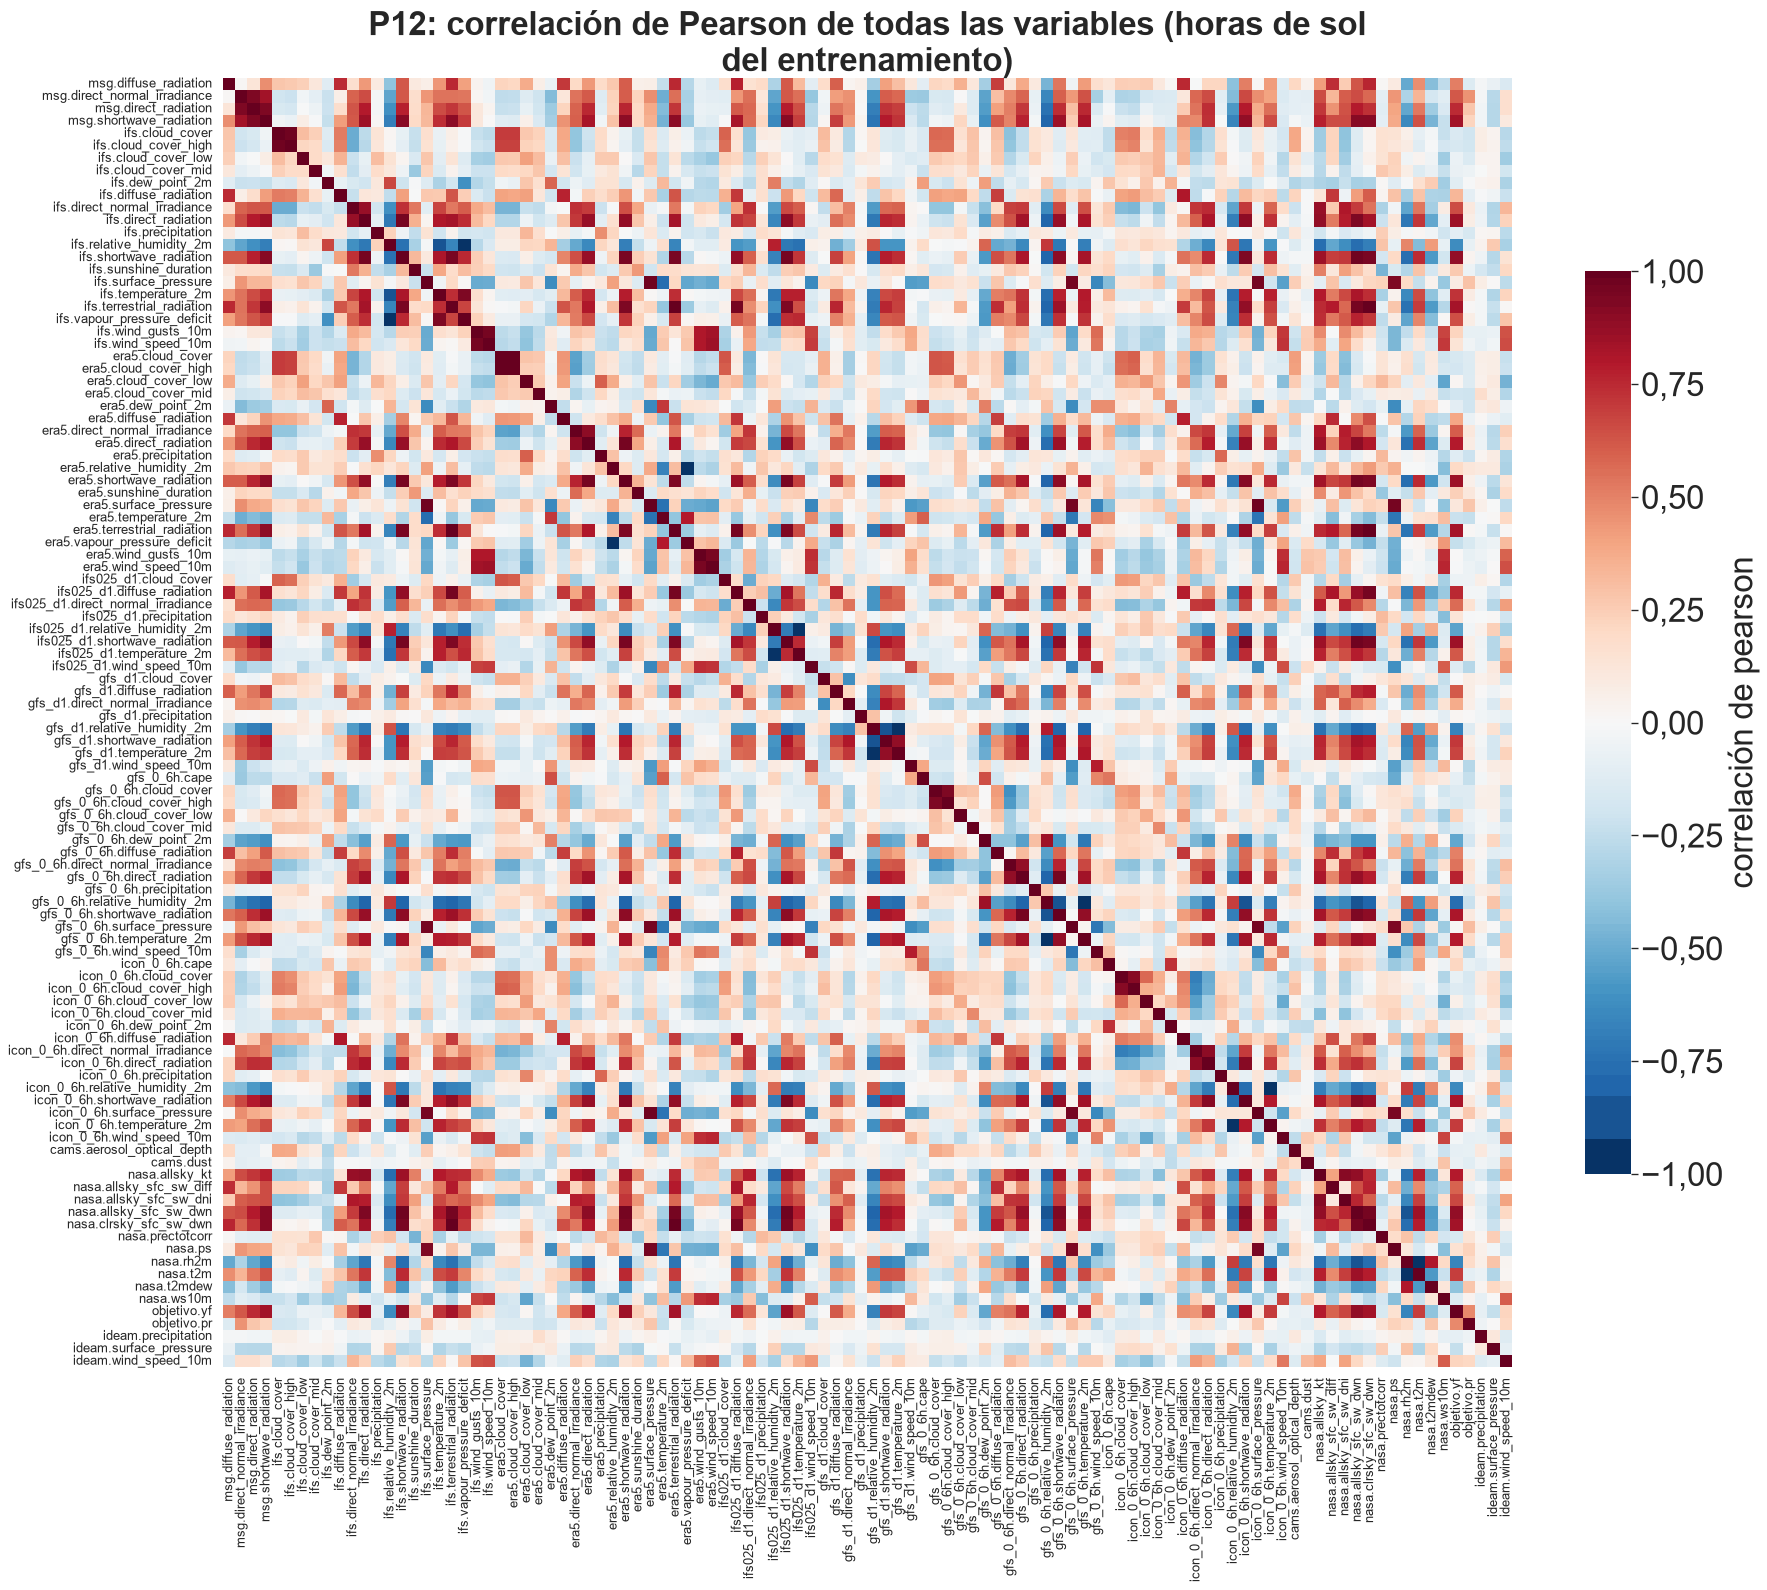

104 filas x 104 columnas; primeras 10:


,msg.diffuse_radiation,msg.direct_normal_irradiance,msg.direct_radiation,msg.shortwave_radiation,ifs.cloud_cover,ifs.cloud_cover_high,ifs.cloud_cover_low,ifs.cloud_cover_mid,ifs.dew_point_2m,ifs.diffuse_radiation,ifs.direct_normal_irradiance,ifs.direct_radiation,ifs.precipitation,ifs.relative_humidity_2m,ifs.shortwave_radiation,ifs.sunshine_duration,ifs.surface_pressure,ifs.temperature_2m,ifs.terrestrial_radiation,ifs.vapour_pressure_deficit,...,icon_0_6h.temperature_2m,icon_0_6h.wind_speed_10m,cams.aerosol_optical_depth,cams.dust,nasa.allsky_kt,nasa.allsky_sfc_sw_diff,nasa.allsky_sfc_sw_dni,nasa.allsky_sfc_sw_dwn,nasa.clrsky_sfc_sw_dwn,nasa.prectotcorr,nasa.ps,nasa.rh2m,nasa.t2m,nasa.t2mdew,nasa.ws10m,objetivo.yf,objetivo.pr,ideam.precipitation,ideam.surface_pressure,ideam.wind_speed_10m
msg.diffuse_radiation,1.0000,0.0156,0.1279,0.4661,0.2789,0.2644,0.2366,0.1139,-0.1231,0.7433,0.1680,0.4312,0.0862,-0.4041,0.6215,0.0955,0.0701,0.4385,0.7516,0.4071,...,0.4295,-0.1256,0.2052,0.0444,0.4193,0.7373,0.2531,0.6269,0.7579,0.0093,0.0886,-0.5113,0.4669,-0.4268,-0.2546,0.5118,-0.1396,-0.0194,-0.0743,-0.1517
msg.direct_normal_irradiance,0.0156,1.0000,0.9338,0.8385,-0.1988,-0.2113,-0.0336,-0.0951,-0.2263,0.0634,0.5880,0.6523,-0.0181,-0.5302,0.6174,0.1796,0.4376,0.5469,0.5460,0.5333,...,0.4045,-0.1439,-0.1013,-0.1058,0.6531,0.3353,0.6077,0.6502,0.5757,-0.0958,0.4430,-0.3056,0.3369,-0.1741,-0.1158,0.6231,0.4470,-0.0229,-0.2788,0.1659
msg.direct_radiation,0.1279,0.9338,1.0000,0.9371,-0.1566,-0.1753,-0.0077,-0.0607,-0.2186,0.1745,0.6257,0.7920,-0.0196,-0.6060,0.7792,0.1839,0.3341,0.6553,0.7146,0.6254,...,0.5624,-0.1192,-0.0997,-0.0911,0.7117,0.4455,0.6381,0.7956,0.7270,-0.1124,0.3907,-0.5174,0.5274,-0.3534,-0.1553,0.7425,0.2791,-0.0335,-0.2887,0.1703
msg.shortwave_radiation,0.4661,0.8385,0.9371,1.0000,-0.0415,-0.0634,0.0764,-0.0141,-0.2384,0.4173,0.6173,0.8583,0.0129,-0.6828,0.9139,0.1977,0.3227,0.7390,0.9020,0.7011,...,0.6529,-0.1505,-0.0167,-0.0657,0.7748,0.6515,0.6516,0.9216,0.9071,-0.0970,0.3797,-0.6416,0.6348,-0.4655,-0.2281,0.8425,0.2233,-0.0370,-0.2852,0.0983
ifs.cloud_cover,0.2789,-0.1988,-0.1566,-0.0415,1.0000,0.9837,0.3054,0.2359,-0.1296,0.5176,-0.4936,-0.2597,0.1376,0.0170,-0.0806,-0.2319,0.1715,-0.0771,0.0703,-0.0150,...,-0.0717,-0.1827,0.3899,0.0377,-0.3523,0.2254,-0.4028,-0.1264,0.0278,0.1512,0.1435,0.0582,-0.0935,-0.0248,-0.2285,-0.1535,-0.2006,0.0734,0.0333,-0.2790
ifs.cloud_cover_high,0.2644,-0.2113,-0.1753,-0.0634,0.9837,1.0000,0.2178,0.1888,-0.1516,0.5006,-0.4957,-0.2738,0.1211,0.0121,-0.0988,-0.2397,0.1504,-0.0835,0.0491,-0.0130,...,-0.0856,-0.1493,0.3760,0.0509,-0.3479,0.2193,-0.3958,-0.1300,0.0229,0.1524,0.1237,0.0812,-0.1178,-0.0100,-0.1802,-0.1673,-0.1918,0.0746,0.0428,-0.2547
ifs.cloud_cover_low,0.2366,-0.0336,-0.0077,0.0764,0.3054,0.2178,1.0000,0.1896,0.1172,0.3454,-0.2215,-0.0806,0.3059,0.1454,0.0312,-0.1512,0.2777,-0.1092,0.1394,-0.1261,...,-0.0442,-0.2825,0.1409,-0.1075,-0.2676,0.2163,-0.3496,-0.0866,0.0532,0.1416,0.2328,-0.0435,0.0383,-0.0466,-0.3551,-0.0626,-0.1409,0.0334,0.0323,-0.3590
ifs.cloud_cover_mid,0.1139,-0.0951,-0.0607,-0.0141,0.2359,0.1888,0.1896,1.0000,-0.0316,0.1627,-0.2483,-0.1057,0.1843,0.1100,-0.0475,-0.3724,0.2255,-0.1417,0.0434,-0.0960,...,-0.0864,-0.2424,0.0812,-0.0406,-0.2747,0.0459,-0.2536,-0.0952,-0.0057,0.2728,0.2263,0.0731,-0.1329,-0.0765,-0.2319,-0.0741,-0.0595,-0.0011,0.0339,-0.1944
ifs.dew_point_2m,-0.1231,-0.2263,-0.2186,-0.2384,-0.1296,-0.1516,0.1172,-0.0316,1.0000,-0.0813,-0.1576,-0.2025,0.1114,0.6687,-0.2105,-0.0125,-0.1324,-0.3154,-0.1918,-0.6081,...,-0.0026,-0.1056,-0.3012,-0.2518,-0.3111,-0.3318,-0.2291,-0.3292,-0.3140,0.0133,-0.1207,-0.0147,0.1593,0.2533,-0.3466,-0.1094,-0.0119,0.0381,0.0485,-0.3169
ifs.diffuse_radiation,0.7433,0.0634,0.1745,0.4173,0.5176,0.5006,0.3454,0.1627,-0.0813,1.0000,-0.2316,0.1176,0.1056,-0.2473,0.4124,-0.0020,0.2734,0.2625,0.6275,0.2442,...,0.2499,-0.2650,0.2205,-0.0100,0.1326,0.7062,-0.0502,0.4203,0.6076,0.0303,0.2911,-0.3363,0.2887,-0.3102,-0.3195,0

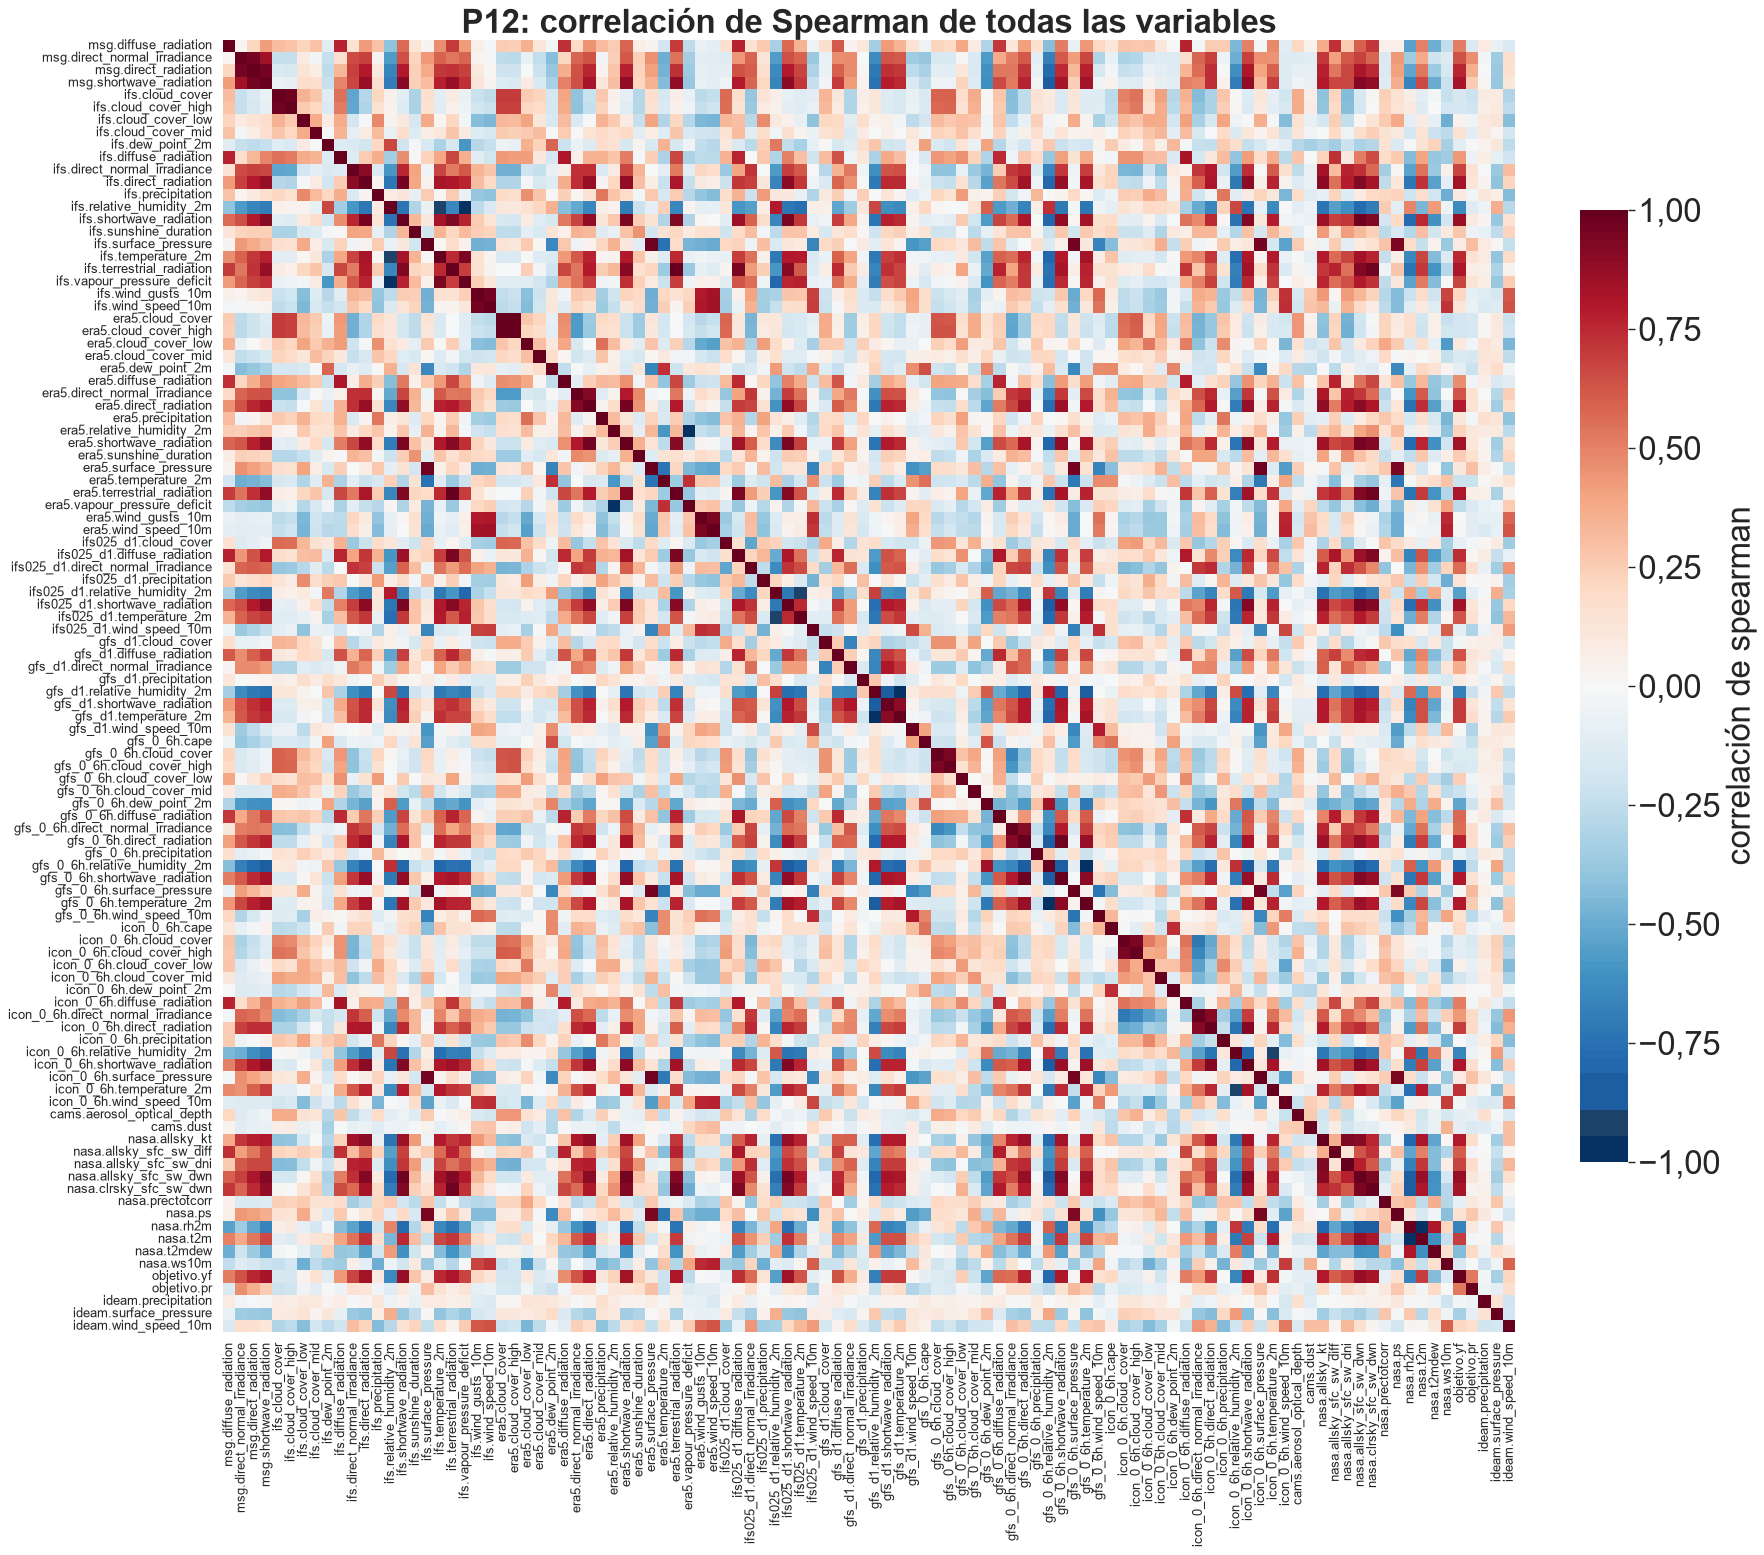

104 filas x 104 columnas; primeras 10:


,msg.diffuse_radiation,msg.direct_normal_irradiance,msg.direct_radiation,msg.shortwave_radiation,ifs.cloud_cover,ifs.cloud_cover_high,ifs.cloud_cover_low,ifs.cloud_cover_mid,ifs.dew_point_2m,ifs.diffuse_radiation,ifs.direct_normal_irradiance,ifs.direct_radiation,ifs.precipitation,ifs.relative_humidity_2m,ifs.shortwave_radiation,ifs.sunshine_duration,ifs.surface_pressure,ifs.temperature_2m,ifs.terrestrial_radiation,ifs.vapour_pressure_deficit,...,icon_0_6h.temperature_2m,icon_0_6h.wind_speed_10m,cams.aerosol_optical_depth,cams.dust,nasa.allsky_kt,nasa.allsky_sfc_sw_diff,nasa.allsky_sfc_sw_dni,nasa.allsky_sfc_sw_dwn,nasa.clrsky_sfc_sw_dwn,nasa.prectotcorr,nasa.ps,nasa.rh2m,nasa.t2m,nasa.t2mdew,nasa.ws10m,objetivo.yf,objetivo.pr,ideam.precipitation,ideam.surface_pressure,ideam.wind_speed_10m
msg.diffuse_radiation,1.0000,0.0196,0.2147,0.4218,0.3116,0.2884,0.2251,0.2929,-0.1156,0.7701,0.1420,0.4279,0.2951,-0.4033,0.5699,0.1296,0.0267,0.4618,0.7020,0.4253,...,0.4837,-0.1165,0.2065,0.0331,0.3683,0.7290,0.2618,0.5968,0.7123,0.0479,0.0622,-0.5394,0.5007,-0.4883,-0.2458,0.5096,-0.1442,0.0903,-0.0842,-0.1455
msg.direct_normal_irradiance,0.0196,1.0000,0.9555,0.8469,-0.2292,-0.2409,0.0913,-0.0261,-0.2327,0.1650,0.6537,0.6822,0.0278,-0.5634,0.6470,0.2206,0.4312,0.5922,0.5346,0.5803,...,0.4473,-0.1396,-0.1319,-0.1106,0.7036,0.4071,0.6223,0.6825,0.5804,-0.1450,0.4329,-0.3559,0.3754,-0.2073,-0.1261,0.6405,0.4680,-0.0349,-0.3522,0.1701
msg.direct_radiation,0.2147,0.9555,1.0000,0.9595,-0.1516,-0.1699,0.1385,0.0734,-0.2523,0.3291,0.6846,0.7986,0.0965,-0.6576,0.8035,0.2358,0.3760,0.7080,0.7227,0.6819,...,0.5882,-0.1299,-0.0890,-0.0895,0.7755,0.5372,0.6666,0.8180,0.7433,-0.1483,0.4089,-0.5284,0.5337,-0.3660,-0.1703,0.7585,0.3665,-0.0099,-0.3749,0.1593
msg.shortwave_radiation,0.4218,0.8469,0.9595,1.0000,-0.0647,-0.0879,0.1802,0.1654,-0.2321,0.4868,0.6685,0.8621,0.1671,-0.6967,0.9108,0.2389,0.3057,0.7746,0.8747,0.7292,...,0.6922,-0.1321,-0.0441,-0.0757,0.8042,0.6643,0.6671,0.9155,0.8817,-0.1313,0.3663,-0.6663,0.6588,-0.4979,-0.2264,0.8325,0.2528,0.0091,-0.3752,0.1185
ifs.cloud_cover,0.3116,-0.2292,-0.1516,-0.0647,1.0000,0.9842,0.3466,0.2789,-0.1174,0.5546,-0.5247,-0.2884,0.2162,0.0497,-0.1132,-0.3136,0.1709,-0.1075,0.0781,-0.0663,...,-0.0944,-0.1930,0.3792,0.0659,-0.3996,0.2222,-0.4390,-0.1651,0.0110,0.2416,0.1535,0.0636,-0.1034,-0.0296,-0.2297,-0.1671,-0.2136,0.0841,0.0936,-0.2978
ifs.cloud_cover_high,0.2884,-0.2409,-0.1699,-0.0879,0.9842,1.0000,0.2638,0.2065,-0.1415,0.5231,-0.5229,-0.3032,0.1547,0.0403,-0.1348,-0.3155,0.1494,-0.1108,0.0495,-0.0600,...,-0.1077,-0.1603,0.3706,0.0849,-0.3954,0.2022,-0.4287,-0.1722,0.0014,0.2298,0.1345,0.0939,-0.1300,-0.0010,-0.1841,-0.1777,-0.1997,0.0714,0.0986,-0.2640
ifs.cloud_cover_low,0.2251,0.0913,0.1385,0.1802,0.3466,0.2638,1.0000,0.3726,0.0848,0.3737,-0.1829,-0.0139,0.4793,0.0382,0.0966,-0.1669,0.3817,0.0200,0.2137,-0.0244,...,-0.0180,-0.4376,0.1430,-0.0715,-0.1735,0.2441,-0.2434,0.0158,0.1353,0.2637,0.3771,-0.0940,0.0792,-0.0936,-0.4855,0.0461,-0.0458,0.1026,0.1359,-0.4286
ifs.cloud_cover_mid,0.2929,-0.0261,0.0734,0.1654,0.2789,0.2065,0.3726,1.0000,-0.0152,0.3366,-0.0973,0.0845,0.3167,-0.0705,0.1750,-0.1354,0.0772,0.1111,0.2761,0.0850,...,0.1338,-0.2105,0.1299,-0.0346,-0.0005,0.1997,-0.0503,0.1683,0.2414,0.1415,0.0976,-0.1775,0.1386,-0.2164,-0.2595,0.1407,-0.1019,0.0947,0.0284,-0.1901
ifs.dew_point_2m,-0.1156,-0.2327,-0.2523,-0.2321,-0.1174,-0.1415,0.0848,-0.0152,1.0000,-0.1333,-0.1464,-0.1921,0.2067,0.6667,-0.1954,-0.0194,-0.1606,-0.3191,-0.1652,-0.5860,...,-0.0483,-0.1017,-0.2831,-0.3316,-0.2887,-0.3459,-0.2121,-0.3148,-0.2848,0.1509,-0.1407,-0.0204,0.1426,0.2278,-0.3314,-0.1130,0.0033,0.0406,0.1144,-0.2605
ifs.diffuse_radiation,0.7701,0.1650,0.3291,0.4868,0.5546,0.5231,0.3737,0.3366,-0.1333,1.0000,-0.1385,0.2528,0.3615,-0.3514,0.4681,0.0047,0.2331,0.3878,0.6715,0.3671,...,0.3722,-0.2676,0.2757,-0.0039,0.2342,0.7279,0.1052,0.5124,0.6488,0.1846,0.2613,-0.4311,0.3971,-0.3876,-0.3520,0.4353,-0.0584,0.0742,-0.09

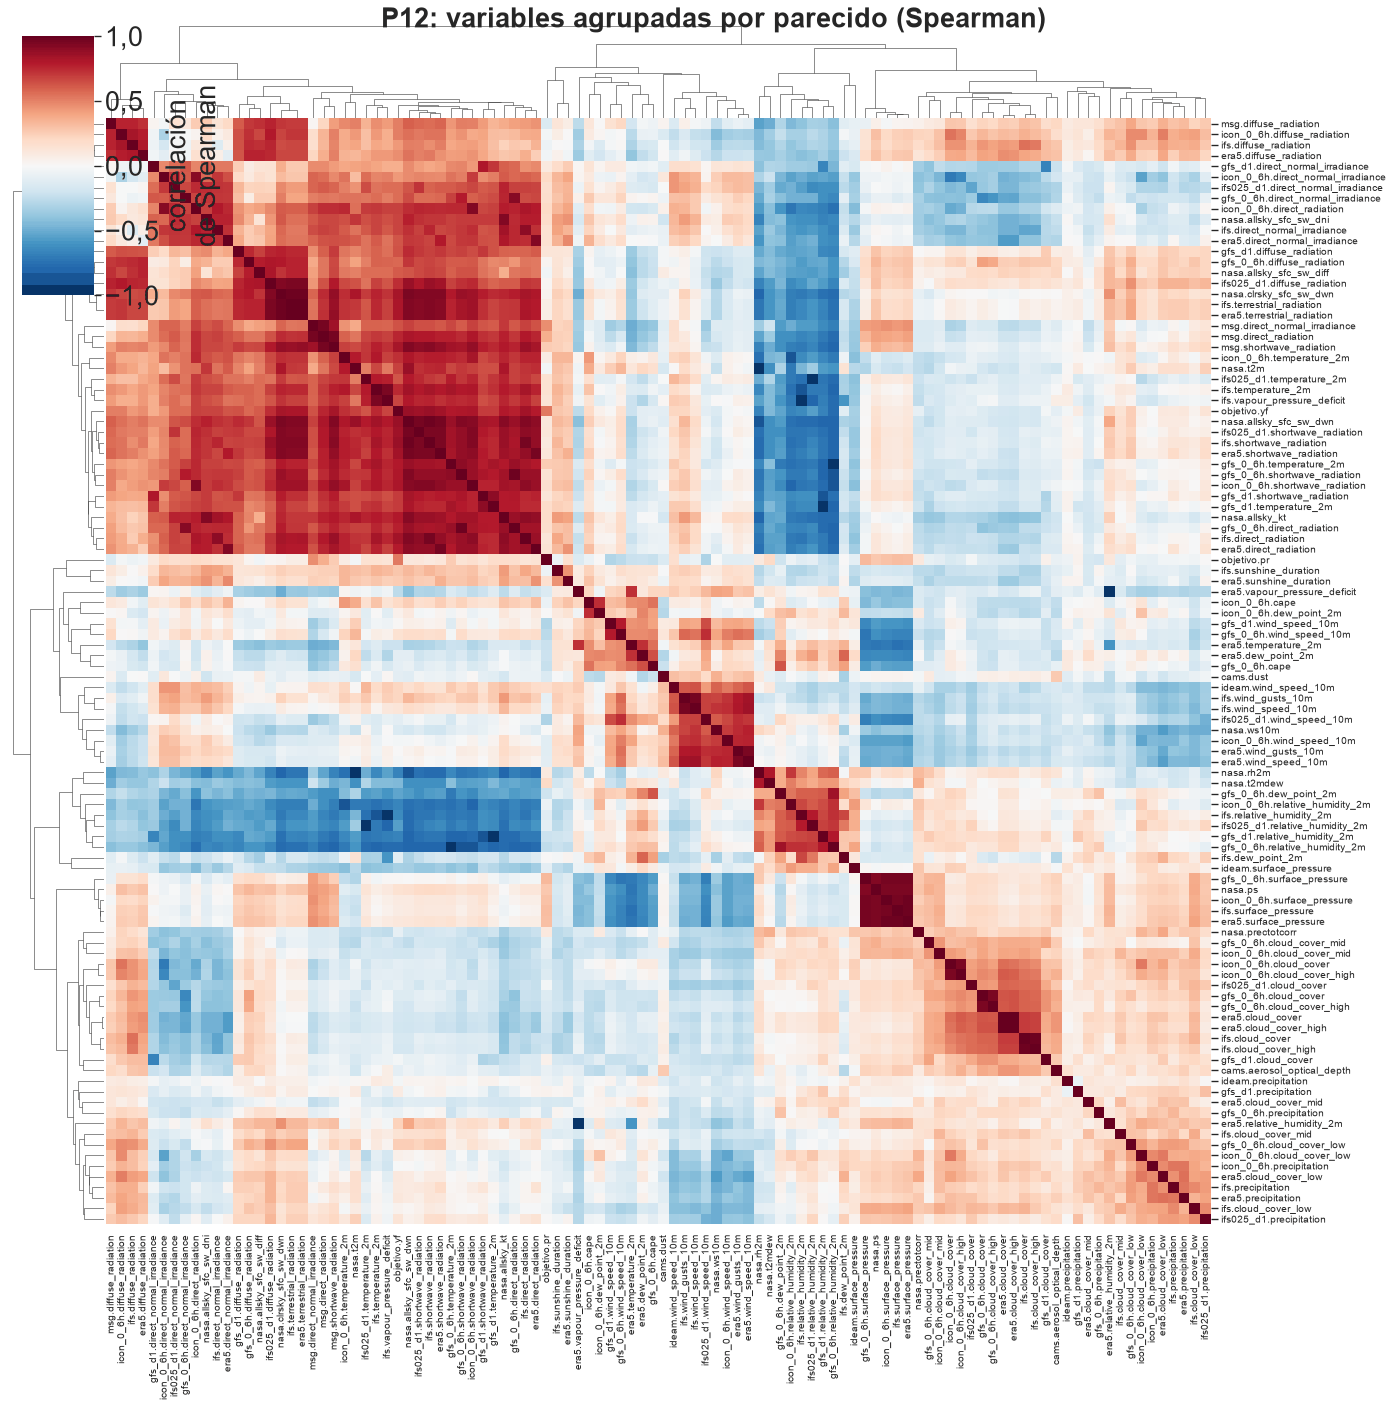

104 filas x 104 columnas; primeras 10:


,msg.diffuse_radiation,icon_0_6h.diffuse_radiation,ifs.diffuse_radiation,era5.diffuse_radiation,gfs_d1.direct_normal_irradiance,icon_0_6h.direct_normal_irradiance,ifs025_d1.direct_normal_irradiance,gfs_0_6h.direct_normal_irradiance,icon_0_6h.direct_radiation,nasa.allsky_sfc_sw_dni,ifs.direct_normal_irradiance,era5.direct_normal_irradiance,gfs_d1.diffuse_radiation,gfs_0_6h.diffuse_radiation,nasa.allsky_sfc_sw_diff,ifs025_d1.diffuse_radiation,nasa.clrsky_sfc_sw_dwn,ifs.terrestrial_radiation,era5.terrestrial_radiation,msg.direct_normal_irradiance,...,era5.cloud_cover,era5.cloud_cover_high,ifs.cloud_cover,ifs.cloud_cover_high,gfs_d1.cloud_cover,cams.aerosol_optical_depth,ideam.precipitation,gfs_d1.precipitation,era5.cloud_cover_mid,gfs_0_6h.precipitation,era5.relative_humidity_2m,ifs.cloud_cover_mid,gfs_0_6h.cloud_cover_low,icon_0_6h.cloud_cover_low,icon_0_6h.precipitation,era5.cloud_cover_low,ifs.precipitation,era5.precipitation,ifs.cloud_cover_low,ifs025_d1.precipitation
msg.diffuse_radiation,1.0000,0.7666,0.7701,0.7340,0.0260,-0.0238,0.1520,0.1152,0.2516,0.2618,0.1420,0.2008,0.6141,0.7056,0.7290,0.7677,0.7123,0.7020,0.6990,0.0196,...,0.2517,0.2369,0.3116,0.2884,0.1748,0.2065,0.0903,0.1202,0.1226,0.1623,0.2554,0.2929,0.3868,0.2740,0.2526,0.3583,0.2951,0.3149,0.2251,0.2598
icon_0_6h.diffuse_radiation,0.7666,1.0000,0.8277,0.7860,-0.0435,-0.3158,-0.0029,-0.0044,0.0331,0.1939,0.0538,0.1000,0.6410,0.7332,0.6669,0.8013,0.6793,0.7129,0.7121,0.1781,...,0.3179,0.2994,0.3547,0.3143,0.2701,0.1795,0.1087,0.1344,0.0635,0.2147,0.3406,0.3051,0.4704,0.4756,0.3481,0.5089,0.3648,0.3963,0.4102,0.3122
ifs.diffuse_radiation,0.7701,0.8277,1.0000,0.8051,-0.0542,-0.1795,-0.0046,-0.0615,0.1142,0.1052,-0.1385,0.0610,0.6328,0.7477,0.7279,0.7591,0.6488,0.6715,0.6704,0.1650,...,0.4303,0.4152,0.5546,0.5231,0.3079,0.2757,0.0742,0.1211,0.1052,0.1926,0.2751,0.3366,0.4591,0.3070,0.3123,0.4181,0.3615,0.3543,0.3737,0.2705
era5.diffuse_radiation,0.7340,0.7860,0.8051,1.0000,-0.0348,-0.1092,0.0183,-0.0368,0.1614,0.1313,0.0690,-0.1034,0.6267,0.7686,0.7657,0.7563,0.6700,0.6657,0.6657,0.2140,...,0.4614,0.4502,0.3945,0.3718,0.3084,0.2961,0.0659,0.0961,0.0186,0.1678,0.3096,0.2532,0.3713,0.2406,0.2293,0.3890,0.2391,0.3239,0.3129,0.2152
gfs_d1.direct_normal_irradiance,0.0260,-0.0435,-0.0542,-0.0348,1.0000,0.4780,0.5581,0.6231,0.4992,0.5918,0.5263,0.5257,0.2449,0.0831,0.1355,0.1466,0.3646,0.2605,0.2619,0.4743,...,-0.3534,-0.3552,-0.3035,-0.2996,-0.6688,-0.2217,-0.0164,-0.1506,-0.1985,-0.1603,-0.0398,-0.1432,-0.1396,-0.1652,-0.0996,-0.2093,-0.0380,-0.1355,-0.1170,-0.0126
icon_0_6h.direct_normal_irradiance,-0.0238,-0.3158,-0.1795,-0.1092,0.4780,1.0000,0.7044,0.6164,0.9115,0.5753,0.7141,0.6463,0.1889,0.0997,0.1762,0.1423,0.3180,0.2755,0.2776,0.5855,...,-0.4736,-0.4655,-0.4337,-0.4113,-0.2699,-0.1847,-0.0937,-0.0935,-0.2061,-0.2129,-0.0859,-0.1664,-0.2203,-0.5423,-0.3499,-0.3996,-0.1964,-0.2623,-0.3206,-0.1179
ifs025_d1.direct_normal_irradiance,0.1520,-0.0029,-0.0046,0.0183,0.5581,0.7044,1.0000,0.6696,0.7430,0.7400,0.7263,0.7156,0.3357,0.2259,0.2276,0.2219,0.4783,0.4292,0.4292,0.5800,...,-0.4623,-0.4538,-0.3844,-0.3683,-0.3378,-0.3105,-0.0640,-0.1408,-0.2134,-0.2184,0.0248,-0.1139,-0.1594,-0.2980,-0.2978,-0.3119,-0.2136,-0.2910,-0.2760,-0.2513
gfs_0_6h.direct_normal_irradiance,0.1152,-0.0044,-0.0615,-0.0368,0.6231,0.6164,0.6696,1.0000,0.6727,0.7128,0.7138,0.7107,0.3032,0.0704,0.2577,0.2566,0.5079,0.3913,0.3915,0.5154,...,-0.5207,-0.5261,-0.4296,-0.4165,-0.3713,-0.3020,-0.0184,-0.1306,-0.2097,-0.2459,-0.0569,-0.0855,-0.2441,-0.1985,-0.2153,-0.1934,-0.1917,-0.1999,-0.2431,-0.0880
icon_0_6h.direct_radiation,0.2516,0.0331,0.1142,0.1614,0.4992,0.9115,0.7430,0.6727,1.0000,0.6915,0.7976,0.7534,0.4472,0.3797,0.4109,0.4777,0.6105,0.5977,0.5993,0.6812,...,-0.3774,-0.3756,-0.3176,-0.3129,-0.1952,-0.1286,-0.0569,-0.0449,-0.1812,-0.1478,0.0567,-0.0092,-0.0236,-0.3350,-0.2359,-0.2115,-0.0546,-0.1075,-0.1716,0.0225
nasa.allsky_sfc_sw_dni,0.2618,0.1939,0.1052,0.1313,0.5918,0.5753,0.7400,0.7128,

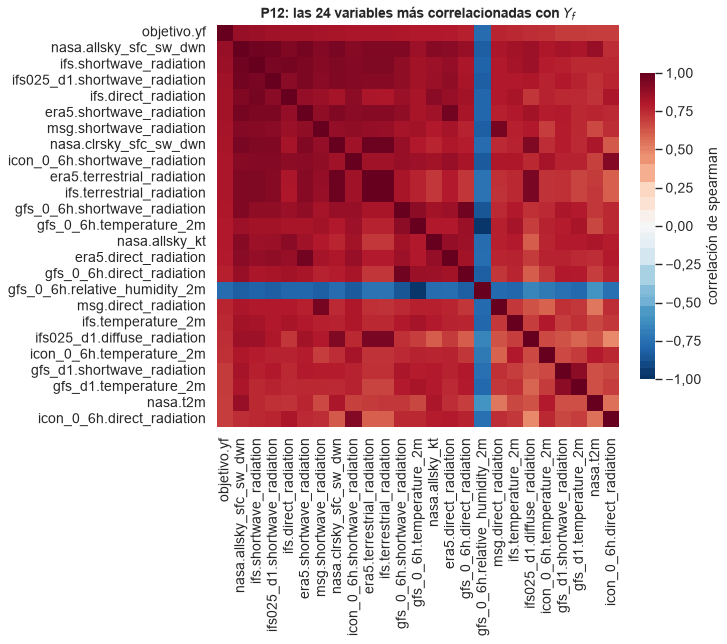

25 filas x 25 columnas; primeras 10:


,objetivo.yf,nasa.allsky_sfc_sw_dwn,ifs.shortwave_radiation,ifs025_d1.shortwave_radiation,ifs.direct_radiation,era5.shortwave_radiation,msg.shortwave_radiation,nasa.clrsky_sfc_sw_dwn,icon_0_6h.shortwave_radiation,era5.terrestrial_radiation,ifs.terrestrial_radiation,gfs_0_6h.shortwave_radiation,gfs_0_6h.temperature_2m,nasa.allsky_kt,era5.direct_radiation,gfs_0_6h.direct_radiation,gfs_0_6h.relative_humidity_2m,msg.direct_radiation,ifs.temperature_2m,ifs025_d1.diffuse_radiation,icon_0_6h.temperature_2m,gfs_d1.shortwave_radiation,gfs_d1.temperature_2m,nasa.t2m,icon_0_6h.direct_radiation
objetivo.yf,1.0000,0.8722,0.8667,0.8441,0.8427,0.8378,0.8325,0.8220,0.8196,0.8171,0.8163,0.8099,0.8027,0.7993,0.7940,0.7739,-0.7682,0.7585,0.7535,0.7395,0.7274,0.7002,0.6994,0.6953,0.6888
nasa.allsky_sfc_sw_dwn,0.8722,1.0000,0.9712,0.9658,0.9244,0.9569,0.9155,0.9515,0.9077,0.9292,0.9289,0.9240,0.8578,0.9080,0.8991,0.8707,-0.8258,0.8180,0.8410,0.8553,0.8054,0.8305,0.8128,0.8735,0.7378
ifs.shortwave_radiation,0.8667,0.9712,1.0000,0.9516,0.9598,0.9402,0.9108,0.9368,0.9195,0.9324,0.9321,0.8863,0.8403,0.8576,0.8755,0.8175,-0.8090,0.8035,0.8330,0.8558,0.7842,0.7775,0.7528,0.7523,0.7565
ifs025_d1.shortwave_radiation,0.8441,0.9658,0.9516,1.0000,0.9001,0.9407,0.9040,0.9232,0.9215,0.9123,0.9123,0.8842,0.8375,0.8641,0.8837,0.8208,-0.8213,0.7991,0.8010,0.8063,0.7665,0.8003,0.7688,0.7317,0.7629
ifs.direct_radiation,0.8427,0.9244,0.9598,0.9001,1.0000,0.8827,0.8621,0.8315,0.8980,0.8126,0.8121,0.8610,0.8253,0.9035,0.8694,0.8374,-0.7933,0.7986,0.8260,0.7127,0.7673,0.7531,0.7454,0.7196,0.8172
era5.shortwave_radiation,0.8378,0.9569,0.9402,0.9407,0.8827,1.0000,0.8873,0.9222,0.9051,0.9111,0.9110,0.8875,0.8281,0.8446,0.9649,0.8259,-0.7928,0.7782,0.7996,0.8363,0.7873,0.7909,0.7543,0.7596,0.7494
msg.shortwave_radiation,0.8325,0.9155,0.9108,0.9040,0.8621,0.8873,1.0000,0.8817,0.8829,0.8773,0.8747,0.8349,0.8377,0.8042,0.8291,0.7701,-0.8234,0.9595,0.7746,0.8018,0.6922,0.7878,0.7531,0.6588,0.7355
nasa.clrsky_sfc_sw_dwn,0.8220,0.9515,0.9368,0.9232,0.8315,0.9222,0.8817,1.0000,0.8466,0.9822,0.9821,0.8738,0.7999,0.7635,0.8094,0.7822,-0.7712,0.7433,0.7707,0.9350,0.7399,0.7844,0.7469,0.8194,0.6105
icon_0_6h.shortwave_radiation,0.8196,0.9077,0.9195,0.9215,0.8980,0.9051,0.8829,0.8466,1.0000,0.8465,0.8454,0.8736,0.8541,0.8362,0.8739,0.8235,-0.8400,0.8076,0.8088,0.7573,0.8287,0.7732,0.7657,0.6838,0.9180
era5.terrestrial_radiation,0.8171,0.9292,0.9324,0.9123,0.8126,0.9111,0.8773,0.9822,0.8465,1.0000,0.9999,0.8275,0.7703,0.7084,0.7940,0.7151,-0.7399,0.7267,0.7549,0.9473,0.7220,0.7293,0.6796,0.7020,0.5993


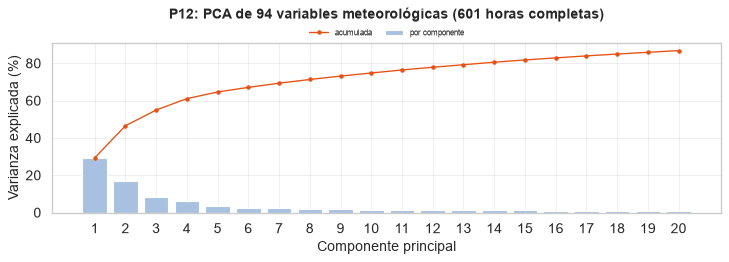

94 filas x 2 columnas; primeras 10:


,varianza_pct,acumulada_pct
CP1,29.3787,29.3787
CP2,17.1715,46.5502
CP3,8.4309,54.9811
CP4,6.1070,61.0881
CP5,3.5526,64.6407
CP6,2.4769,67.1176
CP7,2.2399,69.3574
CP8,1.9902,71.3477
CP9,1.8194,73.1670
CP10,1.6510,74.8180


**Cargas de las tres primeras componentes** (las 10 variables de mayor peso en cada una)

CP1                                CP2                                  CP3       
                        variable  carga                    variable  carga                      variable  carga
0  icon_0_6h.shortwave_radiation  0.181        ifs.surface_pressure  0.181     gfs_0_6h.surface_pressure  0.230
1  ifs025_d1.shortwave_radiation  0.181       era5.surface_pressure  0.181       gfs_0_6h.wind_speed_10m -0.221
2        ifs.shortwave_radiation  0.181                     nasa.ps  0.177    icon_0_6h.surface_pressure  0.217
3       era5.shortwave_radiation  0.179         era5.wind_speed_10m -0.177         era5.surface_pressure  0.204
4   gfs_0_6h.shortwave_radiation  0.178         era5.wind_gusts_10m -0.174          ifs.surface_pressure  0.203
5           ifs.direct_radiation  0.178   gfs_0_6h.surface_pressure  0.171         gfs_d1.wind_speed_10m -0.192
6        msg.shortwave_radiation  0.173    icon_0_6h.wind_speed_10m -0.171                       nasa.ps  0.190
7          era5.direct_radiation  0.173  icon_0_6h.surface_pressure  0.169         msg.diffuse_radiation -0.183
8        gfs_0_6h.temperature_2m  0.172         era5.temperature_2m -0.165  msg.direct_normal_irradiance  0.179
9  gfs_0_6h.relative_humidity_2m -0.171          ifs.wind_speed_10m -0.165         icon_0_6h.cloud_cover -0.177

**Observación.** Hay 4 pares de variables prácticamente idénticos (|r| ≥ 0,99), casi siempre la misma magnitud en dos fuentes o una magnitud y otra derivada de ella (por ejemplo, la radiación de cielo despejado de varias fuentes). Las tres primeras componentes explican el 55 % de la varianza de las variables meteorológicas; su correlación con Yf es 0,86, 0,08 y -0,11. Las variables más correlacionadas con Yf son `nasa.allsky_sfc_sw_dwn`, `ifs.shortwave_radiation`, `ifs025_d1.shortwave_radiation`, `ifs.direct_radiation`, `era5.shortwave_radiation`.

In [36]:
# Sección 6.3. Correlación de todas las variables contra todas
if MODELABLE:
    SOL_M = mascara_modelado(n0) & (part.etiquetar(OBJ_H[n0].index).to_numpy() == "entrenamiento")
    extra_m = {"objetivo": OBJ_H[n0][["yf", "pr"]], "inversor": TEL_H.get(n0, pd.DataFrame())}
    if len(IDEAM_H):
        extra_m["ideam"] = IDEAM_H
    TODAS = caract.matriz_todas_las_fuentes(crudos, extra_m).reindex(OBJ_H[n0].index)[SOL_M]
    # Con pocas semanas de entrenamiento (unidades recientes) el mínimo de horas por variable se reduce a la mitad
    # de la muestra; el objetivo siempre se conserva
    MIN_H = min(200, int(0.5 * len(TODAS)))
    TODAS = TODAS.loc[:, (TODAS.notna().sum() > MIN_H) | (TODAS.columns == "objetivo.yf")]
    TODAS = TODAS.loc[:, (TODAS.std() > 0) | (TODAS.columns == "objetivo.yf")]
    C_P, C_S = TODAS.corr("pearson", min_periods=min(100, MIN_H)), TODAS.corr("spearman", min_periods=min(100, MIN_H))
    display(Markdown(f"**{TODAS.shape[1]} variables** en {TODAS.shape[0]} horas de sol del entrenamiento de {n0}."))
    rank = pd.DataFrame({"pearson_con_yf": C_P["objetivo.yf"], "spearman_con_yf": C_S["objetivo.yf"],
                         "horas": TODAS.notna().sum()}).drop(index=["objetivo.yf"]).sort_values("spearman_con_yf", key=np.abs, ascending=False)
    display(Markdown("**Correlación de cada variable con Yf** (ordenada por |Spearman|)")); display(rank.head(25).round(3))
    # gr.mostrar(rank, todas=True)   # todas las variables
    REDUNDANTES = caract.pares_redundantes(C_P, 0.99)
    display(Markdown(f"**Pares con |r| ≥ 0,99** ({len(REDUNDANTES)}): de cada par basta con una variable.")); display(REDUNDANTES.head(25).round(4))
    # gr.mostrar(REDUNDANTES, todas=True)
    fig(gr.mapa_correlacion(TODAS, "pearson", f"{n0}: correlación de Pearson de todas las variables (horas de sol del entrenamiento)",
                            anotar=False), f"correlacion_todas_pearson_{n0}", C_P)
    fig(gr.mapa_correlacion(TODAS, "spearman", f"{n0}: correlación de Spearman de todas las variables", anotar=False),
        f"correlacion_todas_spearman_{n0}", C_S)
    import seaborn as sns
    with plt.rc_context({"figure.constrained_layout.use": False}):     # clustermap usa su propia disposicón
        cl = sns.clustermap(C_S.fillna(0), cmap="RdBu_r", vmin=-1, vmax=1, figsize=(18, 18), xticklabels=True, yticklabels=True,
                            cbar_kws={"label": "correlación de Spearman"}, dendrogram_ratio=0.08)
    cl.ax_heatmap.tick_params(labelsize=5); cl.fig.suptitle(f"{n0}: variables agrupadas por parecido (Spearman)", y=1.0)
    fig(cl.fig, f"correlacion_todas_agrupada_{n0}", C_S.iloc[cl.dendrogram_row.reordered_ind, cl.dendrogram_col.reordered_ind])
    top = rank.index[:24].tolist()
    fig(gr.mapa_correlacion(TODAS[["objetivo.yf"] + top], "spearman", f"{n0}: las 24 variables más correlacionadas con Yf"),
        f"correlacion_top_yf_{n0}", TODAS[["objetivo.yf"] + top].corr("spearman"))

    # PCA de las variables meteorológicas (estandarizadas, horas completas)
    from sklearn.decomposition import PCA
    meteo_cols = [c for c in TODAS.columns if not c.startswith(("objetivo.", "inversor."))]
    Zm = TODAS[meteo_cols].dropna(axis=1, thresh=int(0.8 * len(TODAS))).dropna()
    Zm = Zm.loc[:, Zm.std() > 0]                           # una variable constante no tiene escala (divisón por 0)
    Zm = (Zm - Zm.mean()) / Zm.std()
    pca = PCA(random_state=config.SEMILLA).fit(Zm)
    var_exp = pd.Series(pca.explained_variance_ratio_, index=[f"CP{i + 1}" for i in range(len(pca.explained_variance_ratio_))])
    k20 = min(20, len(var_exp))
    f, ax = plt.subplots(figsize=(9, 3.2))
    ax.bar(range(1, k20 + 1), 100 * var_exp.iloc[:k20], color=config.COLOR_TENUE, label="por componente")
    ax.plot(range(1, k20 + 1), 100 * var_exp.cumsum().iloc[:k20], marker="o", color=config.COLOR_PRINCIPAL, label="acumulada")
    ax.set_xlabel("Componente principal"); ax.set_ylabel("Varianza explicada (%)"); ax.legend(); ax.set_xticks(range(1, k20 + 1))
    ax.set_title(f"{n0}: PCA de {Zm.shape[1]} variables meteorológicas ({len(Zm)} horas completas)")
    fig(f, f"pca_meteo_{n0}", pd.DataFrame({"varianza_pct": 100 * var_exp, "acumulada_pct": 100 * var_exp.cumsum()}))
    cargas = pd.DataFrame(pca.components_[:3].T, index=Zm.columns, columns=["CP1", "CP2", "CP3"])
    display(Markdown("**Cargas de las tres primeras componentes** (las 10 variables de mayor peso en cada una)"))
    display(pd.concat({k: cargas[k].reindex(cargas[k].abs().sort_values(ascending=False).index[:10]).reset_index()
                       .rename(columns={"index": "variable", k: "carga"}) for k in cargas}, axis=1).round(3))
    proy = pca.transform(Zm)
    corr_cp = pd.Series({k: np.corrcoef(proy[:, i], TODAS.loc[Zm.index, "objetivo.yf"])[0, 1] for i, k in enumerate(["CP1", "CP2", "CP3"])})
    display(Markdown(
        f"**Observación.** Hay {len(REDUNDANTES)} pares de variables prácticamente idénticos (|r| ≥ 0,99), casi siempre la "
        f"misma magnitud en dos fuentes o una magnitud y otra derivada de ella (por ejemplo, la radiación de cielo despejado "
        f"de varias fuentes). Las tres primeras componentes explican el {100 * var_exp.iloc[:3].sum():.0f} % de la varianza de "
        f"las variables meteorológicas; su correlación con Yf es {corr_cp['CP1']:.2f}, {corr_cp['CP2']:.2f} y "
        f"{corr_cp['CP3']:.2f}. Las variables más correlacionadas con Yf son "
        f"{', '.join(f'`{v}`' for v in rank.index[:5])}."))
    rank_m = rank.loc[[i for i in rank.index if not i.startswith(("objetivo.", "inversor."))], "spearman_con_yf"]
    registrar_unidad("correlacion_todas", {"variables": int(TODAS.shape[1]), "horas": int(TODAS.shape[0]),
                  "variables_meteorologicas": len(meteo_cols),
                  "variables_telemetria": int(sum(c.startswith("inversor.") for c in TODAS.columns)),
                  "pares_099": int(len(REDUNDANTES)), "top_spearman_yf": rank["spearman_con_yf"].head(10).round(4).to_dict(),
                  "top_spearman_yf_meteo": rank_m.head(10).round(4).to_dict(),
                  "max_abs_spearman_yf_meteo": float(rank_m.abs().max()),
                  "pca_varianza_1": float(var_exp.iloc[0]), "pca_varianza_3": float(var_exp.iloc[:3].sum())})

### 6.4. Telemetría del inversor: correlación entre sus variables y con la meteorología

La matriz anterior tiene demasiadas variables para leerla. Aquí se separan dos bloques: la correlación de
Spearman entre el objetivo y las variables horarias de la telemetría de la unidad principal (potencias,
tensiones y corrientes de cada MPPT, temperatura del inversor), y la de esas mismas variables con las doce
variables meteorológicas más asociadas con Yf. Las tensiones del MPPT importan por otra razón: delatan la
limitación de inyección (2.4), porque con el recorte la tensión sube aunque la potencia baje.

In [37]:
# Sección 6.4. Telemetría del inversor: correlación entre sus variables y con la meteorología
if MODELABLE:
    # Solo las variables con sentido físico: fuera los contadores de energía, la frecuencia, las tensiones de fase y las
    # marcas del análisis (corregida, falla, estado); si el inversor informa por MPPT, sus cadenas (pvN) repiten la misma
    # información por entrada y también quedan fuera
    EXCLUIR_TEL = ("yield", "output", "energy", "frequency", "acvoltage", "l1l2", "l2l3", "l1l3", "accurrent", "corregida",
                   "falla", "status")
    tel_ = [c for c in TODAS.columns if c.startswith("inversor.") and not any(x in c for x in EXCLUIR_TEL)]
    if any("mppt" in c for c in tel_):
        tel_ = [c for c in tel_ if not re.match(r"inversor\.pv\d+", c)]
    TEL_COLS = [c for c in ("objetivo.yf", "objetivo.pr") if c in TODAS.columns] + tel_
    if len(TEL_COLS) > 2:
        C_TEL = TODAS[TEL_COLS].corr("spearman", min_periods=min(100, MIN_H))
        fig(gr.mapa_correlacion(TODAS[TEL_COLS], "spearman", f"{n0}: correlación de Spearman de la telemetría (horas de sol del entrenamiento)"),
            f"correlacion_telemetria_{n0}", C_TEL)
        TOP_M = rank_m.index[:12].tolist()
        C_TM = TODAS[TEL_COLS + TOP_M].corr("spearman", min_periods=min(100, MIN_H)).loc[TEL_COLS, TOP_M]
        f, ax = plt.subplots(figsize=(1.5 + 0.62 * len(TOP_M), 1.2 + 0.42 * len(TEL_COLS)))
        sns.heatmap(C_TM, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"fontsize": 7},
                    cbar_kws={"shrink": 0.7, "label": "correlación de Spearman"})
        ax.tick_params(labelsize=8); ax.set_title(f"{n0}: telemetría frente a las 12 variables meteorológicas más asociadas con Yf")
        fig(f, f"correlacion_telemetria_meteo_{n0}", C_TM)
        # Para cada variable de la telemetría, la meteorológica con la que más se asocia
        abs_tm = C_TM.abs().fillna(0)
        ASOC = pd.DataFrame({"rho_con_yf": C_S["objetivo.yf"].reindex(TEL_COLS), "meteorologica_mas_asociada": abs_tm.idxmax(axis=1),
                             "rho": [C_TM.loc[v, abs_tm.loc[v].idxmax()] for v in TEL_COLS]})
        display(ASOC.round(3))
        electricas = ASOC.drop(index=[c for c in TEL_COLS if c.startswith("objetivo.") or "temperature" in c], errors="ignore")["rho_con_yf"].dropna()
        temp_ = [c for c in TEL_COLS if "temperature" in c]
        display(Markdown(
            (f"**Observación.** Las variables eléctricas del inversor se asocian con Yf con ρ entre {electricas.min():.2f} y "
             f"{electricas.max():.2f}: las de potencia y corriente son la producción medida, no predictores del día siguiente. " if len(electricas) else "")
            + (f"La temperatura del inversor se asocia sobre todo con `{ASOC.loc[temp_[0], 'meteorologica_mas_asociada']}` "
               f"(ρ = {ASOC.loc[temp_[0], 'rho']:.2f}), porque depende de la potencia que convierte y del ambiente." if temp_ else "")))
        registrar_unidad("correlacion_telemetria", {"variables": TEL_COLS, "rho_con_yf": ASOC["rho_con_yf"].round(4).to_dict(),
                         "meteorologica_mas_asociada": ASOC["meteorologica_mas_asociada"].to_dict(), "rho": ASOC["rho"].round(4).to_dict()})
    else:
        display(Markdown("Sin variables de telemetría con horas suficientes en el entrenamiento: no hay bloque que mostrar."))

Sin variables de telemetría con horas suficientes en el entrenamiento: no hay bloque que mostrar.

### 6.5. El objetivo junto a las variables meteorológicas

Las correlaciones resumen la relación en un número; las series la muestran. Se grafican, con el eje de
tiempo compartido y cada variable en su propio panel (nunca dos escalas en un mismo eje), el Yf horario
de la unidad principal, el Yr observado (E1) y el pronosticado el día anterior (E2), la nubosidad y la
temperatura, en dos semanas de la validación y en valores diarios durante todo el periodo. La vista horaria se
dibuja en la sección 9.1, cuando ya existe el pronóstico del día anterior del SARIMAX E2-MOS, que se agrega al
panel de Yf. El Yf tiene huecos porque es telemetría medida: una hora sin lecturas suficientes queda vacía,
mientras que los productos meteorológicos no tienen huecos.

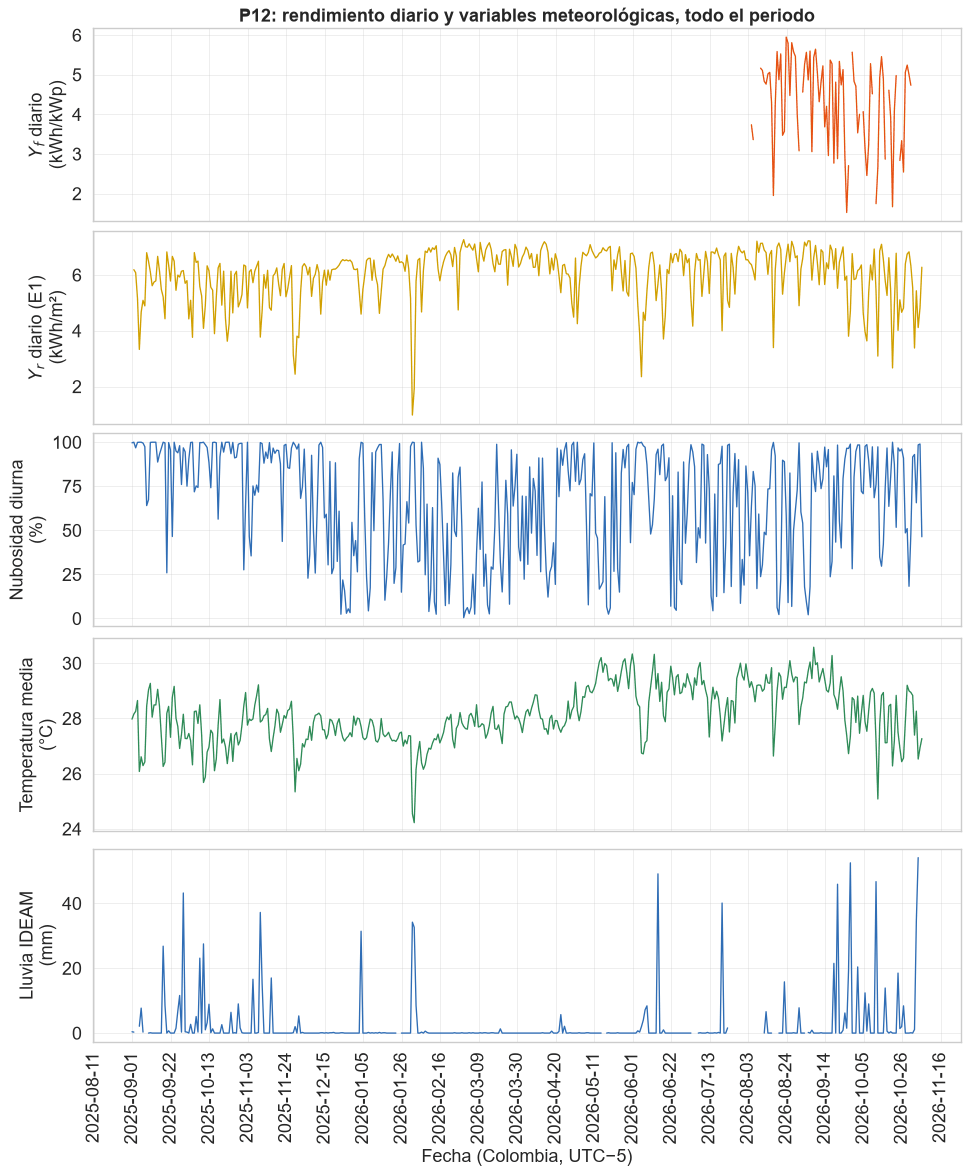

432 filas x 5 columnas; primeras 10:


,yf,yr_e1,nubosidad_media_dia,temperatura_media,lluvia_ideam_mm
2025-09-01,NaN,NaN,99.6667,27.9722,0.4
2025-09-02,NaN,6.1895,100.0000,28.1562,0.3
2025-09-03,NaN,6.0805,96.8182,28.2562,NaN
2025-09-04,NaN,5.1565,99.9091,28.6479,NaN
2025-09-05,NaN,3.3299,100.0000,26.0792,2.1
2025-09-06,NaN,4.6640,100.0000,26.6104,7.7
2025-09-07,NaN,5.0899,99.5455,26.2896,0.3
2025-09-08,NaN,4.8912,97.4545,26.4250,NaN
2025-09-09,NaN,6.7982,64.0455,28.4458,NaN
2025-09-10,NaN,6.4942,67.3636,29.0292,0.0


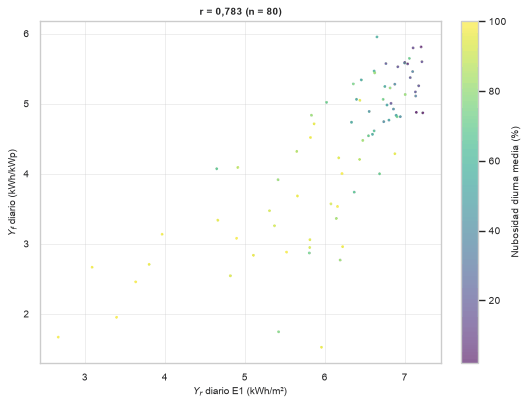

80 filas x 5 columnas; primeras 10:


,yf,yr_e1,nubosidad_media_dia,temperatura_media,lluvia_ideam_mm
2026-08-03,4.5418,6.5463,71.6364,29.5375,NaN
2026-08-05,3.7374,6.3688,63.6364,29.3292,NaN
2026-08-06,3.3617,6.1451,83.4091,29.0771,NaN
2026-08-10,5.1678,7.1337,23.7273,29.2000,NaN
2026-08-11,5.1090,7.1373,30.4091,28.9833,NaN
2026-08-12,4.8336,6.8924,48.9545,29.0625,0.0
2026-08-13,4.7644,6.8030,47.5000,29.5917,6.6
2026-08-14,5.0181,6.0228,73.4545,29.2896,0.0
2026-08-15,5.0616,6.7309,73.6364,29.2688,0.0
2026-08-16,4.2854,6.8769,95.6818,29.8375,0.0


**Observación.** Yf sigue a Yr día a día (correlación diaria 0,78) y ambos caen cuando sube la nubosidad (correlación de Yf con la nubosidad diurna -0,69). La temperatura media acompaña a la irradiancia (los días despejados son más cálidos), así que su efecto propio sobre el rendimiento (pérdidas por temperatura de módulo) queda en segundo plano frente a las nubes.

In [38]:
# Sección 6.5. El objetivo junto a las variables meteorológicas
if MODELABLE:
    X0e2, _ = candidatas(n0, inv0, "E2")
    val_idx = OBJ_H[n0].index[part.etiquetar(OBJ_H[n0].index).to_numpy() == "validacion"]
    v14 = slice(val_idx[0] + pd.Timedelta("7D"), val_idx[0] + pd.Timedelta("21D"))
    # Paneles meteorológicos de la vista horaria; la figura se dibuja en 9.1 con el pronóstico de Yf del SARIMAX E2-MOS
    PANELES_EXO = {"Yr": (pd.DataFrame({"observado (E1)": X0["yr_e1"].loc[v14], "pronóstico a un día (E2)": X0e2["yr_e2"].loc[v14]}), "h"),
               "Nubosidad": (pd.DataFrame({"observada (E1)": X0["cloud_cover"].loc[v14], "pronóstico a un día (E2)": X0e2["cloud_cover"].loc[v14]}), "%"),
               "Temperatura": (pd.DataFrame({"observada (E1)": X0["temperature_2m"].loc[v14],
                                             "pronóstico a un día (E2)": X0e2["temperature_2m"].loc[v14]}), "°C")}
    dia_l = part.dias_locales(OBJ_H[n0].index)
    diario_p = pd.DataFrame({"yf": OBJ_D[n0]["yf"].where(OBJ_D[n0]["en_regimen"]),
                             "yr_e1": X0["yr_e1"].groupby(dia_l).sum(min_count=20),
                             "nubosidad_media_dia": X0["cloud_cover"].where(OBJ_H[n0]["yr_cs"] > 0.05).groupby(dia_l).mean(),
                             "temperatura_media": X0["temperature_2m"].groupby(dia_l).mean()})
    if len(lluvia_ideam):
        diario_p["lluvia_ideam_mm"] = lluvia_ideam.reindex(pd.to_datetime(diario_p.index)).to_numpy()
    diario_p.index = pd.to_datetime(diario_p.index)
    paneles_d = {"Yf diario": (diario_p["yf"], "kWh/kWp"), "Yr diario (E1)": (diario_p["yr_e1"], "kWh/m²"),
                 "Nubosidad diurna": (diario_p["nubosidad_media_dia"], "%"), "Temperatura media": (diario_p["temperatura_media"], "°C")}
    if "lluvia_ideam_mm" in diario_p and diario_p["lluvia_ideam_mm"].notna().any():
        paneles_d["Lluvia IDEAM"] = (diario_p["lluvia_ideam_mm"], "mm")
    fig(gr.objetivo_y_exogenas(paneles_d, f"{n0}: rendimiento diario y variables meteorológicas, todo el periodo"),
        f"objetivo_exogenas_diario_{n0}", diario_p)
    ok_d = diario_p.dropna(subset=["yf", "yr_e1", "nubosidad_media_dia"])
    fig(gr.dispersion_coloreada(ok_d["yr_e1"], ok_d["yf"], ok_d["nubosidad_media_dia"], "Yr diario E1 (kWh/m²)", "Yf diario (kWh/kWp)",
                                "Nubosidad diurna media (%)"), f"dispersion_yf_yr_nubosidad_{n0}", ok_d)
    display(Markdown(
        f"**Observación.** Yf sigue a Yr día a día (correlación diaria {ok_d['yf'].corr(ok_d['yr_e1']):.2f}) y ambos caen "
        f"cuando sube la nubosidad (correlación de Yf con la nubosidad diurna {ok_d['yf'].corr(ok_d['nubosidad_media_dia']):.2f}). "
        f"La temperatura media acompaña a la irradiancia (los días despejados son más cálidos), así que su efecto propio "
        f"sobre el rendimiento (pérdidas por temperatura de módulo) queda en segundo plano frente a las nubes."))

### 6.6. Matriz de pares de las variables del pronóstico

Una matriz de pares resume en una figura las relaciones que importan para pronosticar: Yf frente al Yr
observado (E1) y al pronosticado el día anterior (E2), el índice de cielo despejado k*, la nubosidad y la
temperatura, en las horas del entrenamiento con al menos 200 W/m² de cielo despejado en el plano (con menos sol,
k* se dispara sin sentido físico, como en el PR). En la diagonal está la densidad de cada variable; debajo, la
densidad conjunta en hexágonos (escala logarítmica), y arriba, la correlación de Spearman.

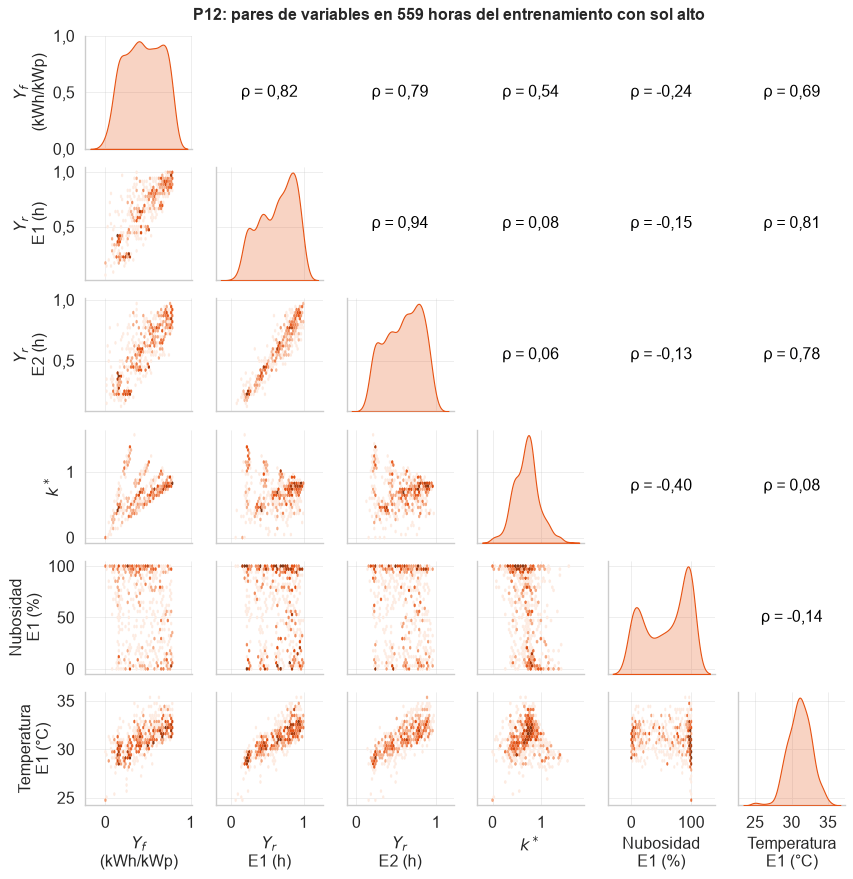

559 filas x 6 columnas; primeras 10:


,Yf (kWh/kWp),Yr E1 (h),Yr E2 (h),k*,Nubosidad E1 (%),Temperatura E1 (°C)
datatime,,,,,,
2026-07-25 08:00:00-05:00,0.1370,0.2150,0.2269,0.6808,60.5,28.45
2026-07-25 10:00:00-05:00,0.4464,0.6456,0.6102,0.7182,4.0,30.15
2026-07-25 11:00:00-05:00,0.5256,0.8044,0.7325,0.6724,6.0,31.05
2026-07-25 12:00:00-05:00,0.6678,0.8862,0.7993,0.7556,6.5,31.40
2026-07-25 14:00:00-05:00,0.4790,0.8703,0.7738,0.5425,17.0,30.80
2026-07-25 15:00:00-05:00,0.5605,0.7708,0.6768,0.7233,19.0,30.30
2026-07-25 16:00:00-05:00,0.4053,0.6338,0.5313,0.6717,19.0,29.80
2026-07-25 17:00:00-05:00,0.1514,0.4070,0.3577,0.4004,16.5,28.90
2026-07-26 08:00:00-05:00,0.1619,0.2115,0.2179,0.8052,60.5,28.35


**Observación.** En las horas de sol, Yf se asocia con el Yr observado con ρ = 0,82 y con el pronosticado el día anterior con ρ = 0,79: la diferencia es el error del pronóstico meteorológico, que acota lo que puede lograr el escenario E2. El índice de cielo despejado se asocia con la nubosidad con ρ = -0,40.

In [39]:
# Sección 6.6. Matriz de pares de las variables del pronóstico
if MODELABLE:
    from matplotlib.colors import LinearSegmentedColormap
    idx0 = OBJ_H[n0].index
    PARES = pd.DataFrame({"Yf (kWh/kWp)": OBJ_H[n0]["yf"], "Yr E1 (h)": X0["yr_e1"].reindex(idx0), "Yr E2 (h)": X0e2["yr_e2"].reindex(idx0),
                          "k*": OBJ_H[n0]["kstar"], "Nubosidad E1 (%)": X0["cloud_cover"].reindex(idx0),
                          "Temperatura E1 (°C)": X0["temperature_2m"].reindex(idx0)})[SOL_M & (OBJ_H[n0]["yr_cs"] >= config.UMBRAL_G_POA_PR / 1000).to_numpy()].dropna()
    NARANJAS = LinearSegmentedColormap.from_list("naranja_viu", ["#FDEBE1", "#F4A77F", config.COLOR_PRINCIPAL, "#7A2A06"])
    def hexagonos(x, y, **kw):
        plt.hexbin(x, y, gridsize=30, cmap=NARANJAS, mincnt=1, bins="log", linewidths=0)
    def rotulo_spearman(x, y, **kw):
        a = plt.gca(); a.set_axis_off()
        a.text(0.5, 0.5, f"ρ = {pd.Series(np.asarray(x)).corr(pd.Series(np.asarray(y)), method='spearman'):.2f}",
               ha="center", va="center", fontsize=13, transform=a.transAxes, color="black")
    if len(PARES) >= 100:
        with plt.rc_context({"figure.constrained_layout.use": False}):      # PairGrid usa su propia disposicón
            g_p = sns.PairGrid(PARES, diag_sharey=False, height=1.75)
            g_p.map_lower(hexagonos)
            g_p.map_diag(sns.kdeplot, color=config.COLOR_PRINCIPAL, fill=True, warn_singular=False)
            g_p.map_upper(rotulo_spearman)
            g_p.figure.suptitle(f"{n0}: pares de variables en {miles(len(PARES))} horas del entrenamiento con sol alto", y=1.01)
        fig(g_p.figure, f"pares_variables_{n0}", PARES)
        C_PARES = PARES.corr("spearman")
        r_e1, r_e2 = C_PARES.loc["Yf (kWh/kWp)", "Yr E1 (h)"], C_PARES.loc["Yf (kWh/kWp)", "Yr E2 (h)"]
        display(Markdown(
            f"**Observación.** En las horas de sol, Yf se asocia con el Yr observado con ρ = {r_e1:.2f} y con el pronosticado el "
            f"día anterior con ρ = {r_e2:.2f}" + (": la diferencia es el error del pronóstico meteorológico, que acota lo que puede "
            "lograr el escenario E2." if r_e1 > r_e2 + 0.01 else ".") +
            f" El índice de cielo despejado se asocia con la nubosidad con ρ = {C_PARES.loc['k*', 'Nubosidad E1 (%)']:.2f}."))
        registrar_unidad("pares_variables", {"horas": int(len(PARES)), "spearman": C_PARES.round(4).to_dict()})

### 6.7. Relevancia, redundancia y consenso

*Base en el máster.* La selección de variables y el análisis de componentes adaptan los cuadernos de selección de características y de componentes principales de Machine Learning (aprendizaje no supervisado) a variables meteorológicas horarias.

Para cada inversor y escenario se aplican cuatro criterios complementarios, de filtro, incrustados y de
importancia (Guyon y Elisseeff, 2003):

1. **Correlación de Spearman** con el objetivo: relación monótona, robusta a atípicos.
2. **Información mutua** (estimador de k vecinos, semilla 37): capta relaciones no lineales.
3. **Lasso** con validación cruzada temporal (TimeSeriesSplit de 5 pliegues) sobre variables
   estandarizadas: selección embebida; los coeficientes que llegan a cero son prescindibles dadas las demás.
4. **Importancia por permutación** de un bosque aleatorio entrenado con el entrenamiento y medida en la
   validación: cuánto empeora el MAE al romper la relación de cada variable.

El **rango medio** de los cuatro criterios ordena las variables; el **consenso** promedia ese rango entre
inversores. La **redundancia** se controla con el factor de inflación de la varianza (VIF, Estadística
Avanzada) y, al elegir, con un umbral de correlación de 0,90 entre variables: de un par muy correlacionado
solo entra la mejor ordenada.

**Consenso E1** (media de 3 inversores; menor rango medio = más relevante)

,spearman,informacion_mutua,lasso,permutacion,rango_medio
yr_e1,0.8395,0.8596,0.1301,0.0615,1.2500
elevacion_solar,0.7831,0.8352,0.0262,0.0016,5.5417
hora_sin,0.1991,0.8177,0.0335,0.0071,7.2500
hora_cos,0.7778,0.6977,0.0392,0.0003,7.3333
yf_rez24,0.7553,0.4877,0.0191,0.0008,7.8333
cos_cenit,0.7831,0.8347,0.0000,0.0018,10.5000
t_modulo,0.7160,0.4981,0.0122,0.0006,10.6250
aerosol_optical_depth,0.1212,0.0961,0.0210,0.0036,13.4167
yf_rez48,0.6824,0.4480,0.0015,0.0006,13.8333
yr_cs,0.7763,0.8134,0.0000,-0.0000,14.8750


**Consenso E2** (media de 3 inversores; menor rango medio = más relevante)

,spearman,informacion_mutua,lasso,permutacion,rango_medio
yr_e2,0.8237,0.7694,0.1556,0.0580,1.9167
yf_rez24,0.7553,0.4878,0.0274,0.0024,4.8333
hora_sin,0.1991,0.8181,0.0279,0.0073,6.7500
elevacion_solar,0.7831,0.8354,0.0064,0.0007,7.0833
cos_cenit,0.7831,0.8349,0.0000,0.0006,8.0000
yr_cs,0.7763,0.8137,0.0000,0.0001,10.0417
hora_cos,0.7778,0.6995,0.0000,0.0000,10.7917
azimut_solar,0.1063,0.3004,0.0076,0.0019,12.0000
kstar_rez24,0.2747,0.2207,0.0054,0.0012,12.1250
yf_rez48,0.6824,0.4482,0.0003,0.0003,12.2083


**Seleccionadas E0** (8): `yf_rez24`, `yr_cs`, `hora_sin`, `yf_rez48`, `yf_rez168`, `kstar_rez24`, `doy_sin`, `yf_dia_rez1`

**Seleccionadas E1** (15): `yr_e1`, `yf_rez24`, `hora_sin`, `t_modulo`, `aerosol_optical_depth`, `yf_rez48`, `yf_rez168`, `temperature_2m`, `kstar_rez24`, `kt_e1`, `wind_gusts_10m`, `cloud_cover`, `sunshine_duration`, `doy_sin`, `cloud_cover_low`

**Seleccionadas E2** (15): `yr_e2`, `yf_rez24`, `hora_sin`, `kstar_rez24`, `yf_rez48`, `t_modulo`, `yf_rez168`, `relative_humidity_2m`, `aerosol_optical_depth_rez24`, `doy_cos`, `kt_e2`, `yf_dia_rez1`, `dias_secos`, `wind_speed_10m`, `cloud_cover`

**VIF de las candidatas E1 en P12** (mayor de 10: muy redundante con las demás)

,cos_cenit,temperature_2m,yr_cs,vapour_pressure_deficit,hora_cos,relative_humidity_2m,dew_point_2m,kstar_dia_rez1,yf_dia_rez1,cloud_cover,cloud_cover_high,wind_speed_10m,wind_gusts_10m,hora_sin,yr_e1,elevacion_solar,doy_cos,doy_sin,yf_rez24,t_modulo,azimut_solar,surface_pressure,kstar_rez24,kt_e1,yf_rez48,yf_rez168,dias_secos,cloud_cover_low,sunshine_duration,aerosol_optical_depth,dias_secos_ideam,cloud_cover_mid,precipitation,dust
vif,2124.7,1354.7,1261.0,1025.4,656.1,263.8,253.7,178.5,168.5,70.1,65.8,61.5,56.4,49.0,43.3,39.6,37.5,34.6,18.1,14.4,11.2,8.8,8.2,6.8,4.8,4.5,3.4,2.8,2.5,2.2,2.1,2.0,1.9,1.7


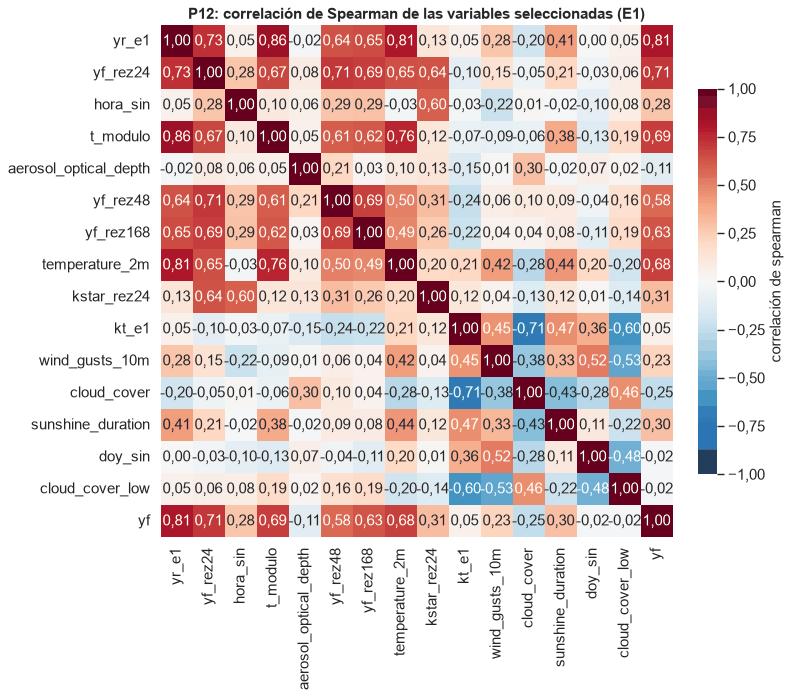

16 filas x 16 columnas; primeras 10:


,yr_e1,yf_rez24,hora_sin,t_modulo,aerosol_optical_depth,yf_rez48,yf_rez168,temperature_2m,kstar_rez24,kt_e1,wind_gusts_10m,cloud_cover,sunshine_duration,doy_sin,cloud_cover_low,yf
yr_e1,1.0000,0.7321,0.0503,0.8593,-0.0212,0.6396,0.6549,0.8066,0.1286,0.0535,0.2782,-0.2019,0.4141,0.0018,0.0488,0.8147
yf_rez24,0.7321,1.0000,0.2786,0.6685,0.0791,0.7108,0.6894,0.6473,0.6351,-0.1024,0.1521,-0.0512,0.2074,-0.0345,0.0627,0.7107
hora_sin,0.0503,0.2786,1.0000,0.1033,0.0618,0.2857,0.2902,-0.0292,0.6001,-0.0283,-0.2246,0.0144,-0.0156,-0.0958,0.0750,0.2756
t_modulo,0.8593,0.6685,0.1033,1.0000,0.0511,0.6063,0.6183,0.7639,0.1237,-0.0671,-0.0929,-0.0648,0.3794,-0.1274,0.1893,0.6891
aerosol_optical_depth,-0.0212,0.0791,0.0618,0.0511,1.0000,0.2099,0.0267,0.1001,0.1290,-0.1486,0.0102,0.3007,-0.0228,0.0700,0.0235,-0.1097
yf_rez48,0.6396,0.7108,0.2857,0.6063,0.2099,1.0000,0.6872,0.5026,0.3064,-0.2404,0.0639,0.1015,0.0882,-0.0425,0.1623,0.5756
yf_rez168,0.6549,0.6894,0.2902,0.6183,0.0267,0.6872,1.0000,0.4891,0.2596,-0.2188,0.0399,0.0448,0.0829,-0.1101,0.1919,0.6327
temperature_2m,0.8066,0.6473,-0.0292,0.7639,0.1001,0.5026,0.4891,1.0000,0.2025,0.2105,0.4175,-0.2803,0.4395,0.2016,-0.2018,0.6835
kstar_rez24,0.1286,0.6351,0.6001,0.1237,0.1290,0.3064,0.2596,0.2025,1.0000,0.1221,0.0397,-0.1343,0.1162,0.0106,-0.1403,0.3107
kt_e1,0.0535,-0.1024,-0.0283,-0.0671,-0.1486,-0.2404,-0.2188,0.2105,0.1221,1.0000,0.4494,-0.7112,0.4678,0.3645,-0.5950,0.0498


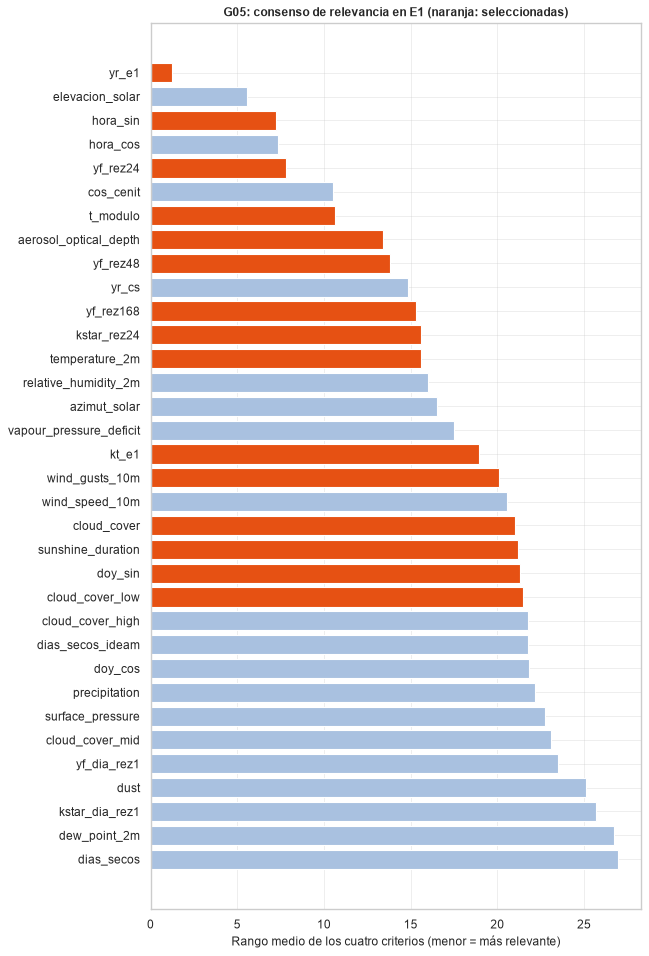

34 filas x 5 columnas; primeras 10:


,spearman,informacion_mutua,lasso,permutacion,rango_medio
yr_e1,0.8395,0.8596,0.1301,0.0615,1.2500
elevacion_solar,0.7831,0.8352,0.0262,0.0016,5.5417
hora_sin,0.1991,0.8177,0.0335,0.0071,7.2500
hora_cos,0.7778,0.6977,0.0392,0.0003,7.3333
yf_rez24,0.7553,0.4877,0.0191,0.0008,7.8333
cos_cenit,0.7831,0.8347,0.0000,0.0018,10.5000
t_modulo,0.7160,0.4981,0.0122,0.0006,10.6250
aerosol_optical_depth,0.1212,0.0961,0.0210,0.0036,13.4167
yf_rez48,0.6824,0.4480,0.0015,0.0006,13.8333
yr_cs,0.7763,0.8134,0.0000,-0.0000,14.8750


**Observaciones.** En E1 las variables más relevantes son `yr_e1`, `elevacion_solar`, `hora_sin`, `hora_cos`, `yf_rez24`; en E2, `yr_e2`, `yf_rez24`, `hora_sin`, `elevacion_solar`, `cos_cenit`. Las candidatas con VIF mayor de 10 (`cos_cenit`, `temperature_2m`, `yr_cs`, `vapour_pressure_deficit`, `hora_cos`, `relative_humidity_2m`, `dew_point_2m`, `kstar_dia_rez1`) son combinaciones casi exactas de otras (por ejemplo, la geometría solar y las variables cíclicas de la hora); el filtro de correlación deja una sola de cada grupo.

**Conclusión.** Los conjuntos seleccionados alimentan los modelos de aprendizaje automático (sección 10). Para SARIMAX (sección 9) se usan solo las exógenas meteorológicas mejor ordenadas, porque la parte autorregresiva ya la modela el propio SARIMA.

In [40]:
# Sección 6.7. Relevancia, redundancia y consenso
if MODELABLE:
    SEL, CONSENSO, VIF = {}, {}, {}
    for esc in ("E1", "E2"):
        rankings = []
        for _, inv in INVERSORES.iterrows():
            n = inv.codigo
            if n not in PERIODO:
                continue
            X, y = candidatas(n, inv, esc)
            m = mascara_modelado(n)
            etq = part.etiquetar(X.index).to_numpy()
            tr, va = m & (etq == "entrenamiento"), m & (etq == "validacion")
            min_tr, min_va = (500, 100) if UNIDADES_MODELABLES[n0]["dias_entrenamiento"] >= DIAS_MIN_ML else (100, 24)
            if tr.sum() < min_tr or va.sum() < min_va:
                continue
            corr = sel.correlaciones(y[tr], X[tr]).set_index("variable")
            mi = sel.informacion_mutua(X[tr], y[tr])
            coef, _ = sel.lasso(X[tr], y[tr])
            perm = sel.permutacion(X[tr], y[tr], X[va], y[va]).set_index("variable")["importancia"]
            r = sel.ranking(spearman=corr["abs_spearman"], informacion_mutua=mi, lasso=coef.abs(), permutacion=perm)
            rankings.append(r.assign(inversor=n))
            if esc == "E1" and (n == n0 or (n0 not in INVERSORES["codigo"].values and n0 not in VIF)):
                VIF[n0] = sel.vif(X[tr])
        todos = pd.concat(rankings)
        CONSENSO[esc] = todos.groupby(level=0)[["spearman", "informacion_mutua", "lasso", "permutacion", "rango_medio"]].mean().sort_values("rango_medio")
        Xref, _ = candidatas(n0, inv0, esc)
        Xref_tr = Xref[mascara_modelado(n0) & (part.etiquetar(Xref.index).to_numpy() == "entrenamiento")]
        # Obligatorias: el Yr del escenario (la información de nubes) y el rezago de 24 h (base de la persistencia).
        # Sin ellas, el filtro de correlación descartaría el Yr por compartir la campana diaria con el Yr de cielo
        # despejado, aunque solo el primero trae la atenuación por nubes.
        SEL[esc] = sel.seleccionar(list(CONSENSO[esc].index), Xref_tr, umbral_corr=0.90, maximo=15,
                                   obligatorias=(f"yr_{esc.lower()}", "yf_rez24"))
        if esc == "E1":       # E0: sin exógenas meteorológicas (solo endógenas y deterministas)
            propias = [c for c in X0.columns if c.startswith(("yf_", "kstar_", "yr_cs", "elevacion", "azimut", "cos_cenit", "hora_", "doy_"))]
            SEL["E0"] = sel.seleccionar([v for v in CONSENSO["E1"].index if v in propias], Xref_tr, umbral_corr=0.90,
                                        maximo=10, obligatorias=("yf_rez24", "yr_cs"))
        display(Markdown(f"**Consenso {esc}** (media de {todos['inversor'].nunique()} inversores; menor rango medio = más relevante)"))
        display(CONSENSO[esc].head(20).round(4))
    for esc in ("E0", "E1", "E2"):
        display(Markdown(f"**Seleccionadas {esc}** ({len(SEL[esc])}): " + ", ".join(f"`{v}`" for v in SEL[esc])))

    display(Markdown(f"**VIF de las candidatas E1 en {n0}** (mayor de 10: muy redundante con las demás)"))
    display(VIF[n0].round(1).to_frame().T)
    sel_e1 = X0.loc[mascara_modelado(n0), [v for v in SEL["E1"] if v in X0.columns]].assign(yf=y0)
    fig(gr.mapa_correlacion(sel_e1, "spearman", f"{n0}: correlación de Spearman de las variables seleccionadas (E1)"),
        f"correlacion_seleccion_e1_{n0}", sel_e1.corr("spearman"))
    f, ax = plt.subplots(figsize=(8, 0.32 * len(CONSENSO["E1"]) + 1))
    ce = CONSENSO["E1"]["rango_medio"].sort_values(ascending=False)
    ax.barh(ce.index, ce.to_numpy(), color=[config.COLOR_PRINCIPAL if v in SEL["E1"] else config.COLOR_TENUE for v in ce.index])
    ax.set_xlabel("Rango medio de los cuatro criterios (menor = más relevante)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(f"{GRUPO}: consenso de relevancia en E1 (naranja: seleccionadas)")
    fig(f, "consenso_seleccion_e1", CONSENSO["E1"])
    # gr.mostrar(CONSENSO["E2"], todas=True)   # consenso del escenario E2
    display(Markdown(
        f"**Observaciones.** En E1 las variables más relevantes son {', '.join(f'`{v}`' for v in CONSENSO['E1'].index[:5])}; "
        f"en E2, {', '.join(f'`{v}`' for v in CONSENSO['E2'].index[:5])}. "
        f"Las candidatas con VIF mayor de 10 ({', '.join(f'`{v}`' for v in VIF[n0][VIF[n0] > 10].index[:8])}) son "
        f"combinaciones casi exactas de otras (por ejemplo, la geometría solar y las variables cíclicas de la hora); el "
        f"filtro de correlación deja una sola de cada grupo.\n\n"
        f"**Conclusión.** Los conjuntos seleccionados alimentan los modelos de aprendizaje automático (sección 10). Para SARIMAX "
        f"(sección 9) se usan solo las exógenas meteorológicas mejor ordenadas, porque la parte autorregresiva ya la "
        f"modela el propio SARIMA."))
    registrar_unidad("seleccion", {esc: {"variables": SEL[esc],
                  "consenso": CONSENSO[esc]["rango_medio"].round(2).to_dict() if esc in CONSENSO else None} for esc in SEL})

## 7. Estructura de la serie: estacionalidad y estacionariedad

Antes de proponer un SARIMA hay que saber qué estacionalidad tiene la serie y si es estacionaria. En el
trópico no hay estaciones térmicas como en latitudes medias, así que la estacionalidad anual no se puede
suponer: se mide. El Caribe colombiano sí tiene un régimen de lluvias bimodal (temporadas secas de
diciembre a marzo y de junio a agosto, lluviosas en abril y mayo y de septiembre a noviembre), que podría
modular la irradiancia a escala anual.

Con unos 17 meses de producción no se puede estimar un ciclo anual en la propia serie fotovoltaica. Por
eso la estacionalidad se analiza también en la irradiancia de ERA5 de 2015 a 2024 en el mismo punto.

### 7.1. Ciclo diario frente a ciclo anual en diez años de irradiancia (ERA5)

ERA5 horario de 2015-01-01 a 2025-01-01 (87 672 horas).

**Partición de la varianza horaria de la GHI**

,ciclo_diario,ciclo_anual_adicional,residuo_meteorologico
% de la varianza,95.07,1.26,3.67


**Periodos con más potencia espectral**

,periodo_h,periodo_dias,fraccion_varianza
0,24.0000,1.0000,0.7619
1,12.0000,0.5000,0.1815
2,8.0000,0.3333,0.0047
3,8767.2000,365.3000,0.0025
4,6.0000,0.2500,0.0021
5,23.8693,0.9946,0.0021
6,23.9345,0.9973,0.0020
7,4383.6000,182.6500,0.0015


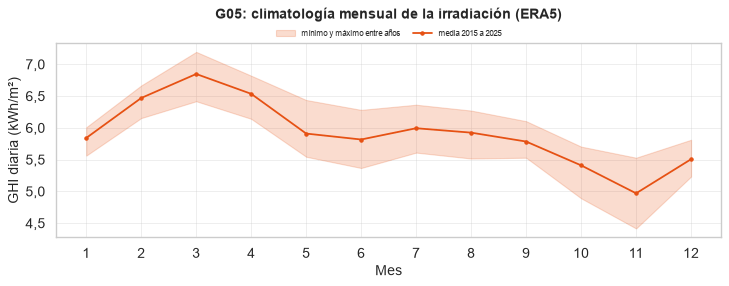

12 filas x 5 columnas; primeras 10:


,media,desviacion_entre_anios,minimo,maximo,anios
datatime,,,,,
1,5.8413,0.1297,5.5636,6.0097,10
2,6.4705,0.1575,6.1546,6.6674,10
3,6.8483,0.2245,6.4194,7.1959,10
4,6.5360,0.2373,6.1427,6.8215,10
5,5.9107,0.2747,5.5459,6.4388,10
6,5.8173,0.3002,5.3690,6.2834,10
7,5.9947,0.2245,5.6112,6.3645,10
8,5.9253,0.2913,5.5180,6.2726,10
9,5.7853,0.2060,5.5306,6.1057,10


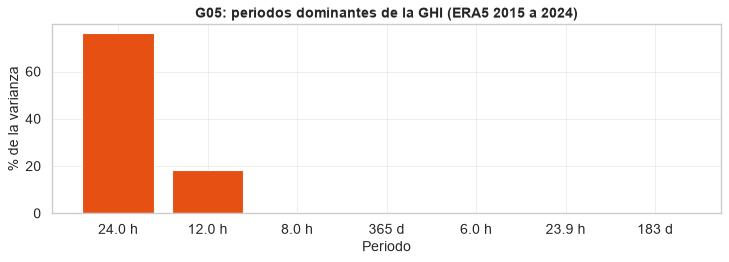

8 filas x 3 columnas; primeras 8:


,periodo_h,periodo_dias,fraccion_varianza
0,24.0000,1.0000,0.7619
1,12.0000,0.5000,0.1815
2,8.0000,0.3333,0.0047
3,8767.2000,365.3000,0.0025
4,6.0000,0.2500,0.0021
5,23.8693,0.9946,0.0021
6,23.9345,0.9973,0.0020
7,4383.6000,182.6500,0.0015


**Observación.** La hora del día explica el 95,1 % de la varianza horaria de la irradiancia; conocer además el mes solo agrega un 1,3 %, y el 3,7 % restante es tiempo meteorológico (nubes). El periodograma concentra la potencia en 24 h y sus armónicos. La irradiación diaria media va de 4,97 kWh/m² (mes 11) a 6,85 kWh/m² (mes 3), una amplitud anual de 1,88 kWh/m² (32 % de la media).

**Conclusión.** La estacionalidad dominante es la de 24 h; la anual existe, pero es pequeña frente al ciclo diario y a la variabilidad por nubes. Por eso el SARIMA horario usa s = 24 y el ciclo anual, con tan pocos meses de producción, entra solo a través de las variables de día del año y de las exógenas.

**ENSO.** Correlación entre la anomalía mensual de GHI y el índice ONI (121 meses): r = 0,08. Un valor positivo indica más irradiancia en El Niño (menos lluvia en el Caribe colombiano).

In [41]:
# Sección 7.1. Ciclo diario frente a ciclo anual en diez años de irradiancia (ERA5)
if MODELABLE:
    import dataclasses
    s_era5 = next(s for s in SERIES if s.nombre == "om_archive__era5")
    era5_largo = datos.leer_serie(dataclasses.replace(s_era5, nombre="om_archive__era5_climatologia"), *config.CLIMATOLOGIA_ERA5)
    # Diez años completos (2015 a 2024), al nivel de NSRDB como las demás fuentes observadas (5.1)
    FACTOR_ERA5 = float(NIVEL.loc["era5", "factor"]) if "era5" in NIVEL.index else 1.0
    ghi_era5 = FACTOR_ERA5 * caract.meteo_horaria(era5_largo, {"shortwave_radiation": "media"}, lugar)["shortwave_radiation"]
    from tfm import estructura as est
    PART_VAR = est.particion_varianza(ghi_era5)
    PERIODOGRAMA = est.periodograma(ghi_era5)
    CLIM = est.climatologia_mensual(ghi_era5)
    display(Markdown(f"ERA5 horario de {ghi_era5.index.min():%Y-%m-%d} a {ghi_era5.index.max():%Y-%m-%d} ({miles(ghi_era5.notna().sum())} horas)."))
    display(Markdown("**Partición de la varianza horaria de la GHI**")); display((100 * PART_VAR).round(2).to_frame("% de la varianza").T)
    display(Markdown("**Periodos con más potencia espectral**")); display(PERIODOGRAMA.round(4))
    f, ax = plt.subplots(figsize=(9, 3.5))
    ax.fill_between(CLIM.index, CLIM["minimo"], CLIM["maximo"], color=config.COLOR_PRINCIPAL, alpha=0.2, label="mínimo y máximo entre años")
    ax.plot(CLIM.index, CLIM["media"], marker="o", lw=1.6, color=config.COLOR_PRINCIPAL,
            label=f"media {ghi_era5.index.min():%Y} a {(ghi_era5.index.max() - pd.Timedelta('1h')):%Y}")
    ax.set_xticks(range(1, 13)); ax.set_xlabel("Mes"); ax.set_ylabel("GHI diaria (kWh/m²)"); ax.legend()
    gr.ampliar_leyenda(ax, 10.5)
    ax.set_title(f"{GRUPO}: climatología mensual de la irradiación (ERA5)")
    fig(f, "climatologia_ghi_era5", CLIM)
    f, ax = plt.subplots(figsize=(9, 3.2))
    etq_p = [f"{v:.1f} h" if v < 48 else f"{v / 24:.0f} d" for v in PERIODOGRAMA["periodo_h"]]
    ax.bar(etq_p, 100 * PERIODOGRAMA["fraccion_varianza"], color=config.COLOR_PRINCIPAL)
    ax.set_xlabel("Periodo"); ax.set_ylabel("% de la varianza"); ax.set_title(f"{GRUPO}: periodos dominantes de la GHI (ERA5 2015 a 2024)")
    fig(f, "periodograma_ghi_era5", PERIODOGRAMA)
    amplitud = CLIM["media"].max() - CLIM["media"].min()
    display(Markdown(
        f"**Observación.** La hora del día explica el {100 * PART_VAR['ciclo_diario']:.1f} % de la varianza horaria de la "
        f"irradiancia; conocer además el mes solo agrega un {100 * PART_VAR['ciclo_anual_adicional']:.1f} %, y el "
        f"{100 * PART_VAR['residuo_meteorologico']:.1f} % restante es tiempo meteorológico (nubes). El periodograma concentra "
        f"la potencia en {PERIODOGRAMA['periodo_h'].iloc[0]:.0f} h y sus armónicos. La irradiación diaria media va de "
        f"{CLIM['media'].min():.2f} kWh/m² (mes {CLIM['media'].idxmin()}) a {CLIM['media'].max():.2f} kWh/m² (mes "
        f"{CLIM['media'].idxmax()}), una amplitud anual de {amplitud:.2f} kWh/m² ({100 * amplitud / CLIM['media'].mean():.0f} % "
        f"de la media).\n\n**Conclusión.** La estacionalidad dominante es la de 24 h; la anual existe, pero es pequeña "
        f"frente al ciclo diario y a la variabilidad por nubes. Por eso el SARIMA horario usa s = 24 y el ciclo anual, con "
        f"tan pocos meses de producción, entra solo a través de las variables de día del año y de las exógenas."))
    res.registrar(f"localidades.{GRUPO}.estructura.ghi_era5", {"particion_varianza_pct": (100 * PART_VAR).round(3).to_dict(),
                  "periodo_dominante_h": float(PERIODOGRAMA["periodo_h"].iloc[0]), "climatologia_kwh_m2": CLIM["media"].round(3).to_dict()})
    try:
        oni = datos.oni()
        oni.index = pd.PeriodIndex.from_fields(year=oni["anio"], month=oni["mes"], freq="M")
        loc = ghi_era5.copy(); loc.index = (loc.index - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).tz_localize(None)
        mensual = loc.resample("MS").mean()
        anom = mensual - mensual.groupby(mensual.index.month).transform("mean")
        anom.index = anom.index.to_period("M")
        comun = anom.dropna().index.intersection(oni.index)
        r_oni = np.corrcoef(anom[comun], oni.loc[comun, "oni"])[0, 1]
        display(Markdown(f"**ENSO.** Correlación entre la anomalía mensual de GHI y el índice ONI ({len(comun)} meses): r = {r_oni:.2f}. "
                         "Un valor positivo indica más irradiancia en El Niño (menos lluvia en el Caribe colombiano)."))
        res.registrar(f"localidades.{GRUPO}.estructura.enso", {"meses": len(comun), "r_anomalia_ghi_oni": r_oni})
    except Exception as e:
        display(Markdown(f"**ENSO.** El índice ONI no está disponible en `meteo.enso_oni` ({type(e).__name__}); la relación entre "
                         "El Niño y la irradiancia no se puede calcular con esta extracción."))

### 7.2. Descomposición y autocorrelación de la serie de rendimiento

*Base en el máster.* La descomposición y la lectura de la ACF y la PACF siguen la actividad de series temporales de Estadística Avanzada (cierre diario de AAPL), aquí con la estacionalidad diaria de una serie horaria.

La descomposición clásica (aditiva, periodo 24; Hyndman y Athanasopoulos, 2021) y la STL (robusta a atípicos) separan
la serie horaria de Yf en tendencia, componente estacional y residuo. El PR diario lo descomponemos con la STL y periodo
de 7 días, porque no tiene ciclo diario, el anual no se puede estimar con la historia disponible y un ciclo semanal solo
aparecería si el consumo del predio limitara la producción. La función de autocorrelación (ACF) de la serie horaria
muestra el ciclo de 24 h, y la de la serie diaria muestra si queda memoria de un día para otro.

Descomponemos la serie completa del entrenamiento en el régimen vigente y no un tramo, con la misma ventana para los dos
objetivos (los días que tienen dato en ambos), y la validación y la prueba quedan fuera para que ninguna decisión vea
esos datos. La alternativa anterior, el tramo continuo más largo de cada objetivo, daba ventanas distintas para el Yf y
el PR y dejaba fuera la mayor parte del entrenamiento. La descomposición no admite huecos, así que, **solo para este
diagnóstico** y para las pruebas de 7.3, interpolamos en el tiempo los huecos horarios de hasta 3 h y con el índice de
cielo despejado los más largos, que conserva la forma del día, y los días sin PR o sin Yf se interpolan en el tiempo.
Informamos la fracción rellenada, medimos las varianzas de los componentes solo en lo observado y los modelos no usan
estas series. Las figuras horarias dibujan solo las últimas cuatro semanas, porque catorce meses de horas se ven como una
banda, aunque la descomposición es la de todo el entrenamiento, y el PR diario se dibuja completo.

**Ventana común de los dos objetivos:** 2026-08-03 a 2026-09-24 (1 272 horas y 53 días). Rellenado solo para este diagnóstico: el 2,8 % de las horas y el 9,4 % de los días del PR.

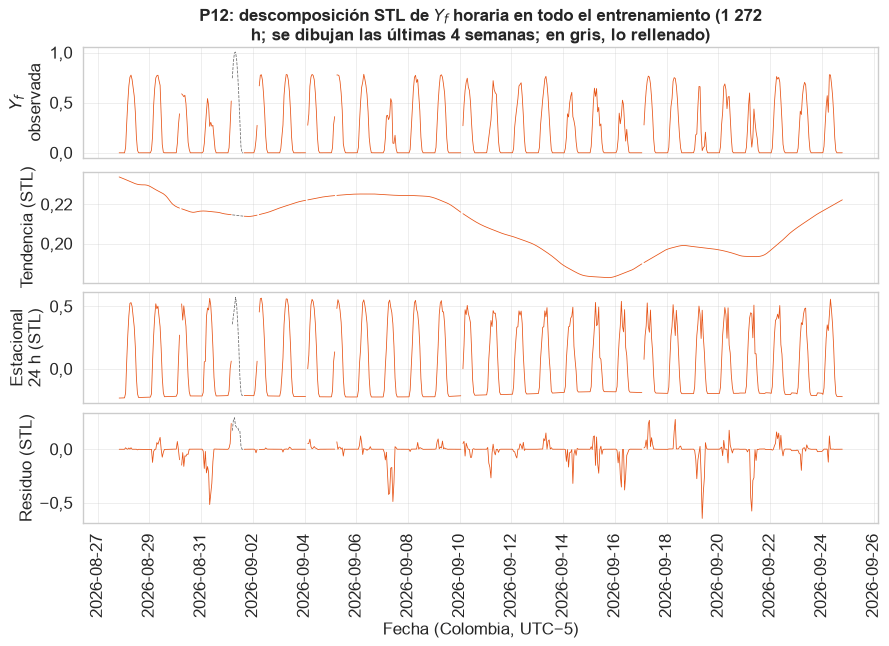

1272 filas x 5 columnas; primeras 10:


,yf,relleno,tendencia,estacional_24h,residuo
datatime,,,,,
2026-08-03 01:00:00-05:00,0.0000,False,0.2126,-0.2107,-0.0018
2026-08-03 02:00:00-05:00,0.0000,False,0.2115,-0.2098,-0.0018
2026-08-03 03:00:00-05:00,0.0000,False,0.2105,-0.2088,-0.0016
2026-08-03 04:00:00-05:00,0.0000,False,0.2094,-0.2080,-0.0014
2026-08-03 05:00:00-05:00,0.0000,False,0.2084,-0.2076,-0.0008
2026-08-03 06:00:00-05:00,0.0004,False,0.2073,-0.2062,-0.0007
2026-08-03 07:00:00-05:00,0.0513,False,0.2063,-0.1365,-0.0185
2026-08-03 08:00:00-05:00,0.2289,False,0.2052,0.0222,0.0015
2026-08-03 09:00:00-05:00,0.3622,False,0.2042,0.1556,0.0024


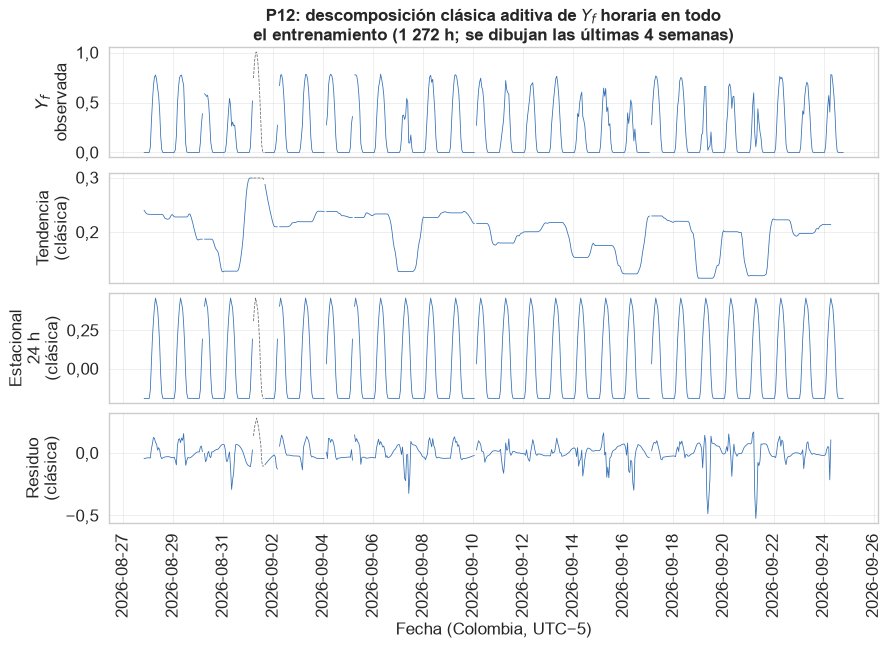

1272 filas x 5 columnas; primeras 10:


,yf,relleno,tendencia,estacional_24h,residuo
datatime,,,,,
2026-08-03 01:00:00-05:00,0.0000,False,NaN,-0.1935,NaN
2026-08-03 02:00:00-05:00,0.0000,False,NaN,-0.1936,NaN
2026-08-03 03:00:00-05:00,0.0000,False,NaN,-0.1936,NaN
2026-08-03 04:00:00-05:00,0.0000,False,NaN,-0.1936,NaN
2026-08-03 05:00:00-05:00,0.0000,False,NaN,-0.1936,NaN
2026-08-03 06:00:00-05:00,0.0004,False,NaN,-0.1934,NaN
2026-08-03 07:00:00-05:00,0.0513,False,NaN,-0.1392,NaN
2026-08-03 08:00:00-05:00,0.2289,False,NaN,0.0308,NaN
2026-08-03 09:00:00-05:00,0.3622,False,NaN,0.1935,NaN


**Varianza de cada componente STL relativa a la de Yf**, en las horas observadas (no suman 100 % porque los componentes no son independientes)

,estacional_24h,tendencia,residuo
%,102.4,0.9,9.2


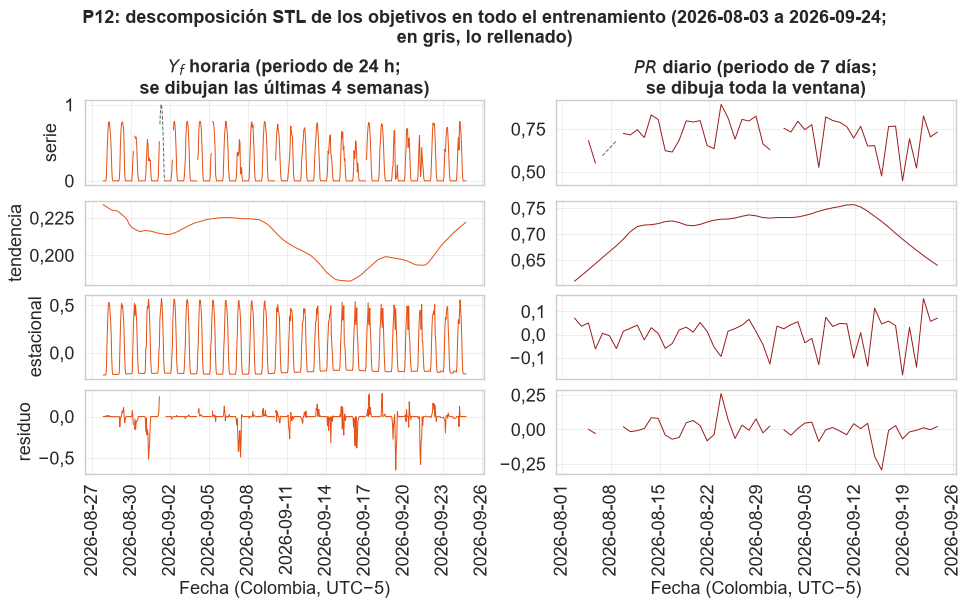

1325 filas x 5 columnas; primeras 10:


serie  relleno  tendencia  estacional  residuo
yf_horaria 2026-08-03 06:00:00+00:00  0.0000    False     0.2126     -0.2107  -0.0018
           2026-08-03 07:00:00+00:00  0.0000    False     0.2115     -0.2098  -0.0018
           2026-08-03 08:00:00+00:00  0.0000    False     0.2105     -0.2088  -0.0016
           2026-08-03 09:00:00+00:00  0.0000    False     0.2094     -0.2080  -0.0014
           2026-08-03 10:00:00+00:00  0.0000    False     0.2084     -0.2076  -0.0008
           2026-08-03 11:00:00+00:00  0.0004    False     0.2073     -0.2062  -0.0007
           2026-08-03 12:00:00+00:00  0.0513    False     0.2063     -0.1365  -0.0185
           2026-08-03 13:00:00+00:00  0.2289    False     0.2052      0.0222   0.0015
           2026-08-03 14:00:00+00:00  0.3622    False     0.2042      0.1556   0.0024
           2026-08-03 15:00:00+00:00  0.4689    False     0.2031      0.2641   0.0017

**Varianza de cada componente STL del PR diario relativa a la del PR**, en los días observados

,estacional_7d,tendencia,residuo
%,50.8,12.6,61.4


**Fuerza de la estacionalidad y de la tendencia** (Kruskal-Wallis del PR por día de la semana: p = 0,10)

,estacional,tendencia
Yf horaria (24 h),0.91,0.08
PR diario (7 días),0.36,0.16


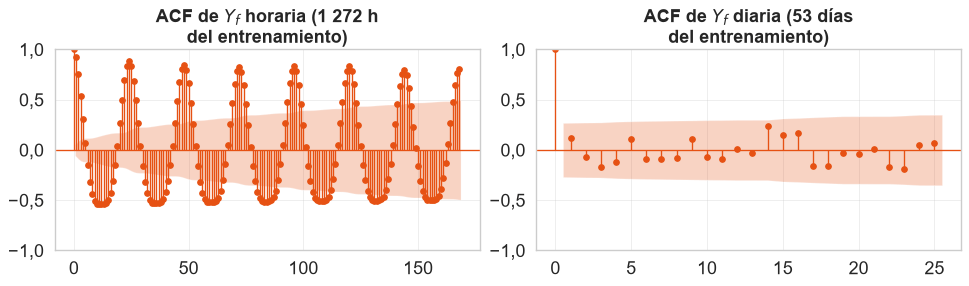

169 filas x 10 columnas; primeras 10:


,acf,acf_ic95_inf,acf_ic95_sup,pacf,pacf_ic95_inf,pacf_ic95_sup,acf_significativa,pacf_significativa,ljung_box_q,ljung_box_p
rezago,,,,,,,,,,
0,1.0000,0.0000,0.0000,1.0000,0.000,0.000,True,True,NaN,NaN
1,0.9243,-0.0550,0.0550,0.9243,-0.055,0.055,True,True,1089.2279,0.0
2,0.7584,-0.0904,0.0904,-0.6579,-0.055,0.055,True,True,1823.2096,0.0
3,0.5411,-0.1080,0.1080,-0.1577,-0.055,0.055,True,True,2197.0610,0.0
4,0.3034,-0.1159,0.1159,-0.1007,-0.055,0.055,True,True,2314.7038,0.0
5,0.0649,-0.1182,0.1182,-0.1535,-0.055,0.055,False,True,2320.0912,0.0
6,-0.1485,-0.1183,0.1183,-0.0024,-0.055,0.055,True,False,2348.3114,0.0
7,-0.3186,-0.1189,0.1189,-0.0248,-0.055,0.055,True,False,2478.3787,0.0
8,-0.4383,-0.1215,0.1215,-0.0666,-0.055,0.055,True,True,2724.6864,0.0


**ACF diaria** (rezagos en días)

26 filas x 10 columnas; primeras 10:


,acf,acf_ic95_inf,acf_ic95_sup,pacf,pacf_ic95_inf,pacf_ic95_sup,acf_significativa,pacf_significativa,ljung_box_q,ljung_box_p
rezago,,,,,,,,,,
0,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,True,True,NaN,NaN
1,0.1150,-0.2692,0.2692,0.1150,-0.2692,0.2692,False,False,0.7413,0.3893
2,-0.0704,-0.2728,0.2728,-0.0847,-0.2692,0.2692,False,False,1.0246,0.5991
3,-0.1717,-0.2741,0.2741,-0.1564,-0.2692,0.2692,False,False,2.7441,0.4328
4,-0.1214,-0.2818,0.2818,-0.0930,-0.2692,0.2692,False,False,3.6205,0.4598
5,0.1130,-0.2855,0.2855,0.1192,-0.2692,0.2692,False,False,4.3958,0.4939
6,-0.0868,-0.2888,0.2888,-0.1609,-0.2692,0.2692,False,False,4.8634,0.5614
7,-0.0925,-0.2906,0.2906,-0.0925,-0.2692,0.2692,False,False,5.4061,0.6105
8,-0.0750,-0.2928,0.2928,-0.0482,-0.2692,0.2692,False,False,5.7703,0.6729


In [42]:
# Sección 7.2. Descomposición y autocorrelación de la serie de rendimiento
if MODELABLE:
    from statsmodels.tsa.seasonal import seasonal_decompose, STL
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    # Serie completa del entrenamiento en el régimen vigente, con la misma ventana para los dos objetivos (los días con
    # dato en ambos). Los huecos se rellenan solo para este diagnóstico y para 7.3; los modelos no usan estas series
    ent = lambda s: s[part.etiquetar(s.index).to_numpy() == "entrenamiento"]
    y0h = ent(OBJ_H[n0]["yf"].where(OBJ_H[n0]["en_regimen"]).asfreq("1h"))
    y0d = ent(OBJ_D[n0]["yf"].where(OBJ_D[n0]["en_regimen"]).asfreq("D"))
    prd0 = ent(OBJ_D[n0]["pr"].where(OBJ_D[n0]["en_regimen"]).asfreq("D"))
    # Las horas se etiquetan al final del periodo: la de las 00:00 es del día anterior
    dia_h = pd.DatetimeIndex((y0h.index - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).tz_localize(None).normalize())
    dias_yf = dia_h[y0h.notna().to_numpy()]
    D_INI, D_FIN = dias_yf.min(), dias_yf.max()
    if prd0.notna().any() and max(D_INI, prd0.first_valid_index()) <= min(D_FIN, prd0.last_valid_index()):
        D_INI, D_FIN = max(D_INI, prd0.first_valid_index()), min(D_FIN, prd0.last_valid_index())
    YH, RELLENO_H = est.serie_completa_diagnostico(y0h[((dia_h >= D_INI) & (dia_h <= D_FIN))], OBJ_H[n0]["yr_cs"], corto=3)
    YD, RELLENO_D = est.serie_completa_diagnostico(y0d.loc[D_INI:D_FIN], corto=2)
    PRD, RELLENO_PR = est.serie_completa_diagnostico(prd0.loc[D_INI:D_FIN], corto=2)
    OBS_H, OBS_PR = ~RELLENO_H, ~RELLENO_PR
    loc_h = lambda s: s.index.tz_convert(config.ZONA).tz_localize(None)
    display(Markdown(f"**Ventana común de los dos objetivos:** {D_INI:%Y-%m-%d} a {D_FIN:%Y-%m-%d} ({miles(len(YH))} horas y {len(PRD)} días). "
                     f"Rellenado solo para este diagnóstico: el {100 * RELLENO_H.mean():.1f} % de las horas y el "
                     f"{100 * RELLENO_PR.mean():.1f} % de los días del PR."))
    clasica = seasonal_decompose(YH, model="additive", period=24)
    stl = STL(YH, period=24, robust=True).fit()
    zoom = YH.index[-24 * 28:] if len(YH) > 24 * 28 else YH.index

    def dibujar_descomposicion(d_, color, rotulo, nombre, titulo):
        f, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
        for a, (serie, etiqueta) in zip(ax, ((YH, "Yf observada"), (d_.trend, f"Tendencia ({rotulo})"),
                                             (d_.seasonal, f"Estacional 24 h ({rotulo})"), (d_.resid, f"Residuo ({rotulo})"))):
            s_ = serie.reindex(zoom)
            a.plot(loc_h(s_), s_.where(OBS_H.reindex(zoom)).to_numpy(), lw=0.7, color=color)
            a.plot(loc_h(s_), s_.where(RELLENO_H.reindex(zoom)).to_numpy(), lw=0.7, color=config.COLOR_NEUTRO)
            a.set_ylabel(etiqueta, fontsize=8)
        ax[0].set_title(titulo)
        fig(f, nombre, pd.DataFrame({"yf": YH, "relleno": RELLENO_H, "tendencia": d_.trend, "estacional_24h": d_.seasonal,
                                     "residuo": d_.resid}))

    dibujar_descomposicion(stl, config.COLOR_PRINCIPAL, "STL", f"stl_yf_{n0}",
                           f"{n0}: descomposición STL de Yf horaria en todo el entrenamiento ({miles(len(YH))} h; se dibujan las últimas 4 semanas; en gris, lo rellenado)")
    dibujar_descomposicion(clasica, config.COLOR_SECUNDARIO, "clásica", f"descomposicion_clasica_yf_{n0}",
                           f"{n0}: descomposición clásica aditiva de Yf horaria en todo el entrenamiento ({miles(len(YH))} h; se dibujan las últimas 4 semanas)")
    var_rel = lambda d_, s_, obs, clave: pd.Series({clave: d_.seasonal[obs].var(), "tendencia": d_.trend[obs].var(),
                                                    "residuo": d_.resid[obs].var()}) / s_[obs].var()
    var_stl = var_rel(stl, YH, OBS_H, "estacional_24h")
    display(Markdown("**Varianza de cada componente STL relativa a la de Yf**, en las horas observadas (no suman 100 % porque los "
                     "componentes no son independientes)")); display((100 * var_stl).round(1).to_frame("%").T)

    # Los dos objetivos juntos en la misma ventana: Yf horaria (STL, 24 h) y PR diario (STL, 7 días)
    if len(PRD) >= 28:
        stl_pr = STL(PRD, period=7, robust=True).fit()
        # La descomposición es la de toda la ventana; la columna horaria muestra sus últimas cuatro semanas, porque catorce
        # meses de horas solo se ven como una banda. Cada columna tiene su propio eje de tiempo
        f, ax = plt.subplots(4, 2, figsize=(12, 7.5), sharex="col")
        for col, (s_, d_, obs, color, nombre, lw, ventana) in enumerate((
                (YH, stl, OBS_H, config.COLOR_PRINCIPAL, "Yf horaria (periodo de 24 h; se dibujan las últimas 4 semanas)", 0.9, zoom),
                (PRD, stl_pr, OBS_PR, gr.color_de("pr"), "PR diario (periodo de 7 días; se dibuja toda la ventana)", 0.9, PRD.index))):
            o_v = obs.reindex(ventana).fillna(False).astype(bool)
            for fila, (serie, rotulo) in enumerate(((s_, "serie"), (d_.trend, "tendencia"), (d_.seasonal, "estacional"), (d_.resid, "residuo"))):
                # La serie y el residuo solo en lo observado (lo rellenado de la serie, en gris); la tendencia y el
                # componente estacional son curvas suaves de toda la ventana
                s_v = serie.reindex(ventana)
                ix = loc_h(s_v) if col == 0 else s_v.index
                ax[fila, col].plot(ix, (s_v.where(o_v) if fila in (0, 3) else s_v).to_numpy(), lw=lw, color=color)
                if fila == 0:
                    ax[fila, col].plot(ix, s_v.where(~o_v).to_numpy(), lw=lw, color=config.COLOR_NEUTRO)
                if col == 0:
                    ax[fila, col].set_ylabel(rotulo, fontsize=9)
            ax[0, col].set_title(nombre)
        f.suptitle(f"{n0}: descomposición STL de los objetivos en todo el entrenamiento ({D_INI:%Y-%m-%d} a {D_FIN:%Y-%m-%d}; en gris, lo rellenado)",
                   fontweight="bold")
        fig(f, f"descomposicion_objetivos_{n0}", pd.concat({"yf_horaria": pd.DataFrame({"serie": YH, "relleno": RELLENO_H, "tendencia": stl.trend,
            "estacional": stl.seasonal, "residuo": stl.resid}), "pr_diario": pd.DataFrame({"serie": PRD, "relleno": RELLENO_PR,
            "tendencia": stl_pr.trend, "estacional": stl_pr.seasonal, "residuo": stl_pr.resid})}))
        var_pr = var_rel(stl_pr, PRD, OBS_PR, "estacional_7d")
        display(Markdown("**Varianza de cada componente STL del PR diario relativa a la del PR**, en los días observados")); display((100 * var_pr).round(1).to_frame("%").T)
        # Fuerza de la estacionalidad y de la tendencia (Hyndman y Athanasopoulos, 2021): 1 - Var(R) / Var(S + R) y
        # 1 - Var(R) / Var(T + R), en lo observado; cerca de 0, el componente no se distingue del ruido. Además, si el PR difiere
        # entre días de la semana (Kruskal-Wallis): un ciclo semanal real solo aparecería si el consumo del predio limitara la producción
        def fuerza(d_, obs):
            r_ = d_.resid[obs]
            return {"estacional": float(max(0.0, 1 - r_.var() / (d_.seasonal[obs] + r_).var())),
                    "tendencia": float(max(0.0, 1 - r_.var() / (d_.trend[obs] + r_).var()))}
        from scipy.stats import kruskal
        pr_obs = PRD[OBS_PR]
        p_kw = float(kruskal(*[g_.to_numpy() for _, g_ in pr_obs.groupby(pr_obs.index.dayofweek)]).pvalue)
        FUERZA = pd.DataFrame({"Yf horaria (24 h)": fuerza(stl, OBS_H), "PR diario (7 días)": fuerza(stl_pr, OBS_PR)}).T
        display(Markdown(f"**Fuerza de la estacionalidad y de la tendencia** (Kruskal-Wallis del PR por día de la semana: p = {p_kw:.2f})"))
        display(FUERZA.round(2))
        registrar_unidad("descomposicion", {"yf_horaria_pct": (100 * var_stl).round(2).to_dict(), "pr_diario_pct": (100 * var_pr).round(2).to_dict(),
                                             "fuerza_yf_horaria": {k: round(v, 3) for k, v in fuerza(stl, OBS_H).items()},
                                             "fuerza_pr_diario": {k: round(v, 3) for k, v in fuerza(stl_pr, OBS_PR).items()},
                                             "p_kruskal_pr_dia_semana": round(p_kw, 4), "horas_yf": len(YH), "dias_pr": len(PRD),
                                             "desde": str(D_INI.date()), "hasta": str(D_FIN.date()),
                                             "relleno_horas_pct": round(100 * float(RELLENO_H.mean()), 2),
                                             "relleno_dias_pr_pct": round(100 * float(RELLENO_PR.mean()), 2)})

    f, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    plot_acf(YH.to_numpy(), lags=24 * 7, ax=ax[0], title=f"ACF de Yf horaria ({miles(len(YH))} h del entrenamiento)")
    plot_acf(YD.to_numpy(), lags=min(40, len(YD) // 2 - 1), ax=ax[1], title=f"ACF de Yf diaria ({len(YD)} días del entrenamiento)")
    from tfm.modelos import sarima
    ACF_H = sarima.tabla_autocorrelacion(YH, 24 * 7)
    ACF_D = sarima.tabla_autocorrelacion(YD, min(40, len(YD) // 2 - 1))
    fig(f, f"acf_yf_{n0}", ACF_H)
    display(Markdown("**ACF diaria** (rezagos en días)")); gr.mostrar(ACF_D)
    gr.guardar_datos(ACF_D, f"{PREF}acf_yf_diaria_{n0}")
    # gr.mostrar(ACF_H, todas=True)   # los 168 rezagos horarios
    # gr.mostrar(ACF_D, todas=True)   # todos los rezagos diarios

### 7.3. Estacionariedad (ADF y KPSS)

*Base en el máster.* Comprobar la estacionariedad antes de identificar el modelo, con contrastes de hipótesis nulas opuestas, viene de la misma actividad de Estadística Avanzada.

Se aplican dos pruebas con hipótesis opuestas, **ADF** (H0: raíz unitaria,
la serie no es estacionaria) y **KPSS** (H0: la serie es estacionaria). Si ADF rechaza y KPSS no, la serie
es estacionaria; si ocurre lo contrario, hay que diferenciar. Se prueban la serie horaria, su diferencia
estacional (1 − B²⁴) y las series diarias de Yf y PR.

Las pruebas no admiten huecos, así que se aplican a las mismas series completas del entrenamiento de 7.2, con
los huecos rellenados **solo para estos diagnósticos**. La alternativa, el tramo continuo más largo, parte la
serie en tramos de pocos días cuando hay horas en falla o sin dato dispersas, y las pruebas pierden potencia.
Los modelos no usan estas series rellenadas.

In [43]:
# Sección 7.3. Estacionariedad (ADF y KPSS)
if MODELABLE:
    ESTAC = pd.DataFrame([est.estacionariedad(YH, "Yf horaria"),
                          est.estacionariedad(YH.diff(24), "(1 - B^24) Yf horaria"),
                          est.estacionariedad(YD, "Yf diaria"),
                          est.estacionariedad(YD.diff(), "(1 - B) Yf diaria"),
                          est.estacionariedad(PRD, "PR diario")])
    # Con tramos cortos o constantes (unidades recientes o casi sin producción) no hay prueba: columnas vacías
    ESTAC = ESTAC.reindex(columns=list(dict.fromkeys([*ESTAC.columns, "n", "adf_p", "kpss_p", "conclusion"])))
    display(ESTAC.round(4))
    display(Markdown(
        "**Lectura.** " + " ".join(f"{r.serie}: {r.conclusion} (ADF p = {r.adf_p:.3g}; KPSS p = {r.kpss_p:.3g})."
                                   for r in ESTAC.dropna(subset=['adf_p']).itertuples()) +
        "\n\n**Decisión.** En la serie horaria se prueba D = 1 con s = 24 (la diferencia estacional elimina el ciclo "
        "diario) frente a D = 0; en las diarias, d = 0 si son estacionarias. La elección final entre órdenes la hace el "
        "criterio de información en la sección 8, y la confirman los residuos."))
    registrar_unidad("estructura.estacionariedad", ESTAC.set_index("serie")[["n", "adf_p", "kpss_p", "conclusion"]].to_dict(orient="index"))

,serie,n,desde,hasta,adf_estadistico,adf_p,kpss_estadistico,kpss_p,conclusion
0,Yf horaria,1272,2026-08-03 06:00:00+00:00,2026-09-25 05:00:00+00:00,-4.0230,0.0013,0.1035,0.1,estacionaria
1,(1 - B^24) Yf horaria,1248,2026-08-04 06:00:00+00:00,2026-09-25 05:00:00+00:00,-11.5200,0.0000,0.0120,0.1,estacionaria
2,Yf diaria,53,2026-08-03 00:00:00,2026-09-24 00:00:00,-6.2723,0.0000,0.0952,0.1,estacionaria
3,(1 - B) Yf diaria,52,2026-08-04 00:00:00,2026-09-24 00:00:00,-6.7580,0.0000,0.1828,0.1,estacionaria
4,PR diario,53,2026-08-03 00:00:00,2026-09-24 00:00:00,-6.4063,0.0000,0.1777,0.1,estacionaria


**Lectura.** Yf horaria: estacionaria (ADF p = 0,00129; KPSS p = 0,1). (1 - B^24) Yf horaria: estacionaria (ADF p = 4.06e-21; KPSS p = 0,1). Yf diaria: estacionaria (ADF p = 3.98e-08; KPSS p = 0,1). (1 - B) Yf diaria: estacionaria (ADF p = 2.84e-09; KPSS p = 0,1). PR diario: estacionaria (ADF p = 1.94e-08; KPSS p = 0,1).

**Decisión.** En la serie horaria se prueba D = 1 con s = 24 (la diferencia estacional elimina el ciclo diario) frente a D = 0; en las diarias, d = 0 si son estacionarias. La elección final entre órdenes la hace el criterio de información en la sección 8, y la confirman los residuos.

## 8. Familia SARIMA

*Base en el máster.* La identificación del ARIMA (órdenes por ACF, PACF y AIC) adapta la actividad de Estadística Avanzada al caso estacional y con exógenas.

Seguimos la progresión de Box y Jenkins, de lo simple a lo complejo (AR → MA → ARMA → ARIMA → SARIMA), sobre el Yf
horario de la unidad principal y con el horizonte H01DH (pronóstico del día siguiente, 24 h, emitido al final del día
D − 1, que en el código se llama H2). Usamos la notación de Box y Jenkins, cuya equivalencia con la de otros textos está
en el glosario.

$$\phi_p(B)\,\Phi_P(B^{s})\,(1-B)^d\,(1-B^{s})^D\,Y_{f,t} = c + \theta_q(B)\,\Theta_Q(B^{s})\,\varepsilon_t,\qquad \varepsilon_t \sim RB(0, \sigma^2)$$

Aquí B es el operador de rezago (B Y_t = Y_{t−1}), φ y Φ son los polinomios autorregresivos no estacional y estacional,
θ y Θ los de medias móviles, d y D las diferencias y s = 24 h.

Primero identificamos los órdenes con la ACF y la PACF de la serie y de su diferencia estacional. Para cada familia
elegimos el orden por **AIC** con una búsqueda en rejilla en las últimas 12 semanas del entrenamiento, para que la
búsqueda sea manejable, y reestimamos el orden elegido con todo el entrenamiento. Después diagnosticamos los residuos
con Ljung-Box (H0: ruido blanco) y evaluamos el pronóstico del día siguiente en la validación frente a las referencias
(la persistencia estacional, es decir, el valor de la misma hora del día anterior, la persistencia inteligente, la
climatología y CLIPER), con MAE, RMSE, nMAE y nRMSE solo en horas observadas de sol y con la prueba de Diebold-Mariano
frente a CLIPER.

El rendimiento no puede ser negativo y de noche es 0, así que recortamos las predicciones en 0 y las anulamos cuando el
Yr de cielo despejado es 0.

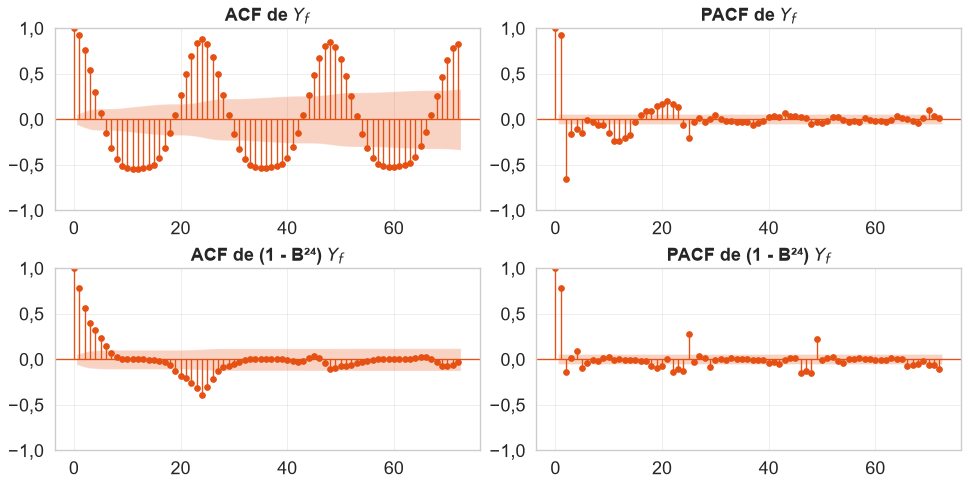

73 filas x 20 columnas; primeras 10:


yf                                                                                                                            dif24_yf                                                  \
           acf acf_ic95_inf acf_ic95_sup    pacf pacf_ic95_inf pacf_ic95_sup acf_significativa pacf_significativa ljung_box_q ljung_box_p      acf acf_ic95_inf acf_ic95_sup    pacf pacf_ic95_inf   
rezago                                                                                                                                                                                               
0       1.0000       0.0000       0.0000  1.0000         0.000         0.000              True               True         NaN         NaN   1.0000       0.0000       0.0000  1.0000        0.0000   
1       0.9243      -0.0550       0.0550  0.9243        -0.055         0.055              True               True   1089.2279         0.0   0.7863      -0.0555       0.0555  0.7863       -0.0555   
2       0.7584      -0.0904       0.0904 -0.6579        -0.055         0.055              True               True   1823.2096         0.0   0.5663      -0.0830       0.0830 -0.1360       -0.0555   
3       0.5411      -0.1080       0.1080 -0.1577        -0.055         0.055              True               True   2197.0610         0.0   0.4047      -0.0941       0.0941  0.0156       -0.0555   
4       0.3034      -0.1159       0.1159 -0.1007        -0.055         0.055              True               True   2314.7038         0.0   0.3243      -0.0993       0.0993  0.0924       -0.0555   
5       0.0649      -0.1182       0.1182 -0.1535        -0.055         0.055             False               True   2320.0912         0.0   0.2328      -0.1025       0.1025 -0.0989       -0.0555   
6      -0.1485      -0.1183       0.1183 -0.0024        -0.055         0.055              True              False   2348.3114         0.0   0.1415      -0.1042       0.1042 -0.0392       -0.0555   
7      -0.3186      -0.1189       0.1189 -0.0248        -0.055         0.055              True              False   2478.3787         0.0   0.0716      -0.1047       0.1047 -0.0027       -0.0555   
8      -0.4383      -0.1215       0.1215 -0.0666        -0.055         0.055              True               True   2724.6864         0.0   0.0269      -0.1049       0.1049 -0.0187       -0.0555   
9      -0.5072      -0.1261       0.1261 -0.0585        -0.055         0.055              True               True   3054.7493         0.0   0.0051      -0.1049       0.1049  0.0136       -0.0555   

                                                                                   
       pacf_ic95_sup acf_significativa pacf_significativa ljung_box_q ljung_box_p  
rezago                                                                             
0             0.0000              True               True         NaN         NaN  
1             0.0555              True               True    773.3760         0.0  
2             0.0555              True               True   1174.8666         0.0  
3             0.0555              True              False   1380.1154         0.0  
4             0.0555              True               True   1512.0404         0.0  
5             0.0555              True               True   1580.0446         0.0  
6             0.0555              True              False   1605.1978         0.0  
7             0.0555             False              False   1611.6483         0.0  
8             0.0555             False              False   1612.5586         0.0  
9             0.0555             False              False   1612.5913         0.0

**Rezagos con ACF o PACF significativa** (fuera de la banda del 95 %) en la serie diferenciada

,acf,pacf,ljung_box_p
rezago,,,
0,1.000,1.000,NaN
1,0.786,0.786,0.0
2,0.566,-0.136,0.0
3,0.405,0.016,0.0
4,0.324,0.092,0.0
5,0.233,-0.099,0.0
6,0.142,-0.039,0.0
18,-0.065,-0.072,0.0
19,-0.124,-0.099,0.0


**Lectura.** La ACF de Yf vale 0,89, 0,85 y 0,83 en los rezagos 24, 48 y 72 h y decae lentamente: hay una estacionalidad diaria fuerte y la serie sin diferenciar no es apta para un ARMA. Tras la diferencia estacional, la ACF en el rezago 24 vale -0,39 (un valor negativo marcado es la firma de un MA estacional, Θ₁) y la PACF en los rezagos 24, 48 y 72 vale -0,12, -0,15 y -0,11 (si decae, confirma el MA estacional). En los primeros rezagos la PACF vale 0,79, -0,14 y 0,02: el último rezago claramente distinto de cero sugiere el orden p de la parte AR no estacional. La elección final la hace el AIC.

In [44]:
# Sección 8. Familia SARIMA
if MODELABLE:
    from tfm.modelos import sarima, referencias as refs
    f, ax = plt.subplots(2, 2, figsize=(12, 6))
    plot_acf(YH.to_numpy(), lags=72, ax=ax[0, 0], title="ACF de Yf"); plot_pacf(YH.to_numpy(), lags=72, ax=ax[0, 1], title="PACF de Yf", method="ywm")
    dif24 = YH.diff(24).dropna()
    plot_acf(dif24.to_numpy(), lags=72, ax=ax[1, 0], title="ACF de (1 - B²⁴) Yf"); plot_pacf(dif24.to_numpy(), lags=72, ax=ax[1, 1], title="PACF de (1 - B²⁴) Yf", method="ywm")
    # Valores de la figura: ACF, PACF, bandas del 95 % y Ljung-Box por rezago, de la serie y de su diferencia estacional
    T_Y, T_D = sarima.tabla_autocorrelacion(YH, 72), sarima.tabla_autocorrelacion(dif24, 72)
    IDENT = pd.concat({"yf": T_Y, "dif24_yf": T_D}, axis=1)
    fig(f, f"acf_pacf_identificacion_{n0}", IDENT)
    # gr.mostrar(IDENT, todas=True)   # los 72 rezagos de ambas series
    display(Markdown("**Rezagos con ACF o PACF significativa** (fuera de la banda del 95 %) en la serie diferenciada"))
    display(T_D[T_D["acf_significativa"] | T_D["pacf_significativa"]][["acf", "pacf", "ljung_box_p"]].round(3).head(20))
    acf_y, acf_d, pacf_d = T_Y["acf"].to_numpy(), T_D["acf"].to_numpy(), T_D["pacf"].to_numpy()
    display(Markdown(
        f"**Lectura.** La ACF de Yf vale {acf_y[24]:.2f}, {acf_y[48]:.2f} y {acf_y[72]:.2f} en los rezagos 24, 48 y 72 h y decae "
        f"lentamente: hay una estacionalidad diaria fuerte y la serie sin diferenciar no es apta para un ARMA. Tras la diferencia "
        f"estacional, la ACF en el rezago 24 vale {acf_d[24]:.2f} (un valor negativo marcado es la firma de un MA estacional, Θ₁) "
        f"y la PACF en los rezagos 24, 48 y 72 vale {pacf_d[24]:.2f}, {pacf_d[48]:.2f} y {pacf_d[72]:.2f} (si decae, confirma el MA "
        f"estacional). En los primeros rezagos la PACF vale {pacf_d[1]:.2f}, {pacf_d[2]:.2f} y {pacf_d[3]:.2f}: el último rezago "
        f"claramente distinto de cero sugiere el orden p de la parte AR no estacional. La elección final la hace el AIC."))

In [45]:
# Sección 8. Familia SARIMA
if MODELABLE:
    y_h = {n: OBJ_H[n]["yf"].where(OBJ_H[n]["en_regimen"]).asfreq("1h") for n in OBJ_H}
    etq_h = {n: part.etiquetar(y_h[n].index).to_numpy() for n in y_h}
    y0 = y_h[n0]
    y0_tr = y0[etq_h[n0] == "entrenamiento"]
    sel_tramo = y0_tr.iloc[-24 * 7 * 12:]
    FAMILIAS = {
        "AR":     dict(p=(1, 2, 3), q=(0,), d=(0,)),
        "MA":     dict(p=(0,), q=(1, 2, 3), d=(0,)),
        "ARMA":   dict(p=(1, 2), q=(1, 2), d=(0,)),
        "ARIMA":  dict(p=(1, 2), q=(0, 1), d=(1,)),
        "SARIMA": dict(p=(1, 2), q=(0, 1), d=(0,), P=(0, 1), D=(0, 1), Q=(1,), s=24),
    }
    if RAPIDO:
        FAMILIAS = {"AR": dict(p=(1,), q=(0,)), "MA": dict(p=(0,), q=(1,)), "ARMA": dict(p=(1,), q=(1,)),
                    "ARIMA": dict(p=(1,), q=(0,), d=(1,)), "SARIMA": dict(p=(1,), q=(0,), P=(0,), D=(1,), Q=(1,), s=24)}
    BUSQUEDA, ORDEN = {}, {}
    for fam, rej in FAMILIAS.items():
        with tiempos.medir(fam, "busqueda_hiperparametros", n0, observaciones=int(sel_tramo.notna().sum())):
            b = sarima.buscar_orden(sel_tramo, **rej)
        BUSQUEDA[fam] = b
        mejor = b.dropna(subset=["aic"]).iloc[0]
        ORDEN[fam] = (tuple(mejor["orden"]), tuple(mejor["estacional"]))
        display(Markdown(f"**{fam}**: mejor orden por AIC {ORDEN[fam][0]} x {ORDEN[fam][1]}"))
        display(b.head(5).round(3))
        # display(b.round(3))   # todos los órdenes probados
    BUSQ_TODAS = pd.concat(BUSQUEDA, names=["familia", "fila"]).reset_index(level=1, drop=True)
    gr.guardar_datos(BUSQ_TODAS, f"{PREF}busqueda_ordenes_sarima_{n0}")

**AR**: mejor orden por AIC (3, 0, 0) x (0, 0, 0, 0)

,orden,estacional,aic,bic,ljung_box_p,segundos,convergio
0,"(3, 0, 0)","(0, 0, 0, 0)",-3336.918,-3308.881,0.0,1.007,True
1,"(2, 0, 0)","(0, 0, 0, 0)",-3311.264,-3288.832,0.0,0.445,True
2,"(1, 0, 0)","(0, 0, 0, 0)",-2535.509,-2518.684,0.0,0.255,True


**MA**: mejor orden por AIC (0, 0, 3) x (0, 0, 0, 0)

,orden,estacional,aic,bic,ljung_box_p,segundos,convergio
0,"(0, 0, 3)","(0, 0, 0, 0)",-2763.715,-2735.680,0.0,1.263,True
1,"(0, 0, 2)","(0, 0, 0, 0)",-2311.068,-2288.639,0.0,0.667,True
2,"(0, 0, 1)","(0, 0, 0, 0)",-1388.351,-1371.528,0.0,0.300,True


**ARMA**: mejor orden por AIC (2, 0, 2) x (0, 0, 0, 0)

,orden,estacional,aic,bic,ljung_box_p,segundos,convergio
0,"(2, 0, 2)","(0, 0, 0, 0)",-3431.410,-3397.766,0.0,1.443,True
1,"(2, 0, 1)","(0, 0, 0, 0)",-3354.753,-3326.714,0.0,0.843,True
2,"(1, 0, 2)","(0, 0, 0, 0)",-3184.834,-3156.797,0.0,1.181,True
3,"(1, 0, 1)","(0, 0, 0, 0)",-3015.587,-2993.156,0.0,0.545,True


**ARIMA**: mejor orden por AIC (1, 1, 0) x (0, 0, 0, 0)

,orden,estacional,aic,bic,ljung_box_p,segundos,convergio
0,"(1, 1, 0)","(0, 0, 0, 0)",-3048.892,-3037.676,0.0,0.143,True
1,"(1, 1, 1)","(0, 0, 0, 0)",-3048.455,-3031.633,0.0,0.285,True
2,"(2, 1, 0)","(0, 0, 0, 0)",-3048.252,-3031.430,0.0,0.706,False
3,"(2, 1, 1)","(0, 0, 0, 0)",NaN,NaN,0.0,1.182,False


**SARIMA**: mejor orden por AIC (2, 0, 1) x (1, 0, 1, 24)

,orden,estacional,aic,bic,ljung_box_p,segundos,convergio
0,"(2, 0, 1)","(1, 0, 1, 24)",-3797.567,-3758.395,0.000,15.752,True
1,"(1, 0, 1)","(1, 1, 1, 24)",-3755.711,-3727.792,0.000,30.617,True
2,"(2, 0, 1)","(1, 1, 1, 24)",-3754.054,-3720.552,0.000,52.465,True
3,"(2, 0, 0)","(1, 1, 1, 24)",-3753.975,-3726.057,0.002,29.800,True
4,"(2, 0, 0)","(1, 0, 1, 24)",-3750.823,-3717.247,0.000,10.593,True


In [46]:
# Sección 8. Familia SARIMA
if MODELABLE:
    dias_val = pd.date_range(*config.PARTICIONES["validacion"], freq="D")
    dias_pru = pd.date_range(*config.PARTICIONES["prueba"], freq="D")
    origen = lambda dias: [pd.Timestamp(d, tz=config.ZONA).tz_convert("UTC") for d in dias]   # 00:00 local = fin de D - 1

    def postproceso(pr, horario):
        s = pr.set_index("t")["yhat"].clip(lower=0)
        return s.where(horario["yr_cs"].reindex(s.index).to_numpy() > 0, 0.0)

    def observado(horario):
        """Horas de sol con el objetivo observado (al menos 11 de sus 12 lecturas medidas, config.hora_observada) y
        dentro del régimen vigente: las unicas que cuentan en las métricas."""
        imputada = horario["frac_imputada"] if "frac_imputada" in horario else pd.Series(0.0, index=horario.index)
        return config.hora_observada(imputada) & horario["en_regimen"] & (horario["yr_cs"] > 0.05)

    AJUSTE, PRED_VAL, TABLA_H = {}, {}, []
    for fam, (o, so) in ORDEN.items():
        with tiempos.medir(fam, "ajuste", n0, observaciones=int(y0_tr.notna().sum())):
            r = sarima.ajustar(y0_tr, o, so)
        AJUSTE[fam] = r
        with tiempos.medir(fam, "prediccion_validacion", n0, dias=len(dias_val)):
            pr = sarima.pronostico_por_origen(r, y0, origen(dias_val), 24)
        PRED_VAL[fam] = postproceso(pr, OBJ_H[n0])
        lb = sarima.diagnostico(r)["ljung_box_p"].iloc[0]
        TABLA_H.append({"modelo": fam, "orden": f"{o} x {so}", "aic": r.aic, "bic": r.bic, "ljung_box_p_24": lb,
                        **met.evaluar(y0.reindex(PRED_VAL[fam].index), PRED_VAL[fam], observado(OBJ_H[n0]).reindex(PRED_VAL[fam].index))})
    REF_H = refs.horarias_h2(OBJ_H[n0], etq_h[n0] == "entrenamiento")
    for c in REF_H.columns:
        p_ = REF_H[c].reindex(PRED_VAL["SARIMA"].index)
        TABLA_H.append({"modelo": f"ref: {c}", **met.evaluar(y0.reindex(p_.index), p_, observado(OBJ_H[n0]).reindex(p_.index))})
    TABLA_H = pd.DataFrame(TABLA_H)
    rmse_cliper = TABLA_H.set_index("modelo").loc["ref: cliper", "rmse"]
    TABLA_H["skill_vs_cliper"] = 1 - TABLA_H["rmse"] / rmse_cliper
    display(Markdown(f"**{n0}: pronóstico del día siguiente (H01DH) en la validación**")); display(TABLA_H.round(4))

**P12: pronóstico del día siguiente (H01DH) en la validación**

,modelo,orden,aic,bic,ljung_box_p_24,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2,skill_vs_cliper
0,AR,"(3, 0, 0) x (0, 0, 0, 0)",-3305.6912,-3269.9927,0.0,178,0.2065,0.2596,-0.1617,58.3980,73.4340,-0.5537,-0.4525
1,MA,"(0, 0, 3) x (0, 0, 0, 0)",-2763.7149,-2728.0169,0.0,178,0.2184,0.2690,-0.1702,61.7619,76.0878,-0.6680,-0.5050
2,ARMA,"(2, 0, 2) x (0, 0, 0, 0)",-3431.4096,-3388.5714,0.0,178,0.1640,0.2106,-0.0990,46.3900,59.5626,-0.0221,-0.1781
3,ARIMA,"(1, 1, 0) x (0, 0, 0, 0)",-3048.8919,-3034.6122,0.0,178,0.3535,0.4103,-0.3535,100.0000,116.0641,-2.8811,-1.2957
4,SARIMA,"(2, 0, 1) x (1, 0, 1, 24)",-4119.8047,-4069.8441,0.0,178,0.1336,0.1760,-0.0006,37.7879,49.7713,0.2863,0.0155
5,ref: persistencia,NaN,NaN,NaN,NaN,167,0.1470,0.2039,0.0055,41.3458,57.3643,0.0707,-0.1407
6,ref: persistencia_inteligente,NaN,NaN,NaN,NaN,167,0.1469,0.2038,0.0055,41.3251,57.3427,0.0714,-0.1403
7,ref: climatologia,NaN,NaN,NaN,NaN,178,0.1557,0.1895,-0.0299,44.0386,53.6039,0.1721,-0.0603
8,ref: cliper,NaN,NaN,NaN,NaN,178,0.1289,0.1787,-0.0155,36.4563,50.5565,0.2636,0.0000


**Ecuación ajustada del mejor modelo de la familia (SARIMA, P12):**

$$(1-1{,}462B^{1}+0{,}581B^{2})(1-0{,}970B^{24})Y_{f,t} = 0{,}0007 + (1-0{,}557B^{1})(1-0{,}804B^{24})\varepsilon_t,\quad \hat\sigma^2 = 0{,}003046$$

**Coeficientes estimados** (error estándar, estadístico z, p-valor e intervalo de confianza del 95 %)

,coeficiente,error_estandar,z,p_valor,ic95_inf,ic95_sup
intercept,0.0007,0.0012,0.5998,0.5487,-0.0017,0.0031
ar.L1,1.4616,0.8605,1.6984,0.0894,-0.2250,3.1482
ar.L2,-0.5814,0.6414,-0.9064,0.3647,-1.8386,0.6758
ma.L1,-0.5567,1.0028,-0.5552,0.5788,-2.5221,1.4087
ar.S.L24,0.9702,0.0021,465.7670,0.0000,0.9661,0.9743
ma.S.L24,-0.8039,0.0241,-33.3053,0.0000,-0.8512,-0.7566
sigma2,0.0030,0.0001,24.0115,0.0000,0.0028,0.0033


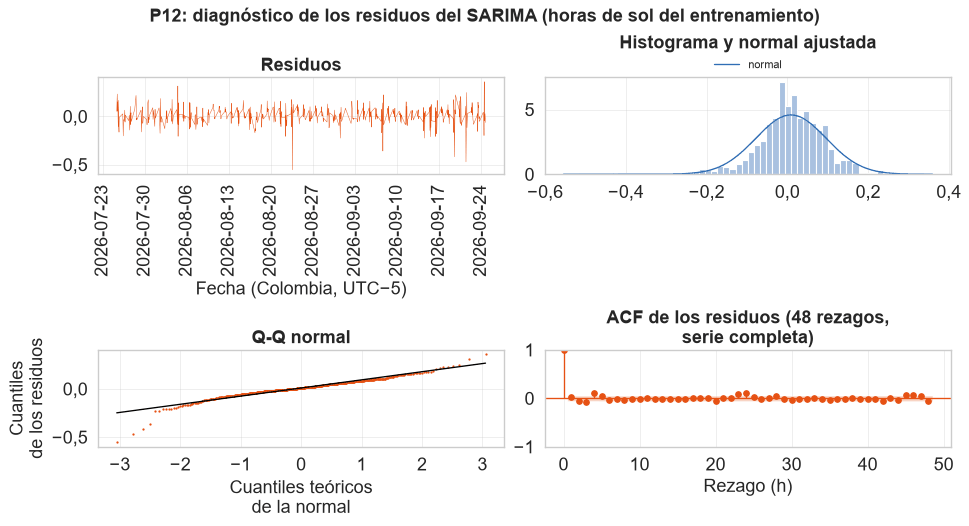

49 filas x 10 columnas; primeras 10:


,acf,acf_ic95_inf,acf_ic95_sup,pacf,pacf_ic95_inf,pacf_ic95_sup,acf_significativa,pacf_significativa,ljung_box_q,ljung_box_p
rezago,,,,,,,,,,
0,1.0000,0.0000,0.0000,1.0000,0.000,0.000,True,True,NaN,NaN
1,0.0251,-0.0520,0.0520,0.0251,-0.052,0.052,False,False,0.8950,0.3441
2,-0.0593,-0.0520,0.0520,-0.0600,-0.052,0.052,True,True,5.9145,0.0520
3,-0.0766,-0.0522,0.0522,-0.0739,-0.052,0.052,True,True,14.2965,0.0025
4,0.1006,-0.0525,0.0525,0.1017,-0.052,0.052,True,True,28.7526,0.0000
5,0.0423,-0.0530,0.0530,0.0289,-0.052,0.052,False,False,31.3129,0.0000
6,-0.0362,-0.0531,0.0531,-0.0334,-0.052,0.052,False,False,33.1852,0.0000
7,-0.0078,-0.0532,0.0532,0.0134,-0.052,0.052,False,False,33.2728,0.0000
8,-0.0399,-0.0532,0.0532,-0.0492,-0.052,0.052,False,False,35.5539,0.0000


Residuos en horas de sol: media 0,0089, desviación 0,0870, asimetría -0,93, curtosis 5,72; Jarque-Bera p = 7.3e-200 (H0: normalidad); Ljung-Box en 24 h p = 3.3e-06 (H0: ruido blanco).

Diebold-Mariano SARIMA frente a CLIPER: estadístico nan, p = nan (negativo: SARIMA mejor).

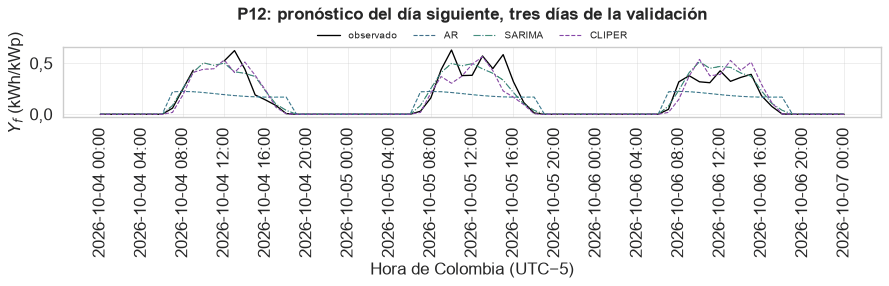

73 filas x 4 columnas; primeras 10:


,observado,AR,SARIMA,CLIPER
2026-10-04 00:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 01:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 02:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 03:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 04:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 05:00:00-05:00,0.0000,0.0000,0.0000,0.0000
2026-10-04 06:00:00-05:00,0.0002,0.0000,0.0000,0.0000
2026-10-04 07:00:00-05:00,0.0598,0.2201,0.0862,0.0180
2026-10-04 08:00:00-05:00,0.2477,0.2240,0.2539,0.1891
2026-10-04 09:00:00-05:00,0.4320,0.2210,0.4123,0.4108


**Observaciones.** Las familias sin componente estacional (AR, MA, ARMA, ARIMA) olvidan el ciclo diario a las pocas horas y su pronóstico a 24 h tiende a la media: nRMSE de 59,6 % a 116,1 %. El SARIMA alcanza 49,8 %, frente a 50,6 % de CLIPER y 57,4 % de la persistencia estacional. Los residuos no son ruido blanco (Ljung-Box p = 3.3e-06): con miles de datos horarios cualquier autocorrelación residual es significativa, y la que queda se debe sobre todo a las nubes, que un modelo univariante no puede anticipar. 

**Conclusión.** El SARIMA supera a CLIPER por 0,8 puntos de nRMSE (Diebold-Mariano p = nan). Sin información meteorológica del día objetivo, un modelo estadístico univariante queda cerca de la climatología combinada con persistencia al día siguiente: la memoria de la serie de un día para otro es débil en este clima. Esto justifica el SARIMAX (sección 9).

In [47]:
# Sección 8. Familia SARIMA
if MODELABLE:
    mejor_fam = TABLA_H[~TABLA_H["modelo"].str.startswith("ref")].sort_values("rmse").iloc[0]["modelo"]
    r = AJUSTE[mejor_fam]
    display(Markdown(f"**Ecuación ajustada del mejor modelo de la familia ({mejor_fam}, {n0}):**\n\n$$" + sarima.ecuacion(r) + "$$"))
    COEF_H = sarima.coeficientes(r)
    display(Markdown("**Coeficientes estimados** (error estándar, estadístico z, p-valor e intervalo de confianza del 95 %)"))
    display(COEF_H.round(4))
    gr.guardar_datos(COEF_H, f"{PREF}coeficientes_{mejor_fam.lower()}_{n0}")
    RES_H = sarima.residuos(r)
    TAB_RES = sarima.tabla_autocorrelacion(RES_H, 48)
    SOL_RES = OBJ_H[n0]["yr_cs"] > 0.05                  # de noche el residuo es 0: el histograma y el Q-Q usan las horas de sol
    fig(gr.diagnostico_residuos(RES_H, f"{n0}: diagnóstico de los residuos del {mejor_fam} (horas de sol del entrenamiento)",
                                mascara=SOL_RES),
        f"residuos_{mejor_fam.lower()}_{n0}", TAB_RES)
    # gr.mostrar(TAB_RES, todas=True)   # ACF, PACF y Ljung-Box de los residuos en los 48 rezagos
    from scipy import stats as _st
    RES_SOL = RES_H[SOL_RES.reindex(RES_H.index).fillna(False).to_numpy()]
    jb = _st.jarque_bera(RES_SOL.to_numpy())
    display(Markdown(f"Residuos en horas de sol: media {RES_SOL.mean():.4f}, desviación {RES_SOL.std():.4f}, asimetría {_st.skew(RES_SOL):.2f}, "
                     f"curtosis {_st.kurtosis(RES_SOL):.2f}; Jarque-Bera p = {jb.pvalue:.2g} (H0: normalidad); Ljung-Box en 24 h "
                     f"p = {TAB_RES.loc[24, 'ljung_box_p']:.2g} (H0: ruido blanco)."))
    dm = met.diebold_mariano(y0.reindex(PRED_VAL[mejor_fam].index), PRED_VAL[mejor_fam], REF_H["cliper"].reindex(PRED_VAL[mejor_fam].index),
                             h=24, observado=observado(OBJ_H[n0]).reindex(PRED_VAL[mejor_fam].index))
    display(Markdown(f"Diebold-Mariano {mejor_fam} frente a CLIPER: estadístico {dm['dm']:.3f}, p = {dm['p_valor']:.4f} (negativo: {mejor_fam} mejor)."))

    # Un día de ejemplo de la validación
    dia = PRED_VAL["SARIMA"].index[len(PRED_VAL["SARIMA"]) // 2].tz_convert(config.ZONA).normalize()
    ventana_ej = slice(dia.tz_convert("UTC"), (dia + pd.Timedelta("3D")).tz_convert("UTC"))
    f, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(y0.loc[ventana_ej].index.tz_convert(config.ZONA), y0.loc[ventana_ej], color="black", lw=1.2, label="observado")
    for fam in ("AR", "SARIMA"):
        ax.plot(PRED_VAL[fam].loc[ventana_ej].index.tz_convert(config.ZONA), PRED_VAL[fam].loc[ventana_ej], lw=1, label=fam)
    ax.plot(REF_H["cliper"].loc[ventana_ej].index.tz_convert(config.ZONA), REF_H["cliper"].loc[ventana_ej], lw=1, ls="--", label="CLIPER")
    ax.set_ylabel("Yf (kWh/kWp)"); ax.legend(); ax.set_title(f"{n0}: pronóstico del día siguiente, tres días de la validación")
    fig(f, f"sarima_ejemplo_{n0}", pd.DataFrame({"observado": y0.loc[ventana_ej], "AR": PRED_VAL["AR"].loc[ventana_ej],
                                                "SARIMA": PRED_VAL["SARIMA"].loc[ventana_ej], "CLIPER": REF_H["cliper"].loc[ventana_ej]}))
    fila = TABLA_H.set_index("modelo")
    display(Markdown(
        f"**Observaciones.** Las familias sin componente estacional (AR, MA, ARMA, ARIMA) olvidan el ciclo diario a las "
        f"pocas horas y su pronóstico a 24 h tiende a la media: nRMSE de {fila.loc[['AR', 'MA', 'ARMA', 'ARIMA'], 'nrmse_pct'].min():.1f} % "
        f"a {fila.loc[['AR', 'MA', 'ARMA', 'ARIMA'], 'nrmse_pct'].max():.1f} %. El SARIMA alcanza {fila.loc['SARIMA', 'nrmse_pct']:.1f} %, "
        f"frente a {fila.loc['ref: cliper', 'nrmse_pct']:.1f} % de CLIPER y {fila.loc['ref: persistencia', 'nrmse_pct']:.1f} % de la "
        f"persistencia estacional. Los residuos no son ruido blanco (Ljung-Box p = {fila.loc['SARIMA', 'ljung_box_p_24']:.2g}): con miles de "
        f"datos horarios cualquier autocorrelación residual es significativa, y la que queda se debe sobre todo a las nubes, "
        f"que un modelo univariante no puede anticipar. "
        + (f"El coeficiente autorregresivo estacional estimado es Φ₁ = {COEF_H.loc['ar.S.L24', 'coeficiente']:.3f}, prácticamente 1: "
           f"el modelo equivale a una diferencia estacional (1 − B²⁴) con media móvil estacional, es decir, pronostica el día "
           f"siguiente a partir del mismo día anterior suavizado, que es la forma estadística de la persistencia con memoria. "
           if "ar.S.L24" in COEF_H.index and abs(COEF_H.loc["ar.S.L24", "coeficiente"]) > 0.98 else "")
        + "\n\n**Conclusión.** " +
        (f"El SARIMA supera a CLIPER por {fila.loc['ref: cliper', 'nrmse_pct'] - fila.loc['SARIMA', 'nrmse_pct']:.1f} puntos de nRMSE"
         if fila.loc['SARIMA', 'nrmse_pct'] < fila.loc['ref: cliper', 'nrmse_pct'] else
         f"El SARIMA no supera a CLIPER ({fila.loc['SARIMA', 'nrmse_pct'] - fila.loc['ref: cliper', 'nrmse_pct']:.1f} puntos de nRMSE peor)") +
        f" (Diebold-Mariano p = {dm['p_valor']:.3f}). Sin información meteorológica del día objetivo, un modelo estadístico "
        f"univariante queda cerca de la climatología combinada con persistencia al día siguiente: la memoria de la serie de un "
        f"día para otro es débil en este clima. Esto justifica el SARIMAX (sección 9)."))
    res.registrar(f"localidades.{GRUPO}.modelos.sarima_h2_{n0}", {"tabla": TABLA_H.set_index("modelo").round(5).to_dict(orient="index"),
                  "ordenes": {k: str(v) for k, v in ORDEN.items()}, "ecuacion": sarima.ecuacion(r), "dm_vs_cliper": dm})

## 9. SARIMAX: SARIMA con variables meteorológicas

El SARIMAX agrega al SARIMA una regresión sobre variables exógenas, con errores de estructura SARIMA,

$$Y_{f,t} = \beta\, Y_{r,t}^{(e)} + u_t,\qquad \phi_p(B)\,\Phi_P(B^{s})\,(1-B^{s})^D\,u_t = \theta_q(B)\,\Theta_Q(B^{s})\,\varepsilon_t$$

donde $Y_{r,t}^{(e)}$ es el Yr del escenario e, que es la variable dominante en la selección de la sección 6 (el
coeficiente β hace el papel de un índice de rendimiento medio). Usamos el orden del mejor SARIMA de la sección 8 y los
escenarios de la tabla.

| Escenario | Ajuste (entrenamiento) | Pronóstico (validación) | Qué mide |
|---|---|---|---|
| E1 | Yr observado (fuente elegida en 5.1) | Yr observado del día objetivo | Límite superior, el "pronóstico perfecto" del tiempo |
| E2-MOS | Yr del pronóstico IFS 0,25 archivado a un día | El mismo pronóstico | Uso real, en el que el modelo aprende también el sesgo del pronóstico (*model output statistics*) |
| E2-PP | Yr observado | Yr del pronóstico IFS 0,25 a un día | Uso real con un modelo entrenado como si el pronóstico fuera perfecto (*perfect prognosis*) |

La comparación MOS frente a PP responde a un vacío señalado en la revisión, porque el desajuste entre entrenar con
observaciones y aplicar con pronósticos no está estudiado para el rendimiento fotovoltaico. Además comparamos la fuente
del pronóstico, IFS 0,25° frente a GFS.

### 9.1. Unidad principal: escenarios y fuente del pronóstico

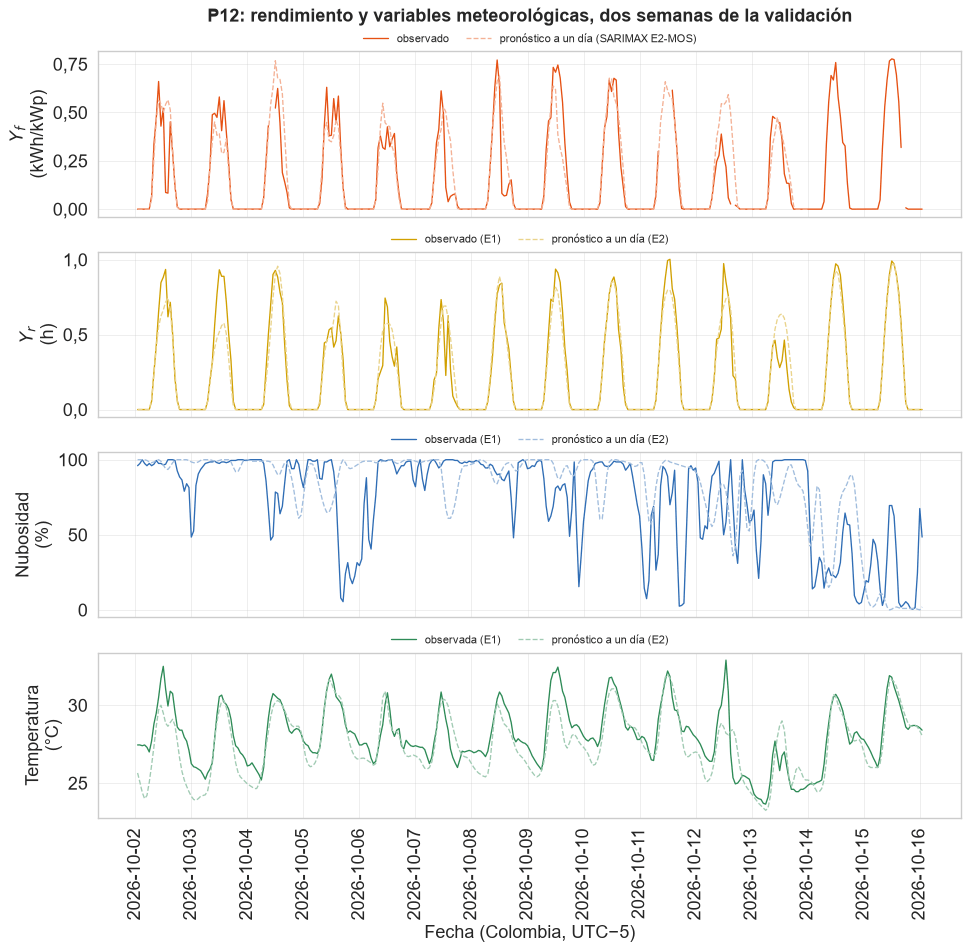

337 filas x 8 columnas; primeras 10:


Yf                                                  Yr                               Nubosidad                             Temperatura                         
                          observado pronóstico a un día (SARIMAX E2-MOS) observado (E1) pronóstico a un día (E2) observada (E1) pronóstico a un día (E2) observada (E1) pronóstico a un día (E2)
datatime                                                                                                                                                                                        
2026-10-02 01:00:00-05:00    0.0000                               0.0000         0.0000                   0.0000           96.0                    100.0          27.45                    25.65
2026-10-02 02:00:00-05:00    0.0000                               0.0000         0.0000                   0.0000           97.5                    100.0          27.45                    25.05
2026-10-02 03:00:00-05:00    0.0000                               0.0000         0.0000                   0.0000          100.0                    100.0          27.40                    24.40
2026-10-02 04:00:00-05:00    0.0000                               0.0000         0.0000                   0.0000           97.5                    100.0          27.45                    24.00
2026-10-02 05:00:00-05:00    0.0000                               0.0000         0.0000                   0.0000           96.0                     99.5          27.30                    24.20
2026-10-02 06:00:00-05:00    0.0007                               0.0000         0.0000                   0.0000           97.5                     98.5          27.00                    25.05
2026-10-02 07:00:00-05:00    0.0654                               0.0538         0.0549                   0.0669           96.0                     98.0          27.70                    26.15
2026-10-02 08:00:00-05:00    0.3364                               0.2651         0.2493                   0.2338           97.0                     98.5          28.80                    27.35
2026-10-02 09:00:00-05:00    0.4709                               0.4629         0.4277                   0.4167           99.5                     99.5          29.50                    28.65
2026-10-02 10:00:00-05:00    0.6604                               0.5625         0.6512                   0.5522           97.5                    100.0          30.50                    29.70

**P12: pronóstico del día siguiente (H01DH) en la validación, con y sin exógenas**

,modelo,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2,skill_vs_cliper
0,SARIMA,178,0.1336,0.1760,-0.0006,37.7879,49.7713,0.2863,0.0155
1,SARIMAX E1,178,0.1229,0.1684,0.0063,34.7758,47.6396,0.3461,0.0577
2,SARIMAX E2-MOS,178,0.1265,0.1752,0.0257,35.7830,49.5521,0.2926,0.0199
3,SARIMAX E2-PP,178,0.1275,0.1706,0.0003,36.0756,48.2496,0.3293,0.0456
4,SARIMAX E2-MOS GFS,178,0.1323,0.1752,-0.0021,37.4276,49.5632,0.2922,0.0196
5,ref: persistencia,167,0.1470,0.2039,0.0055,41.3458,57.3643,0.0707,-0.1407
6,ref: climatologia,178,0.1557,0.1895,-0.0299,44.0386,53.6039,0.1721,-0.0603
7,ref: cliper,178,0.1289,0.1787,-0.0155,36.4563,50.5565,0.2636,0.0000


**Ecuación SARIMAX E1:**

$$(1-0{,}600B^{1}+0{,}003B^{2})(1-0{,}753B^{24})\left(Y_{f,t} - 0{,}675\,Y_{r,t}\right) = 0{,}0012 + (1+0{,}200B^{1})(1-0{,}496B^{24})\varepsilon_t,\quad \hat\sigma^2 = 0{,}002831$$

,coeficiente,error_estandar,z,p_valor,ic95_inf,ic95_sup
intercept,0.0012,0.0008,1.5470,0.1219,-0.0003,0.0026
yr,0.6751,0.0179,37.6357,0.0000,0.6400,0.7103
ar.L1,0.6000,0.1201,4.9952,0.0000,0.3646,0.8354
ar.L2,-0.0027,0.0909,-0.0302,0.9759,-0.1810,0.1755
ma.L1,0.1998,0.1260,1.5860,0.1127,-0.0471,0.4468
ar.S.L24,0.7525,NaN,NaN,NaN,NaN,NaN
ma.S.L24,-0.4955,NaN,NaN,NaN,NaN,NaN
sigma2,0.0028,0.0001,27.7328,0.0000,0.0026,0.0030


**Ecuación SARIMAX E2-MOS:**

$$(1-0{,}740B^{1}+0{,}076B^{2})(1-0{,}830B^{24})\left(Y_{f,t} - 0{,}829\,Y_{r,t}\right) = -0{,}0013 + (1+0{,}062B^{1})(1-0{,}549B^{24})\varepsilon_t,\quad \hat\sigma^2 = 0{,}00288$$

,coeficiente,error_estandar,z,p_valor,ic95_inf,ic95_sup
intercept,-0.0013,0.0007,-1.7868,0.0740,-0.0027,0.0001
yr,0.8295,0.0237,35.0106,0.0000,0.7831,0.8759
ar.L1,0.7399,0.1525,4.8510,0.0000,0.4410,1.0389
ar.L2,-0.0757,0.1124,-0.6733,0.5007,-0.2960,0.1446
ma.L1,0.0618,0.1560,0.3961,0.6921,-0.2439,0.3674
ar.S.L24,0.8303,NaN,NaN,NaN,NaN,NaN
ma.S.L24,-0.5487,NaN,NaN,NaN,NaN,NaN
sigma2,0.0029,0.0001,25.9403,0.0000,0.0027,0.0031


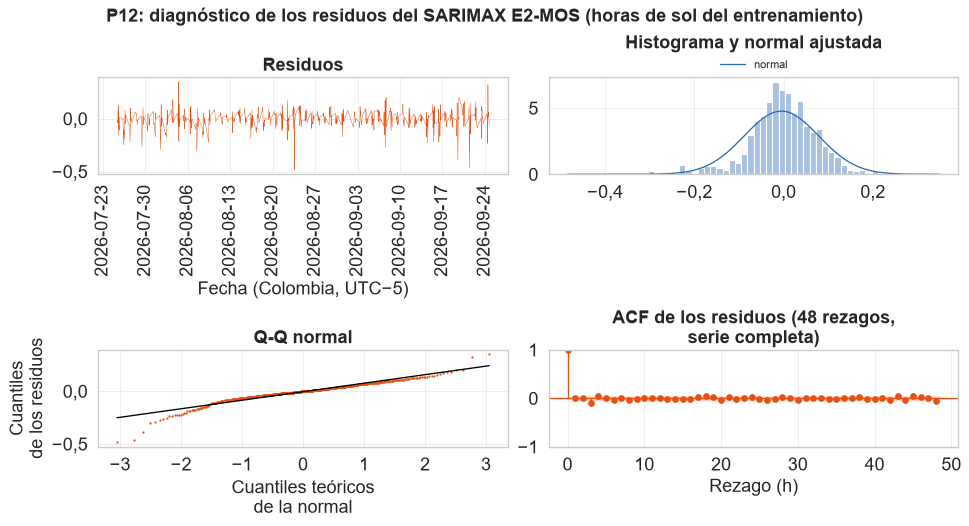

49 filas x 10 columnas; primeras 10:


,acf,acf_ic95_inf,acf_ic95_sup,pacf,pacf_ic95_inf,pacf_ic95_sup,acf_significativa,pacf_significativa,ljung_box_q,ljung_box_p
rezago,,,,,,,,,,
0,1.0000,0.0000,0.0000,1.0000,0.000,0.000,True,True,NaN,NaN
1,0.0058,-0.0520,0.0520,0.0058,-0.052,0.052,False,False,0.0473,0.8278
2,-0.0027,-0.0520,0.0520,-0.0027,-0.052,0.052,False,False,0.0576,0.9716
3,-0.0969,-0.0520,0.0520,-0.0969,-0.052,0.052,True,True,13.4608,0.0037
4,0.0567,-0.0525,0.0525,0.0584,-0.052,0.052,True,True,18.0584,0.0012
5,0.0070,-0.0526,0.0526,0.0056,-0.052,0.052,False,False,18.1283,0.0028
6,-0.0322,-0.0526,0.0526,-0.0420,-0.052,0.052,False,False,19.6127,0.0032
7,-0.0036,-0.0527,0.0527,0.0086,-0.052,0.052,False,False,19.6309,0.0064
8,-0.0294,-0.0527,0.0527,-0.0320,-0.052,0.052,False,False,20.8675,0.0075


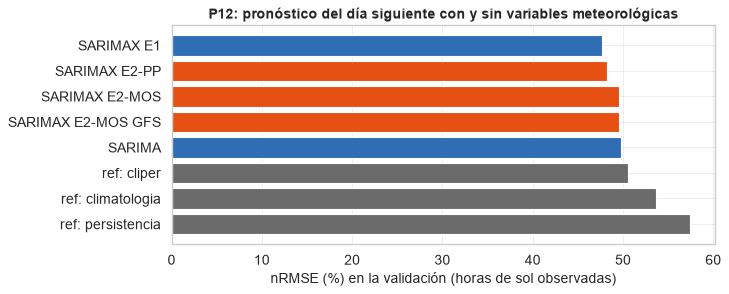

8 filas x 8 columnas; primeras 8:


,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2,skill_vs_cliper
modelo,,,,,,,,
SARIMA,178,0.1336,0.1760,-0.0006,37.7879,49.7713,0.2863,0.0155
SARIMAX E1,178,0.1229,0.1684,0.0063,34.7758,47.6396,0.3461,0.0577
SARIMAX E2-MOS,178,0.1265,0.1752,0.0257,35.7830,49.5521,0.2926,0.0199
SARIMAX E2-PP,178,0.1275,0.1706,0.0003,36.0756,48.2496,0.3293,0.0456
SARIMAX E2-MOS GFS,178,0.1323,0.1752,-0.0021,37.4276,49.5632,0.2922,0.0196
ref: persistencia,167,0.1470,0.2039,0.0055,41.3458,57.3643,0.0707,-0.1407
ref: climatologia,178,0.1557,0.1895,-0.0299,44.0386,53.6039,0.1721,-0.0603
ref: cliper,178,0.1289,0.1787,-0.0155,36.4563,50.5565,0.2636,0.0000


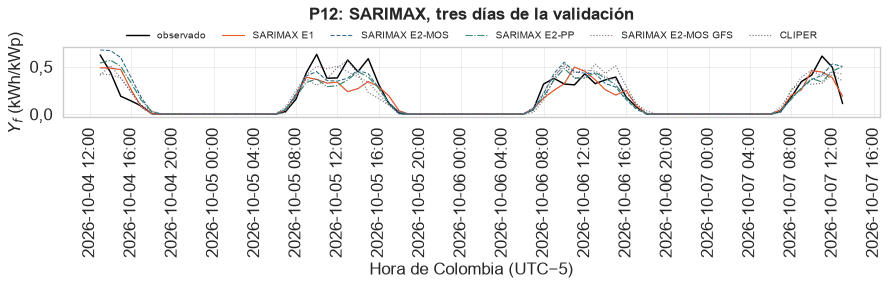

73 filas x 6 columnas; primeras 10:


,observado,SARIMAX E1,SARIMAX E2-MOS,SARIMAX E2-PP,SARIMAX E2-MOS GFS,CLIPER
2026-10-04 13:00:00-05:00,0.6244,0.4895,0.6764,0.5384,0.4259,0.4093
2026-10-04 14:00:00-05:00,0.4430,0.4853,0.6708,0.5695,0.4144,0.5124
2026-10-04 15:00:00-05:00,0.1893,0.4706,0.5967,0.5061,0.3819,0.3818
2026-10-04 16:00:00-05:00,0.1405,0.2580,0.3860,0.3316,0.2307,0.2375
2026-10-04 17:00:00-05:00,0.0868,0.0794,0.1740,0.1460,0.0982,0.0688
2026-10-04 18:00:00-05:00,0.0067,0.0070,0.0226,0.0292,0.0346,0.0045
2026-10-04 19:00:00-05:00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2026-10-04 20:00:00-05:00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2026-10-04 21:00:00-05:00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2026-10-04 22:00:00-05:00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**Diebold-Mariano (h = 24, corrección HLN)**

,n,dm,p_valor,diferencia_media
SARIMAX E2-MOS vs SARIMAX E2-MOS GFS,178.0,-0.0026,0.9979,-0.0000
SARIMAX E2-MOS vs ref: cliper,178.0,-0.3722,0.7102,-0.0013
SARIMAX E2-MOS vs SARIMA,178.0,-0.0502,0.9600,-0.0003
SARIMAX E2-MOS vs SARIMAX E2-PP,178.0,0.5305,0.5964,0.0016
SARIMAX E1 vs SARIMAX E2-MOS,178.0,NaN,NaN,NaN


**Observaciones.** Con el Yr observado del día objetivo (E1) el SARIMAX llega a 47,6 % de nRMSE: es el límite superior de lo que aporta conocer el tiempo. Con el pronóstico real a un día (E2-MOS) el SARIMAX queda en 49,6 %, frente a 49,8 % del SARIMA sin exógenas y 50,6 % de CLIPER (skill 2,0 %, Diebold-Mariano p = 0,710). Entrenar con observaciones y aplicar con pronósticos (E2-PP) da 48,2 %: aquí PP queda por debajo de MOS (Diebold-Mariano p = 0,60), así que en esta localidad entrenar con el pronóstico no aporta frente a entrenar con la observación. **Fuente del pronóstico.** Con el pronóstico GFS en lugar de IFS 0,25° el SARIMAX E2-MOS queda en 49,6 % (Diebold-Mariano IFS frente a GFS p = 0,998).

In [48]:
# Sección 9.1. Unidad principal: escenarios y fuente del pronóstico
if MODELABLE:
    def exog_yr(n, inv, fuente_df, indice):
        """Yr de la fuente para la orientación del inversor. La regresión del SARIMAX no admite exógenas
        faltantes: los huecos diurnos de la fuente se cubren con el análisis IFS de la misma hora (de noche
        Yr es 0). Rellenar con 0 de día sesgaría beta hacia abajo (horas con producción y Yr = 0)."""
        def yr_de(df):
            f = df.reindex(indice)
            poa, _ = obj.poa_inversor(f["ghi"], f["dni"], f["dhi"], lugar, inv.inclinacion, inv.azimut, caras=obj.caras_de(inv))
            return poa / 1000.0
        yr = yr_de(fuente_df)
        if yr.isna().any() and fuente_df is not FUENTES["ifs_analisis"]:
            yr = yr.fillna(yr_de(FUENTES["ifs_analisis"]))
        return yr.interpolate(limit=3).fillna(0.0).rename("yr").to_frame()

    orden_s, est_s = ORDEN["SARIMA"]
    tr0 = etq_h[n0] == "entrenamiento"
    XE = {"E1": exog_yr(n0, inv0, IRR["E1"], y0.index), "E2": exog_yr(n0, inv0, IRR["E2"], y0.index)}
    if "gfs_pronostico_d1" in FUENTES:
        XE["E2-GFS"] = exog_yr(n0, inv0, FUENTES["gfs_pronostico_d1"], y0.index)
    def estable_x(aj):
        # Autorregresivo estable y media móvil invertible: con una raíz de la media móvil dentro del círculo unidad el filtro
        # de Kalman diverge y los pronósticos salen NaN (sarima.estable solo mira el autorregresivo)
        if not sarima.estable(aj):
            return False
        raices_ma = np.atleast_1d(np.asarray(aj.maroots))
        return bool(np.all(np.abs(raices_ma) >= 1 - 1e-3)) if raices_ma.size else True

    # Con pocas semanas de entrenamiento, el orden del SARIMA puede dar un SARIMAX explosivo o no invertible en algún
    # escenario. Entonces se reajustan todos los escenarios con un orden más simple, el mismo para todos (comparables)
    ORDENES_X = [(orden_s, est_s), ((1, 0, 0), (1, 0, 1, 24)), ((1, 0, 0), (1, 0, 0, 24))]
    for orden_x, est_x in ORDENES_X:
        AJ_X = {}
        for k, xk in (("E1", "E1"), ("E2-MOS", "E2"), ("E2-MOS GFS", "E2-GFS")):
            if xk in XE:
                with tiempos.medir(f"SARIMAX {k}", "ajuste", n0, observaciones=int(y0[tr0].notna().sum())):
                    AJ_X[k] = sarima.ajustar(y0[tr0], orden_x, est_x, exog=XE[xk][tr0])
        if all(estable_x(a) for a in AJ_X.values()):
            break
    if (orden_x, est_x) != (orden_s, est_s):
        display(Markdown(f"**Orden del SARIMAX.** Con el orden del SARIMA, {orden_s} {est_s}, algún escenario del SARIMAX queda "
                         f"explosivo o no invertible (sus pronósticos divergen). Todos los escenarios se ajustan con {orden_x} {est_x}, "
                         "el orden más simple que es estable en todos, para que sigan siendo comparables."))
    ORDEN["SARIMAX"] = (orden_x, est_x)
    PRED_X = {}
    with tiempos.medir("SARIMAX E1", "prediccion_validacion", n0, dias=len(dias_val)):
        PRED_X["SARIMAX E1"] = postproceso(sarima.pronostico_por_origen(AJ_X["E1"], y0, origen(dias_val), 24, XE["E1"]), OBJ_H[n0])
    with tiempos.medir("SARIMAX E2-MOS", "prediccion_validacion", n0, dias=len(dias_val)):
        PRED_X["SARIMAX E2-MOS"] = postproceso(sarima.pronostico_por_origen(AJ_X["E2-MOS"], y0, origen(dias_val), 24, XE["E2"]), OBJ_H[n0])
    PRED_X["SARIMAX E2-PP"] = postproceso(sarima.pronostico_por_origen(AJ_X["E1"], y0, origen(dias_val), 24, XE["E1"], exog_futuro=XE["E2"]), OBJ_H[n0])
    if "E2-MOS GFS" in AJ_X:
        PRED_X["SARIMAX E2-MOS GFS"] = postproceso(sarima.pronostico_por_origen(AJ_X["E2-MOS GFS"], y0, origen(dias_val), 24, XE["E2-GFS"]), OBJ_H[n0])
    # Vista horaria de la sección 6.5: Yf observado (con los huecos de la telemetría) y su pronóstico del día anterior
    yf_v14 = OBJ_H[n0]["yf"].loc[v14]
    paneles = {"Yf": (pd.DataFrame({"observado": yf_v14, "pronóstico a un día (SARIMAX E2-MOS)": PRED_X["SARIMAX E2-MOS"].reindex(yf_v14.index)}),
                      "kWh/kWp"), **PANELES_EXO}
    datos_p = pd.concat({k: (v if isinstance(v, pd.DataFrame) else v.to_frame(k)) for k, (v, _) in paneles.items()}, axis=1)
    fig(gr.objetivo_y_exogenas(paneles, f"{n0}: rendimiento y variables meteorológicas, dos semanas de la validación"),
        f"objetivo_exogenas_horario_{n0}", datos_p)
    obs0 = observado(OBJ_H[n0])
    TABLA_I = [{"modelo": "SARIMA", **met.evaluar(y0.reindex(PRED_VAL["SARIMA"].index), PRED_VAL["SARIMA"], obs0.reindex(PRED_VAL["SARIMA"].index))}]
    for k, p_ in PRED_X.items():
        TABLA_I.append({"modelo": k, **met.evaluar(y0.reindex(p_.index), p_, obs0.reindex(p_.index))})
    for c in ("persistencia", "climatologia", "cliper"):
        p_ = REF_H[c].reindex(PRED_VAL["SARIMA"].index)
        TABLA_I.append({"modelo": f"ref: {c}", **met.evaluar(y0.reindex(p_.index), p_, obs0.reindex(p_.index))})
    TABLA_I = pd.DataFrame(TABLA_I)
    TABLA_I["skill_vs_cliper"] = 1 - TABLA_I["rmse"] / TABLA_I.set_index("modelo").loc["ref: cliper", "rmse"]
    display(Markdown(f"**{n0}: pronóstico del día siguiente (H01DH) en la validación, con y sin exógenas**")); display(TABLA_I.round(4))
    for k in ("E1", "E2-MOS"):
        display(Markdown(f"**Ecuación SARIMAX {k}:**\n\n$$" + sarima.ecuacion(AJ_X[k]) + "$$"))
        COEF_X = sarima.coeficientes(AJ_X[k])
        display(COEF_X.round(4)); gr.guardar_datos(COEF_X, f"{PREF}coeficientes_sarimax_{k.lower().replace('-', '_')}_{n0}")
    RES_X = sarima.residuos(AJ_X["E2-MOS"])
    if len(RES_X) > 24 * 7:
        TAB_RES_X = sarima.tabla_autocorrelacion(RES_X, 48)
        fig(gr.diagnostico_residuos(RES_X, f"{n0}: diagnóstico de los residuos del SARIMAX E2-MOS (horas de sol del entrenamiento)",
                                    mascara=OBJ_H[n0]["yr_cs"] > 0.05),
            f"residuos_sarimax_e2_mos_{n0}", TAB_RES_X)
    else:
        # Con pocas semanas en el régimen estable el filtro no deja residuos suficientes para el diagnóstico
        display(Markdown(f"**{n0}: residuos insuficientes ({len(RES_X)}) para el diagnóstico del SARIMAX E2-MOS**; "
                         "el modelo se evalúa igual en la validación y en la prueba."))
    # gr.mostrar(TAB_RES_X, todas=True)   # ACF, PACF y Ljung-Box de los residuos en los 48 rezagos
    f, ax = plt.subplots(figsize=(9, 3.6))
    orden_b = TABLA_I.sort_values("nrmse_pct")
    ax.barh(orden_b["modelo"], orden_b["nrmse_pct"], color=[config.COLOR_NEUTRO if m.startswith("ref") else
            (config.COLOR_PRINCIPAL if "E2" in m else config.COLOR_SECUNDARIO) for m in orden_b["modelo"]])
    ax.invert_yaxis(); ax.set_xlabel("nRMSE (%) en la validación (horas de sol observadas)")
    ax.set_title(f"{n0}: pronóstico del día siguiente con y sin variables meteorológicas")
    fig(f, f"sarimax_comparacion_{n0}", TABLA_I.set_index("modelo"))
    iv_ = PRED_X["SARIMAX E2-MOS"].index
    v3 = slice(iv_[len(iv_) // 2], iv_[len(iv_) // 2] + pd.Timedelta("3D"))
    f, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(y0.loc[v3].index.tz_convert(config.ZONA), y0.loc[v3], color="black", lw=1.3, label="observado")
    for (k, s_), e_ in zip(PRED_X.items(), gr.estilos_series(len(PRED_X))):
        ax.plot(s_.loc[v3].index.tz_convert(config.ZONA), s_.loc[v3], color=e_["color"], linestyle=e_["linestyle"], lw=1, label=k)
    ax.plot(REF_H["cliper"].loc[v3].index.tz_convert(config.ZONA), REF_H["cliper"].loc[v3], color=config.COLOR_NEUTRO, lw=1, ls=":", label="CLIPER")
    ax.set_ylabel("Yf (kWh/kWp)"); ax.legend(fontsize=7); ax.set_title(f"{n0}: SARIMAX, tres días de la validación")
    fig(f, f"sarimax_ejemplo_{n0}", pd.DataFrame({"observado": y0.loc[v3], **{k: s_.loc[v3] for k, s_ in PRED_X.items()},
                                                 "CLIPER": REF_H["cliper"].loc[v3]}))
    DM_I = {}
    idx_v = PRED_X["SARIMAX E2-MOS"].index
    if "SARIMAX E2-MOS GFS" in PRED_X:
        DM_I["SARIMAX E2-MOS vs SARIMAX E2-MOS GFS"] = met.diebold_mariano(
            y0.reindex(idx_v), PRED_X["SARIMAX E2-MOS"].reindex(idx_v), PRED_X["SARIMAX E2-MOS GFS"].reindex(idx_v), h=24, observado=obs0.reindex(idx_v))
    for a, b in (("SARIMAX E2-MOS", "ref: cliper"), ("SARIMAX E2-MOS", "SARIMA"), ("SARIMAX E2-MOS", "SARIMAX E2-PP"), ("SARIMAX E1", "SARIMAX E2-MOS")):
        pa = PRED_X.get(a, PRED_VAL.get(a))
        pb = REF_H["cliper"].reindex(idx_v) if b == "ref: cliper" else PRED_X.get(b, PRED_VAL.get(b))
        DM_I[f"{a} vs {b}"] = met.diebold_mariano(y0.reindex(idx_v), pa.reindex(idx_v), pb.reindex(idx_v), h=24, observado=obs0.reindex(idx_v))
    display(Markdown("**Diebold-Mariano (h = 24, corrección HLN)**")); display(pd.DataFrame(DM_I).T.round(4))
    fi = TABLA_I.set_index("modelo")
    e1, e2 = fi.loc["SARIMAX E1", "nrmse_pct"], fi.loc["SARIMAX E2-MOS", "nrmse_pct"]
    beta = {k: float(a.params.get("yr", np.nan)) for k, a in AJ_X.items()}
    p_e1e2 = DM_I["SARIMAX E1 vs SARIMAX E2-MOS"]["p_valor"]
    texto_e1 = (f"Con el Yr observado del día objetivo (E1) el SARIMAX llega a {e1:.1f} % de nRMSE: es el límite superior de lo "
                f"que aporta conocer el tiempo. " if e1 <= e2 else
                f"Contra lo esperado, con el Yr observado del día objetivo (E1) el SARIMAX queda en {e1:.1f} %, por encima del "
                f"pronóstico real (E2-MOS, {e2:.1f} %), aunque la diferencia {'no ' if p_e1e2 >= 0.05 else ''}es significativa "
                f"(Diebold-Mariano p = {p_e1e2:.2f}). El coeficiente β es menor con la irradiancia observada ({beta['E1']:.2f}) que con "
                f"la pronosticada ({beta['E2-MOS']:.2f}): la irradiancia satelital horaria tiene más ruido que el pronóstico, que es "
                f"suave, y en un modelo que trabaja con diferencias estacionales ese ruido atenúa la pendiente (sesgo por errores en "
                f"las variables). ")
    display(Markdown(
        f"**Observaciones.** {texto_e1}Con el pronóstico real a un día (E2-MOS) el SARIMAX queda en {e2:.1f} %, frente a "
        f"{fi.loc['SARIMA', 'nrmse_pct']:.1f} % del SARIMA sin exógenas y {fi.loc['ref: cliper', 'nrmse_pct']:.1f} % de CLIPER "
        f"(skill {100 * fi.loc['SARIMAX E2-MOS', 'skill_vs_cliper']:.1f} %, Diebold-Mariano p = "
        f"{DM_I['SARIMAX E2-MOS vs ref: cliper']['p_valor']:.3f}). Entrenar con observaciones y aplicar con pronósticos (E2-PP) da "
        f"{fi.loc['SARIMAX E2-PP', 'nrmse_pct']:.1f} %" + (
            (": entrenar con el propio pronóstico (MOS) es " +
             ("significativamente mejor" if DM_I['SARIMAX E2-MOS vs SARIMAX E2-PP']['p_valor'] < 0.05 else "algo mejor, aunque sin significancia")
             + ", porque el modelo aprende también el sesgo del pronóstico.")
            if e2 <= fi.loc['SARIMAX E2-PP', 'nrmse_pct'] else
            (f": aquí PP queda {'significativamente ' if DM_I['SARIMAX E2-MOS vs SARIMAX E2-PP']['p_valor'] < 0.05 else ''}"
             f"por debajo de MOS (Diebold-Mariano p = {DM_I['SARIMAX E2-MOS vs SARIMAX E2-PP']['p_valor']:.2f}), así que en esta "
             f"localidad entrenar con el pronóstico no aporta frente a entrenar con la observación."))
        + ((f" **Fuente del pronóstico.** Con el pronóstico GFS en lugar de IFS 0,25° el SARIMAX E2-MOS queda en "
            f"{fi.loc['SARIMAX E2-MOS GFS', 'nrmse_pct']:.1f} % (Diebold-Mariano IFS frente a GFS p = "
            f"{DM_I['SARIMAX E2-MOS vs SARIMAX E2-MOS GFS']['p_valor']:.3f}).") if "SARIMAX E2-MOS GFS" in fi.index else "")))
    res.registrar(f"localidades.{GRUPO}.modelos.sarimax_h2_{n0}", {"tabla": fi.round(5).to_dict(orient="index"),
                  "orden": f"{orden_x} x {est_x}", "orden_sarima": f"{orden_s} x {est_s}",
                  "ecuaciones": {k: sarima.ecuacion(v) for k, v in AJ_X.items()},
                  "beta_yr": beta, "diebold_mariano": DM_I})

### 9.2. Todas las unidades de la localidad

Se aplican el SARIMA y el SARIMAX E2-MOS (el escenario operativo) con el mismo orden a cada inversor y a
cada planta con más de un inversor, reestimando los parámetros con el entrenamiento de cada unidad.

modelo,SARIMA,SARIMAX E2-MOS,ref: cliper,ref: persistencia
unidad,,,,
P12,49.8,49.6,50.6,57.4
P12I0102,48.4,46.2,49.7,56.6
P12I0202,50.9,50.0,51.5,58.1
P13I0101,45.0,45.4,47.4,53.4


nRMSE (%) del pronóstico del día siguiente en la validación por unidad y modelo.

**Lectura.** El SARIMAX E2-MOS tiene menos error que CLIPER en 4 de 4 unidades. Su nRMSE va de 45,4 % en P13I0101 a 50,0 % en P12I0202. Como todas comparten el pronóstico meteorológico de la localidad, la diferencia entre unidades viene de cada inversor (orientación, telemetría y capacidad efectiva), no del recurso solar.

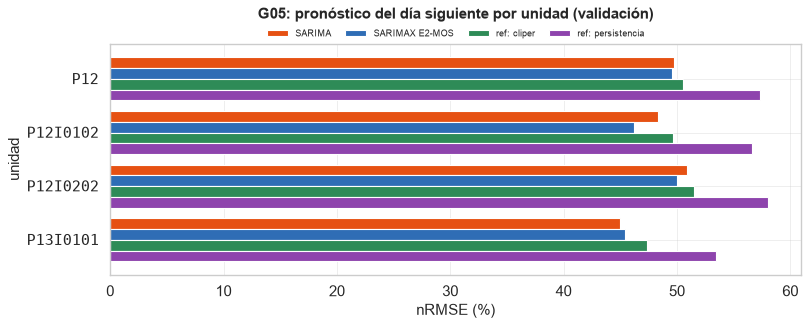

4 filas x 4 columnas; primeras 4:


modelo,SARIMA,SARIMAX E2-MOS,ref: cliper,ref: persistencia
unidad,,,,
P12,49.7713,49.5521,50.5565,57.3643
P12I0102,48.3672,46.1996,49.6615,56.5842
P12I0202,50.8806,49.9924,51.5186,58.0671
P13I0101,45.0176,45.4383,47.3554,53.4133


In [49]:
# Sección 9.2. Todas las unidades de la localidad
if MODELABLE:
    TABLA_U = []
    PRED_U = {}
    for n in (list(OBJ_H) if not RAPIDO else [n0]):
        inv_n = inv0 if nom.es_planta(n) else INV.loc[n]
        yn = y_h[n]
        trn = etq_h[n] == "entrenamiento"
        if yn[trn].notna().sum() < 24 * 30:
            continue
        xn = exog_yr(n, inv_n, IRR["E2"], yn.index)
        ajs = {"SARIMA": sarima.ajustar(yn[trn], orden_s, est_s),
               "SARIMAX E2-MOS": sarima.ajustar(yn[trn], orden_x, est_x, exog=xn[trn])}
        obs_n = observado(OBJ_H[n])
        refn = refs.horarias_h2(OBJ_H[n], trn)
        for k, a in ajs.items():
            p_ = postproceso(sarima.pronostico_por_origen(a, yn, origen(dias_val), 24, xn if "X" in k else None), OBJ_H[n])
            PRED_U[(n, k)] = p_
            TABLA_U.append({"unidad": n, "modelo": k, **met.evaluar(yn.reindex(p_.index), p_, obs_n.reindex(p_.index))})
        for c in ("persistencia", "cliper"):
            p_ = refn[c].reindex(PRED_U[(n, "SARIMA")].index)
            TABLA_U.append({"unidad": n, "modelo": f"ref: {c}", **met.evaluar(yn.reindex(p_.index), p_, obs_n.reindex(p_.index))})
    TABLA_U = pd.DataFrame(TABLA_U)
    if TABLA_U.empty:                                    # ninguna unidad con 30 días de entrenamiento horario (unidad reciente)
        display(Markdown("Ninguna unidad tiene 30 días de entrenamiento horario: la comparación por unidad no se calcula."))
    else:
        PIV_U = TABLA_U.pivot(index="unidad", columns="modelo", values="nrmse_pct")
        display(PIV_U.round(1))
        display(Markdown("nRMSE (%) del pronóstico del día siguiente en la validación por unidad y modelo."))
        if {"SARIMAX E2-MOS", "ref: cliper"} <= set(PIV_U.columns):
            sx_u = PIV_U["SARIMAX E2-MOS"].dropna()
            gana_u = sx_u.index[sx_u < PIV_U["ref: cliper"].reindex(sx_u.index)]
            no_gana = [u for u in sx_u.index if u not in gana_u]
            display(Markdown(
                f"**Lectura.** El SARIMAX E2-MOS tiene menos error que CLIPER en {len(gana_u)} de {len(sx_u)} unidades"
                + (f" (no en {', '.join(no_gana)})" if no_gana else "") + f". Su nRMSE va de {sx_u.min():.1f} % en "
                f"{sx_u.idxmin()} a {sx_u.max():.1f} % en {sx_u.idxmax()}. Como todas comparten el pronóstico meteorológico de "
                "la localidad, la diferencia entre unidades viene de cada inversor (orientación, telemetría y capacidad "
                "efectiva), no del recurso solar."))
        f, ax = plt.subplots(figsize=(10, 0.6 * len(PIV_U) + 1.6))
        PIV_U.plot.barh(ax=ax, color=[config.PALETA[i] for i in range(PIV_U.shape[1])], width=0.8)
        ax.invert_yaxis(); ax.set_xlabel("nRMSE (%)"); ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
        ax.set_title(f"{GRUPO}: pronóstico del día siguiente por unidad (validación)")
        fig(f, "sarimax_unidades", PIV_U)
        if ES_PRINCIPAL: res.registrar(f"localidades.{GRUPO}.modelos.sarimax_h2_unidades", PIV_U.round(3).to_dict(orient="index"))

### 9.3. Horizonte H3: rendimiento diario de 1 a 7 días

En escala diaria la serie no tiene ciclo de 24 h y, con unos 17 meses, tampoco se puede estimar un ciclo
anual; se usa un ARIMA(p, d, q) elegido por AIC y un SARIMAX con el Yr diario pronosticado. Para cada día
de antelación h se usa el pronóstico IFS 0,25 archivado con esa misma antelación (Open-Meteo Previous
Runs, `previousday` = h): el pronóstico a 5 días se evalúa con lo que el modelo numérico sabía 5 días
antes. El PR diario se modela con ARIMA, porque al estar normalizado por Yr el tiempo influye poco en él.
Todas las antelaciones se evalúan en los mismos días, los de la validación: el pronóstico a 7 días del
primer día de la validación se emite siete días antes, y ningún día objetivo cae en la prueba.

**P12: nRMSE (%) del Yf diario por días de antelación (validación)**

h,1,2,3,4,5,6,7
modelo,,,,,,,
"ARIMA(0, 0, 1)",42.9,44.4,44.4,44.4,44.4,44.4,44.4
"SARIMAX(0, 0, 1) E2-MOS",32.8,36.2,35.6,37.2,35.3,39.5,41.8
ref: climatologia,42.7,42.7,42.7,42.7,42.7,42.7,42.7
ref: cliper,41.2,42.7,42.7,42.6,38.9,42.7,42.7
ref: persistencia,33.4,53.5,64.7,57.1,44.9,43.3,46.8
ref: persistencia_inteligente,32.7,50.8,61.0,53.0,43.4,41.0,44.9


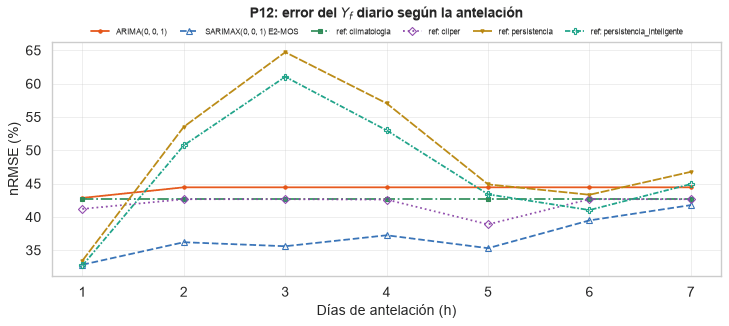

7 filas x 6 columnas; primeras 7:


modelo,"ARIMA(0, 0, 1)","SARIMAX(0, 0, 1) E2-MOS",ref: climatologia,ref: cliper,ref: persistencia,ref: persistencia_inteligente
h,,,,,,
1,42.8582,32.8309,42.6636,41.2093,33.4437,32.7138
2,44.4477,36.2052,42.6636,42.6636,53.5373,50.7506
3,44.4477,35.6045,42.6636,42.6636,64.7360,61.0415
4,44.4477,37.2482,42.6636,42.6088,57.0507,53.0046
5,44.4477,35.3121,42.6636,38.8853,44.8869,43.3925
6,44.4477,39.4819,42.6636,42.6636,43.3311,41.0339
7,44.4477,41.7750,42.6636,42.6636,46.7760,44.9397


**Lectura (Yf).** El error del SARIMAX(0, 0, 1) E2-MOS crece de 32,8 % a un día a 41,8 % a siete: el pronóstico meteorológico pierde precisión con la antelación. La mejor referencia es persistencia_inteligente a un día (32,7 %) y climatologia a siete (42,7 %); el modelo no la supera en todo el horizonte.

**P12: nRMSE (%) del PR diario por días de antelación (validación)**

h,1,2,3,4,5,6,7
modelo,,,,,,,
"ARIMA(0, 0, 1)",27.2,27.2,27.2,27.2,27.2,27.2,27.2
ref: climatologia,27.2,27.2,27.2,27.2,27.2,27.2,27.2
ref: cliper,27.2,27.2,27.2,27.3,27.0,27.2,26.9
ref: persistencia,36.5,37.3,42.4,35.9,34.7,33.0,32.5


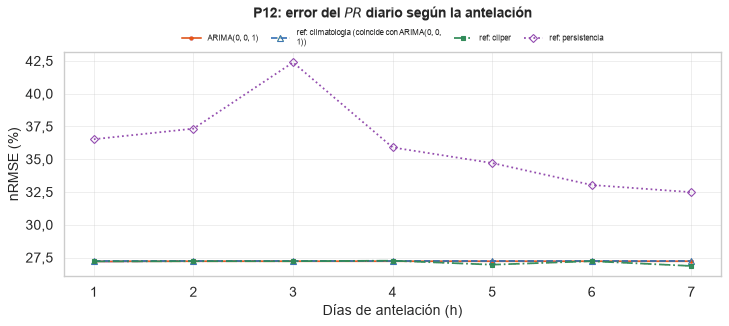

7 filas x 4 columnas; primeras 7:


modelo,"ARIMA(0, 0, 1)",ref: climatologia,ref: cliper,ref: persistencia
h,,,,
1,27.2018,27.2263,27.2109,36.5292
2,27.2229,27.2263,27.2263,37.3342
3,27.2229,27.2263,27.2263,42.3884
4,27.2229,27.2263,27.2637,35.9002
5,27.2229,27.2263,26.9592,34.7102
6,27.2229,27.2263,27.2263,33.0378
7,27.2229,27.2263,26.8614,32.4883


**Lectura (PR).** El error del ARIMA(0, 0, 1) casi no cambia de un día (27,2 %) a siete (27,2 %). La mejor referencia es CLIPER a un día (27,2 %) y CLIPER a siete (26,9 %); el modelo no la supera en todo el horizonte.

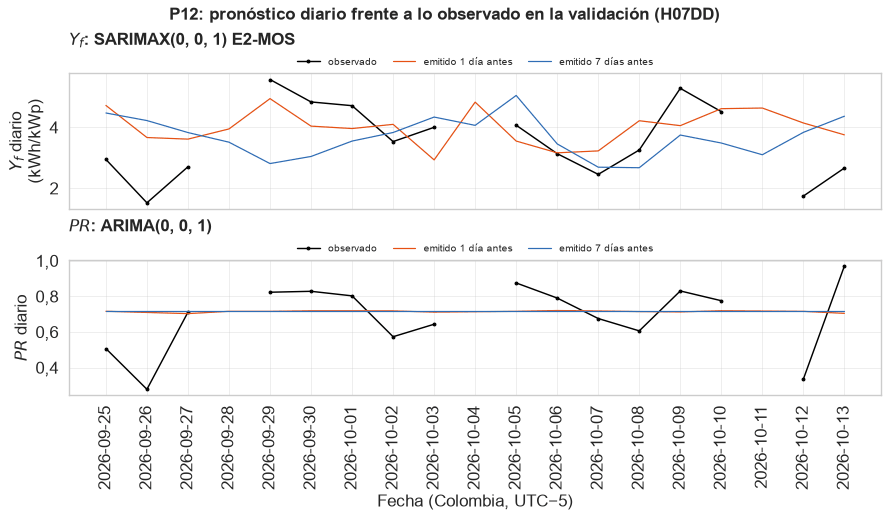

19 filas x 16 columnas; primeras 10:


yf                                                                pr                                                          
h               h1      h2      h3      h4      h5      h6      h7 observado      h1      h2      h3      h4      h5      h6      h7 observado
2026-09-25  4.7201  4.1788  3.7772  4.3667  4.3740  4.1423  4.4724    2.9468  0.7166  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.5070
2026-09-26  3.6668  4.2461  4.0207  3.9816  3.9159  4.0966  4.2239    1.5229  0.7100  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.2784
2026-09-27  3.6141  3.0610  3.4238  4.0640  3.3574  3.5459  3.8298    2.7066  0.7034  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.7115
2026-09-28  3.9488  2.7666  3.5359  3.5417  3.8164  3.3737  3.5133       NaN  0.7164  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162       NaN
2026-09-29  4.9437  4.1399  3.3624  3.5457  3.8009  2.8778  2.8119    5.5714  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.8236
2026-09-30  4.0407  2.7764  3.3670  3.6426  3.6264  3.7294  3.0449    4.8347  0.7193  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.8288
2026-10-01  3.9616  4.0780  3.3410  3.7771  3.6635  3.7935  3.5502    4.7122  0.7194  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.8032
2026-10-02  4.0988  3.9888  4.1245  3.9261  3.9409  3.3455  3.8314    3.5335  0.7186  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.5737
2026-10-03  2.9320  4.2050  3.0534  2.6671  3.5880  3.6203  4.3388    4.0017  0.7119  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162    0.6439
2026-10-04  4.8292  2.6140  3.4932  3.9385  4.4605  3.9826  4.0663       NaN  0.7142  0.7162  0.7162  0.7162  0.7162  0.7162  0.7162       NaN

In [50]:
# Sección 9.3. Horizonte H3: rendimiento diario de 1 a 7 días
if MODELABLE:
    yd = {n: OBJ_D[n]["yf"].where(OBJ_D[n]["en_regimen"]).asfreq("D") for n in OBJ_D}
    prd = {n: OBJ_D[n]["pr"].where(OBJ_D[n]["en_regimen"]).asfreq("D") for n in OBJ_D}
    etq_d = {n: part.etiquetar(yd[n].index).to_numpy() for n in yd}
    # Yr diario pronosticado por antelación (h = 1..7) para la orientación de la unidad principal
    def yr_diario(fuente_h, inv):
        poa, _ = obj.poa_inversor(fuente_h["ghi"], fuente_h["dni"], fuente_h["dhi"], lugar, inv.inclinacion, inv.azimut, caras=obj.caras_de(inv))
        s = (poa / 1000.0).copy(); s.index = (s.index - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).tz_localize(None)
        return s.resample("D").sum(min_count=20)
    YR_LEAD = {h: yr_diario(caract.irradiancia_fuente(crudos, "ifs025_pronostico_d1", lugar, filtro={"previousday": h}), inv0) for h in range(1, 8)}
    def exog_lead(o, ventana):
        return pd.DataFrame({"yr": [YR_LEAD[h].get(d, np.nan) for h, d in enumerate(ventana, start=1)]}, index=ventana).ffill().fillna(0)

    def eval_h(pr, y, obs):
        filas = []
        for h, g in pr.groupby("h"):
            s = g.set_index("t")["yhat"]
            filas.append({"h": h, **met.evaluar(y.reindex(s.index), s, obs.reindex(s.index))})
        return pd.DataFrame(filas)

    # Cada antelación h se evalúa en los mismos días, los de la validación: los orígenes empiezan 7 días antes (un origen
    # del entrenamiento solo usa los datos hasta ese día) y se quitan los días objetivo posteriores, que son de la prueba
    origen_d = [d - pd.Timedelta(days=1) for d in pd.date_range(dias_val[0] - pd.Timedelta(days=6), dias_val[-1], freq="D")]
    def en_validacion(p):
        return p[p["t"].isin(dias_val)].reset_index(drop=True)
    TABLA_H3, SERIE_H3 = [], {}
    for objetivo, series in (("yf", yd), ("pr", prd)):
        y = series[n0]
        trd = etq_d[n0] == "entrenamiento"
        obs_d = y.notna()
        b = sarima.buscar_orden(y[trd], p=(0, 1, 2), q=(0, 1, 2), d=(0,))
        x1 = YR_LEAD[1].reindex(y.index).ffill().fillna(0).to_frame("yr")
        # El orden de menor AIC cuyo ajuste es estable (y, para Yf, también el del SARIMAX con el Yr pronosticado). Sin
        # forzar la estacionariedad, un ajuste puede quedar explosivo con un AIC artificialmente bajo y dar pronósticos
        # que crecen sin límite; esos órdenes se descartan.
        o_d, a_arima, a_x = None, None, None
        for o_ in b.dropna(subset=["aic"])["orden"]:
            a_ = sarima.ajustar(y[trd], tuple(o_))
            ax_ = sarima.ajustar(y[trd], tuple(o_), exog=x1[trd]) if objetivo == "yf" else None
            if sarima.estable(a_) and (ax_ is None or sarima.estable(ax_)):
                o_d, a_arima, a_x = tuple(o_), a_, ax_
                break
        if o_d is None:
            o_d = (1, 0, 0)
            a_arima = sarima.ajustar(y[trd], o_d)
            a_x = sarima.ajustar(y[trd], o_d, exog=x1[trd]) if objetivo == "yf" else None
        ordenes_ = [tuple(o_) for o_ in b.dropna(subset=["aic"])["orden"]]
        descartados_h3 = ordenes_[:ordenes_.index(o_d)] if o_d in ordenes_ else ordenes_
        if descartados_h3:
            display(Markdown(f"**{objetivo}:** órdenes con menor AIC descartados por un ajuste explosivo: {', '.join(map(str, descartados_h3))}; "
                             f"se usa {o_d}."))
        pr_ = en_validacion(sarima.pronostico_por_origen(a_arima, y, origen_d, 7))
        pr_["yhat"] = pr_["yhat"].clip(lower=0)
        TABLA_H3.append(eval_h(pr_, y, obs_d).assign(objetivo=objetivo, modelo=f"ARIMA{o_d}"))
        if objetivo == "yf":
            prx = en_validacion(sarima.pronostico_por_origen(a_x, y, origen_d, 7, x1, exog_futuro=exog_lead))
            prx["yhat"] = prx["yhat"].clip(lower=0)
            H3_YF = {"orden": o_d, "ajuste": a_x, "exog": x1}       # modelo de 1 a 7 días para el horizonte de 30 días
            TABLA_H3.append(eval_h(prx, y, obs_d).assign(objetivo=objetivo, modelo=f"SARIMAX{o_d} E2-MOS"))
        SERIE_H3[objetivo] = (prx, y, f"SARIMAX{o_d} E2-MOS") if objetivo == "yf" else (pr_, y, f"ARIMA{o_d}")
        ent_d = part.etiquetar(OBJ_D[n0].index).to_numpy() == "entrenamiento"
        for h in range(1, 8):
            rd = refs.diarias_h3(OBJ_D[n0].where(OBJ_D[n0]["en_regimen"]), ent_d, h, objetivo)
            dias_obj = pr_.loc[pr_["h"] == h, "t"]
            for c in rd.columns:
                s = rd[c].reindex(dias_obj)
                TABLA_H3.append(pd.DataFrame([{"h": h, **met.evaluar(y.reindex(s.index), s, obs_d.reindex(s.index))}]).assign(objetivo=objetivo, modelo=f"ref: {c}"))
    TABLA_H3 = pd.concat(TABLA_H3, ignore_index=True)
    for objetivo in ("yf", "pr"):
        t = TABLA_H3[TABLA_H3["objetivo"] == objetivo].pivot(index="modelo", columns="h", values="nrmse_pct")
        display(Markdown(f"**{n0}: nRMSE (%) del {('Yf' if objetivo == 'yf' else 'PR')} diario por días de antelación (validación)**")); display(t.round(1))
        f = gr.lineas(t.T, f"{n0}: error del {('Yf' if objetivo == 'yf' else 'PR')} diario según la antelación",
                      "Días de antelación (h)", "nRMSE (%)")
        fig(f, f"h3_{objetivo}_{n0}", t.T)
        modelo_h3 = SERIE_H3[objetivo][2]
        refs_h3 = [m for m in t.index if m.startswith("ref")]
        if (modelo_h3 in t.index and refs_h3 and {1, 7} <= set(t.columns) and t.loc[modelo_h3, [1, 7]].notna().all()
                and t.loc[refs_h3, 1].notna().any() and t.loc[refs_h3, 7].notna().any()):
            e1, e7 = t.loc[modelo_h3, 1], t.loc[modelo_h3, 7]
            r1, r7 = t.loc[refs_h3, 1].idxmin(), t.loc[refs_h3, 7].idxmin()
            cambio = (f"crece de {e1:.1f} % a un día a {e7:.1f} % a siete: el pronóstico meteorológico pierde precisión con la "
                      "antelación" if e7 - e1 > 1 else f"casi no cambia de un día ({e1:.1f} %) a siete ({e7:.1f} %)")
            display(Markdown(
                f"**Lectura ({('Yf' if objetivo == 'yf' else 'PR')}).** El error del {modelo_h3} {cambio}. La mejor referencia es "
                f"{r1.removeprefix('ref: ').replace('cliper', 'CLIPER')} a un día ({t.loc[r1, 1]:.1f} %) y "
                f"{r7.removeprefix('ref: ').replace('cliper', 'CLIPER')} a siete ({t.loc[r7, 7]:.1f} %); "
                + ("el modelo queda por debajo de ella en los dos extremos." if e1 < t.loc[r1, 1] and e7 < t.loc[r7, 7]
                   else "el modelo no la supera en todo el horizonte.")))
    # Series de la validación: lo observado frente al pronóstico emitido 1 y 7 días antes, para los dos objetivos
    f, ax = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
    DATOS_SERIE_H3 = {}
    for a, (objetivo, (p_, y_, nombre)) in zip(ax, SERIE_H3.items()):
        # Los días de la validación, los mismos para las dos antelaciones
        tab = p_.pivot_table(index="t", columns="h", values="yhat").reindex(index=dias_val, columns=range(1, 8))
        xi = gr.dias_locales(tab.index)          # cada día en su medianoche local (sin zona se dibujaría 5 h antes)
        a.plot(xi, y_.reindex(tab.index).to_numpy(), color="black", lw=1.3, ls="-", marker="o", ms=2.5, label="observado")
        for h, color in ((1, config.COLOR_PRINCIPAL), (7, config.COLOR_SECUNDARIO)):
            a.plot(xi, tab[h].to_numpy(), color=color, lw=1.1, ls="-", label=f"emitido {h} día{'s' if h > 1 else ''} antes")
        a.set_ylabel("Yf diario (kWh/kWp)" if objetivo == "yf" else "PR diario")
        # El modelo va a la izquierda, encima del panel, y la leyenda corta a la derecha: ninguna tapa los datos
        a.set_title(f"{'Yf' if objetivo == 'yf' else 'PR'}: {nombre}", loc="left")
        a.legend(ncol=3, loc="lower right", bbox_to_anchor=(1.0, 1.0), frameon=False, borderaxespad=0.2)
        DATOS_SERIE_H3[objetivo] = tab.add_prefix("h").assign(observado=y_.reindex(tab.index))
    f.suptitle(f"{n0}: pronóstico diario frente a lo observado en la validación (H07DD)", fontweight="bold")
    fig(f, f"h3_series_{n0}", pd.concat(DATOS_SERIE_H3, axis=1))
    res.registrar(f"localidades.{GRUPO}.modelos.h3_{n0}", {o: TABLA_H3[TABLA_H3["objetivo"] == o].pivot(index="modelo", columns="h", values="nrmse_pct").round(3).to_dict(orient="index")
                                                            for o in ("yf", "pr")})

### 9.4. Pronóstico diario a 30 días

Pronosticamos el rendimiento específico diario (Yf, y con él la energía en kWh y el PR esperado) de cada uno de los 30
días siguientes al día de emisión D. Hasta una semana el pronóstico meteorológico aporta información, y más allá ningún
modelo numérico disponible en este trabajo supera a la climatología en irradiancia, así que combinamos dos métodos.

| Antelación | Método | Intervalo de predicción del 80 % |
|---|---|---|
| 1 a 7 días | SARIMAX diario E2-MOS de la sección 9.3, con el Yr del pronóstico IFS 0,25° emitido con esa antelación | Percentiles 10 y 90 del error del modelo en la validación para esa antelación |
| 8 a 30 días | Valor central climatológico del día del año (ERA5 2015 a 2024 en el plano del inversor, ventana de ±15 días, al nivel de NSRDB) × PR de los últimos 30 días observados | Cocientes observado / pronóstico de los percentiles 10 y 90 del error de 8 a 30 días en la validación |

Más allá de una semana ningún modelo acierta el tiempo de un día concreto, pero el valor central de 8 a 30 días se
puede elegir con datos, y para eso comparamos cuatro candidatos de simple a complejo. Son la **media** climatológica, la
**mediana**, porque la distribución diaria es asimétrica (unos pocos días nublados bajan la media por debajo del día
típico), la media ajustada por la **anomalía de los últimos 30 días**, amortiguada con su persistencia estimada en la
serie larga de ERA5 (un CLIPER a escala mensual), y la climatología de los años con la **misma fase del ONI** (la
publicada al emitir, de dos meses antes). Con los orígenes de la validación elegimos el más simple de los que no se
distinguen del mejor (conjunto de confianza de modelos sobre el error medio de 8 a 30 días de cada origen), y la prueba
lo confirma. Las **trayectorias de años análogos** (la secuencia de las mismas fechas en cada año de ERA5, por el PR
reciente) se dibujan para mostrar la variación de un día a otro que el valor central promedia, pero no entran en las
métricas.

Nada usa información posterior a D, porque el PR reciente se calcula con los días hasta D y la climatología con 2015 a
2024. El PR reciente y la climatología están al nivel de NSRDB (5.1), y el cociente residual entre el Yr de la fuente
observada y el de ERA5 en los días del entrenamiento se aplica como control de escala.

En operación, cada día el pronóstico se vuelve a emitir con los **mismos coeficientes**. Entran el rendimiento
observado del día que terminó, que actualiza la memoria del modelo y el PR reciente, y la ejecución más reciente del
modelo meteorológico (cada ejecución del modelo numérico del ECMWF se publica varias veces al día). Reestimar los
coeficientes (reentrenar) es otra cosa, y su frecuencia la decidimos con el experimento de esta sección, que compara un
modelo fijo con uno reentrenado cada 30 días y cada 7 días.

Para evaluar emitimos un pronóstico de 30 días desde cada día de la validación y de la prueba (origen rodante) y medimos
el error por antelación frente a la climatología pura y a la persistencia (el Yf del día de emisión repetido 30 días),
además del error del total mensual emitido el último día de cada mes. Un origen de finales de la validación pronostica
días de la prueba, y por eso el valor central y el intervalo se eligen y calibran solo con los días objetivo de la
validación, mientras que el error y la cobertura se miden solo en los días de la prueba, sin pasar del corte del
modelado.

**Escala de la climatología.** Fuente observada del PR: **ifs_analisis**. Con ambas fuentes al nivel de NSRDB, su Yr diario en el entrenamiento es 1,004 veces el de ERA5 en el plano de P12; la climatología se multiplica por ese factor residual para que el PR reciente y la climatología usen exactamente la misma escala.

**Valor central de 8 a 30 días** (validación; error cuadrático medio por origen y conjunto de equivalentes al mejor)

,p_mcs,incluido,ecm_medio
yf_media,NaN,True,1.9685
yf_mediana,NaN,True,2.2147
yf_anomalia,NaN,True,2.1041
yf_fase_oni,NaN,True,2.0759


**Decisión.** La persistencia de la anomalía (beta, serie larga de ERA5) baja de 0,45 a un día a 0,20 a 8 días y luego casi no cambia (0,20 a 15 y 0,20 a 30): la parte de la anomalía de un mes que persiste es de baja frecuencia (estacional o interanual), no el tiempo de unos días. Se usa **media**, el más simple de los valores centrales que no se distinguen del mejor en la validación. El intervalo de predicción del 80 % de 8 a 30 días se calibra con el error real de la validación: el valor observado queda entre 0,44 y 1,29 veces el pronóstico en el 80 % de los días.

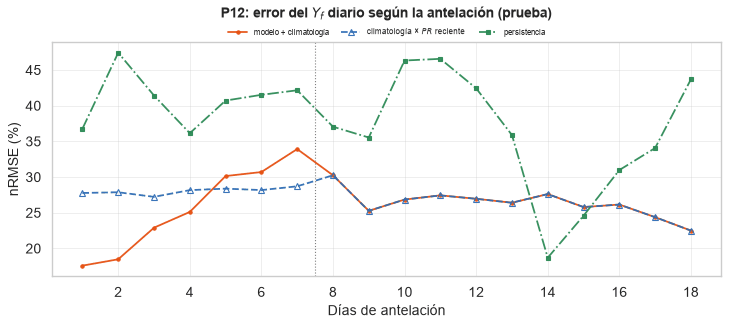

18 filas x 3 columnas; primeras 10:


,modelo + climatología,climatología × PR reciente,persistencia
h,,,
1,17.5953,27.7752,36.7702
2,18.4874,27.8748,47.4226
3,22.9109,27.2329,41.4270
4,25.1201,28.1733,36.1486
5,30.1461,28.3819,40.7207
6,30.7070,28.1811,41.5229
7,33.9246,28.7084,42.1609
8,30.2552,30.2552,37.0596
9,25.2721,25.2721,35.5443


**Total mensual emitido el último día del mes anterior** (solo días observados del mes)

,mes,dias_observados,observado,pronostico,climatologia,error_pct,error_climatologia_pct
0,2026-10,26,100.805,100.147,102.125,-0.653,1.309


**Observaciones.** En la prueba, con el pronóstico meteorológico (1 a 7 días) el nRMSE diario va de 17,6 % (1 día) a 33,9 % (7 días), frente a 28,0 % de la climatología en esos días; de 8 a 30 días el error se estabiliza en 26,3 %, el de la climatología, y la persistencia (el Yf del día de emisión) queda en 37,9 %. En la prueba, el intervalo de predicción del 80 % contiene el valor observado en el 77 % de los días de 1 a 7 y en el 43 % de los de 8 a 30 (lo esperado es 80 %; en la validación, con la que se calibró, 72 y 77 %). El total del mes se pronostica con un error de 0,7 % en promedio (climatología: 1,3 %), en 1 meses.

In [51]:
# Sección 9.4. Pronóstico diario a 30 días
if MODELABLE:
    from tfm.modelos import horizonte_30d as h30
    # Climatología del Yr diario en el plano de la unidad principal (ERA5 2015 a 2024)
    irr_era5_largo = aud.calibrar(caract.irradiancia_fuente({"om_archive__era5": era5_largo}, "era5", lugar), FACTOR_ERA5)
    YR_CLIM_LARGO = yr_diario(irr_era5_largo, inv0)
    # Control de escala: ERA5 y la fuente observada ya están al nivel de NSRDB (5.1), así que el cociente de su Yr en
    # los días del entrenamiento debería quedar cerca de 1; si no, la climatología se lleva a la escala del PR reciente
    YR_ERA5_MOD = yr_diario(FUENTES["era5"], inv0) if "era5" in FUENTES else pd.Series(dtype=float)
    CLIM_D, FACTOR_CLIM = h30.calibrar_climatologia(h30.climatologia_diaria(YR_CLIM_LARGO, ventana=15), yr_diario(irr_h, inv0),
                                                    YR_ERA5_MOD, hasta=config.PARTICIONES["entrenamiento"][1])
    display(Markdown(f"**Escala de la climatología.** Fuente observada del PR: **{FUENTE_IRR}**. Con ambas fuentes al nivel de NSRDB, "
                     f"su Yr diario en el entrenamiento es {FACTOR_CLIM:.3f} veces el de ERA5 en el plano de {n0}; la climatología se "
                     f"multiplica por ese factor residual para que el PR reciente y la climatología usen exactamente la misma escala."))
    kwp0 = kwp_de(n0)
    y_d0 = yd[n0]
    yr_d0 = OBJ_D[n0]["yr"].where(OBJ_D[n0]["en_regimen"]).asfreq("D")

    # Pronósticos del modelo de 1 a 7 días desde cada origen de la validación y la prueba
    dias_vt = pd.date_range(config.PARTICIONES["validacion"][0], config.PARTICIONES["prueba"][1], freq="D")
    origenes_vt = [d - pd.Timedelta(days=1) for d in dias_vt]

    def pred_h3(ajuste, origenes):
        pr_ = sarima.pronostico_por_origen(ajuste, y_d0, origenes, 7, H3_YF["exog"], exog_futuro=exog_lead)
        pr_["yhat"] = pr_["yhat"].clip(lower=0)
        sin_pron = [not np.isfinite(YR_LEAD[int(h)].get(t_, np.nan)) for h, t_ in zip(pr_["h"], pr_["t"])]
        pr_.loc[sin_pron, "yhat"] = np.nan                    # sin pronóstico meteorológico para ese día: climatología
        return pr_

    with tiempos.medir("H4 30 dias (modelo 1-7 d)", "prediccion_origenes", n0, origenes=len(origenes_vt)):
        P_FIJO = pred_h3(H3_YF["ajuste"], origenes_vt)
    ERR_H3 = h30.cuantiles_error(P_FIJO[P_FIJO["t"].isin(dias_val)], y_d0)
    # El PR, segundo objetivo, recibe el mismo tratamiento: su pronóstico de 1 a 7 días es el Yf del modelo dividido por el
    # Yr pronosticado, y su intervalo del 80 % sale del error de ese PR en la validación
    pr_d0 = OBJ_D[n0]["pr"].where(OBJ_D[n0]["en_regimen"]).asfreq("D")
    def pr_de(pred):
        yr_ = np.array([YR_LEAD[int(h)].get(t_, np.nan) for h, t_ in zip(pred["h"], pred["t"])], dtype=float)
        return pred.assign(yhat=pred["yhat"].to_numpy() / np.where(yr_ > 0, yr_, np.nan))
    ERR_PR_H3 = h30.cuantiles_error(pr_de(P_FIJO)[P_FIJO["t"].isin(dias_val)], pr_d0)
    PR_CLIM = h30.pr_climatologico(pr_d0, config.PARTICIONES["validacion"][0])     # solo el entrenamiento

    # Candidatos del valor central de 8 a 30 días (experimento X6b): persistencia de la anomalía reciente estimada con
    # la serie larga de ERA5 y climatología por fase del ONI. El ONI de un mes se publica unos dos meses después, así que
    # al emitir solo se conoce la fase de dos meses antes.
    BETA_ANOM = h30.pendiente_anomalia(YR_CLIM_LARGO)
    YR_OBS_D = yr_diario(irr_h, inv0)
    try:
        oni_ = datos.oni()
        ONI_MES = pd.Series(oni_["oni"].to_numpy(), index=pd.PeriodIndex([f"{a}-{m:02d}" for a, m in zip(oni_["anio"], oni_["mes"])], freq="M"))
    except Exception:  # noqa: BLE001 (sin el índice ONI cargado)
        ONI_MES = pd.Series(dtype=float)
    FASE_MES = pd.cut(ONI_MES, [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "neutro", "El Niño"]).astype(str) if len(ONI_MES) else pd.Series(dtype=str)
    CLIM_FASE = {f: c.assign(**{k: c[k] * FACTOR_CLIM for k in ("media", "p10", "p50", "p90")})
                 for f, c in h30.climatologia_por_fase(YR_CLIM_LARGO, FASE_MES).items()}
    fase_en = lambda o: FASE_MES.get(pd.Timestamp(o).to_period("M") - 2)

    def treinta_dias(pred_modelo, origenes, centro="media", bandas=None, bandas_pr=None):
        filas = []
        for o in origenes:
            pr30 = h30.pr_reciente(y_d0, yr_d0, o)
            g = pred_modelo[pred_modelo["origen"] == o]
            yr_p = {h: YR_LEAD[h].get(o + pd.Timedelta(days=h), np.nan) for h in range(1, 8)}
            filas.append(h30.pronosticar(o, CLIM_D, pr30, kwp0, g, yr_p, ERR_H3, centro=centro,
                                         anomalia=h30.anomalia_reciente(YR_OBS_D, CLIM_D, o), beta=BETA_ANOM,
                                         clim_fase=CLIM_FASE.get(fase_en(o)), bandas=bandas, errores_pr_h3=ERR_PR_H3,
                                         bandas_pr=bandas_pr, pr_clim=PR_CLIM))
        return pd.concat(filas)

    # Elección del valor central con los orígenes de la validación (la prueba solo confirma): el más simple del conjunto
    # de los que no se distinguen del mejor (MCS sobre el error medio de 8 a 30 días de cada origen)
    PRON30_C = treinta_dias(P_FIJO, origenes_vt)
    # La elección y la calibración solo ven días objetivo de la validación: un origen de agosto pronostica hasta 30 días
    # después, y esos días de septiembre son de la prueba. La prueba, a su vez, se evalúa solo en sus días (no después del corte)
    dias_pru = pd.date_range(*config.PARTICIONES["prueba"], freq="D")
    def en_periodo(p, dias):
        return p[p.index.isin(dias)]
    orig_val30 = [o for o in origenes_vt if (o + pd.Timedelta(days=1)) in set(dias_val)]
    VAL30 = en_periodo(PRON30_C[PRON30_C["origen"].isin(orig_val30)], dias_val)
    L30 = h30.perdidas_por_origen(VAL30, y_d0, [f"yf_{c}" for c in h30.CENTROS])
    MCS30 = met.conjunto_confianza(L30)
    MCS30["ecm_medio"] = L30.mean().reindex(MCS30.index)
    CENTRO_30 = next((c for c in h30.CENTROS if bool(MCS30.loc[f"yf_{c}", "incluido"])), "media")
    BANDAS_30 = h30.bandas_empiricas(VAL30, y_d0, f"yf_{CENTRO_30}")
    BANDAS_PR_30 = h30.bandas_empiricas(VAL30, pr_d0, "pr")
    display(Markdown("**Valor central de 8 a 30 días** (validación; error cuadrático medio por origen y conjunto de equivalentes al mejor)"))
    display(MCS30.round(4))
    display(Markdown(
        f"**Decisión.** La persistencia de la anomalía (beta, serie larga de ERA5) baja de {BETA_ANOM.get(1, np.nan):.2f} a un día a "
        f"{BETA_ANOM.get(8, np.nan):.2f} a 8 días y luego casi no cambia ({BETA_ANOM.get(15, np.nan):.2f} a 15 y {BETA_ANOM.get(30, np.nan):.2f} "
        f"a 30): la parte de la anomalía de un mes que persiste es de baja frecuencia (estacional o interanual), no el tiempo de "
        f"unos días. Se usa **{CENTRO_30}**, el más simple de los valores centrales que no se distinguen del mejor en "
        f"la validación. El intervalo de predicción del 80 % de 8 a 30 días se calibra con el error real de la validación: el valor observado queda entre "
        f"{BANDAS_30[0]:.2f} y {BANDAS_30[1]:.2f} veces el pronóstico en el 80 % de los días."))
    PRON30 = treinta_dias(P_FIJO, origenes_vt, CENTRO_30, BANDAS_30, BANDAS_PR_30)
    # Referencias: climatología pura y persistencia (Yf del día de emisión)
    PRON30["persistencia"] = y_d0.ffill().reindex(PRON30["origen"]).to_numpy()     # último día observado hasta el origen
    # Error por antelación en la prueba: orígenes desde el día anterior a la prueba y días objetivo dentro de ella
    PRUEBA30 = en_periodo(PRON30[~PRON30["origen"].isin(orig_val30)], dias_pru)
    EV30 = pd.concat({"modelo + climatología": h30.evaluar(PRUEBA30, y_d0)["nrmse_pct"],
                      "climatología × PR reciente": h30.evaluar(PRUEBA30, y_d0, "yf_climatologia")["nrmse_pct"],
                      "persistencia": h30.evaluar(PRUEBA30.dropna(subset=["persistencia"]), y_d0, "persistencia")["nrmse_pct"]}, axis=1)
    f = gr.lineas(EV30, f"{n0}: error del Yf diario según la antelación (prueba)", "Días de antelación", "nRMSE (%)")
    f.axes[0].axvline(7.5, color="grey", ls=":", lw=1)
    fig(f, f"h4_error_antelacion_{n0}", EV30)
    # gr.mostrar(PRON30, todas=True)   # todos los pronósticos (origen, día, antelación, método, intervalos)
    gr.guardar_datos(PRON30, f"{PREF}h4_pronosticos_30d_{n0}")
    cob_ = PRON30.assign(obs=y_d0.reindex(PRON30.index).to_numpy()).dropna(subset=["obs"])
    dentro_ = (cob_["obs"] >= cob_["yf_p10"]) & (cob_["obs"] <= cob_["yf_p90"])
    # La banda se calibro con la validación: la cobertura que cuenta es la de la prueba (cada una en los días de su periodo)
    es_prueba_ = ~cob_["origen"].isin(orig_val30) & cob_.index.isin(dias_pru)
    es_val_ = cob_["origen"].isin(orig_val30) & cob_.index.isin(dias_val)
    cobertura = dentro_[es_prueba_].groupby(cob_.loc[es_prueba_, "h"]).mean()
    cobertura_val = dentro_[es_val_].groupby(cob_.loc[es_val_, "h"]).mean()
    TOT_MES = h30.total_mensual(PRON30, y_d0)
    display(Markdown("**Total mensual emitido el último día del mes anterior** (solo días observados del mes)")); display(TOT_MES.round(3))
    display(Markdown(
        f"**Observaciones.** En la prueba, con el pronóstico meteorológico (1 a 7 días) el nRMSE diario va de {EV30.iloc[0, 0]:.1f} % (1 día) a "
        f"{EV30.iloc[6, 0]:.1f} % (7 días), frente a {EV30.iloc[:7, 1].mean():.1f} % de la climatología en esos días; de 8 a 30 "
        f"días el error se estabiliza en {EV30.iloc[7:, 0].mean():.1f} %, el de la climatología, y la persistencia (el Yf del día de emisión) queda en "
        f"{EV30.iloc[:, 2].mean():.1f} %. En la prueba, el intervalo de predicción del 80 % contiene el valor observado en el "
        f"{100 * cobertura.iloc[:7].mean():.0f} % de los días de 1 a 7 y en el {100 * cobertura.iloc[7:].mean():.0f} % de los de 8 a 30 "
        f"(lo esperado es 80 %; en la validación, con la que se calibró, {100 * cobertura_val.iloc[:7].mean():.0f} y "
        f"{100 * cobertura_val.iloc[7:].mean():.0f} %). "
        + (f"El total del mes se pronostica con un error de {TOT_MES['error_pct'].abs().mean():.1f} % en promedio "
           f"(climatología: {TOT_MES['error_climatologia_pct'].abs().mean():.1f} %), en {len(TOT_MES)} meses." if len(TOT_MES) else "")))
    EV30_CLAVES = EV30.rename(columns={"modelo + climatología": "modelo_y_climatologia",
                                       "climatología × PR reciente": "climatologia_por_PR_reciente"})   # claves sin tildes
    res.registrar(f"localidades.{GRUPO}.modelos.h4_30d_{n0}", {"nrmse_pct_por_antelacion": EV30_CLAVES.round(3).to_dict(orient="index"),
                  "cobertura_banda_80": cobertura.round(3).to_dict(), "cobertura_banda_80_validacion": cobertura_val.round(3).to_dict(),
                  "total_mensual": TOT_MES.round(4).to_dict(orient="records"),
                  "factor_climatologia": round(FACTOR_CLIM, 4), "fuente_pr": FUENTE_IRR, "centro": CENTRO_30,
                  "bandas_8_30": [round(b, 4) for b in BANDAS_30], "beta_anomalia": BETA_ANOM.round(4).to_dict(),
                  "mcs_centro": MCS30.round(5).replace({np.nan: None}).to_dict(orient="index")})

**Experimento: ¿cada cuánto reentrenar el modelo de 1 a 7 días?** En la prueba se
comparan tres políticas con el mismo orden del modelo: coeficientes fijos estimados con el entrenamiento
(hasta el 31 de mayo), reestimados cada 30 días y cada 7 días con todos los datos observados hasta el día
anterior al bloque. En los tres casos el pronóstico se emite cada día; solo cambia cuándo se actualizan los
coeficientes. Como en producción, un reajuste inestable (una raíz autorregresiva dentro del círculo unidad o
pronósticos de más del triple del máximo observado) no reemplaza a los coeficientes vigentes. Se mide el
nRMSE por antelación y el tiempo de cómputo.

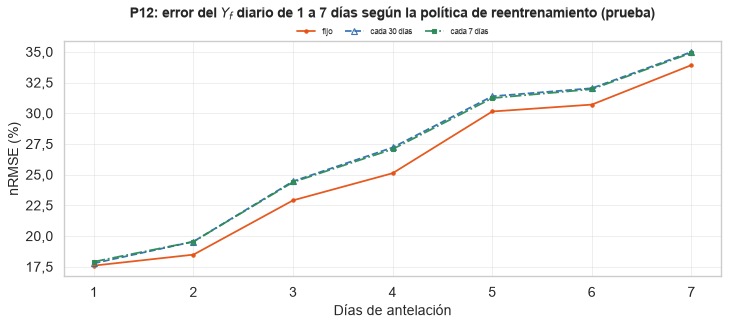

7 filas x 3 columnas; primeras 7:


,fijo,cada 30 días,cada 7 días
h,,,
1,17.5953,17.7802,17.9115
2,18.4874,19.5492,19.5503
3,22.9109,24.4625,24.3955
4,25.1201,27.2149,27.0800
5,30.1461,31.3861,31.2366
6,30.7070,32.0383,31.9604
7,33.9246,34.9972,34.9204


**Resultado.** nRMSE medio de 1 a 7 días en la prueba: fijo 25,6 %, cada 30 días 26,8 %, cada 7 días 26,7 %. **Conclusión.** Los coeficientes fijos dan el menor error: en esta prueba, reestimarlos con los meses más recientes no ayuda (el pronóstico se sigue reemitiendo cada día con datos nuevos). El reentrenamiento mensual queda como mantenimiento, para recoger cambios de capacidad o de estación que el entrenamiento no cubría.

In [52]:
# Sección 9.4. Pronóstico diario a 30 días
if MODELABLE:
    dias_p = pd.date_range(*config.PARTICIONES["prueba"], freq="D")
    orig_p = [d - pd.Timedelta(days=1) for d in dias_p]
    POLITICAS = {"fijo": P_FIJO[P_FIJO["origen"].isin(orig_p)]}
    DESCARTADOS = {}
    for cada in (30, 7):
        bloques, t_aj, vigente, descartados = [], 0.0, H3_YF["ajuste"], 0
        for i in range(0, len(orig_p), cada):
            lote = orig_p[i:i + cada]
            hasta = lote[0]                                   # datos observados hasta el día de emisión del bloque
            ym = y_d0.loc[:hasta]
            import time as _t; t0_ = _t.perf_counter()
            a_m = sarima.ajustar(ym, H3_YF["orden"], exog=H3_YF["exog"].loc[ym.index])
            t_aj += _t.perf_counter() - t0_
            p_m = pred_h3(a_m, lote)
            # Como en producción (src/41_reentrenamiento.py): un reajuste inestable o con pronósticos imposibles
            # no reemplaza a los coeficientes vigentes
            yh = p_m["yhat"].to_numpy(dtype=float)
            yh = yh[np.isfinite(yh)]                          # el bloque puede no tener pronósticos meteorológicos
            if sarima.estable(a_m) and (yh.size == 0 or np.abs(yh).max() <= 3 * np.nanmax(ym)):
                vigente = a_m
                bloques.append(p_m)
            else:
                descartados += 1
                bloques.append(pred_h3(vigente, lote))
        POLITICAS[f"cada {cada} días"] = pd.concat(bloques)
        DESCARTADOS[f"cada_{cada}_dias"] = descartados
        tiempos.registrar_costo("H3 SARIMAX diario", f"reentrenamiento cada {cada} dias", t_aj, n0, ajustes=len(range(0, len(orig_p), cada)))
    # Solo los días objetivo de la prueba: los últimos orígenes pronostican días posteriores al corte
    EV_RE = pd.concat({k: pd.DataFrame([{"h": h, **met.evaluar(y_d0.reindex(g["t"]), g.set_index("t")["yhat"])}
                                        for h, g in v[v["t"].isin(dias_p)].dropna(subset=["yhat"]).groupby("h")]).set_index("h")["nrmse_pct"]
                       for k, v in POLITICAS.items()}, axis=1)
    fig(gr.lineas(EV_RE, f"{n0}: error del Yf diario de 1 a 7 días según la política de reentrenamiento (prueba)",
                  "Días de antelación", "nRMSE (%)"), f"h4_reentrenamiento_{n0}", EV_RE)
    mejor_pol = EV_RE.mean().idxmin()
    display(Markdown(
        f"**Resultado.** nRMSE medio de 1 a 7 días en la prueba: " + ", ".join(f"{k} {v:.1f} %" for k, v in EV_RE.mean().items())
        + f". **Conclusión.** " + ("Reestimar los coeficientes no mejora el pronóstico de forma apreciable (menos de medio punto): "
           "con la memoria corta de la serie diaria, basta con reemitir el pronóstico cada día con los coeficientes vigentes, y el "
           "reentrenamiento mensual queda como mantenimiento." if EV_RE.mean().max() - EV_RE.mean().min() < 0.5 else
           ("Los coeficientes fijos dan el menor error: en esta prueba, reestimarlos con los meses más recientes no ayuda (el "
            "pronóstico se sigue reemitiendo cada día con datos nuevos). El reentrenamiento mensual queda como mantenimiento, para "
            "recoger cambios de capacidad o de estación que el entrenamiento no cubría." if mejor_pol == "fijo" else
            f"La política **{mejor_pol}** da el menor error; se adopta como frecuencia de reentrenamiento en producción "
            f"(variable REENTRENAR_CADA_X_DIAS de tfm/config.py)."))))
    EV_RE_CLAVES = EV_RE.rename(columns=lambda c: c.replace(" días", "_dias").replace(" ", "_"))   # claves sin tildes
    res.registrar(f"localidades.{GRUPO}.modelos.h4_reentrenamiento_{n0}", {"nrmse_pct_medio": EV_RE_CLAVES.mean().round(3).to_dict(),
                  "por_antelacion": EV_RE_CLAVES.round(3).to_dict(orient="index"), "reajustes_descartados": DESCARTADOS})
    if any(DESCARTADOS.values()):
        display(Markdown("**Reajustes descartados por inestables** (se conservaron los coeficientes vigentes): "
                         + ", ".join(f"{k.replace('_', ' ')}: {v}" for k, v in DESCARTADOS.items())))

Mostramos el pronóstico de dos maneras. La primera es una ventana móvil con los 30 días siguientes a un día de emisión,
con lo observado superpuesto cuando ya ocurrió. La segunda es el mes en curso, con el pronóstico emitido en el corte del
modelado (`config.FIN_MODELADO`, con los modelos y los datos que existían ese día) frente a lo que ocurrió después. Cada
día muestra hasta tres barras, que son lo observado, el pronóstico de 1 a 7 días (el modelo con el pronóstico
meteorológico) y el pronóstico a 30 días (el valor central climatológico por el PR reciente), cada pronóstico con su
intervalo del 80 %. Lo observado sale del contador de energía del inversor hasta el día anterior a
`config.FIN_OBSERVADO` (por defecto, hoy), y los días posteriores a la emisión son datos que el modelo no vio. Solo los
días anteriores a la emisión sin ningún dato se estiman con el Yr de la fuente observada por el PR reciente (rayados).
Con `mostrar_pr` igual a `False` se quita el panel del PR, y el eje derecho expresa la misma barra en kWh (Yf × kWp del
inversor).

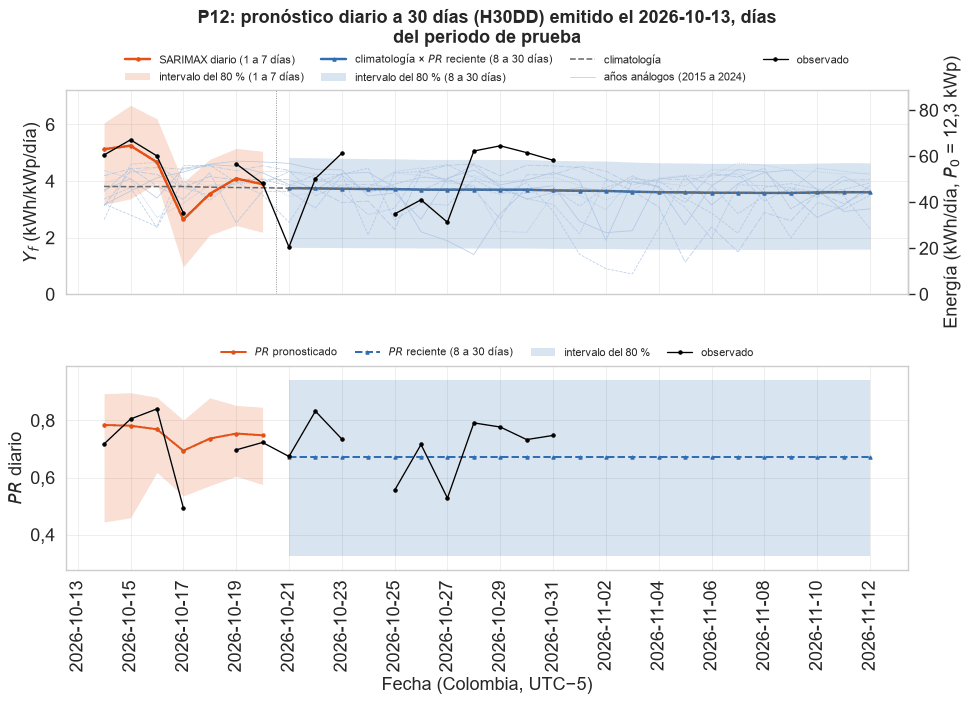

30 filas x 22 columnas; primeras 10:


,h,metodo,yf,yf_p10,yf_p90,pr,pr_p10,pr_p90,yf_climatologia,yf_media,yf_mediana,yf_anomalia,yf_fase_oni,pr_climatologia,energia_kwh,energia_kwh_p10,energia_kwh_p90,energia_kwh_climatologia,origen,persistencia,observado,pr_observado
dia,,,,,,,,,,,,,,,,,,,,,,
2026-10-14,1,modelo,5.1242,3.1656,6.0560,0.7840,0.4443,0.8935,3.8091,3.8091,3.9331,3.8229,3.8679,NaN,63.0271,38.9370,74.4886,46.8520,2026-10-13,2.6658,4.9220,0.7176
2026-10-15,2,modelo,5.2497,3.3740,6.6754,0.7813,0.4592,0.8971,3.8004,3.8004,3.9258,3.8098,3.8511,NaN,64.5711,41.4999,82.1079,46.7454,2026-10-13,2.6658,5.4577,0.8048
2026-10-16,3,modelo,4.6647,3.9294,6.2015,0.7690,0.6179,0.8810,3.8053,3.8053,3.9162,3.8137,3.8389,NaN,57.3756,48.3322,76.2789,46.8054,2026-10-13,2.6658,4.8884,0.8402
2026-10-17,4,modelo,2.6415,0.9668,3.9476,0.6938,0.5356,0.8010,3.8063,3.8063,3.9367,3.8143,3.8357,NaN,32.4899,11.8912,48.5550,46.8180,2026-10-13,2.6658,2.8690,0.4941
2026-10-18,5,modelo,3.5456,2.0894,4.7669,0.7361,0.5714,0.8791,3.7828,3.7828,3.9100,3.7905,3.8149,NaN,43.6104,25.6992,58.6334,46.5287,2026-10-13,2.6658,NaN,NaN
2026-10-19,6,modelo,4.0893,2.4281,5.1536,0.7540,0.6045,0.8527,3.7705,3.7705,3.8937,3.7775,3.7932,NaN,50.2978,29.8654,63.3896,46.3768,2026-10-13,2.6658,4.6113,0.6968
2026-10-20,7,modelo,3.8899,2.1893,5.0519,0.7479,0.5756,0.8462,3.7632,3.7632,3.8980,3.7697,3.8047,NaN,47.8454,26.9288,62.1385,46.2871,2026-10-13,2.6658,3.9144,0.7228
2026-10-21,8,climatologia,3.7474,1.6566,4.8307,0.6729,0.3267,0.9410,3.7474,3.7474,3.8902,3.7534,3.7853,NaN,46.0933,20.3756,59.4170,46.0933,2026-10-13,2.6658,1.6672,0.6737
2026-10-22,9,climatologia,3.7408,1.6536,4.8222,0.6729,0.3267,0.9410,3.7408,3.7408,3.8883,3.7465,3.7741,NaN,46.0123,20.3398,59.3126,46.0123,2026-10-13,2.6658,4.0892,0.8324


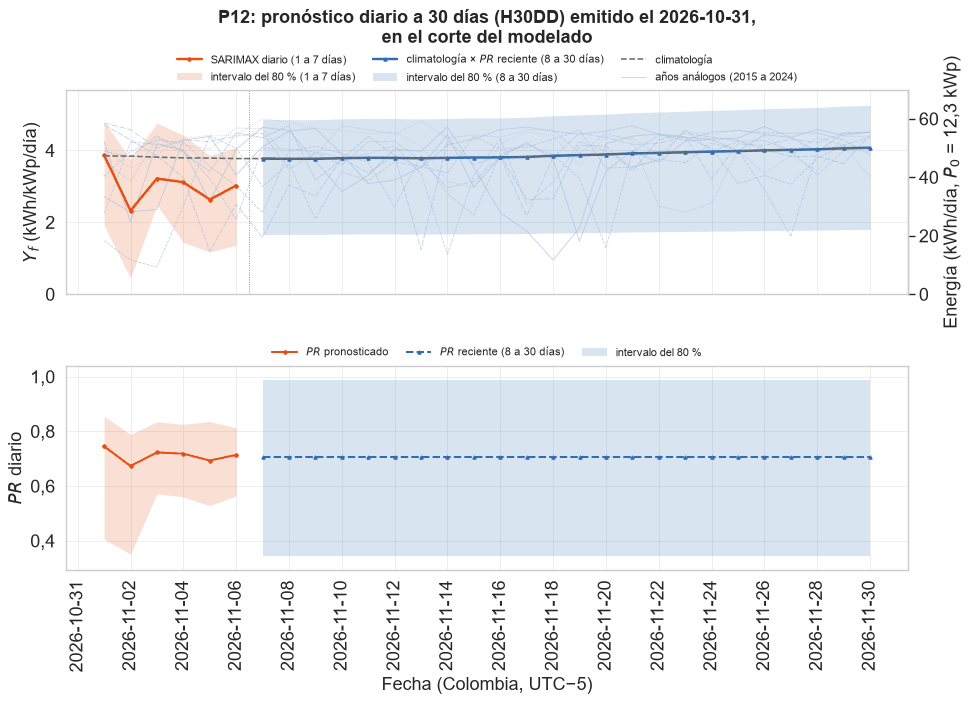

30 filas x 19 columnas; primeras 10:


,h,metodo,yf,yf_p10,yf_p90,pr,pr_p10,pr_p90,yf_climatologia,yf_media,yf_mediana,yf_anomalia,yf_fase_oni,pr_climatologia,energia_kwh,energia_kwh_p10,energia_kwh_p90,energia_kwh_climatologia,origen
dia,,,,,,,,,,,,,,,,,,,
2026-11-01,1,modelo,3.8664,1.9079,4.7983,0.7453,0.4056,0.8547,3.8467,3.8467,4.0332,3.8279,3.9548,NaN,47.5569,23.4669,59.0185,47.3148,2026-10-31
2026-11-02,2,modelo,2.3255,0.4498,3.7513,0.6732,0.3510,0.7889,3.8397,3.8397,4.0340,3.8268,3.9394,NaN,28.6040,5.5328,46.1408,47.2280,2026-10-31
2026-11-03,3,modelo,3.2169,2.4817,4.7538,0.7230,0.5718,0.8349,3.8110,3.8110,4.0301,3.7996,3.9031,NaN,39.5682,30.5247,58.4715,46.8755,2026-10-31
2026-11-04,4,modelo,3.1148,1.4401,4.4209,0.7184,0.5602,0.8256,3.7912,3.7912,4.0205,3.7805,3.8619,NaN,38.3124,17.7137,54.3775,46.6315,2026-10-31
2026-11-05,5,modelo,2.6326,1.1764,3.8539,0.6933,0.5286,0.8362,3.7843,3.7843,4.0124,3.7739,3.8546,NaN,32.3804,14.4692,47.4033,46.5472,2026-10-31
2026-11-06,6,modelo,3.0197,1.3586,4.0841,0.7140,0.5644,0.8126,3.7719,3.7719,3.9884,3.7624,3.8627,NaN,37.1428,16.7104,50.2346,46.3943,2026-10-31
2026-11-07,7,climatologia,3.7711,1.6670,4.8612,0.7077,0.3435,0.9895,3.7711,3.7711,3.9884,3.7623,3.8703,NaN,46.3845,20.5044,59.7924,46.3845,2026-10-31
2026-11-08,8,climatologia,3.7650,1.6643,4.8533,0.7077,0.3435,0.9895,3.7650,3.7650,3.9791,3.7568,3.8673,NaN,46.3094,20.4712,59.6955,46.3094,2026-10-31
2026-11-09,9,climatologia,3.7657,1.6646,4.8542,0.7077,0.3435,0.9895,3.7657,3.7657,4.0020,3.7580,3.8813,NaN,46.3182,20.4751,59.7070,46.3182,2026-10-31


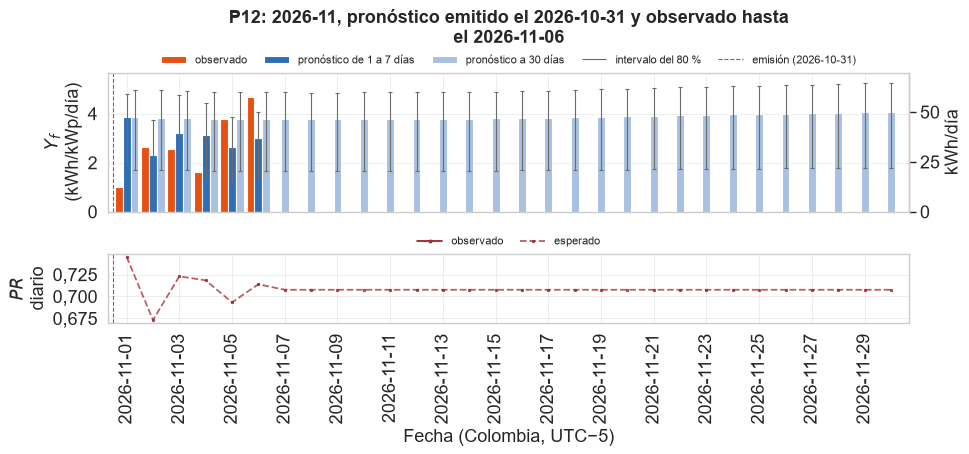

30 filas x 8 columnas; primeras 10:


,observado_contador,estimado_sin_datos,pronostico_1a7,p10_1a7,p90_1a7,pronostico_30,p10_30,p90_30
2026-11-01,1.0081,NaN,3.8664,1.9079,4.7983,3.8467,1.7005,4.9587
2026-11-02,2.6504,NaN,2.3255,0.4498,3.7513,3.8397,1.6973,4.9496
2026-11-03,2.5772,NaN,3.2169,2.4817,4.7538,3.8110,1.6847,4.9126
2026-11-04,1.6179,NaN,3.1148,1.4401,4.4209,3.7912,1.6759,4.8871
2026-11-05,3.7886,NaN,2.6326,1.1764,3.8539,3.7843,1.6729,4.8782
2026-11-06,4.6667,NaN,3.0197,1.3586,4.0841,3.7719,1.6674,4.8622
2026-11-07,NaN,NaN,NaN,NaN,NaN,3.7711,1.6670,4.8612
2026-11-08,NaN,NaN,NaN,NaN,NaN,3.7650,1.6643,4.8533
2026-11-09,NaN,NaN,NaN,NaN,NaN,3.7657,1.6646,4.8542
2026-11-10,NaN,NaN,NaN,NaN,NaN,3.7819,1.6718,4.8750


**2026-11:** pronóstico emitido el 2026-10-31. En los 6 días posteriores ya observados, el error absoluto medio es de 1,35 kWh/kWp con el pronóstico de 1 a 7 días (6 días) y de 1,39 kWh/kWp con el de 30 días. Total esperado del mes: 111,3 kWh/kWp (1370 kWh), frente a 116,0 kWh/kWp de la climatología.

In [53]:
# Sección 9.4. Pronóstico diario a 30 días
if MODELABLE:
    MOSTRAR_PR = True
    o_ej = pd.Timestamp(config.PARTICIONES["prueba"][0]) - pd.Timedelta(days=1)          # emitido la vispera del primer día de la prueba
    t_ej = PRON30[PRON30["origen"] == o_ej]
    esc_ej = h30.escenarios_analogos(o_ej, YR_CLIM_LARGO * FACTOR_CLIM, h30.pr_reciente(y_d0, yr_d0, o_ej))
    fig(gr.pronostico_30d(t_ej, y_d0, f"{n0}: pronóstico diario a 30 días (H30DD) emitido el {o_ej:%Y-%m-%d}, días del periodo de prueba", kwp0, MOSTRAR_PR,
                          escenarios=esc_ej, pr_observado=pr_d0),
        f"h4_ventana_prueba_{n0}", t_ej.assign(observado=y_d0.reindex(t_ej.index).to_numpy(), pr_observado=pr_d0.reindex(t_ej.index).to_numpy()))

    # Emisión en el corte del modelado (el último día anterior al corte, como la habría hecho la operación esa noche) y vista
    # del mes siguiente: lo observado después del corte son datos que el modelo no vio. Si los datos terminan antes, se emite
    # el último día procesado (aunque no tenga Yf válido por fallas o huecos)
    ultimo_dia_ = pd.Timestamp(part.dias_locales(OBJ_H[n0].index[OBJ_H[n0]["e_kwh"].notna().to_numpy()]).max())
    o_vivo = min(ultimo_dia_ - pd.Timedelta(days=1), pd.Timestamp(config.FIN_MODELADO) - pd.Timedelta(days=1))
    # La emisión en vivo pronostica más allá del último día con datos: la serie se extiende con días vacios y la exógena con
    # el Yr pronosticado de cada antelación (como en la operación); sin pronóstico meteorológico, el día pasa a la climatología
    ventana_vivo = pd.date_range(o_vivo + pd.Timedelta(days=1), periods=7, freq="D")
    fut_vivo = ventana_vivo[ventana_vivo > y_d0.index[-1]]
    y_ext = pd.concat([y_d0, pd.Series(np.nan, index=fut_vivo)]).asfreq("D")
    # La exógena de los días ya pasados es la del ajuste (el Yr pronosticado con un día de antelación). Si el último día
    # completo de la serie queda antes del origen (días finales incompletos por fallas o sin producción), los días
    # intermedios también la necesitan: el SARIMAX no admite exógenas faltantes aunque el Yf de esos días falte
    x_ext = YR_LEAD[1].reindex(y_ext.index).ffill().fillna(0).to_frame("yr")
    x_ext.loc[fut_vivo, "yr"] = exog_lead(o_vivo, ventana_vivo).loc[fut_vivo, "yr"].to_numpy()
    P_VIVO = sarima.pronostico_por_origen(H3_YF["ajuste"], y_ext, [o_vivo], 7, x_ext, exog_futuro=exog_lead)
    P_VIVO["yhat"] = P_VIVO["yhat"].clip(lower=0)
    P_VIVO.loc[[not np.isfinite(YR_LEAD[int(h)].get(t_, np.nan)) for h, t_ in zip(P_VIVO["h"], P_VIVO["t"])], "yhat"] = np.nan
    t_vivo = treinta_dias(P_VIVO, [o_vivo], CENTRO_30, BANDAS_30, BANDAS_PR_30)
    esc_vivo = h30.escenarios_analogos(o_vivo, YR_CLIM_LARGO * FACTOR_CLIM, h30.pr_reciente(y_d0, yr_d0, o_vivo))
    fig(gr.pronostico_30d(t_vivo, None, f"{n0}: pronóstico diario a 30 días (H30DD) emitido el {o_vivo:%Y-%m-%d}, en el corte del modelado", kwp0, MOSTRAR_PR,
                          escenarios=esc_vivo),
        f"h4_ventana_vivo_{n0}", t_vivo)
    mes = (o_vivo + pd.Timedelta(days=1)).to_period("M")
    dias_mes = pd.date_range(mes.start_time, mes.end_time.normalize(), freq="D")
    pr_vivo = h30.pr_reciente(y_d0, yr_d0, o_vivo)
    clim_mes = pd.Series([pr_vivo * CLIM_D.loc[d.dayofyear, "media"] for d in dias_mes], index=dias_mes)
    # Lo observado del mes sale del contador de energía del inversor (solo lectura), hasta el día anterior a FIN_OBSERVADO:
    # los días posteriores a la emisión son datos que el modelo no vio
    fin_obs = pd.Timestamp(config.FIN_OBSERVADO or pd.Timestamp.now(tz=config.ZONA).strftime("%Y-%m-%d"))
    uuids_n0 = (list(INV.loc[[c for c in INV.index if c.startswith(n0 + "I")], "deviceuuid"]) if nom.es_planta(n0)
                else [INV.loc[n0, "deviceuuid"]])
    obs_mes = (datos.energia_diaria_contador(uuids_n0, dias_mes[0], min(fin_obs, dias_mes[-1] + pd.Timedelta(days=1)))
               / kwp0).reindex(dias_mes)
    # Días anteriores a la emisión sin ningún dato: la planta pudo producir aunque el dato no llegara. Se estiman con el Yr
    # de la fuente observada por el PR reciente (o con la climatología si tampoco hay Yr) y se dibujan rayados
    pasado_sin_dato = (dias_mes <= o_vivo) & obs_mes.isna()
    est_mes = (pr_vivo * yr_diario(irr_h, inv0).reindex(dias_mes)).fillna(clim_mes).where(pasado_sin_dato)
    P7_VIVO = t_vivo.loc[t_vivo["metodo"] == "modelo", ["yf", "yf_p10", "yf_p90"]]
    c30_ = t_vivo[f"yf_{CENTRO_30}"]
    P30_VIVO = pd.DataFrame({"yf": c30_, "yf_p10": c30_ * BANDAS_30[0], "yf_p90": c30_ * BANDAS_30[1]})
    fig(gr.mes_en_curso(obs_mes, P7_VIVO, P30_VIVO, o_vivo,
                        f"{n0}: {mes}, pronóstico emitido el {o_vivo:%Y-%m-%d} y observado hasta el {fin_obs - pd.Timedelta(days=1):%Y-%m-%d}",
                        kwp0, MOSTRAR_PR, prd[n0].reindex(dias_mes), t_vivo["pr"], estimado=est_mes, dias=dias_mes),
        f"h4_mes_en_curso_{n0}",
        pd.DataFrame({"observado_contador": obs_mes, "estimado_sin_datos": est_mes,
                      "pronostico_1a7": P7_VIVO["yf"].reindex(dias_mes), "p10_1a7": P7_VIVO["yf_p10"].reindex(dias_mes),
                      "p90_1a7": P7_VIVO["yf_p90"].reindex(dias_mes), "pronostico_30": P30_VIVO["yf"].reindex(dias_mes),
                      "p10_30": P30_VIVO["yf_p10"].reindex(dias_mes), "p90_30": P30_VIVO["yf_p90"].reindex(dias_mes)}))
    desp = dias_mes > o_vivo
    comp = pd.DataFrame({"obs": obs_mes, "p7": P7_VIVO["yf"].reindex(dias_mes),
                         "p30": P30_VIVO["yf"].reindex(dias_mes)})[desp].dropna(subset=["obs"])
    total_esp = obs_mes.where(~desp).sum() + est_mes.sum() + t_vivo["yf"].reindex(dias_mes[desp]).sum()
    comp7 = comp.dropna(subset=["p7"])              # el de 1 a 7 días falta si no hubo pronóstico meteorológico ese día
    dias_comp = "el día posterior ya observado" if len(comp) == 1 else f"los {len(comp)} días posteriores ya observados"
    display(Markdown(
        f"**{mes}:** pronóstico emitido el {o_vivo:%Y-%m-%d}. "
        + (f"En {dias_comp}, el error absoluto medio es de "
           + (f"{(comp7['p7'] - comp7['obs']).abs().mean():.2f} kWh/kWp con el pronóstico de 1 a 7 días ({len(comp7)} días) y de "
              if len(comp7) else "")
           + f"{(comp['p30'] - comp['obs']).abs().mean():.2f} kWh/kWp con el de 30 días. " if len(comp) else
           "Todavía no hay días observados después de la emisión. ")
        + f"Total esperado del mes: {total_esp:.1f} kWh/kWp ({total_esp * kwp0:.0f} kWh), frente a {clim_mes.sum():.1f} kWh/kWp "
        f"de la climatología."))

## 10. Aprendizaje automático

*Base en el máster.* KNN, árbol de decisión, conjuntos de modelos y la búsqueda de hiperparámetros adaptan los ejemplos de regresión de Machine Learning (aprendizaje supervisado y optimización de hiperparámetros) a un problema temporal: la validación cruzada es por bloques consecutivos y nunca se baraja.

Se sigue un proceso estándar de ajuste (Bergstra y Bengio, 2012), con el objetivo horario Yf del día siguiente
(H01DH) y los conjuntos de variables elegidos en la sección 6 para cada escenario (E0 sin exógenas, E1
observadas, E2 pronosticadas):

1. **Modelos base** con los hiperparámetros por defecto: KNN, árbol de decisión (DT), bosque aleatorio
   (RF), gradient boosting histogramático (HGB), SVR y LightGBM (Ke et al., 2017).
2. **Búsqueda aleatoria** (15 combinaciones) con validación cruzada temporal de 4 pliegues
   (TimeSeriesSplit): cada pliegue entrena con el pasado y valida con el bloque siguiente, nunca al revés.
3. **Búsqueda en rejilla** alrededor del mejor punto, sobre los dos hiperparámetros más influyentes de
   cada modelo; se queda con la rejilla solo si mejora el MAE de la validación cruzada.
4. **Ensamble** (ENS) por votación de los tres mejores modelos según el MAE de la validación cruzada.
5. **Evaluación** del pronóstico del día siguiente en la validación, en horas de sol
   observadas; de noche el pronóstico es 0.

Se entrena con las horas de sol observadas del entrenamiento. La imputación (mediana) y el escalado
(solo KNN y SVR) están dentro del *pipeline*, así que en cada pliegue se ajustan solo con su parte de
entrenamiento: no hay fuga de información.

### 10.1. Modelos base, búsqueda de hiperparámetros y escenarios

In [54]:
# Sección 10.1. Modelos base, búsqueda de hiperparámetros y escenarios
if MODELABLE:
    from tfm.modelos import ml
    def datos_ml(n, inv, esc):
        X, y = candidatas(n, inv, "E1" if esc == "E0" else esc)
        cols = [c for c in SEL[esc] if c in X.columns]
        m = mascara_modelado(n)
        etq = part.etiquetar(X.index).to_numpy()
        return X[cols], y, m & (etq == "entrenamiento"), m & (etq == "validacion"), etq

    AJ_ML, TABLA_J, PRED_ML = {}, [], {}
    MODELOS_J = list(ml.MODELOS) if not RAPIDO else ["DT", "RF", "LGBM"]
    for esc in ("E0", "E1", "E2"):
        X, y, tr, va, etq = datos_ml(n0, inv0, esc)
        for nombre in MODELOS_J:
            a = ml.ajustar(nombre, X[tr], y[tr], n_iter=15 if not RAPIDO else 2, pliegues=4 if not RAPIDO else 2, rejilla=not RAPIDO)
            AJ_ML[(esc, nombre)] = a
            tiempos.registrar_costo(f"ML {nombre} {esc}", "busqueda_hiperparametros", a["segundos"], n0, filas=int(tr.sum()))
            for etapa, est_ in (("base", a["base"]), ("ajustado", a["mejor"])):
                p_ = pd.Series(np.clip(est_.predict(X[va]), 0, None), index=X.index[va])
                TABLA_J.append({"escenario": esc, "modelo": nombre, "etapa": etapa, "segundos": a["segundos"],
                                "mae_cv": a.get("mae_cv_rejilla", a["mae_cv_aleatoria"]) if etapa == "ajustado" else np.nan,
                                **met.evaluar(y[va], p_)})
                if etapa == "ajustado":
                    PRED_ML[(esc, nombre)] = p_
        # Ensamble de los tres mejores por MAE de validación cruzada
        top = sorted(MODELOS_J, key=lambda k: AJ_ML[(esc, k)].get("mae_cv_rejilla", AJ_ML[(esc, k)]["mae_cv_aleatoria"]))[:3]
        ens = ml.ensamble({k: AJ_ML[(esc, k)]["mejor"] for k in top}).fit(X[tr], y[tr])
        p_ = pd.Series(np.clip(ens.predict(X[va]), 0, None), index=X.index[va])
        PRED_ML[(esc, "ENS")] = p_
        AJ_ML[(esc, "ENS")] = {"mejor": ens, "componentes": top}
        TABLA_J.append({"escenario": esc, "modelo": "ENS", "etapa": "ajustado", **met.evaluar(y[va], p_)})
    TABLA_J = pd.DataFrame(TABLA_J)
    rmse_cliper_val = met.evaluar(y0.reindex(PRED_ML[("E2", "ENS")].index), REF_H["cliper"].reindex(PRED_ML[("E2", "ENS")].index),
                                  observado(OBJ_H[n0]).reindex(PRED_ML[("E2", "ENS")].index))["rmse"]
    TABLA_J["skill_vs_cliper"] = 1 - TABLA_J["rmse"] / rmse_cliper_val
    display(Markdown(f"**{n0}: modelos de aprendizaje automático, pronóstico del día siguiente (validación, horas de sol observadas)**"))
    display(TABLA_J.pivot_table(index=["modelo", "etapa"], columns="escenario", values="nrmse_pct").round(1))
    display(Markdown("**Hiperparámetros elegidos (escenario E2)**"))
    display(pd.DataFrame({k: AJ_ML[("E2", k)]["parametros"] for k in MODELOS_J}.items(), columns=["modelo", "parametros"]))

**P12: modelos de aprendizaje automático, pronóstico del día siguiente (validación, horas de sol observadas)**

escenario          E0    E1    E2
modelo etapa                     
DT     ajustado  54.2  46.7  49.2
       base      75.5  57.4  58.7
ENS    ajustado  57.1  42.7  46.9
HGB    ajustado  58.3  42.6  47.0
       base      62.5  43.6  49.3
KNN    ajustado  56.9  46.0  50.5
       base      59.5  47.8  52.4
LGBM   ajustado  54.3  41.6  48.7
       base      61.3  43.7  48.3
RF     ajustado  56.8  42.6  46.6
       base      56.8  43.3  47.3
SVR    ajustado  60.5  41.9  52.0
       base      62.0  45.6  52.7

**Hiperparámetros elegidos (escenario E2)**

,modelo,parametros
0,KNN,"{'modelo__n_neighbors': 11, 'modelo__p': 1, 'm..."
1,DT,"{'modelo__max_depth': 8, 'modelo__min_samples_..."
2,RF,"{'modelo__max_depth': 12, 'modelo__max_feature..."
3,HGB,{'modelo__l2_regularization': 0.20221446157015...
4,SVR,"{'modelo__C': 0.2043208398464712, 'modelo__eps..."
5,LGBM,{'modelo__colsample_bytree': 0.502641994370018...


AVISO: quedan 0.6 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


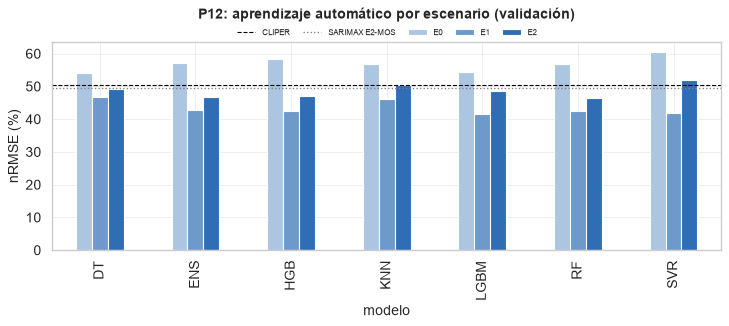

7 filas x 3 columnas; primeras 7:


escenario,E0,E1,E2
modelo,,,
DT,54.2345,46.6511,49.2209
ENS,57.1210,42.6657,46.9142
HGB,58.3470,42.6114,47.0224
KNN,56.9379,46.0263,50.5274
LGBM,54.3445,41.5571,48.6777
RF,56.7912,42.6202,46.5788
SVR,60.5370,41.9286,51.9881


**Observaciones.** En E2 (pronóstico real a un día) el mejor modelo es **RF** con 46,6 % de nRMSE, frente a 49,6 % del SARIMAX E2-MOS y 50,6 % de CLIPER. Sin exógenas (E0) el mejor queda en 54,2 % y con el tiempo observado (E1) en 41,6 %: la distancia entre E1 y E2 es lo que cuesta el error del pronóstico meteorológico, y la distancia entre E0 y E2 es lo que aporta usarlo.

In [55]:
# Sección 10.1. Modelos base, búsqueda de hiperparámetros y escenarios
if MODELABLE:
    aj = TABLA_J[TABLA_J["etapa"] == "ajustado"].pivot_table(index="modelo", columns="escenario", values="nrmse_pct")
    f, ax = plt.subplots(figsize=(9, 4))
    aj.plot.bar(ax=ax, color=gr.tonos(config.COLOR_SECUNDARIO, 3, 0.6))     # tres escenarios: un tono, tres intensidades
    ax.axhline(TABLA_I.set_index("modelo").loc["ref: cliper", "nrmse_pct"], color="black", ls="--", lw=1, label="CLIPER")
    ax.axhline(TABLA_I.set_index("modelo").loc["SARIMAX E2-MOS", "nrmse_pct"], color="grey", ls=":", lw=1.2, label="SARIMAX E2-MOS")
    ax.set_ylabel("nRMSE (%)"); ax.set_title(f"{n0}: aprendizaje automático por escenario (validación)"); ax.legend(fontsize=8)
    fig(f, f"ml_escenarios_{n0}", aj)
    # gr.mostrar(TABLA_J, todas=True)   # todas las métricas por modelo, etapa y escenario
    mejor_e2 = aj["E2"].idxmin()
    display(Markdown(
        f"**Observaciones.** En E2 (pronóstico real a un día) el mejor modelo es **{mejor_e2}** con {aj.loc[mejor_e2, 'E2']:.1f} % de nRMSE, "
        f"frente a {TABLA_I.set_index('modelo').loc['SARIMAX E2-MOS', 'nrmse_pct']:.1f} % del SARIMAX E2-MOS y "
        f"{TABLA_I.set_index('modelo').loc['ref: cliper', 'nrmse_pct']:.1f} % de CLIPER. Sin exógenas (E0) el mejor queda en "
        f"{aj['E0'].min():.1f} % y con el tiempo observado (E1) en {aj['E1'].min():.1f} %: la distancia entre E1 y E2 es lo que "
        f"cuesta el error del pronóstico meteorológico, y la distancia entre E0 y E2 es lo que aporta usarlo."))
    res.registrar(f"localidades.{GRUPO}.modelos.ml_h2_{n0}", {"nrmse_pct": aj.round(3).to_dict(orient="index"),
                  "parametros_E2": {k: {p: str(v) for p, v in AJ_ML[("E2", k)]["parametros"].items()} for k in MODELOS_J},
                  "ensamble_E2": AJ_ML[("E2", "ENS")]["componentes"]})

### 10.2. Los árboles: dónde cortar y cómo deciden

Dibujar el árbol permite ver dónde conviene cortarlo; aquí el corte lo decide la
validación cruzada temporal, y los gráficos muestran por qué: (1) la **curva de profundidad**, con el MAE de
entrenamiento y el de validación cruzada para cada profundidad máxima (el de entrenamiento siempre baja; el
de validación deja de bajar donde el árbol empieza a memorizar); (2) la **ruta de poda por complejidad**
(*cost-complexity pruning*, parámetro α de scikit-learn), que recorta el árbol completo hoja a hoja; y (3) el
**árbol ajustado** dibujado en sus primeros niveles (completo, sería ilegible) con sus reglas completas en un
archivo de texto. Para el bosque aleatorio se dibuja un árbol representativo y, para LightGBM, la tabla del
primer árbol y la importancia de las variables.

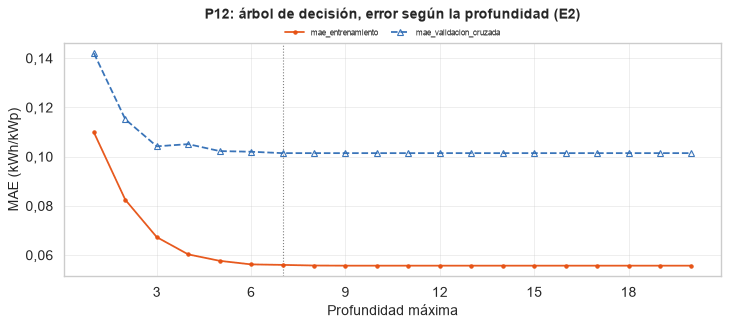

20 filas x 3 columnas; primeras 10:


,mae_entrenamiento,mae_validacion_cruzada,desviacion_cv
max_depth,,,
1,0.1099,0.1421,0.0054
2,0.0825,0.1152,0.0072
3,0.0673,0.1042,0.0201
4,0.0603,0.1051,0.0211
5,0.0577,0.1023,0.0203
6,0.0563,0.1020,0.0201
7,0.0561,0.1015,0.0197
8,0.0558,0.1015,0.0197
9,0.0557,0.1015,0.0197


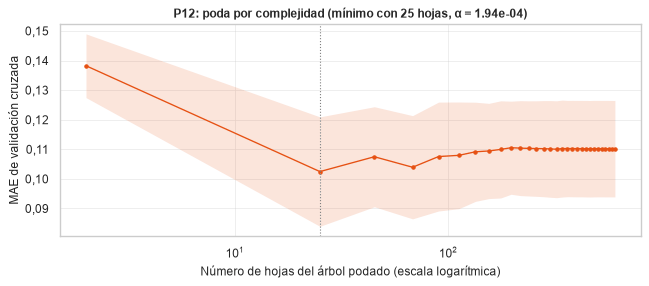

30 filas x 4 columnas; primeras 10:


,ccp_alpha,hojas,mae_cv,desviacion_cv
0,0.0,604,0.1102,0.0163
1,0.0,584,0.1102,0.0163
2,0.0,564,0.1102,0.0163
3,0.0,544,0.1102,0.0163
4,0.0,524,0.1102,0.0163
5,0.0,503,0.1102,0.0163
6,0.0,483,0.1102,0.0163
7,0.0,463,0.1102,0.0163
8,0.0,443,0.1102,0.0163
9,0.0,423,0.1102,0.0163


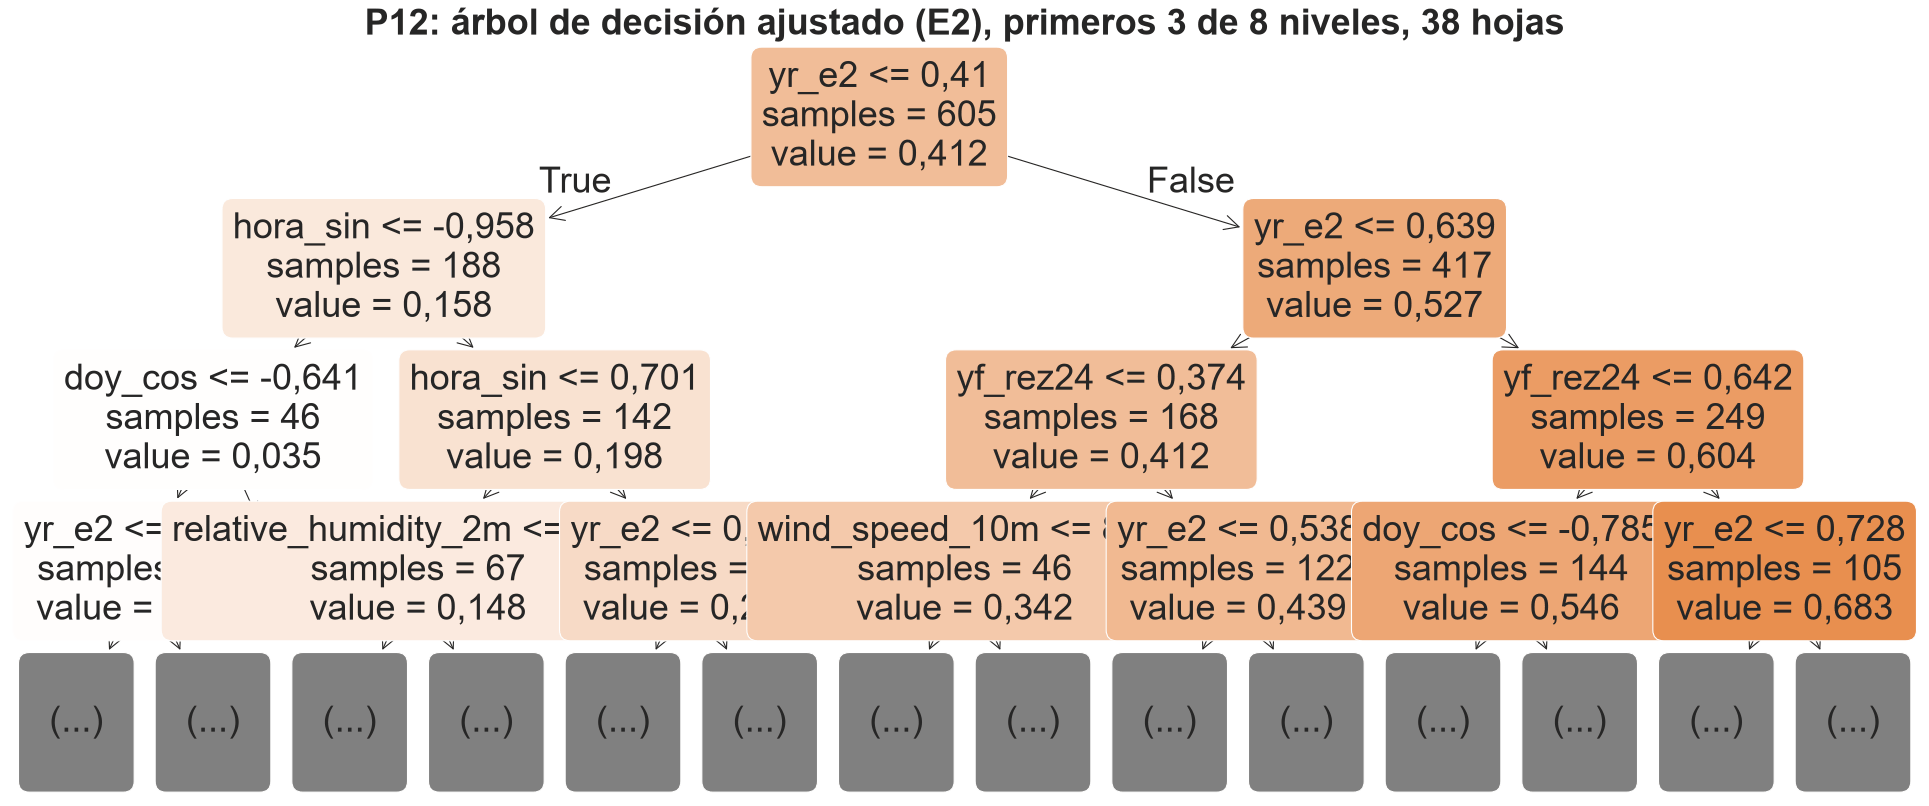

15 filas x 1 columnas; primeras 10:


,importancia
yr_e2,0.8276
yf_rez24,0.0564
hora_sin,0.0514
doy_cos,0.0280
kt_e2,0.0096
wind_speed_10m,0.0061
cloud_cover,0.0052
t_modulo,0.0043
yf_dia_rez1,0.0040
aerosol_optical_depth_rez24,0.0037


|--- yr_e2 <= 0.410
|   |--- hora_sin <= -0.958
|   |   |--- doy_cos <= -0.641
|   |   |   |--- yr_e2 <= 0.169
|   |   |   |   |--- value: [0.045]
|   |   |   |--- yr_e2 >  0.169
|   |   |   |   |--- value: [0.035]
|   |   |--- doy_cos >  -0.641
|   |   |   |--- value: [0.028]
|   |--- hora_sin >  -0.958
|   |   |--- hora_sin <= 0.701
|   |   |   |--- relative_humidity_2m <= 81.250
|   |   |   |   |--- yf_rez168 <= 0.177
|   |   |   |   |   |--- kt_e2 <= 0.903
|   |   |   |   |   |   |--- value: [0.133]
|   |   |   |   |   |--- kt_e2 >  0.903
|   |   |   |   |   |   |--- yf_rez24 <= 0.157
|   |   |   |   |   |   |   |--- value: [0.149]
|   |   |   |   |   |   |--- yf_rez24 >  0.157
|   |   |   |   |   |   |   |--- value: [0.159]
|   |   |   |   |--- yf_rez168 >  0.177
|   |   |   |   |   |--- value: [0.194]
|   |   |   |--- relative_humidity_2m >  81.250
|   |   |   |   |--- value: [0.108]
|   |   |--- hora_sin >  0.701
|   |   |   |--- yr_e2 <= 0.319
|   |   |   |   |--- doy_cos <= -0

**Lectura.** La validación cruzada alcanza su mínimo con profundidad 7 (MAE 0,1015); más allá el error de entrenamiento sigue bajando y el de validación sube: el árbol memoriza. La búsqueda de hiperparámetros eligió profundidad 8 con hojas de al menos 12 horas. La poda por complejidad llega a la misma conclusión por otro camino: el mínimo está en un árbol de 25 hojas. La primera división usa `yr_e2`, la variable que más separa el rendimiento, como cabía esperar del análisis de la sección 6.

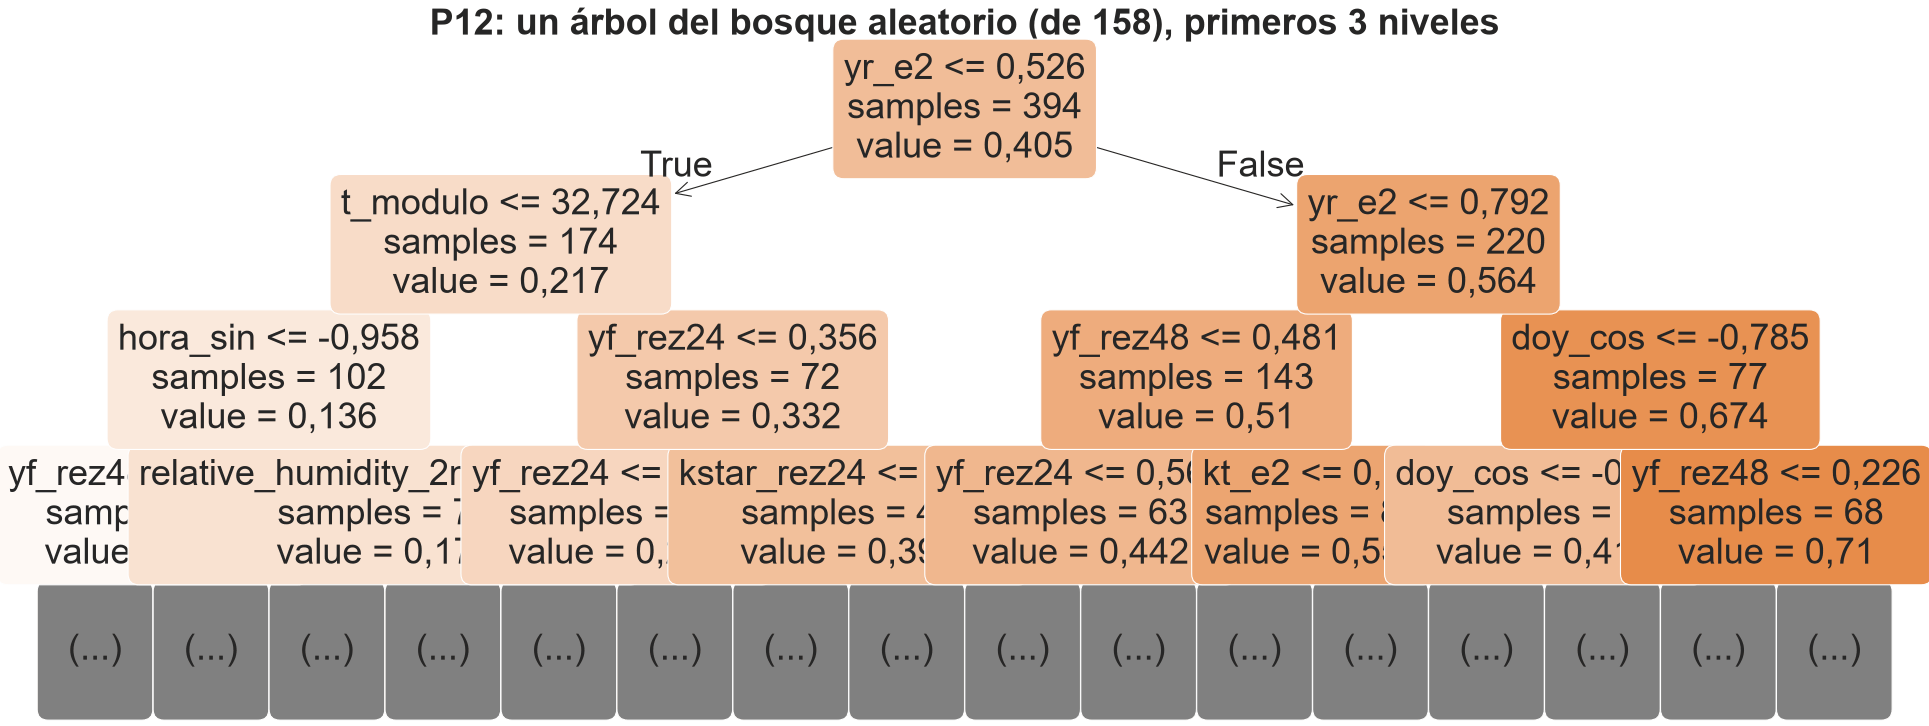

**LightGBM: primer árbol de 119** (cada fila es un nodo: variable, umbral y valor)

,tree_index,node_depth,node_index,left_child,right_child,parent_index,split_feature,split_gain,threshold,decision_type,missing_direction,missing_type,value,weight,count
0,0,1,0-S0,0-S2,0-S1,NaN,yr_e2,15.162900,0.409667,<=,left,None,0.412758,520,520
1,0,2,0-S2,0-L0,0-S7,0-S0,hora_sin,0.587657,-0.957662,<=,left,None,0.396020,147,147
2,0,3,0-L0,NaN,NaN,0-S2,NaN,NaN,NaN,NaN,NaN,NaN,0.389140,36,36
3,0,3,0-S7,0-L3,0-L8,0-S2,kstar_rez24,0.180623,0.578320,<=,left,NaN,0.398296,111,111
4,0,4,0-L3,NaN,NaN,0-S7,NaN,NaN,NaN,NaN,NaN,NaN,0.395788,56,56
5,0,4,0-L8,NaN,NaN,0-S7,NaN,NaN,NaN,NaN,NaN,NaN,0.400911,55,55
6,0,2,0-S1,0-S5,0-S3,0-S0,yr_e2,3.240730,0.638753,<=,left,None,0.419361,373,373
7,0,3,0-S5,0-S10,0-S6,0-S1,yr_e2,0.240373,0.538295,<=,left,None,0.412078,143,143
8,0,4,0-S10,0-L1,0-L11,0-S5,kstar_rez24,0.106640,0.710670,<=,right,NaN,0.409575,72,72
9,0,5,0-L1,NaN,NaN,0-S10,NaN,NaN,NaN,NaN,NaN,NaN,0.407281,37,37


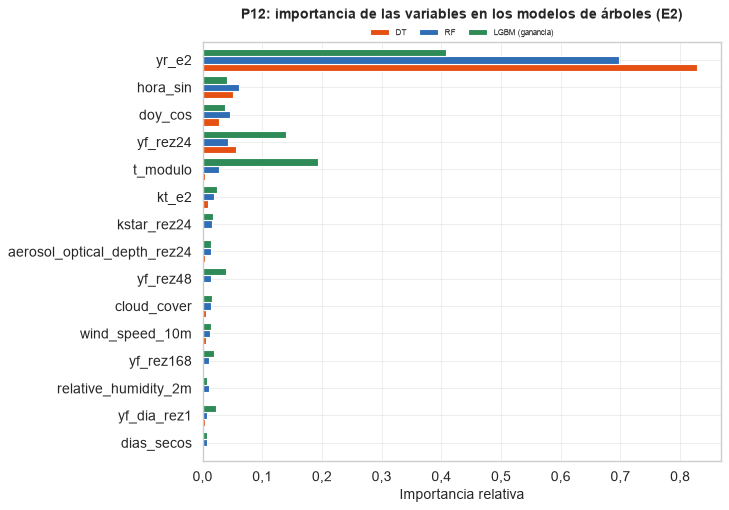

15 filas x 3 columnas; primeras 10:


,DT,RF,LGBM (ganancia)
dias_secos,0.0000,0.0067,0.0076
yf_dia_rez1,0.0040,0.0074,0.0217
relative_humidity_2m,0.0010,0.0101,0.0075
yf_rez168,0.0008,0.0113,0.0187
wind_speed_10m,0.0061,0.0128,0.0147
cloud_cover,0.0052,0.0133,0.0159
yf_rez48,0.0021,0.0144,0.0388
aerosol_optical_depth_rez24,0.0037,0.0144,0.0145
kstar_rez24,0.0000,0.0156,0.0170
kt_e2,0.0096,0.0187,0.0250


AVISO: quedan 0.8 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


In [56]:
# Sección 10.2. Los árboles: dónde cortar y cómo deciden
if MODELABLE:
    from sklearn.impute import SimpleImputer
    from sklearn.model_selection import TimeSeriesSplit, cross_val_score, validation_curve
    from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
    X, y, tr, va, etq = datos_ml(n0, inv0, "E2")
    imp_dt = SimpleImputer(strategy="median").fit(X[tr])
    Xtr = pd.DataFrame(imp_dt.transform(X[tr]), columns=X.columns, index=X.index[tr]); ytr = y[tr]
    cv_t = TimeSeriesSplit(4)
    hoja_min = int(AJ_ML[("E2", "DT")]["parametros"].get("modelo__min_samples_leaf", 1))
    PROF = list(range(1, 21))
    s_tr, s_cv = validation_curve(DecisionTreeRegressor(random_state=config.SEMILLA, min_samples_leaf=hoja_min), Xtr, ytr,
                                  param_name="max_depth", param_range=PROF, cv=cv_t, scoring="neg_mean_absolute_error", n_jobs=config.N_JOBS)
    CURVA_DT = pd.DataFrame({"mae_entrenamiento": -s_tr.mean(axis=1), "mae_validacion_cruzada": -s_cv.mean(axis=1),
                             "desviacion_cv": s_cv.std(axis=1)}, index=pd.Index(PROF, name="max_depth"))
    prof_opt = int(CURVA_DT["mae_validacion_cruzada"].idxmin())
    f = gr.lineas(CURVA_DT[["mae_entrenamiento", "mae_validacion_cruzada"]], f"{n0}: árbol de decisión, error según la profundidad (E2)",
                  "Profundidad máxima", "MAE (kWh/kWp)", anotar_coincidentes=False)
    f.axes[0].axvline(prof_opt, color="grey", ls=":", lw=1)
    fig(f, f"arbol_curva_profundidad_{n0}", CURVA_DT)

    ruta = DecisionTreeRegressor(random_state=config.SEMILLA).cost_complexity_pruning_path(Xtr, ytr)
    alphas = np.unique(np.quantile(ruta.ccp_alphas[:-1], np.linspace(0, 1, 30)))
    filas_a = []
    for a_ in alphas:
        m_ = DecisionTreeRegressor(random_state=config.SEMILLA, ccp_alpha=a_)
        sc = cross_val_score(m_, Xtr, ytr, cv=cv_t, scoring="neg_mean_absolute_error", n_jobs=config.N_JOBS)
        filas_a.append({"ccp_alpha": a_, "hojas": m_.fit(Xtr, ytr).get_n_leaves(), "mae_cv": -sc.mean(), "desviacion_cv": sc.std()})
    PODA = pd.DataFrame(filas_a)
    f, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(PODA["hojas"], PODA["mae_cv"], marker="o", color=config.COLOR_PRINCIPAL)
    ax.fill_between(PODA["hojas"], PODA["mae_cv"] - PODA["desviacion_cv"], PODA["mae_cv"] + PODA["desviacion_cv"], color=config.COLOR_PRINCIPAL, alpha=0.15, lw=0)
    opt = PODA.loc[PODA["mae_cv"].idxmin()]
    ax.axvline(opt["hojas"], color="grey", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("Número de hojas del árbol podado (escala logarítmica)"); ax.set_ylabel("MAE de validación cruzada")
    ax.set_title(f"{n0}: poda por complejidad (mínimo con {int(opt['hojas'])} hojas, α = {opt['ccp_alpha']:.2e})")
    fig(f, f"arbol_poda_{n0}", PODA)

    dt = AJ_ML[("E2", "DT")]["mejor"].named_steps["modelo"]
    f, ax = plt.subplots(figsize=(24, 10))
    plot_tree(dt, max_depth=3, feature_names=list(X.columns), filled=True, rounded=True, impurity=False, precision=3, fontsize=8, ax=ax)
    ax.set_title(f"{n0}: árbol de decisión ajustado (E2), primeros 3 de {dt.get_depth()} niveles, {dt.get_n_leaves()} hojas")
    REGLAS_DT = export_text(dt, feature_names=list(X.columns), decimals=3)
    (config.DIR_DATOS_FIGURAS / f"{PREF}arbol_dt_{n0}.txt").write_text(REGLAS_DT, encoding="utf-8")
    fig(f, f"arbol_dt_{n0}", pd.Series(dt.feature_importances_, index=X.columns, name="importancia").sort_values(ascending=False).to_frame())
    print("\n".join(REGLAS_DT.splitlines()[:30]))
    # print(REGLAS_DT)   # todas las reglas del árbol
    display(Markdown(
        f"**Lectura.** La validación cruzada alcanza su mínimo con profundidad {prof_opt} (MAE {CURVA_DT.loc[prof_opt, 'mae_validacion_cruzada']:.4f}); "
        f"más allá el error de entrenamiento sigue bajando y el de validación sube: el árbol memoriza. La búsqueda de "
        f"hiperparámetros eligió profundidad {dt.get_depth()} con hojas de al menos {hoja_min} horas. La poda por complejidad llega "
        f"a la misma conclusión por otro camino: el mínimo está en un árbol de {int(opt['hojas'])} hojas. La primera división usa "
        f"`{X.columns[dt.tree_.feature[0]]}`, la variable que más separa el rendimiento, como cabía esperar del análisis de la sección 6."))

    rf = AJ_ML[("E2", "RF")]["mejor"].named_steps["modelo"]
    f, ax = plt.subplots(figsize=(24, 9))
    plot_tree(rf.estimators_[0], max_depth=3, feature_names=list(X.columns), filled=True, rounded=True, impurity=False, precision=3, fontsize=8, ax=ax)
    ax.set_title(f"{n0}: un árbol del bosque aleatorio (de {len(rf.estimators_)}), primeros 3 niveles")
    fig(f, f"arbol_rf_ejemplo_{n0}")
    lg = AJ_ML[("E2", "LGBM")]["mejor"].named_steps["modelo"]
    ARBOL_LGBM = lg.booster_.trees_to_dataframe()
    display(Markdown(f"**LightGBM: primer árbol de {lg.booster_.num_trees()}** (cada fila es un nodo: variable, umbral y valor)"))
    display(ARBOL_LGBM[ARBOL_LGBM["tree_index"] == 0].head(15))
    gr.guardar_datos(ARBOL_LGBM[ARBOL_LGBM["tree_index"] < 5], f"{PREF}arboles_lgbm_{n0}")
    IMPORTANCIAS = pd.DataFrame({"DT": dt.feature_importances_, "RF": rf.feature_importances_,
                                 "LGBM (ganancia)": lg.booster_.feature_importance("gain") / lg.booster_.feature_importance("gain").sum()},
                                index=X.columns).sort_values("RF")
    f, ax = plt.subplots(figsize=(9, 0.32 * len(IMPORTANCIAS) + 1.5))
    IMPORTANCIAS.plot.barh(ax=ax, color=config.PALETA[:3], width=0.8)
    ax.set_xlabel("Importancia relativa"); ax.set_title(f"{n0}: importancia de las variables en los modelos de árboles (E2)"); ax.tick_params(axis="y", labelsize=7)
    fig(f, f"importancia_arboles_{n0}", IMPORTANCIAS)

## 11. Redes neuronales

*Base en el máster.* El perceptrón multicapa y la LSTM parten de los cuadernos de introducción al aprendizaje profundo de Redes Neuronales y Deep Learning.

Avanzamos por etapas, de lo básico a lo avanzado, con Keras 3 sobre PyTorch, en CPU y con semilla 37. La primera red, K1,
es un perceptrón multicapa (MLP) con dos capas densas (64 y 32 neuronas, ReLU y *dropout* de 0,2) sobre las mismas
variables tabulares del escenario E2, y es el puente entre el aprendizaje automático y el aprendizaje profundo. La
segunda, K2, es una LSTM por día, una red recurrente bidireccional de 32 unidades que recibe la secuencia de las 24
horas del día objetivo, con el pronóstico meteorológico de cada hora, la geometría solar y los rezagos de 24 y 168 h, y
devuelve las 24 horas de Yf a la vez. Así aprovecha la forma del día completo en lugar de tratar cada hora por separado,
y leer la secuencia en ambos sentidos no es fuga, porque todas las entradas del día objetivo se conocen al emitir el
pronóstico.

Escalamos las entradas con la media y la desviación del entrenamiento, y la parada temprana usa el último 15 % del
entrenamiento (en el tiempo) y no la validación, que queda reservada para comparar modelos. Con unos 400 días de
entrenamiento los datos son pocos para el aprendizaje profundo, así que las redes son pequeñas y regularizadas.

K1: 81 épocas; K2: 99 épocas, 35 días de entrenamiento completos, 12 variables por hora.

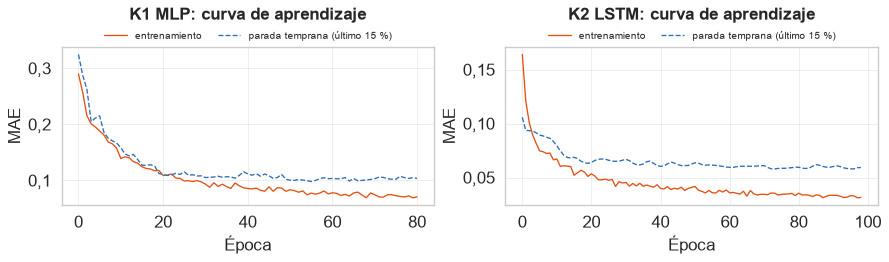

99 filas x 4 columnas; primeras 10:


K1 MLP                       K2 LSTM                
      entrenamiento parada_temprana entrenamiento parada_temprana
epoca                                                            
0            0.2900          0.3247        0.1641          0.1058
1            0.2569          0.2875        0.1213          0.0938
2            0.2152          0.2623        0.1010          0.0934
3            0.2010          0.2048        0.0895          0.0932
4            0.1952          0.2113        0.0818          0.0915
5            0.1883          0.2153        0.0747          0.0895
6            0.1813          0.1862        0.0740          0.0886
7            0.1688          0.1754        0.0724          0.0874
8            0.1654          0.1707        0.0727          0.0864
9            0.1578          0.1669        0.0665          0.0835

**P12: comparación en la misma muestra de validación (178 horas de sol observadas)**

,modelo,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2,skill_vs_cliper
6,K2 LSTM,178,0.1265,0.1611,-0.0166,35.7851,45.5676,0.4018,0.0987
3,ML RF E2,178,0.1208,0.1647,0.0242,34.1661,46.5788,0.3749,0.0787
4,ML ENS E2,178,0.1182,0.1659,0.0343,33.4187,46.9142,0.3659,0.0720
2,SARIMAX E2-MOS,178,0.1265,0.1752,0.0257,35.7830,49.5521,0.2926,0.0199
1,SARIMA,178,0.1336,0.1760,-0.0006,37.7879,49.7713,0.2863,0.0155
0,ref: cliper,178,0.1289,0.1787,-0.0155,36.4563,50.5565,0.2636,0.0000
5,K1 MLP,178,0.1446,0.2085,0.1021,40.8978,58.9808,-0.0023,-0.1666


AVISO: quedan 1.0 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


In [57]:
# Sección 11. Redes neuronales
if MODELABLE:
    from tfm.modelos import redes
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    redes.configurar()
    PRED_NN, HIST_NN = {}, {}
    # K1: MLP tabular (E2)
    X, y, tr, va, etq = datos_ml(n0, inv0, "E2")
    imp_k = SimpleImputer(strategy="median").fit(X[tr])
    esc_k = StandardScaler().fit(imp_k.transform(X[tr]))
    Z = lambda M: esc_k.transform(imp_k.transform(M))
    mlp = redes.mlp(X.shape[1])
    EPOCAS = 300 if not RAPIDO else 3
    with tiempos.medir("K1 MLP", "ajuste", n0, filas=int(tr.sum())):
        HIST_NN["K1 MLP"] = redes.entrenar(mlp, Z(X[tr]), y[tr].to_numpy(), epocas=EPOCAS)
    PRED_NN["K1 MLP"] = pd.Series(mlp.predict(Z(X[va]), verbose=0).ravel(), index=X.index[va]).clip(lower=0)

    # K2: LSTM bidireccional sobre la secuencia del día
    Xs_full, ys_full = candidatas(n0, inv0, "E2")
    COLS_SEQ = [c for c in ("yr_e2", "kt_e2", "temperature_2m", "relative_humidity_2m", "cloud_cover", "cos_cenit", "yr_cs",
                            "yf_rez24", "yf_rez168", "kstar_rez24", "hora_sin", "hora_cos") if c in Xs_full.columns]
    Xs_full = Xs_full[COLS_SEQ]
    filas_tr = part.etiquetar(Xs_full.index).to_numpy() == "entrenamiento"
    imp_s = SimpleImputer(strategy="median").fit(Xs_full[filas_tr])
    esc_s = StandardScaler().fit(imp_s.transform(Xs_full[filas_tr]))
    Xs_esc = pd.DataFrame(esc_s.transform(imp_s.transform(Xs_full)), index=Xs_full.index, columns=COLS_SEQ)
    XA, YA, DIAS_SEQ, TA = redes.secuencias_diarias(Xs_esc, ys_full)
    etq_dias = part.etiquetar(DIAS_SEQ).to_numpy()
    obs_h = (observado(OBJ_H[n0]) | (OBJ_H[n0]["yr_cs"] <= 0.05)).reindex(pd.DatetimeIndex(TA.ravel())).fillna(False)
    # Para entrenar basta con que el día tenga las 24 horas del objetivo y este en régimen estable (la regla de
    # "solo observados" es para las métricas, no para el entrenamiento)
    en_reg_dia = OBJ_H[n0]["en_regimen"].reindex(pd.DatetimeIndex(TA.ravel())).fillna(False).to_numpy().reshape(TA.shape).all(axis=1)
    completo_d = ~np.isnan(YA).any(axis=1) & en_reg_dia
    tr_d, va_d = (etq_dias == "entrenamiento") & completo_d, etq_dias == "validacion"
    lstm = redes.lstm_dia(len(COLS_SEQ))
    with tiempos.medir("K2 LSTM", "ajuste", n0, dias=int(tr_d.sum())):
        HIST_NN["K2 LSTM"] = redes.entrenar(lstm, XA[tr_d], YA[tr_d][..., None], lote=16, epocas=EPOCAS)
    p_ = pd.Series(lstm.predict(XA[va_d], verbose=0)[..., 0].ravel(), index=pd.DatetimeIndex(TA[va_d].ravel())).clip(lower=0)
    PRED_NN["K2 LSTM"] = p_.where(OBJ_H[n0]["yr_cs"].reindex(p_.index).to_numpy() > 0, 0.0)
    display(Markdown(f"K1: {len(HIST_NN['K1 MLP'].history['loss'])} épocas; K2: {len(HIST_NN['K2 LSTM'].history['loss'])} épocas, "
                     f"{int(tr_d.sum())} días de entrenamiento completos, {len(COLS_SEQ)} variables por hora."))

    # Sensibilidad a la semilla (unidad principal del grupo): con la misma semilla el resultado es idéntico; con otras
    # semillas cambia la inicialización de los pesos y el orden de los lotes, y la dispersión mide cuanto de la
    # diferencia entre redes y otros modelos es azar. El modelo que se compara sigue siendo el de la semilla 37.
    nrmse_val = lambda p: met.evaluar(y0.reindex(p.index), p, observado(OBJ_H[n0]).reindex(p.index)).get("nrmse_pct", np.nan)
    filas_sem = [{"semilla": config.SEMILLA, "K1 MLP": nrmse_val(PRED_NN["K1 MLP"]), "K2 LSTM": nrmse_val(PRED_NN["K2 LSTM"])}]
    for s_ in (() if RAPIDO or UNIDAD else (38, 39, 40, 41)):
        config.fijar_semilla(s_)
        m_ = redes.mlp(X.shape[1]); redes.entrenar(m_, Z(X[tr]), y[tr].to_numpy(), epocas=EPOCAS)
        l_ = redes.lstm_dia(len(COLS_SEQ)); redes.entrenar(l_, XA[tr_d], YA[tr_d][..., None], lote=16, epocas=EPOCAS)
        p1_ = pd.Series(m_.predict(Z(X[va]), verbose=0).ravel(), index=X.index[va]).clip(lower=0)
        p2_ = pd.Series(l_.predict(XA[va_d], verbose=0)[..., 0].ravel(), index=pd.DatetimeIndex(TA[va_d].ravel())).clip(lower=0)
        p2_ = p2_.where(OBJ_H[n0]["yr_cs"].reindex(p2_.index).to_numpy() > 0, 0.0)
        filas_sem.append({"semilla": s_, "K1 MLP": nrmse_val(p1_), "K2 LSTM": nrmse_val(p2_)})
    config.fijar_semilla()
    SEMILLAS_NN = pd.DataFrame(filas_sem).set_index("semilla")
    if len(SEMILLAS_NN) > 1:
        display(Markdown("**Sensibilidad a la semilla** (nRMSE % en la validación)")); display(SEMILLAS_NN.round(2))
        display(Markdown(
            f"**Resultado.** Entre las {len(SEMILLAS_NN)} semillas, el MLP va de {SEMILLAS_NN['K1 MLP'].min():.1f} a "
            f"{SEMILLAS_NN['K1 MLP'].max():.1f} % (desviación {SEMILLAS_NN['K1 MLP'].std():.2f} puntos) y la LSTM de "
            f"{SEMILLAS_NN['K2 LSTM'].min():.1f} a {SEMILLAS_NN['K2 LSTM'].max():.1f} % (desviación {SEMILLAS_NN['K2 LSTM'].std():.2f} puntos)."))
        res.registrar(f"localidades.{GRUPO}.modelos.semillas_redes_{n0}", {"nrmse_pct": SEMILLAS_NN.round(3).to_dict(),
                      "media": SEMILLAS_NN.mean().round(3).to_dict(), "desviacion": SEMILLAS_NN.std().round(3).to_dict()})

    f, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    for a, (k, h) in zip(ax, HIST_NN.items()):
        a.plot(h.history["loss"], label="entrenamiento"); a.plot(h.history["val_loss"], label="parada temprana (último 15 %)")
        a.set_title(f"{k}: curva de aprendizaje"); a.set_xlabel("Época"); a.set_ylabel("MAE"); a.legend(fontsize=8)
    fig(f, f"redes_aprendizaje_{n0}", pd.concat({k: pd.DataFrame({"entrenamiento": h.history["loss"], "parada_temprana": h.history["val_loss"]})
                                                  for k, h in HIST_NN.items()}, axis=1).rename_axis("epoca"))

    obs_v = observado(OBJ_H[n0])
    idx_c = PRED_NN["K1 MLP"].index.intersection(PRED_NN["K2 LSTM"].index)
    CANDIDATOS_VAL = {"ref: cliper": REF_H["cliper"], "SARIMA": PRED_VAL["SARIMA"], "SARIMAX E2-MOS": PRED_X["SARIMAX E2-MOS"],
                      f"ML {mejor_e2} E2": PRED_ML[("E2", mejor_e2)], "ML ENS E2": PRED_ML[("E2", "ENS")], **PRED_NN}
    if len(idx_c) < 24:
        # Unidad con pocas semanas: las redes pueden no tener días completos en común con los demás modelos
        idx_c = PRED_VAL["SARIMA"].dropna().index
    EXCLUIDOS_VAL = []
    for k_, p_ in CANDIDATOS_VAL.items():
        nuevo = idx_c.intersection(p_.dropna().index)
        if len(nuevo[obs_v.reindex(nuevo).fillna(False).to_numpy()]) >= 24:
            idx_c = nuevo
        else:
            EXCLUIDOS_VAL.append(k_)
    for k_ in EXCLUIDOS_VAL:
        CANDIDATOS_VAL.pop(k_)
    if EXCLUIDOS_VAL:
        display(Markdown("**Sin horas en común con los demás modelos en la validación** (se excluyen de esta comparación): "
                         + ", ".join(EXCLUIDOS_VAL)))
    idx_c = idx_c[obs_v.reindex(idx_c).fillna(False).to_numpy()]
    TABLA_K = pd.DataFrame([{"modelo": k, **met.evaluar(y0.reindex(idx_c), p_.reindex(idx_c))} for k, p_ in CANDIDATOS_VAL.items()])
    TABLA_K["skill_vs_cliper"] = 1 - TABLA_K["rmse"] / TABLA_K.set_index("modelo").loc["ref: cliper", "rmse"]
    display(Markdown(f"**{n0}: comparación en la misma muestra de validación ({len(idx_c)} horas de sol observadas)**"))
    display(TABLA_K.sort_values("rmse").round(4))
    res.registrar(f"localidades.{GRUPO}.modelos.comparacion_validacion_{n0}", TABLA_K.set_index("modelo").round(5).to_dict(orient="index"))

## 12. Evaluación final, suficiencia de datos y periodo en vivo

### 12.1. Elección del modelo antes de la prueba

Fijamos la regla antes de mirar la prueba y la aplicamos con la validación, de modo que la prueba siga siendo una
evaluación independiente. Primero formamos el **conjunto de modelos que no se distinguen del mejor** con el *Model
Confidence Set* de Hansen, Lunde y Nason (2011), por eliminación sucesiva con el estadístico máximo, nivel del 10 %,
pérdidas cuadráticas sumadas por día y *bootstrap* estacionario por bloques de 7 días (1 000 réplicas, semilla 37).
Comparar todos los modelos a la vez controla el error de las comparaciones múltiples, que una serie de pruebas por pares
no controla. Después elegimos entre los modelos del conjunto **el más simple**, en este orden: CLIPER (la referencia),
SARIMA, SARIMAX, árbol de decisión, KNN, SVR, bosque aleatorio, HGB, LightGBM, ensamble, MLP y LSTM. La referencia es
candidata, porque si ningún modelo la supera de forma significativa la unidad no gana nada con un modelo más complejo.

No aplicamos la regla con la prueba, porque la prueba dejaría de ser independiente y el error informado del modelo
elegido sería optimista.

In [58]:
# Sección 12.1. Elección del modelo antes de la prueba
if MODELABLE:
    SIMPLICIDAD = {"ref: cliper": 0, "SARIMA": 1, "SARIMAX E2-MOS": 2, "ML DT E2": 3, "ML KNN E2": 4, "ML SVR E2": 5, "ML RF E2": 6,
                   "ML HGB E2": 7, "ML LGBM E2": 8, "ML ENS E2": 9, "K1 MLP": 10, "K2 LSTM": 11}
    PERD_VAL = met.perdidas_diarias(y0.reindex(idx_c), {k: p_.reindex(idx_c) for k, p_ in CANDIDATOS_VAL.items()})
    MCS_VAL = met.conjunto_confianza(PERD_VAL)
    MCS_VAL["nrmse_pct"] = TABLA_K.set_index("modelo")["nrmse_pct"].reindex(MCS_VAL.index)
    MCS_VAL["complejidad"] = [SIMPLICIDAD.get(k, 99) for k in MCS_VAL.index]
    MEJOR_VAL = MCS_VAL["nrmse_pct"].idxmin()
    MCS_VAL["dm_diario_p_vs_mejor"] = [np.nan if k == MEJOR_VAL else met.diebold_mariano_diario(
        y0.reindex(idx_c), CANDIDATOS_VAL[MEJOR_VAL].reindex(idx_c), CANDIDATOS_VAL[k].reindex(idx_c))["p_valor"] for k in MCS_VAL.index]
    SELECCION_VAL = MCS_VAL[MCS_VAL["incluido"]].sort_values(["complejidad", "nrmse_pct"]).index[0]
    display(Markdown(f"**Conjunto de modelos equivalentes al mejor en la validación** ({len(PERD_VAL)} días; p del MCS ≥ 0,10: incluido)"))
    display(MCS_VAL.sort_values("nrmse_pct").round(4))
    incl = MCS_VAL.index[MCS_VAL["incluido"]].tolist()
    display(Markdown(
        f"**Decisión.** El menor error en la validación es el de {MEJOR_VAL} ({MCS_VAL.loc[MEJOR_VAL, 'nrmse_pct']:.1f} %). "
        f"No se distinguen de él: {', '.join(k for k in incl if k != MEJOR_VAL) or 'ninguno'}. Por la regla, el modelo elegido para "
        f"{n0} es **{SELECCION_VAL}**" + (", es decir, la referencia: ningún modelo la mejora de forma significativa en esta unidad."
        if SELECCION_VAL.startswith("ref") else ".")))
    res.registrar(f"localidades.{GRUPO}.modelos.seleccion_validacion_{n0}", {
        "elegido": SELECCION_VAL, "mejor": MEJOR_VAL, "dias": int(len(PERD_VAL)),
        "mcs": MCS_VAL.round(5).replace({np.nan: None}).to_dict(orient="index")})

    # Entrada de la validación por bloques (05_bloques.ipynb): series horarias completas de la unidad y su especificación
    # (orden del SARIMA, variables y componentes del ensamble). Los bloques reestiman coeficientes e hiperparámetros.
    import json as _json
    DIR_BLOQ = config.DIR_INTERMEDIOS / f"bloques{SUF}"
    DIR_BLOQ.mkdir(parents=True, exist_ok=True)
    X2_, _ = candidatas(n0, inv0, "E2")
    cols2_ = [c for c in SEL["E2"] if c in X2_.columns]
    B_ = pd.DataFrame({"yf": y0, "yr_obs": XE["E1"]["yr"], "yr_e2": XE["E2"]["yr"]}, index=y0.index)
    B_ = B_.join(OBJ_H[n0][["yr_cs", "kstar", "frac_imputada", "en_regimen"]]).join(X2_[cols2_].add_prefix("x_"))
    B_["modelable"] = pd.Series(mascara_modelado(n0), index=OBJ_H[n0].index).reindex(B_.index).fillna(False)
    B_.to_parquet(DIR_BLOQ / f"{GRUPO}_{n0}.parquet")
    (DIR_BLOQ / f"{GRUPO}_{n0}.json").write_text(_json.dumps({
        "grupo": GRUPO, "unidad": n0, "orden": list(orden_s), "estacional": list(est_s),
        "orden_sarimax": list(orden_x), "estacional_sarimax": list(est_x), "variables": cols2_,
        "ml_ensamble": AJ_ML[("E2", "ENS")]["componentes"], "ml_mejor": mejor_e2, "epocas": EPOCAS,
        "seleccion_validacion": SELECCION_VAL, "kwp": kwp_de(n0), "particion_propia": bool(PARTICION_PROPIA)},
        ensure_ascii=False, indent=1), encoding="utf-8")

**Conjunto de modelos equivalentes al mejor en la validación** (19 días; p del MCS ≥ 0,10: incluido)

,p_mcs,incluido,nrmse_pct,complejidad,dm_diario_p_vs_mejor
K2 LSTM,NaN,True,45.5676,11,NaN
ML RF E2,NaN,True,46.5788,6,0.7465
ML ENS E2,NaN,True,46.9142,9,0.6807
SARIMAX E2-MOS,NaN,True,49.5521,2,0.2945
SARIMA,NaN,True,49.7713,1,0.3313
ref: cliper,NaN,True,50.5565,0,0.3271
K1 MLP,NaN,True,58.9808,10,0.0482


**Decisión.** El menor error en la validación es el de K2 LSTM (45,6 %). No se distinguen de él: ref: cliper, SARIMA, SARIMAX E2-MOS, ML RF E2, ML ENS E2, K1 MLP. Por la regla, el modelo elegido para P12 es **ref: cliper**, es decir, la referencia: ningún modelo la mejora de forma significativa en esta unidad.

AVISO: quedan 1.0 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


### 12.2. Prueba (los dos meses anteriores al corte del modelado)

Elegidos los modelos con la validación, se reentrenan con entrenamiento y validación juntos (todo lo
anterior a la prueba) y se evalúan **una sola vez** en la prueba. Se comparan las referencias, el mejor de
cada familia (SARIMA, SARIMAX E2-MOS, aprendizaje automático en E2 y su ensamble, MLP y LSTM) con la
prueba de Diebold-Mariano frente a CLIPER y el *skill score*. El error se desglosa por hora del día y
por tipo de día (despejado, intermedio y nublado, según el k* observado).

**P12: prueba, pronóstico del día siguiente (H01DH), 153 horas de sol observadas**

,modelo,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2,dm_vs_cliper,p_dm,skill_vs_cliper
0,SARIMAX E2-MOS,153,0.0960,0.1216,-0.0310,23.8886,30.2657,0.7117,-5.3868,0.0000,0.2914
1,ML RF E2,153,0.1044,0.1319,-0.0295,25.9887,32.8223,0.6610,-3.4696,0.0007,0.2315
2,K2 LSTM,153,0.1045,0.1343,-0.0210,26.0013,33.4148,0.6486,-4.8947,0.0000,0.2176
3,ML ENS E2,153,0.1072,0.1346,-0.0297,26.6766,33.4917,0.6470,-2.9600,0.0036,0.2158
4,K1 MLP,153,0.1025,0.1411,0.0188,25.5202,35.1123,0.6120,-3.2215,0.0016,0.1779
5,ref: cliper,153,0.1298,0.1716,-0.0456,32.3079,42.7098,0.4260,NaN,NaN,0.0000
6,SARIMA,153,0.1413,0.1721,-0.0617,35.1814,42.8351,0.4226,0.0330,0.9737,-0.0029
7,ref: persistencia,153,0.1330,0.1899,-0.0152,33.1070,47.2691,0.2969,2.2781,0.0241,-0.1068


**Diebold-Mariano del mejor modelo (SARIMAX E2-MOS) frente a cada uno de los demás** (negativo: el mejor es más preciso)

,n,dm,p_valor,diferencia_media
modelo,,,,
SARIMA,153,-3.2598,0.0014,-0.0148
ML RF E2,153,-3.7520,0.0002,-0.0026
ML ENS E2,153,-5.7954,0.0000,-0.0033
K1 MLP,153,-2.3759,0.0188,-0.0051
K2 LSTM,153,-1.0377,0.3011,-0.0032


**Lectura.** SARIMAX E2-MOS tiene el menor error, pero la diferencia no es significativa (p ≥ 0,05) frente a: K2 LSTM. La elección no se hace aquí: la regla de la sección 12.1 eligió ref: cliper con la validación, y la prueba solo confirma esa elección (sección 12.8).

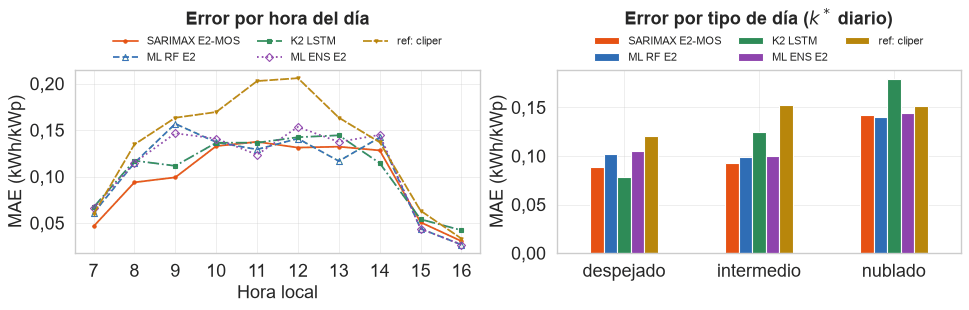

13 filas x 5 columnas; primeras 10:


SARIMAX E2-MOS  ML RF E2  K2 LSTM  ML ENS E2  ref: cliper
por_hora 7           0.0464    0.0606   0.0670     0.0659       0.0595
         8           0.0938    0.1147   0.1171     0.1150       0.1346
         9           0.0991    0.1568   0.1115     0.1465       0.1633
         10          0.1328    0.1370   0.1364     0.1409       0.1694
         11          0.1374    0.1292   0.1364     0.1235       0.2028
         12          0.1312    0.1409   0.1423     0.1534       0.2059
         13          0.1321    0.1166   0.1444     0.1372       0.1634
         14          0.1282    0.1421   0.1145     0.1449       0.1369
         15          0.0508    0.0439   0.0540     0.0437       0.0632
         16          0.0305    0.0266   0.0422     0.0268       0.0332

**Tipo de día.** Cada día de la prueba se clasifica por su índice de cielo despejado diario observado k* = Yf del día / Yr de cielo despejado del día: **nublado** si k* < 0,40, **intermedio** si 0,40 ≤ k* < 0,65 y **despejado** si k* ≥ 0,65. Solo cuentan los días con horas de sol observadas en la muestra común de todos los modelos. Días por tipo: despejado: 9, intermedio: 5, nublado: 2 (18 días). Con pocos días de un tipo, su error medio es poco estable.

,tipo,k_dia
2026-10-14,despejado,0.732
2026-10-15,despejado,0.844
2026-10-16,despejado,0.814
2026-10-17,intermedio,0.428
2026-10-18,NaN,NaN
2026-10-19,despejado,0.689
2026-10-20,intermedio,0.585
2026-10-21,nublado,0.270
2026-10-22,intermedio,0.612
2026-10-23,despejado,0.747


AVISO: quedan 0.9 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


In [59]:
# Sección 12.2. Prueba (los dos meses anteriores al corte del modelado)
if MODELABLE:
    hasta_val = np.isin(etq_h[n0], ["entrenamiento", "validacion"])
    FINAL = {}
    o_pru = origen(dias_pru)
    with tiempos.medir("SARIMA", "ajuste_final", n0):
        a_s = sarima.ajustar(y0[hasta_val], orden_s, est_s)
    with tiempos.medir("SARIMA", "prediccion_prueba", n0, dias=len(o_pru)):
        FINAL["SARIMA"] = postproceso(sarima.pronostico_por_origen(a_s, y0, o_pru, 24), OBJ_H[n0])
    with tiempos.medir("SARIMAX E2-MOS", "ajuste_final", n0):
        a_x = sarima.ajustar(y0[hasta_val], orden_x, est_x, exog=XE["E2"][hasta_val])
    with tiempos.medir("SARIMAX E2-MOS", "prediccion_prueba", n0, dias=len(o_pru)):
        FINAL["SARIMAX E2-MOS"] = postproceso(sarima.pronostico_por_origen(a_x, y0, o_pru, 24, XE["E2"]), OBJ_H[n0])
    MODELOS_FINALES = {"SARIMA": a_s, "SARIMAX E2-MOS": a_x}
    X, y, tr, va, etq = datos_ml(n0, inv0, "E2")
    m_mod = mascara_modelado(n0)
    tv, pr_m = m_mod & np.isin(etq, ["entrenamiento", "validacion"]), m_mod & (etq == "prueba")
    for k in dict.fromkeys((mejor_e2, "ENS")):              # sin repetir si el mejor es el propio ensamble
        est_ = AJ_ML[("E2", k)]["mejor"]
        from sklearn.base import clone
        with tiempos.medir(f"ML {k} E2", "ajuste_final", n0, filas=int(tv.sum())):
            modelo_k = clone(est_).fit(X[tv], y[tv])
        with tiempos.medir(f"ML {k} E2", "prediccion_prueba", n0, filas=int(pr_m.sum())):
            FINAL[f"ML {k} E2"] = pd.Series(np.clip(modelo_k.predict(X[pr_m]), 0, None), index=X.index[pr_m])
        MODELOS_FINALES[f"ML {k} E2"] = modelo_k
    imp_f = SimpleImputer(strategy="median").fit(X[tv]); esc_f = StandardScaler().fit(imp_f.transform(X[tv]))
    mlp_f = redes.mlp(X.shape[1])
    with tiempos.medir("K1 MLP", "ajuste_final", n0, filas=int(tv.sum())):
        redes.entrenar(mlp_f, esc_f.transform(imp_f.transform(X[tv])), y[tv].to_numpy(), epocas=EPOCAS)
    FINAL["K1 MLP"] = pd.Series(mlp_f.predict(esc_f.transform(imp_f.transform(X[pr_m])), verbose=0).ravel(), index=X.index[pr_m]).clip(lower=0)
    tv_d, pr_d = np.isin(etq_dias, ["entrenamiento", "validacion"]) & completo_d, etq_dias == "prueba"
    lstm_f = redes.lstm_dia(len(COLS_SEQ))
    with tiempos.medir("K2 LSTM", "ajuste_final", n0, dias=int(tv_d.sum())):
        redes.entrenar(lstm_f, XA[tv_d], YA[tv_d][..., None], lote=16, epocas=EPOCAS)
    p_ = pd.Series(lstm_f.predict(XA[pr_d], verbose=0)[..., 0].ravel(), index=pd.DatetimeIndex(TA[pr_d].ravel())).clip(lower=0)
    FINAL["K2 LSTM"] = p_.where(OBJ_H[n0]["yr_cs"].reindex(p_.index).to_numpy() > 0, 0.0)
    REF_F = refs.horarias_h2(OBJ_H[n0], hasta_val)
    for c in ("persistencia", "cliper"):
        FINAL[f"ref: {c}"] = REF_F[c]

    obs_p = observado(OBJ_H[n0])
    idx_p = None
    for p_ in FINAL.values():
        i_ = p_.dropna().index[part.etiquetar(p_.dropna().index).to_numpy() == "prueba"]
        idx_p = i_ if idx_p is None else idx_p.intersection(i_)
    idx_p = idx_p[obs_p.reindex(idx_p).fillna(False).to_numpy()]
    TABLA_L = []
    for k, p_ in FINAL.items():
        dm = met.diebold_mariano(y0.reindex(idx_p), p_.reindex(idx_p), FINAL["ref: cliper"].reindex(idx_p), h=24) if k != "ref: cliper" else {}
        TABLA_L.append({"modelo": k, **met.evaluar(y0.reindex(idx_p), p_.reindex(idx_p)), "dm_vs_cliper": dm.get("dm"), "p_dm": dm.get("p_valor")})
    TABLA_L = pd.DataFrame(TABLA_L)
    TABLA_L["skill_vs_cliper"] = 1 - TABLA_L["rmse"] / TABLA_L.set_index("modelo").loc["ref: cliper", "rmse"]
    TABLA_L = TABLA_L.sort_values("rmse").reset_index(drop=True)
    display(Markdown(f"**{n0}: prueba, pronóstico del día siguiente (H01DH), {len(idx_p)} horas de sol observadas**")); display(TABLA_L.round(4))
    # ¿Es el mejor modelo realmente distinto de los demás? Diebold-Mariano por pares contra el mejor
    mejor_l = TABLA_L[~TABLA_L["modelo"].str.startswith("ref")].iloc[0]["modelo"]
    DM_PARES = pd.DataFrame([{"modelo": k, **met.diebold_mariano(y0.reindex(idx_p), FINAL[mejor_l].reindex(idx_p), FINAL[k].reindex(idx_p), h=24)}
                             for k in FINAL if k != mejor_l and not k.startswith("ref")]).set_index("modelo")
    display(Markdown(f"**Diebold-Mariano del mejor modelo ({mejor_l}) frente a cada uno de los demás** (negativo: el mejor es más preciso)"))
    display(DM_PARES.round(4))
    empatados = [k for k, p in DM_PARES["p_valor"].items() if p >= 0.05]
    display(Markdown((
        f"**Lectura.** {mejor_l} tiene el menor error, pero la diferencia no es significativa (p ≥ 0,05) frente a: "
        f"{', '.join(empatados) if empatados else 'ninguno'}. " if empatados else
        f"**Lectura.** {mejor_l} es significativamente mejor que todos los demás modelos (p < 0,05). ")
        + f"La elección no se hace aquí: la regla de la sección 12.1 eligió {SELECCION_VAL} con la validación, y la prueba solo "
        "confirma esa elección (sección 12.8)."))
    res.registrar(f"localidades.{GRUPO}.modelos.prueba_dm_pares_{n0}", {"mejor": mejor_l, "dm": DM_PARES.round(5).to_dict(orient="index"),
                  "empatados": empatados})

    # Error por hora local y por tipo de día
    hora_l = np.asarray((idx_p - pd.Timedelta("30min")).tz_convert(config.ZONA).hour)
    k_dia = caract.diario_a_horario(OBJ_D[n0]["kstar"], idx_p, 0)
    tipo = pd.cut(k_dia, [-np.inf, 0.4, 0.65, np.inf], labels=["nublado", "intermedio", "despejado"])
    mejores = TABLA_L["modelo"].head(4).tolist() + (["ref: cliper"] if "ref: cliper" not in TABLA_L["modelo"].head(4).tolist() else [])
    f, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    tabla_hora = pd.DataFrame({k: (FINAL[k].reindex(idx_p) - y0.reindex(idx_p)).abs().groupby(hora_l).mean().to_numpy()
                               for k in mejores}, index=sorted(set(hora_l))).rename_axis("hora_local")
    gr.lineas(tabla_hora, "Error por hora del día", "Hora local", "MAE (kWh/kWp)", ax=ax[0], anotar_coincidentes=False)
    # Abajo al centro, donde las curvas (más altas al mediodía) dejan espacio, y del mismo tamaño en los dos paneles
    ax[0].legend(fontsize=9.5, loc="lower center")
    tabla_tipo = pd.DataFrame({k: (FINAL[k].reindex(idx_p) - y0.reindex(idx_p)).abs().groupby(tipo.to_numpy()).mean() for k in mejores})
    tabla_tipo.plot.bar(ax=ax[1], rot=0, color=config.PALETA[:len(mejores)]); ax[1].set_ylabel("MAE (kWh/kWp)")
    ax[1].set_title("Error por tipo de día (k* diario)"); ax[1].legend(fontsize=9.5)
    fig(f, f"prueba_error_hora_tipo_{n0}", pd.concat({"por_hora": tabla_hora, "por_tipo_de_dia": tabla_tipo}))
    DIAS_TIPO = pd.DataFrame({"tipo": tipo.to_numpy(), "k_dia": k_dia.to_numpy()}, index=idx_p).groupby(part.dias_locales(idx_p)).first()
    display(Markdown(
        "**Tipo de día.** Cada día de la prueba se clasifica por su índice de cielo despejado diario observado "
        "k* = Yf del día / Yr de cielo despejado del día: **nublado** si k* < 0,40, **intermedio** si 0,40 ≤ k* < 0,65 y "
        "**despejado** si k* ≥ 0,65. Solo cuentan los días con horas de sol observadas en la muestra común de todos los "
        "modelos. Días por tipo: " + ", ".join(f"{k}: {int(v)}" for k, v in DIAS_TIPO["tipo"].value_counts().items()) +
        f" ({len(DIAS_TIPO)} días). Con pocos días de un tipo, su error medio es poco estable."))
    display(DIAS_TIPO.round(3))
    res.registrar(f"localidades.{GRUPO}.modelos.prueba_h2_{n0}", TABLA_L.set_index("modelo").round(5).to_dict(orient="index"))
    # Predicciones horarias de la prueba: el cuaderno del modelo global las compara con Diebold-Mariano
    if True:
        DIR_PRED = config.DIR_INTERMEDIOS / f"predicciones{SUF}"
        DIR_PRED.mkdir(parents=True, exist_ok=True)
        pd.DataFrame({k: v.reindex(idx_p) for k, v in FINAL.items()}).assign(y=y0.reindex(idx_p)).to_parquet(DIR_PRED / f"{GRUPO}_{n0}_prueba.parquet")

### 12.3. Series de pronóstico frente a lo observado

Las métricas resumen el error; las series muestran cómo se comete. Primero, tres días de la prueba, uno de
cada tipo (despejado, intermedio y nublado, el de k* más cercano a la mediana de su tipo), con lo observado,
el SARIMAX E2-MOS, su **intervalo de predicción del 80 %** y CLIPER. El intervalo es empírico: los percentiles
10 y 90 del error del día siguiente en la validación, por hora local, sumados al pronóstico (sin bajar de 0). Se
calibra con la validación y su cobertura se mide en la prueba: si el intervalo está bien calibrado, cubre cerca
del 80 % de las horas observadas. Es un intervalo de predicción (dónde caerá la observación), no un intervalo
de confianza de un parámetro. Como la validación (julio y agosto) y la prueba (septiembre y octubre) caen en
temporadas distintas, también se mide la cobertura de un intervalo recalibrado cada día con los errores de los 30
días anteriores, que en la operación ya son conocidos.

Después, la serie diaria de cada modelo en la validación (donde se elige) y en la prueba (donde se confirma),
con lo observado y CLIPER en cada panel. Para que lo observado y lo pronosticado sean comparables, cada día
suma solo las horas comunes a todos los modelos con el objetivo observado.

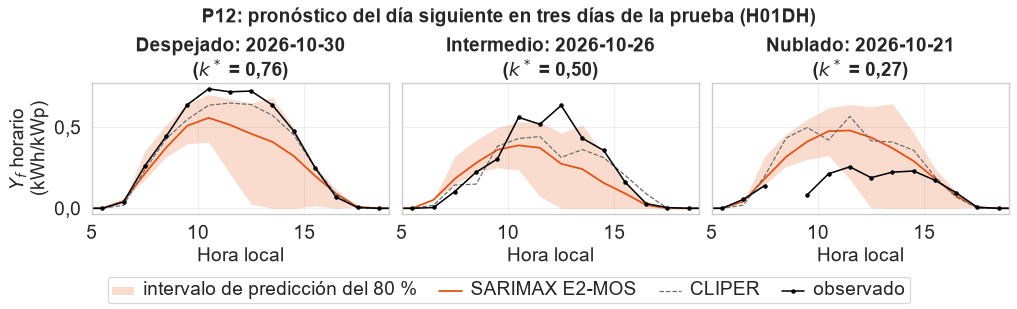

72 filas x 5 columnas; primeras 10:


observado  sarimax_e2_mos  ip80_inf  ip80_sup  cliper
          datatime                                                                        
despejado 2026-10-30 06:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 07:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 08:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 09:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 10:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 11:00:00+00:00     0.0000          0.0000    0.0000    0.0000  0.0000
          2026-10-30 12:00:00+00:00     0.0389          0.0458    0.0458    0.0458  0.0188
          2026-10-30 13:00:00+00:00     0.2620          0.2145    0.1781    0.3532  0.2376
          2026-10-30 14:00:00+00:00     0.4438          0.3744    0.3168    0.5159  0.4287
          2026-10-30 15:00:00+00:00     0.6399          0.5100    0.3989    0.6475  0.5492

**Intervalo de predicción del 80 %.** Calibrado con 178 horas de la validación, cubre el 79,7 % de las 153 horas observadas de la prueba (ancho medio 0,344 kWh/kWp): está bien calibrado. Recalibrado cada día con los errores de los 30 días anteriores, como se haría en la operación, cubre el 81,0 % (ancho medio 0,329 kWh/kWp).

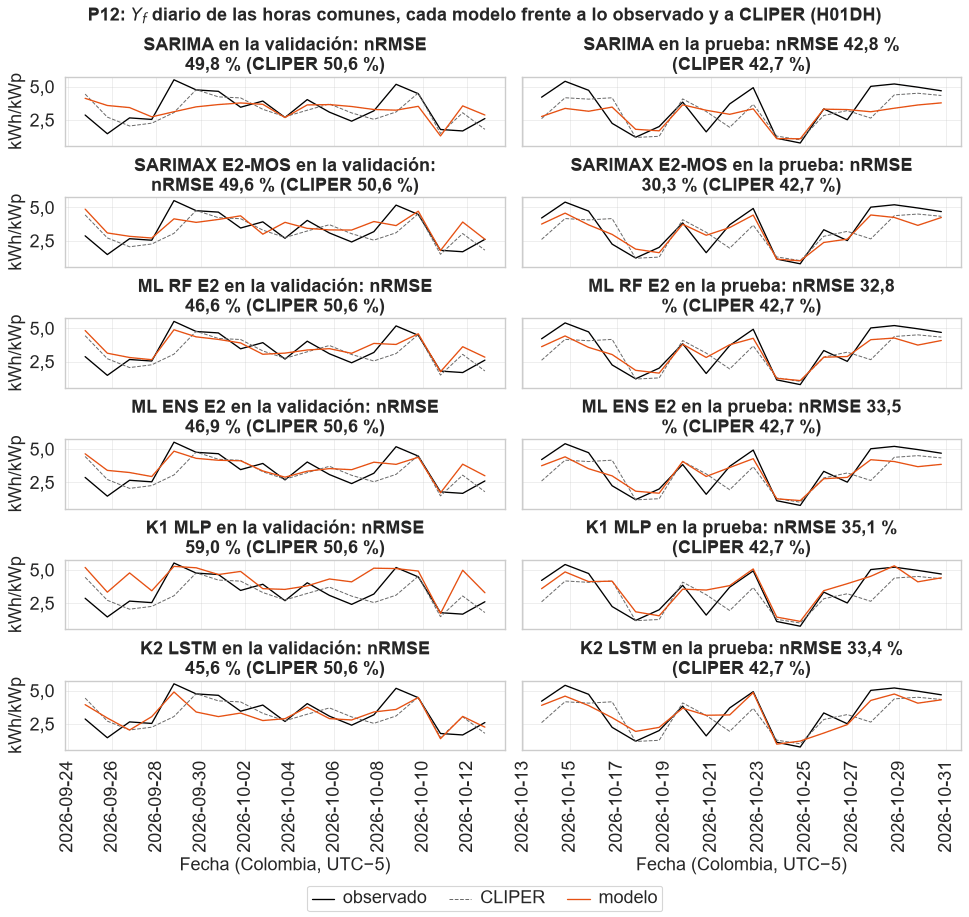

37 filas x 16 columnas; primeras 10:


validación                                                                          prueba                                                                    
            observado ref: cliper  SARIMA SARIMAX E2-MOS ML RF E2 ML ENS E2  K1 MLP K2 LSTM observado ref: cliper SARIMA SARIMAX E2-MOS ML RF E2 ML ENS E2 K1 MLP K2 LSTM
2026-09-25     2.8715      4.4416  4.1237         4.8755   4.8286    4.6431  5.1821  3.9502       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-09-26     1.4649      2.7134  3.5854         3.0859   3.1264    3.3994  3.3262  2.9450       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-09-27     2.6540      2.0476  3.4280         2.8324   2.8037    3.2388  4.7712  2.0438       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-09-28     2.5398      2.2581  2.7344         2.7047   2.6391    2.9361  3.4290  3.0503       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-09-29     5.5148      3.0550  3.1161         4.1438   4.8871    4.8405  5.2615  4.9015       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-09-30     4.7567      4.7760  3.4846         3.8802   4.3544    4.3036  5.1550  3.3973       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-10-01     4.6501      4.2323  3.6551         4.0995   4.1626    4.1579  4.6488  3.0532       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-10-02     3.4554      4.1556  3.7750         4.3720   3.8963    4.1213  4.8827  3.3187       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-10-03     3.9192      3.2984  3.6753         2.9941   3.0474    3.3576  3.5887  2.7561       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN
2026-10-04     2.6866      2.7423  2.6848         3.8818   3.1347    2.8888  3.5341  2.8953       NaN         NaN    NaN            NaN      NaN       NaN    NaN     NaN

AVISO: quedan 0.7 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


In [60]:
# Sección 12.3. Series de pronóstico frente a lo observado
if MODELABLE:
    # Intervalo de predicción empírico del 80 % del SARIMAX E2-MOS: percentiles 10 y 90 del error del día siguiente en la
    # validación, por hora local (las horas sin error medido, de noche, quedan en 0)
    hora_de = lambda idx: np.asarray((pd.DatetimeIndex(idx) - pd.Timedelta("30min")).tz_convert(config.ZONA).hour)
    res_v = (y0 - PRED_X["SARIMAX E2-MOS"]).reindex(idx_c).dropna()
    Q_H2 = res_v.groupby(hora_de(res_v.index)).quantile([0.1, 0.9]).unstack()
    px = FINAL["SARIMAX E2-MOS"]
    h_px = hora_de(px.index)
    LO_H2 = (px + Q_H2[0.1].reindex(h_px).fillna(0).to_numpy()).clip(lower=0)
    HI_H2 = (px + Q_H2[0.9].reindex(h_px).fillna(0).to_numpy()).clip(lower=0)
    y_p = y0.reindex(idx_p)
    COBERTURA_H2 = float(((y_p >= LO_H2.reindex(idx_p)) & (y_p <= HI_H2.reindex(idx_p)))[y_p.notna()].mean())
    ANCHO_H2 = float((HI_H2 - LO_H2).reindex(idx_p)[y_p.notna()].mean())
    # Recalibracón móvil, como se haría en la operación: para cada día de la prueba, los percentiles 10 y 90 del error
    # de los 30 días anteriores con error medido (la validación y los días de la prueba ya observados), por hora local
    DIAS_RECAL = 30
    err_todo = pd.concat([res_v, (y0 - px).reindex(idx_p).dropna()]).sort_index()
    dias_err = np.asarray(part.dias_locales(err_todo.index))
    LO_M, HI_M = pd.Series(np.nan, index=px.index), pd.Series(np.nan, index=px.index)
    dias_px = np.asarray(part.dias_locales(px.index))
    for D in sorted(set(np.asarray(part.dias_locales(idx_p)))):
        previos = np.unique(dias_err[dias_err < D])[-DIAS_RECAL:]
        ventana_e = err_todo[np.isin(dias_err, previos)]
        q_m = ventana_e.groupby(hora_de(ventana_e.index)).quantile([0.1, 0.9]).unstack()
        sel_d = px.index[dias_px == D]
        h_d = hora_de(sel_d)
        LO_M.loc[sel_d] = (px.loc[sel_d] + q_m[0.1].reindex(h_d).fillna(0).to_numpy()).clip(lower=0).to_numpy()
        HI_M.loc[sel_d] = (px.loc[sel_d] + q_m[0.9].reindex(h_d).fillna(0).to_numpy()).clip(lower=0).to_numpy()
    COBERTURA_H2_MOVIL = float(((y_p >= LO_M.reindex(idx_p)) & (y_p <= HI_M.reindex(idx_p)))[y_p.notna()].mean())
    ANCHO_H2_MOVIL = float((HI_M - LO_M).reindex(idx_p)[y_p.notna()].mean())
    # Un día representativo de cada tipo: el de k* diario más cercano a la mediana de su tipo
    EJEMPLOS = {}
    for tipo_ in ("despejado", "intermedio", "nublado"):
        g_ = DIAS_TIPO[DIAS_TIPO["tipo"] == tipo_]
        if len(g_):
            EJEMPLOS[tipo_] = (g_["k_dia"] - g_["k_dia"].median()).abs().idxmin()
    if EJEMPLOS:
        f, ax = plt.subplots(1, len(EJEMPLOS), figsize=(4.2 * len(EJEMPLOS), 3.8), sharey=True, squeeze=False)
        datos_ej = {}
        for a, (tipo_, dia_) in zip(ax[0], EJEMPLOS.items()):
            sel = y0.index[part.dias_locales(y0.index) == dia_]
            x_ = (sel - pd.Timedelta("30min")).tz_convert(config.ZONA)
            x_ = x_.hour + x_.minute / 60          # mitad de la hora: la de las 10:00 resume de 9:00 a 10:00
            a.fill_between(x_, LO_H2.reindex(sel).to_numpy(), HI_H2.reindex(sel).to_numpy(), color=config.COLOR_PRINCIPAL, alpha=0.2,
                           lw=0, label="intervalo de predicción del 80 %")
            a.plot(x_, px.reindex(sel).to_numpy(), color=config.COLOR_PRINCIPAL, lw=1.6, ls="-", label="SARIMAX E2-MOS")
            a.plot(x_, FINAL["ref: cliper"].reindex(sel).to_numpy(), color=config.COLOR_NEUTRO, lw=1.1, ls="--", label="CLIPER")
            a.plot(x_, y0.reindex(sel).to_numpy(), color="black", lw=1.4, ls="-", marker="o", ms=3, label="observado")
            a.set_xlim(5, 19); a.set_xlabel("Hora local")
            a.set_title(f"{tipo_.capitalize()}: {dia_:%Y-%m-%d} (k* = {DIAS_TIPO.loc[dia_, 'k_dia']:.2f})", fontsize=10)
            datos_ej[tipo_] = pd.DataFrame({"observado": y0.reindex(sel), "sarimax_e2_mos": px.reindex(sel), "ip80_inf": LO_H2.reindex(sel),
                                            "ip80_sup": HI_H2.reindex(sel), "cliper": FINAL["ref: cliper"].reindex(sel)})
        ax[0, 0].set_ylabel("Yf horario (kWh/kWp)")
        manejadores, rotulos = ax[0, 0].get_legend_handles_labels()
        f.legend(manejadores, rotulos, loc="outside lower center", ncol=4, fontsize=10)
        f.suptitle(f"{n0}: pronóstico del día siguiente en tres días de la prueba (H01DH)", fontweight="bold")
        fig(f, f"prueba_dias_ejemplo_{n0}", pd.concat(datos_ej))
    display(Markdown(
        f"**Intervalo de predicción del 80 %.** Calibrado con {len(res_v)} horas de la validación, cubre el "
        f"{100 * COBERTURA_H2:.1f} % de las {int(y_p.notna().sum())} horas observadas de la prueba (ancho medio "
        f"{ANCHO_H2:.3f} kWh/kWp): " +
        ("está bien calibrado. " if 0.75 <= COBERTURA_H2 <= 0.85 else
         "queda corto (la prueba fue más variable que la validación). " if COBERTURA_H2 < 0.75 else
         "es conservador (la prueba fue menos variable que la validación). ")
        + f"Recalibrado cada día con los errores de los {DIAS_RECAL} días anteriores, como se haría en la operación, cubre el "
        f"{100 * COBERTURA_H2_MOVIL:.1f} % (ancho medio {ANCHO_H2_MOVIL:.3f} kWh/kWp)."))
    res.registrar(f"localidades.{GRUPO}.modelos.intervalo_h2_{n0}", {
        "nominal_pct": 80, "cobertura_prueba_pct": round(100 * COBERTURA_H2, 2), "ancho_medio_kwh_kwp": round(ANCHO_H2, 4),
        "cobertura_prueba_movil_pct": round(100 * COBERTURA_H2_MOVIL, 2), "ancho_medio_movil_kwh_kwp": round(ANCHO_H2_MOVIL, 4),
        "dias_recalibracion": DIAS_RECAL, "horas_validacion": int(len(res_v)),
        "horas_prueba": int(y_p.notna().sum()), "dias_ejemplo": {k: str(v.date()) for k, v in EJEMPLOS.items()}})

    # Serie diaria de cada modelo en la validación y en la prueba, sobre las horas comunes con el objetivo observado
    def diario_comun(serie, idx):
        return serie.reindex(idx).groupby(part.dias_locales(idx)).sum(min_count=1)
    MODELOS_SERIE = [k for k in sorted(set(CANDIDATOS_VAL) | set(FINAL), key=lambda k: SIMPLICIDAD.get(k, 99)) if not k.startswith("ref")]
    f, ax = plt.subplots(len(MODELOS_SERIE), 2, figsize=(12, 1.75 * len(MODELOS_SERIE) + 0.9), sharey=True, sharex="col", squeeze=False)
    datos_m = {}
    for col, (nombre_p, preds, idx_, tabla) in enumerate((("validación", CANDIDATOS_VAL, idx_c, TABLA_K), ("prueba", FINAL, idx_p, TABLA_L))):
        obs_ = diario_comun(y0, idx_)
        cl_ = diario_comun(preds["ref: cliper"], idx_)
        datos_m[(nombre_p, "observado")], datos_m[(nombre_p, "ref: cliper")] = obs_, cl_
        nr_ = tabla.set_index("modelo")["nrmse_pct"]
        for fila, k in enumerate(MODELOS_SERIE):
            a = ax[fila, col]
            a.plot(obs_.index, obs_.to_numpy(), color="black", lw=1.2, ls="-", label="observado")
            a.plot(cl_.index, cl_.to_numpy(), color=config.COLOR_NEUTRO, lw=0.9, ls="--", label="CLIPER")
            if k in preds:
                pk = diario_comun(preds[k], idx_)
                datos_m[(nombre_p, k)] = pk
                a.plot(pk.index, pk.to_numpy(), color=config.COLOR_PRINCIPAL, lw=1.2, ls="-", label="modelo")
                a.set_title(f"{k} en la {nombre_p}: nRMSE {nr_.get(k, np.nan):.1f} % (CLIPER {nr_.get('ref: cliper', np.nan):.1f} %)", fontsize=9)
            else:
                a.set_title(f"{k} en la {nombre_p}: no se evaluó", fontsize=9)
            if col == 0:
                a.set_ylabel("kWh/kWp", fontsize=8)
    manejadores, rotulos = ax[0, 0].get_legend_handles_labels()
    f.suptitle(f"{n0}: Yf diario de las horas comunes, cada modelo frente a lo observado y a CLIPER (H01DH)", fontweight="bold")
    f.legend(manejadores, rotulos, loc="outside lower center", ncol=3, fontsize=10)
    fig(f, f"series_modelos_{n0}", pd.DataFrame(datos_m))

### 12.4. ¿Fue la prueba más despejada que el entrenamiento?

Si la prueba hubiera tenido muchos más días despejados que el entrenamiento (por ejemplo, por la fase del ENSO),
favorecería a las referencias y la mejora medida sería conservadora, y si no, esa afirmación no se sostiene. Para
comprobarlo clasificamos cada día completo del régimen estable por su k* diario (nublado si es menor que 0,40,
intermedio de 0,40 a 0,65 y despejado desde 0,65) y comparamos la proporción de cada tipo entre particiones y entre fases
del ONI del mes (El Niño desde +0,5, La Niña hasta −0,5 y neutro entre ambos) con la prueba de independencia chi
cuadrado.

In [61]:
# Sección 12.4. ¿Fue la prueba más despejada que el entrenamiento?
if MODELABLE:
    from scipy.stats import chi2_contingency
    kd = OBJ_D[n0].loc[OBJ_D[n0]["en_regimen"], "kstar"].dropna()
    tipo_d = pd.cut(kd, [-np.inf, 0.4, 0.65, np.inf], labels=["nublado", "intermedio", "despejado"])
    particion_d = part.etiquetar(kd.index).to_numpy()
    TIPOS_PART = pd.crosstab(particion_d, tipo_d.to_numpy()).reindex(["entrenamiento", "validacion", "prueba", "vivo"]).dropna(how="all")
    try:
        oni_ = datos.oni()
        oni_m = pd.Series(oni_["oni"].to_numpy(), index=pd.PeriodIndex([f"{a}-{m:02d}" for a, m in zip(oni_["anio"], oni_["mes"])], freq="M"))
        fase_d = pd.Series(pd.DatetimeIndex(kd.index).tz_localize(None).to_period("M"), index=kd.index).map(oni_m)
        fase_d = pd.cut(fase_d, [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "neutro", "El Niño"])
        TIPOS_FASE = pd.crosstab(fase_d.to_numpy(), tipo_d.to_numpy())
    except Exception:  # noqa: BLE001 (sin el índice ONI cargado)
        TIPOS_FASE = pd.DataFrame()
    def chi2_(t):
        t = t.loc[t.sum(axis=1) > 0, t.sum(axis=0) > 0]
        return chi2_contingency(t.to_numpy())[1] if t.shape[0] > 1 and t.shape[1] > 1 else np.nan
    p_part, p_fase = chi2_(TIPOS_PART), (chi2_(TIPOS_FASE) if not TIPOS_FASE.empty else np.nan)
    display(Markdown("**Días por tipo y partición** (proporción entre paréntesis)"))
    display(TIPOS_PART.astype(int).astype(str) + " (" + (100 * TIPOS_PART.div(TIPOS_PART.sum(axis=1), axis=0)).round(0).astype(int).astype(str) + " %)")
    if not TIPOS_FASE.empty:
        display(Markdown("**Días por tipo y fase del ONI del mes**")); display(TIPOS_FASE)
    desp = 100 * TIPOS_PART.get("despejado", pd.Series(dtype=float)) / TIPOS_PART.sum(axis=1)
    display(Markdown(
        f"**Resultado.** Días despejados: {desp.get('entrenamiento', np.nan):.0f} % en el entrenamiento, {desp.get('validacion', np.nan):.0f} % en la "
        f"validación y {desp.get('prueba', np.nan):.0f} % en la prueba (chi cuadrado entre particiones, p = {p_part:.3g}"
        + (f"; entre fases del ONI, p = {p_fase:.3g}" if np.isfinite(p_fase) else "") + "). "
        + ("La prueba tuvo una proporción de días despejados significativamente distinta de la del entrenamiento: la comparación con las "
           "referencias depende del tipo de día y se lee junto con el desglose de la sección 12.2." if np.isfinite(p_part) and p_part < 0.05 else
           "Las proporciones no difieren de forma significativa: no hay evidencia de que la prueba fuera más despejada que el "
           "entrenamiento, y la mejora medida no puede calificarse de conservadora por esa razón. ")
        + (("Entre fases del ONI la proporción sí difiere (p < 0,05): días despejados " + ", ".join(
            f"{v:.0f} % con {k}" if k != "neutro" else f"{v:.0f} % en fase neutra" for k, v in
            (100 * TIPOS_FASE.get("despejado", pd.Series(dtype=float)) / TIPOS_FASE.sum(axis=1)).dropna().items()) + ".")
           if np.isfinite(p_fase) and p_fase < 0.05 else "No difiere tampoco entre fases del ONI." if np.isfinite(p_fase) else "")))
    res.registrar(f"localidades.{GRUPO}.modelos.tipos_dia_{n0}", {"por_particion": TIPOS_PART.astype(int).to_dict(orient="index"),
                  "por_fase_oni": TIPOS_FASE.astype(int).to_dict(orient="index") if not TIPOS_FASE.empty else {},
                  "pct_despejados": desp.round(1).to_dict(), "p_chi2_particion": p_part, "p_chi2_fase_oni": p_fase})

**Días por tipo y partición** (proporción entre paréntesis)

col_0,despejado,intermedio,nublado
row_0,,,
entrenamiento,33 (69 %),14 (29 %),1 (2 %)
validacion,5 (31 %),7 (44 %),4 (25 %)
prueba,9 (56 %),5 (31 %),2 (12 %)


**Días por tipo y fase del ONI del mes**

col_0,despejado,intermedio,nublado
row_0,,,
El Niño,35,15,3


**Resultado.** Días despejados: 69 % en el entrenamiento, 31 % en la validación y 56 % en la prueba (chi cuadrado entre particiones, p = 0,0243). La prueba tuvo una proporción de días despejados significativamente distinta de la del entrenamiento: la comparación con las referencias depende del tipo de día y se lee junto con el desglose de la sección 12.2.

AVISO: quedan 0.8 GB de memoria libre. Cierre otros kernels o programas antes de seguir.


### 12.5. Suficiencia de datos: ¿cuántos días de entrenamiento hacen falta?

Raza et al. (2019) entrenaron con 30, 60 y 90 días y no encontraron mejoras claras con más datos, y Do, Soubdhan y
Robyns (2016) vieron que en clima tropical la curva de aprendizaje es distinta a la del clima templado. Si en el Caribe
colombiano, sin estaciones térmicas y con una estacionalidad dominada por el ciclo de 24 h, bastaran pocas semanas, se
podría pronosticar el rendimiento de una planta nueva con solo un mes de datos.

Para medirlo entrenamos el SARIMAX E2-MOS y el mejor modelo de aprendizaje automático (con sus hiperparámetros ya
elegidos) con ventanas de 7, 14, 30, 60, 90, 180 y 365 días que terminan el último día del entrenamiento, y con todo el
entrenamiento, y evaluamos todas las ventanas en la misma validación.

,ML RF,SARIMAX E2-MOS
dias,,
7,51.07,52.13
14,49.41,50.31
30,49.12,51.78
60,46.81,48.09
90,46.58,49.02
180,46.58,47.61
365,46.58,46.76
todo,46.58,49.55


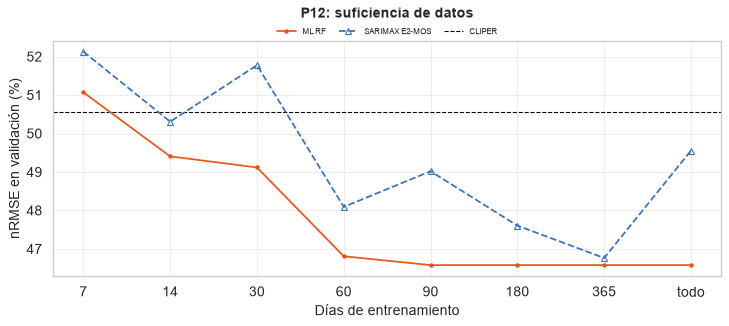

8 filas x 2 columnas; primeras 8:


,ML RF,SARIMAX E2-MOS
dias,,
7,51.0697,52.1271
14,49.4052,50.3077
30,49.1175,51.7763
60,46.8082,48.0915
90,46.5788,49.0187
180,46.5788,47.6055
365,46.5788,46.7630
todo,46.5788,49.5521


**Resultado.** Ventana mínima con la que cada modelo queda a menos de un 5 % del nRMSE con todo el entrenamiento: ML RF: 60 días; SARIMAX E2-MOS: 14 días.

In [62]:
# Sección 12.5. Suficiencia de datos: ¿cuántos días de entrenamiento hacen falta?
if MODELABLE:
    VENTANAS = [7, 14, 30, 60, 90, 180, 365, None] if not RAPIDO else [30, None]
    filas_s = []
    X, y, tr, va, etq = datos_ml(n0, inv0, "E2")
    dias_x = part.dias_locales(X.index)
    fin_tr = dias_x[etq == "entrenamiento"].max()
    from sklearn.base import clone
    for v in VENTANAS:
        en_v = tr & (np.asarray(dias_x >= fin_tr - pd.Timedelta(days=v - 1)) if v else True)
        if en_v.sum() < 24:
            continue
        m_ml = clone(AJ_ML[("E2", mejor_e2)]["mejor"]).fit(X[en_v], y[en_v])
        p_ml = pd.Series(np.clip(m_ml.predict(X[va]), 0, None), index=X.index[va])
        fila = {"dias": v or "todo", f"ML {mejor_e2}": met.evaluar(y[va], p_ml)["nrmse_pct"]}
        serie_v = y0.copy()
        sel_v = (etq_h[n0] == "entrenamiento") & (np.asarray(part.dias_locales(y0.index) >= fin_tr - pd.Timedelta(days=v - 1)) if v else True)
        if serie_v[sel_v].notna().sum() >= 24 * 5:
            try:
                a_v = sarima.ajustar(serie_v[sel_v], orden_x, est_x, exog=XE["E2"][sel_v])
                p_v = postproceso(sarima.pronostico_por_origen(a_v, y0, origen(dias_val), 24, XE["E2"]), OBJ_H[n0])
                fila["SARIMAX E2-MOS"] = met.evaluar(y0.reindex(p_v.index), p_v, observado(OBJ_H[n0]).reindex(p_v.index))["nrmse_pct"]
            except Exception as e:
                fila["SARIMAX E2-MOS"] = np.nan
        filas_s.append(fila)
    SUFICIENCIA = pd.DataFrame(filas_s).set_index("dias")
    display(SUFICIENCIA.round(2))
    f = gr.lineas(SUFICIENCIA.rename(index=str), f"{n0}: suficiencia de datos", "Días de entrenamiento", "nRMSE en validación (%)")
    f.axes[0].axhline(TABLA_I.set_index("modelo").loc["ref: cliper", "nrmse_pct"], color="black", ls="--", lw=1, label="CLIPER")
    f.axes[0].legend(fontsize=7)
    fig(f, f"suficiencia_datos_{n0}", SUFICIENCIA)
    # Referencia: el error con todo el entrenamiento (la asíntota), no el menor de la tabla, que cae por azar en alguna ventana
    mejor_total = SUFICIENCIA.loc["todo"] if "todo" in SUFICIENCIA.index else SUFICIENCIA.min()
    umbral = {c: next((d for d, v in SUFICIENCIA[c].items() if pd.notna(v) and v <= 1.05 * mejor_total[c]), None) for c in SUFICIENCIA.columns}
    display(Markdown("**Resultado.** Ventana mínima con la que cada modelo queda a menos de un 5 % del nRMSE con todo el entrenamiento: " +
                     "; ".join(f"{c}: " + ("todo el entrenamiento" if d == "todo" else f"{d} días") for c, d in umbral.items()) + "."))
    res.registrar(f"localidades.{GRUPO}.modelos.suficiencia_{n0}", {"nrmse_pct": SUFICIENCIA.round(3).to_dict(), "ventana_minima_5pct": umbral})

Con una sola ventana de evaluación, la ventana mínima de cada unidad depende del tiempo meteorológico de esas semanas, y
por eso cambia de una unidad a otra. Para la regla de la flota repetimos el experimento del SARIMAX E2-MOS desde cuatro
orígenes del régimen vigente, que son el último día del entrenamiento y 21, 42 y 63 días antes. En cada origen ajustamos
con los $d$ días anteriores ($d$ = 3, 7, 14, 21, 30 y 60) y con toda la historia del régimen hasta el origen, y
pronosticamos el día siguiente durante los 14 días posteriores, sin que intervenga la prueba.

En cada origen dividimos el error con $d$ días por el error con toda la historia en esas mismas horas. Así se cancela la
dificultad de cada ventana de evaluación (unas semanas son más nubladas que otras) y los orígenes se pueden juntar con
la mediana. Una ventana de $d$ días solo cuenta si cabe entera en el régimen vigente y tiene observadas al menos la mitad
de sus horas de sol, y un ajuste explosivo o fallido cuenta como un modelo que no sirve (error relativo infinito),
porque una planta nueva tampoco tendría otro. Descartamos tomar como asíntota el menor error de la tabla, porque ese
mínimo cae por azar en algún $d$ y, con orígenes que faltan en unas filas y no en otras, compara ventanas de evaluación
distintas. El cuaderno de comparación junta las curvas de toda la flota, y de ahí sale $d^*$, los días de datos que
necesita una planta nueva, una ampliación o una planta que deja de limitar la inyección.

In [63]:
# Sección 12.5. Suficiencia de datos: ¿cuántos días de entrenamiento hacen falta?
if MODELABLE:
    K_DIAS = [3, 7, 14, 21, 30, 60] if not RAPIDO else [7, 30]
    DESPLAZAMIENTOS = [0, 21, 42, 63] if not RAPIDO else [0]
    FALLAS_SUF = ("ajuste explosivo", "ajuste fallido")
    dias_y0 = part.dias_locales(y0.index)
    obs_y0 = observado(OBJ_H[n0]).reindex(y0.index).fillna(False).to_numpy()
    sol_y0 = (OBJ_H[n0]["yr_cs"].reindex(y0.index) > 0.05).to_numpy()
    validos_tr = (etq_h[n0] == "entrenamiento") & y0.notna().to_numpy()
    filas_o = []
    if validos_tr.sum() >= 24 * 30:
        fin_tr0 = dias_y0[validos_tr].max()
        ini_tr0 = dias_y0[validos_tr].min()                                     # primer día del régimen vigente con datos
        for desp in DESPLAZAMIENTOS:
            o = fin_tr0 - pd.Timedelta(days=desp) + pd.Timedelta(days=1)        # primer día evaluado
            dias_ev = pd.date_range(o, o + pd.Timedelta(days=13), freq="D")
            if (np.asarray(dias_y0.isin(dias_ev)) & obs_y0).sum() < 24:
                continue                                                         # origen sin horas evaluables: no cuenta
            for k in K_DIAS + ["todo"]:
                desde = ini_tr0 if k == "todo" else o - pd.Timedelta(days=k)
                fila = {"desplazamiento_dias": desp, "k_dias": str(k), "origen": f"{o:%Y-%m-%d}", "dias_ajuste": int((o - desde).days)}
                sel = np.asarray((dias_y0 >= desde) & (dias_y0 < o))
                if k != "todo" and desde < ini_tr0:
                    filas_o.append({**fila, "motivo": "fuera del régimen"})
                    continue
                if (sel & obs_y0).sum() < max(12, 0.5 * (sel & sol_y0).sum()):
                    filas_o.append({**fila, "motivo": "datos incompletos"})
                    continue
                try:
                    a_k = sarima.ajustar(y0[sel], orden_x, est_x, exog=XE["E2"][sel])
                    if not sarima.estable(a_k):
                        filas_o.append({**fila, "motivo": "ajuste explosivo"})
                        continue
                    p_k = postproceso(sarima.pronostico_por_origen(a_k, y0, origen(dias_ev), 24, XE["E2"]), OBJ_H[n0])
                    m_k = met.evaluar(y0.reindex(p_k.index), p_k, observado(OBJ_H[n0]).reindex(p_k.index).fillna(False))
                    filas_o.append({**fila, "nrmse_pct": m_k["nrmse_pct"], "horas": m_k["n"], "motivo": None})
                except Exception:
                    filas_o.append({**fila, "motivo": "ajuste fallido"})
    SUF_ORIGENES = pd.DataFrame(filas_o)
    if len(SUF_ORIGENES) and "nrmse_pct" in SUF_ORIGENES and SUF_ORIGENES.loc[SUF_ORIGENES["k_dias"] == "todo", "nrmse_pct"].notna().any():
        ORDEN_K = [str(k) for k in K_DIAS] + ["todo"]
        t_o = SUF_ORIGENES.set_index(["k_dias", "desplazamiento_dias"])
        E_O = t_o["nrmse_pct"].unstack().reindex(ORDEN_K)
        MOT_O = t_o["motivo"].unstack().reindex(ORDEN_K)
        ref_o = E_O.loc["todo"]
        REL_O = E_O.drop(index="todo") / ref_o
        REL_O = REL_O.mask(MOT_O.drop(index="todo").isin(FALLAS_SUF) & ref_o.notna(), np.inf)   # la serie se alinea con las columnas
        REL_MED = REL_O.median(axis=1, skipna=True)
        ok_k = REL_MED.dropna() <= 1.05
        D_MIN = next((int(k) for i, k in enumerate(ok_k.index) if ok_k.iloc[i:].all()), None)
        display(Markdown(f"**{n0}: nRMSE (%) del SARIMAX E2-MOS por días de entrenamiento (filas) y origen (columnas: días antes del fin del "
                         "entrenamiento; las celdas vacías tienen su motivo en la tabla siguiente)**"))
        display(E_O.round(2))
        if MOT_O.notna().any().any():
            display(MOT_O.fillna(""))
        display(Markdown("**Error relativo al de toda la historia del régimen, por origen, y su mediana** (inf: el ajuste no sirve)"))
        display(REL_O.assign(mediana=REL_MED).round(3))
        n_fallas = int(SUF_ORIGENES["motivo"].isin(FALLAS_SUF).sum())
        n_intentos = int((~SUF_ORIGENES["motivo"].isin(["fuera del régimen", "datos incompletos"])).sum())
        n_or = int(ref_o.notna().sum())
        display(Markdown(
            "**Resultado.** " + (f"En la mediana de {n_or} orígenes, " if n_or > 1 else "Con un solo origen, ")
            + (f"desde {D_MIN} días el SARIMAX E2-MOS queda a menos de un 5 % del error con toda la historia del régimen, y así sigue con más días. "
               if D_MIN is not None else "ninguna ventana corta queda de forma estable a menos de un 5 % del error con toda la historia del régimen. ")
            + (f"Con toda la historia, el nRMSE mediano de los orígenes es {ref_o.median():.1f} %. " if n_or > 1 else
               f"Con toda la historia, el nRMSE es {ref_o.median():.1f} %. ")
            + f"De {n_intentos} ajustes, {n_fallas} no sirven (explosivos o fallidos)."))
        res.registrar(f"localidades.{GRUPO}.modelos.suficiencia_origenes_{n0}",
                      {"nrmse_pct": {k: {str(c): (None if pd.isna(v) else round(float(v), 3)) for c, v in fila.items()} for k, fila in E_O.iterrows()},
                       "motivos": {k: {str(c): v for c, v in fila.items() if isinstance(v, str)} for k, fila in MOT_O.iterrows()},
                       "relativo_mediana": {k: (None if not np.isfinite(v) else round(float(v), 4)) for k, v in REL_MED.items()},
                       "relativo_infinito": [k for k, v in REL_MED.items() if np.isinf(v)],
                       "origenes": SUF_ORIGENES.drop_duplicates("desplazamiento_dias").set_index("desplazamiento_dias")["origen"].to_dict(),
                       "d_minimo_5pct": D_MIN, "nrmse_todo_mediano_pct": round(float(ref_o.median()), 3),
                       "ajustes": n_intentos, "ajustes_que_no_sirven": n_fallas})
    else:
        display(Markdown(f"**{n0}**: el régimen vigente no tiene 30 días de entrenamiento con horas evaluables; la suficiencia desde varios "
                         "orígenes no se calcula."))

L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1968: RuntimeWarning: invalid value encountered in reciprocal
  return np.roots(self.polynomial_reduced_ar)**-1


**P12: nRMSE (%) del SARIMAX E2-MOS por días de entrenamiento (filas) y origen (columnas: días antes del fin del entrenamiento; las celdas vacías tienen su motivo en la tabla siguiente)**

desplazamiento_dias,0,21,42,63
k_dias,,,,
3,94.69,NaN,27.40,NaN
7,53.09,27.10,25.78,NaN
14,51.70,72.65,31.07,NaN
21,52.58,24.58,NaN,NaN
30,52.90,25.70,NaN,NaN
60,49.10,NaN,NaN,NaN
todo,48.90,23.38,33.81,NaN


desplazamiento_dias,0,21,42,63
k_dias,,,,
3,,ajuste explosivo,,fuera del régimen
7,,,,fuera del régimen
14,,,,fuera del régimen
21,,,fuera del régimen,fuera del régimen
30,,,fuera del régimen,fuera del régimen
60,,fuera del régimen,fuera del régimen,fuera del régimen
todo,,,,datos incompletos


**Error relativo al de toda la historia del régimen, por origen, y su mediana** (inf: el ajuste no sirve)

desplazamiento_dias,0,21,42,63,mediana
k_dias,,,,,
3,1.936,inf,0.810,NaN,1.936
7,1.086,1.159,0.763,NaN,1.086
14,1.057,3.107,0.919,NaN,1.057
21,1.075,1.051,NaN,NaN,1.063
30,1.082,1.099,NaN,NaN,1.090
60,1.004,NaN,NaN,NaN,1.004


**Resultado.** En la mediana de 3 orígenes, desde 60 días el SARIMAX E2-MOS queda a menos de un 5 % del error con toda la historia del régimen, y así sigue con más días. Con toda la historia, el nRMSE mediano de los orígenes es 33,8 %. De 17 ajustes, 1 no sirven (explosivos o fallidos).

### 12.6. Periodo en vivo (desde el corte del modelado)

Los modelos finales (entrenados con todo lo anterior al corte del modelado, `config.FIN_MODELADO`) se aplican a los
días posteriores al corte con el pronóstico meteorológico real de cada día anterior (escenario E3) y se comparan con
lo medido. Es la prueba más cercana a la operación: ni los modelos ni los pronósticos conocían esos días. El
resultado crece a medida que llegan datos; el resultado definitivo lo calcula el cuaderno `07_vivo.ipynb`, con los
modelos ajustados en el corte y sin reentrenar.

In [64]:
# Sección 12.6. Periodo en vivo (desde el corte del modelado)
if MODELABLE:
    dias_vivo = [d for d in pd.date_range(config.PARTICIONES["vivo"][0], FIN, freq="D") if d < pd.Timestamp(FIN)]
    hasta_pru = np.isin(etq_h[n0], ["entrenamiento", "validacion", "prueba"])
    # El régimen vigente se decide con los datos anteriores al corte y su máscara termina en el último mes antes de el;
    # después del corte continua (las horas recortadas, en falla o sin producción ya tienen el objetivo nulo). Solo aquí:
    # las estadisticas de los objetivos describen los datos del modelado
    oh_vivo = OBJ_H[n0].copy()
    oh_vivo.loc[oh_vivo.index > CORTE_MODELADO, "en_regimen"] = True
    y_vivo = oh_vivo["yf"].where(oh_vivo["en_regimen"]).asfreq("1h")
    try:
        a_xv = sarima.ajustar(y0[hasta_pru], orden_x, est_x, exog=XE["E2"][hasta_pru])
        p_vivo = postproceso(sarima.pronostico_por_origen(a_xv, y_vivo, origen(dias_vivo), 24, XE["E2"]), oh_vivo)
        ref_v = refs.horarias_h2(oh_vivo, hasta_pru)["cliper"]
        obs_vivo = observado(oh_vivo).reindex(p_vivo.index).fillna(False)
        TABLA_VIVO = pd.DataFrame([{"modelo": "SARIMAX E2-MOS", **met.evaluar(y_vivo.reindex(p_vivo.index), p_vivo, obs_vivo)},
                                   {"modelo": "ref: cliper", **met.evaluar(y_vivo.reindex(p_vivo.index), ref_v.reindex(p_vivo.index), obs_vivo)}])
        display(TABLA_VIVO.round(4))
        res.registrar(f"localidades.{GRUPO}.modelos.vivo_{n0}", TABLA_VIVO.set_index("modelo").round(5).to_dict(orient="index"))
    except Exception as e:
        display(Markdown(f"Periodo en vivo sin datos suficientes todavía ({type(e).__name__}: {e})."))

,modelo,n,mae,rmse,mbe,nmae_pct,nrmse_pct,r2
0,SARIMAX E2-MOS,49,0.1312,0.1723,0.0083,41.4099,54.3533,0.2518
1,ref: cliper,49,0.1305,0.1683,-0.0187,41.1932,53.1103,0.2856


### 12.7. Conclusiones de la localidad

Las cifras de esta sección se generan con los resultados de las partes anteriores y se guardan en
`resultados.json`, de donde las toma el documento del TFM.

In [65]:
# Sección 12.7. Conclusiones de la localidad
if MODELABLE:
    t = TABLA_L.set_index("modelo")
    ganador = t.drop(index=[k for k in t.index if k.startswith("ref")])["rmse"].idxmin()
    elegido = SELECCION_VAL if SELECCION_VAL in t.index else ganador
    display(Markdown(
        f"* **Modelo elegido con la validación ({n0}, día siguiente horario):** {elegido}; en la prueba, nRMSE de "
        f"{t.loc[elegido, 'nrmse_pct']:.1f} % y *skill* de {100 * t.loc[elegido, 'skill_vs_cliper']:.1f} % frente a CLIPER"
        + (f" (Diebold-Mariano p = {t.loc[elegido, 'p_dm']:.3g})" if pd.notna(t.loc[elegido, 'p_dm']) else "") + ".\n"
        f"* **Menor error en la prueba:** {ganador}, con nRMSE de {t.loc[ganador, 'nrmse_pct']:.1f} % y *skill* de "
        f"{100 * t.loc[ganador, 'skill_vs_cliper']:.1f} % (solo informativo: la prueba no elige).\n"
        f"* **Fuente de irradiancia:** {FUENTE_IRR}; el PR estimado cambia con la fuente entre {resB['pr_ajustado'].min():.2f} y {resB['pr_ajustado'].max():.2f}.\n"
        f"* **Imputación:** {METODO_DIURNO} hasta 1 h, elegida por experimento.\n"
        f"* **Estacionalidad:** la de 24 h explica el {100 * PART_VAR['ciclo_diario']:.1f} % de la varianza de la irradiancia; la anual, "
        f"un {100 * PART_VAR['ciclo_anual_adicional']:.1f} % adicional.\n"
        f"* **Suficiencia de datos:** " + "; ".join(f"{c}: " + ("todo el entrenamiento" if d == "todo" else f"{d} días") for c, d in umbral.items()) + "."))
    registrar_unidad("conclusiones", {"unidad_principal": n0, "modelo_elegido": elegido,
                  "nrmse_pct": t.loc[elegido, "nrmse_pct"], "skill_vs_cliper": t.loc[elegido, "skill_vs_cliper"],
                  "mejor_modelo_prueba": ganador, "nrmse_pct_mejor_prueba": t.loc[ganador, "nrmse_pct"],
                  "skill_mejor_prueba": t.loc[ganador, "skill_vs_cliper"],
                  "fuente_irradiancia": FUENTE_IRR, "imputacion": METODO_DIURNO})

* **Modelo elegido con la validación (P12, día siguiente horario):** ref: cliper; en la prueba, nRMSE de 42,7 % y *skill* de 0,0 % frente a CLIPER.
* **Menor error en la prueba:** SARIMAX E2-MOS, con nRMSE de 30,3 % y *skill* de 29,1 % (solo informativo: la prueba no elige).
* **Fuente de irradiancia:** ifs_analisis; el PR estimado cambia con la fuente entre 0,69 y 0,78.
* **Imputación:** lineal hasta 1 h, elegida por experimento.
* **Estacionalidad:** la de 24 h explica el 95,1 % de la varianza de la irradiancia; la anual, un 1,3 % adicional.
* **Suficiencia de datos:** ML RF: 60 días; SARIMAX E2-MOS: 14 días.

### 12.8. Modelo y fuente finales, y costo de cómputo

El objetivo del trabajo pide recomendar **un** modelo y **una** fuente meteorológica para pronosticar el
rendimiento. El modelo es el que eligió la regla de la sección 12.1 con la validación (el más simple del conjunto
de modelos que no se distinguen del mejor, con CLIPER como candidata). La prueba **confirma**: se informa si el
modelo elegido sigue en el conjunto de los equivalentes al mejor en la prueba y cuánto mejora a CLIPER, pero la
prueba no cambia la elección. A igual precisión, el modelo simple es más fácil de explicar, de mantener y de
reentrenar, y necesita menos datos.

La tabla añade el **costo de cómputo** medido en este equipo (ajuste final, búsqueda de hiperparámetros y
predicción de los días de la prueba), la ventana mínima de datos de la sección 12.5 y el tipo de
interpretación que permite cada modelo. La búsqueda del SARIMAX es la del orden del SARIMA, que hereda; la del
ensamble, la de todos los modelos de E2 entre los que se eligen sus tres componentes; las redes usan una
arquitectura fija y no tienen búsqueda. La **fuente del pronóstico** se elige comparando el SARIMAX E2-MOS con
el pronóstico IFS 0,25° y con el GFS (sección 9.1).

**Costo de cómputo por modelo y etapa** (segundos en este equipo)

etapa,ajuste,ajuste_final,busqueda_hiperparametros,prediccion_origenes,prediccion_prueba,prediccion_validacion,reentrenamiento cada 30 dias,reentrenamiento cada 7 dias
modelo,,,,,,,,
AR,4.01,NaN,1.71,NaN,NaN,0.26,NaN,NaN
ARIMA,0.51,NaN,2.33,NaN,NaN,0.25,NaN,NaN
ARMA,4.55,NaN,4.01,NaN,NaN,0.33,NaN,NaN
H3 SARIMAX diario,NaN,NaN,NaN,NaN,NaN,NaN,0.07,0.21
H4 30 dias (modelo 1-7 d),NaN,NaN,NaN,0.19,NaN,NaN,NaN,NaN
K1 MLP,6.70,8.29,NaN,NaN,NaN,NaN,NaN,NaN
K2 LSTM,8.19,8.74,NaN,NaN,NaN,NaN,NaN,NaN
MA,3.98,NaN,2.24,NaN,NaN,0.30,NaN,NaN
ML DT E0,NaN,NaN,0.30,NaN,NaN,NaN,NaN,NaN


,nrmse_pct,skill_vs_cliper,p_dm_vs_cliper,p_dm_vs_mejor,seg_ajuste_final,seg_busqueda,seg_prediccion_prueba,complejidad,interpretacion,empata_con_el_mejor,p_mcs_validacion,en_mcs_prueba,p_mcs_prueba
modelo,,,,,,,,,,,,,
SARIMAX E2-MOS,30.2657,0.2914,0.0000,NaN,118.983,311.327,1.770,2,ecuación explícita con β de la irradiancia,True,NaN,True,NaN
ML RF E2,32.8223,0.2315,0.0007,0.0002,0.704,8.805,0.023,6,importancia de variables,True,NaN,True,NaN
K2 LSTM,33.4148,0.2176,0.0000,0.3011,8.739,NaN,NaN,11,caja negra,True,NaN,True,NaN
ML ENS E2,33.4917,0.2158,0.0036,0.0000,1.057,16.995,0.034,9,caja negra,True,NaN,True,NaN
K1 MLP,35.1123,0.1779,0.0016,0.0188,8.289,NaN,NaN,10,caja negra,True,NaN,True,NaN
ref: cliper,42.7098,0.0000,NaN,NaN,NaN,NaN,NaN,0,referencia sin modelo,True,NaN,True,NaN
SARIMA,42.8351,-0.0029,0.9737,0.0014,72.744,311.327,1.693,1,ecuación explícita,True,NaN,True,NaN


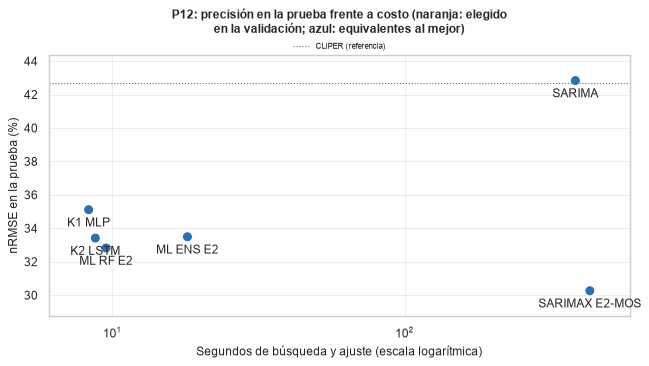

7 filas x 4 columnas; primeras 7:


,nrmse_pct,seg_ajuste_final,seg_busqueda,empata_con_el_mejor
modelo,,,,
SARIMAX E2-MOS,30.2657,118.983,311.327,True
ML RF E2,32.8223,0.704,8.805,True
K2 LSTM,33.4148,8.739,NaN,True
ML ENS E2,33.4917,1.057,16.995,True
K1 MLP,35.1123,8.289,NaN,True
ref: cliper,42.7098,NaN,NaN,True
SARIMA,42.8351,72.744,311.327,True


**Decisión.** Por la regla de la sección 12.1, aplicada con la validación, el modelo recomendado para P12 es **ref: cliper** (interpretación: referencia sin modelo). **Confirmación en la prueba:** nRMSE de 42,7 % y skill de 0,0 % frente a CLIPER; sigue en el conjunto de los equivalentes al mejor de la prueba. Fuente meteorológica del pronóstico: **IFS 0,25°**; fuente observada para el rendimiento medido: **ifs_analisis**.

In [66]:
# Sección 12.8. Modelo y fuente finales, y costo de cómputo
if MODELABLE:
    COSTO = tiempos.costo()
    display(Markdown("**Costo de cómputo por modelo y etapa** (segundos en este equipo)"))
    PIV_COSTO = COSTO.pivot_table(index="modelo", columns="etapa", values="segundos", aggfunc="sum") if len(COSTO) else pd.DataFrame()
    display(PIV_COSTO.round(2))
    INTERPRETA = {"ref: cliper": "referencia sin modelo", "SARIMA": "ecuación explícita", "SARIMAX E2-MOS": "ecuación explícita con β de la irradiancia",
                  "ML DT E2": "reglas legibles", "ML KNN E2": "casos parecidos", "ML SVR E2": "caja negra",
                  "ML RF E2": "importancia de variables", "ML HGB E2": "importancia de variables", "ML LGBM E2": "importancia de variables",
                  "ML ENS E2": "caja negra", "K1 MLP": "caja negra", "K2 LSTM": "caja negra"}
    tl = TABLA_L.set_index("modelo").drop(index=[k for k in TABLA_L["modelo"] if k.startswith("ref") and k != "ref: cliper"])
    # Confirmación en la prueba: conjunto de modelos equivalentes al mejor con las pérdidas diarias de la prueba
    PERD_PRUEBA = met.perdidas_diarias(y0.reindex(idx_p), {k: FINAL[k].reindex(idx_p) for k in tl.index})
    MCS_PRUEBA = met.conjunto_confianza(PERD_PRUEBA)
    # Búsqueda: el SARIMAX hereda el orden del SARIMA (su búsqueda es la del SARIMA); el ensamble necesita la
    # búsqueda de todos los modelos de E2 para elegir sus tres componentes; las redes tienen arquitectura fija.
    BUSQ = PIV_COSTO["busqueda_hiperparametros"] if "busqueda_hiperparametros" in PIV_COSTO else pd.Series(dtype=float)
    BUSQ = BUSQ.copy()
    if "SARIMA" in BUSQ:
        BUSQ["SARIMAX E2-MOS"] = BUSQ["SARIMA"]
    BUSQ["ML ENS E2"] = BUSQ[[k for k in BUSQ.index if k.startswith("ML ") and k.endswith(" E2")]].sum()
    MULTI = pd.DataFrame({
        "nrmse_pct": tl["nrmse_pct"], "skill_vs_cliper": tl["skill_vs_cliper"], "p_dm_vs_cliper": tl["p_dm"],
        "p_dm_vs_mejor": DM_PARES["p_valor"].reindex(tl.index),
        "seg_ajuste_final": PIV_COSTO["ajuste_final"].reindex(tl.index) if "ajuste_final" in PIV_COSTO else np.nan,
        "seg_busqueda": BUSQ.reindex(tl.index),
        "seg_prediccion_prueba": PIV_COSTO["prediccion_prueba"].reindex(tl.index) if "prediccion_prueba" in PIV_COSTO else np.nan,
        "complejidad": [SIMPLICIDAD.get(k, 99) for k in tl.index], "interpretacion": [INTERPRETA.get(k, "") for k in tl.index]})
    # "empata_con_el_mejor" es la pertenencia al conjunto de equivalentes en la VALIDACIÓN (la que decide); la de la
    # prueba solo confirma
    MULTI["empata_con_el_mejor"] = MCS_VAL["incluido"].reindex(MULTI.index).fillna(False).astype(bool)
    MULTI["p_mcs_validacion"] = MCS_VAL["p_mcs"].reindex(MULTI.index)
    MULTI["en_mcs_prueba"] = MCS_PRUEBA["incluido"].reindex(MULTI.index)
    MULTI["p_mcs_prueba"] = MCS_PRUEBA["p_mcs"].reindex(MULTI.index)
    MULTI = MULTI.sort_values("nrmse_pct")
    display(MULTI.round(4))
    gr.guardar_datos(MULTI, f"{PREF}modelo_final_multicriterio_{n0}")
    MODELO_FINAL = SELECCION_VAL if SELECCION_VAL in MULTI.index else MULTI[MULTI["empata_con_el_mejor"]].sort_values("complejidad").index[0]
    fi_ = TABLA_I.set_index("modelo")
    fuente_pron = "IFS 0,25°"
    if "SARIMAX E2-MOS GFS" in fi_.index:
        p_fuente = DM_I["SARIMAX E2-MOS vs SARIMAX E2-MOS GFS"]["p_valor"]
        fuente_pron = ("GFS" if fi_.loc["SARIMAX E2-MOS GFS", "nrmse_pct"] < fi_.loc["SARIMAX E2-MOS", "nrmse_pct"] and p_fuente < 0.05
                       else "IFS 0,25°")
    f, ax = plt.subplots(figsize=(8, 4.5))
    M_ = MULTI.drop(index=[k for k in MULTI.index if k.startswith("ref")])     # la referencia no tiene costo de cómputo
    seg = M_["seg_ajuste_final"].fillna(0) + M_["seg_busqueda"].fillna(0)
    ax.scatter(seg.clip(lower=0.1), M_["nrmse_pct"], s=50,
               c=[config.COLOR_PRINCIPAL if k == MODELO_FINAL else (config.COLOR_SECUNDARIO if e else config.COLOR_NEUTRO)
                  for k, e in M_["empata_con_el_mejor"].items()])
    if "ref: cliper" in MULTI.index:
        ax.axhline(MULTI.loc["ref: cliper", "nrmse_pct"], color=config.COLOR_NEUTRO, ls=":", lw=1, label="CLIPER (referencia)")
        ax.legend(fontsize=8, loc="upper center")
    for k in M_.index:
        ax.annotate(k, (max(seg[k], 0.1), M_.loc[k, "nrmse_pct"]), fontsize=7, xytext=(0, -7), textcoords="offset points",
                    ha="center", va="top")
    ax.margins(x=0.08, y=0.12)                                     # espacio para las etiquetas bajo los puntos extremos
    ax.set_xscale("log"); ax.set_xlabel("Segundos de búsqueda y ajuste (escala logarítmica)"); ax.set_ylabel("nRMSE en la prueba (%)")
    ax.set_title(f"{n0}: precisión en la prueba frente a costo (naranja: elegido en la validación; azul: equivalentes al mejor)")
    fig(f, f"precision_costo_{n0}", MULTI[["nrmse_pct", "seg_ajuste_final", "seg_busqueda", "empata_con_el_mejor"]])
    confirma = bool(MULTI.loc[MODELO_FINAL, "en_mcs_prueba"]) if pd.notna(MULTI.loc[MODELO_FINAL, "en_mcs_prueba"]) else None
    display(Markdown(
        f"**Decisión.** Por la regla de la sección 12.1, aplicada con la validación, el modelo recomendado para {n0} es "
        f"**{MODELO_FINAL}** (interpretación: {MULTI.loc[MODELO_FINAL, 'interpretacion']}). **Confirmación en la prueba:** nRMSE de "
        f"{MULTI.loc[MODELO_FINAL, 'nrmse_pct']:.1f} % y skill de {100 * MULTI.loc[MODELO_FINAL, 'skill_vs_cliper']:.1f} % frente a CLIPER; "
        + ("sigue en el conjunto de los equivalentes al mejor de la prueba. " if confirma else
           f"en la prueba ya no está entre los equivalentes al mejor ({mejor_l}): la elección se mantiene, porque la prueba no decide, "
           "y la diferencia se discute como resultado. " if confirma is False else "")
        + f"Fuente meteorológica del pronóstico: **{fuente_pron}**; fuente observada para el rendimiento medido: **{FUENTE_IRR}**."))
    registrar_unidad("modelo_final", {"modelo": MODELO_FINAL, "elegido_en": "validacion", "mejor_en_validacion": MEJOR_VAL,
                  "mejor_en_prueba": mejor_l, "confirmado_en_prueba": confirma, "empatados": empatados,
                  "fuente_pronostico": fuente_pron, "fuente_observada": FUENTE_IRR,
                  "multicriterio": MULTI.drop(columns=["interpretacion"]).round(4).replace({np.nan: None}).to_dict(orient="index")})

### 12.9. Tiempo de ejecución del notebook

Tiempo y memoria de cada sección y de las celdas más lentas, para saber dónde optimizar. El detalle por
celda y el costo de cada modelo quedan en `resultados/tiempos/`.

In [67]:
# Sección 12.9. Tiempo de ejecución del notebook
if MODELABLE:
    TIEMPOS = tiempos.reporte()

**Tiempo total: 42.3 min** en 63 celdas; memoria libre mínima 0.6 GB; memoria máxima del proceso 1.5 GB.

,celdas,segundos,memoria_proceso_max_gb,memoria_libre_min_gb,minutos,porcentaje
seccion,,,,,,
"1.1. Localidad, plantas, inversores y constantes",1,0.11,0.47,6.06,0.00,0.0
1.2. Lectura cruda de todas las series,1,4.96,0.87,5.51,0.08,0.2
2.1. Corrección horaria de la telemetría SolaX,2,2.96,0.94,4.98,0.05,0.1
2.2. Variables disponibles y sus estadísticos,1,0.25,0.94,4.95,0.00,0.0
2.3. Regímenes de capacidad efectiva,1,3.37,0.95,4.95,0.06,0.1
2.4. Limitación de inyección y régimen vigente (experimento E28),1,3.30,1.05,4.78,0.06,0.1
2.5. Huecos de la telemetría,2,28.25,1.08,4.66,0.47,1.1
2.6. Valores atípicos y límites físicos,1,2.82,1.09,4.65,0.05,0.1
2.7. Disponibilidad de los inversores,1,4.43,1.12,4.58,0.07,0.2


**Las 15 celdas más lentas**

,n,seccion,primera_linea,segundos,memoria_proceso_gb,memoria_libre_gb,error,fin
45,46,9.2. Todas las unidades de la localidad,if MODELABLE:,611.60,1.40,4.01,False,2026-11-08 09:02:11
41,42,8. Familia SARIMA,if MODELABLE:,321.71,1.24,4.21,False,2026-11-08 08:47:27
58,59,12.5. Suficiencia de datos: ¿cuántos días de e...,if MODELABLE:,292.36,1.34,4.24,False,2026-11-08 09:13:02
55,56,12.2. Prueba (los dos meses anteriores al cort...,if MODELABLE:,217.39,1.39,0.88,False,2026-11-08 09:08:00
44,45,9.1. Unidad principal: escenarios y fuente del...,if MODELABLE:,188.66,1.34,4.23,False,2026-11-08 08:51:59
36,37,"6.7. Relevancia, redundancia y consenso",if MODELABLE:,163.41,1.12,4.34,False,2026-11-08 08:41:47
59,60,12.5. Suficiencia de datos: ¿cuántos días de e...,if MODELABLE:,126.79,1.34,4.41,False,2026-11-08 09:15:10
60,61,12.6. Periodo en vivo (desde el corte del mode...,if MODELABLE:,85.73,1.35,4.24,False,2026-11-08 09:16:36
42,43,8. Familia SARIMA,if MODELABLE:,74.87,1.27,4.26,False,2026-11-08 08:48:43
50,51,"10.1. Modelos base, búsqueda de hiperparámetro...",if MODELABLE:,64.72,1.45,0.58,False,2026-11-08 09:03:49
